# Распределения финальных ответов

Источник: **`attitude/master_table.parquet`**. Дозапуски/добор ответов учитываются, если соответствующие строки есть в master. После разбора ответа строки с категорией **«(нет ответа)»** **не попадают** в распределения; на осях X нет отдельного столбца «(нет ответа)».

Сетка: **2 строки (эксперименты) × N столбцов (модели)**. Для прогонов **base + rerun** по одному стимулу (Kimi) строки объединяются по `(model, experiment_name, group_name, respondent_id)` с приоритетом ответа не «(нет ответа)».

Графики сгруппированы по стимулу; отдельно — сравнение **T = 0.01** и **T = 1.0** (no incentive, план 50).


In [1]:
from __future__ import annotations

import re
from pathlib import Path
from typing import Callable, Dict, Iterable, List, Sequence, Tuple, Union

import numpy as np
import pandas as pd
import matplotlib.pyplot as plt
from IPython.display import Markdown, display


def _find_attitude_dir() -> Path:
    cwd = Path.cwd().resolve()
    candidates = [
        cwd / "attitude",
        cwd / "thinking_expos" / "attitude",
        cwd.parent / "attitude",
        cwd.parent / "thinking_expos" / "attitude",
    ]
    seen: set = set()
    uniq: List[Path] = []
    for p in candidates:
        rp = p.resolve()
        if rp not in seen:
            seen.add(rp)
            uniq.append(p)
    marker = "prompts_attitude.json"
    for p in uniq:
        if (p / marker).is_file():
            return p
    raise FileNotFoundError(
        "Не найдена папка attitude с prompts_attitude.json. Запустите ноутбук из coursework/thinking_expos или укажите cwd."
    )


ATTITUDE_DIR = _find_attitude_dir()
MASTER_TABLE_PATH = ATTITUDE_DIR / "master_table.parquet"
if not MASTER_TABLE_PATH.is_file():
    raise FileNotFoundError(f"Нет {MASTER_TABLE_PATH}")

MASTER_DF = pd.read_parquet(MASTER_TABLE_PATH)
MASTER_RUN_DIRS = set(MASTER_DF["run_dir_name"].astype(str).unique())

EXPERIMENTS: List[str] = [
    "Hassner_2023_Persuasive_and_Unpersuasive_Critiques_of_Torture",
    "Savary_Goldsmith_2020_Unobserved_Altruism_Willingness_to_Donate",
]
EXP_TITLE: Dict[str, str] = {
    EXPERIMENTS[0]: "Hassner et al. (2023)",
    EXPERIMENTS[1]: "Savary & Goldsmith (2020)",
}

GROUP_ORDER: Dict[str, List[str]] = {
    EXPERIMENTS[0]: [
        "control_base_case",
        "treatment_modest_intelligence",
        "treatment_protracted_duration",
        "treatment_duration_plus_modest_intelligence",
    ],
    EXPERIMENTS[1]: [
        "private_donation_control",
        "public_recognition_treatment",
        "public_recognition_with_social_benefit",
    ],
}

MODEL_ORDER_CANONICAL: List[str] = [
    "moonshotai/kimi-k2-thinking",
    "z-ai/glm-4.6",
    "qwen/qwen3.5-9b",
    "minimax/minimax-m2.5",
]

MODELS_GLM_KIMI: List[str] = [
    "moonshotai/kimi-k2-thinking",
    "z-ai/glm-4.6",
]

STAKES_INCENTIVE_KEYS: List[str] = [
    "H_science_personal_gain",
    "I_science_public_good",
    "J_company_personal_gain",
    "K_company_public_good",
]


def _stakes_run_id(key: str) -> str:
    return f"incentive_{key}_50_reasoning_trace_glm_kimi_t001"


STAKES_RUN_ID_BY_KEY: Dict[str, str] = {
    _k: _stakes_run_id(_k) for _k in STAKES_INCENTIVE_KEYS
}

LM_INCENTIVE_KEYS: List[str] = [
    "L_science_public_good_positive",
    "M_company_personal_gain_positive",
]


def _lm_run_id(key: str) -> str:
    return f"incentive_{key}_50_reasoning_trace_glm_kimi_t001"


LM_RUN_ID_BY_KEY: Dict[str, str] = {_k: _lm_run_id(_k) for _k in LM_INCENTIVE_KEYS}

L_MASTER_RUN_DIRS: List[str] = [
    "incentive_L_science_public_good_positive_50_reasoning_trace_glm_kimi_t001",
    "incentive_L_science_public_good_positive_50_reasoning_trace_glm_kimi_t001__glm_only_patch",
]


def _ordered_groups(exp: str, present: Iterable[str]) -> List[str]:
    present_l = list(present)
    base = list(GROUP_ORDER.get(exp, []))
    out = [g for g in base if g in present_l]
    for g in sorted(present_l):
        if g not in out:
            out.append(g)
    return out


def _group_label_short(name: str) -> str:
    return name if len(name) <= 28 else name[:26] + "…"


def _bucket_answer(raw: object, experiment_name: str) -> str:
    if pd.isna(raw) or raw is None:
        return "(нет ответа)"
    s = str(raw).strip()
    if not s:
        return "(нет ответа)"
    if "Hassner" in experiment_name:
        m = re.search(r"\b([12])\b", s)
        if m:
            return "Yes" if m.group(1) == "1" else "No"
        low = s.lower()
        if re.search(r"\byes\b", low):
            return "Yes"
        if re.search(r"\bno\b", low):
            return "No"
        return "(другое)"
    if "Savary" in experiment_name or "Donate" in experiment_name:
        m = re.search(r"\b([1-5])\b", s)
        if m:
            return m.group(1)
        return "(другое)"
    return "(другое)"


def _cat_order_plot(experiment_name: str) -> List[str]:
    if "Hassner" in experiment_name:
        return ["Yes", "No", "(другое)"]
    return ["1", "2", "3", "4", "5", "(другое)"]


def _model_order(df: pd.DataFrame, preferred: Sequence[str]) -> List[str]:
    seen = set(df["model"].astype(str).unique())
    out = [m for m in preferred if m in seen]
    for m in sorted(seen):
        if m not in out:
            out.append(m)
    return out


RunDirs = Union[str, Sequence[str]]


def master_slice(
    run_dirs: RunDirs,
    *,
    dedupe_runs: bool = False,
) -> pd.DataFrame:
    if isinstance(run_dirs, str):
        rd = [run_dirs]
    else:
        rd = list(run_dirs)
    sub = MASTER_DF[MASTER_DF["run_dir_name"].isin(rd)].copy()
    if sub.empty:
        return sub
    sub["_ac"] = sub.apply(
        lambda r: _bucket_answer(r["final_answer_text"], r["experiment_name"]), axis=1
    )
    if dedupe_runs and len(rd) > 1:
        sub["_bad"] = (sub["_ac"] == "(нет ответа)").astype(int)
        sub = sub.sort_values("_bad", ascending=False)
        key = ["model", "experiment_name", "group_name", "respondent_id"]
        sub = sub.drop_duplicates(subset=key, keep="last")
        sub = sub.drop(columns=["_bad"])
    sub = sub[sub["_ac"] != "(нет ответа)"].drop(columns=["_ac"])
    return sub.reset_index(drop=True)


def stake_run_dirs(key: str) -> List[str]:
    base = STAKES_RUN_ID_BY_KEY[key]
    out = [base]
    rerun = base + "__kimi_rerun"
    if rerun in MASTER_RUN_DIRS:
        out.append(rerun)
    return out


# ============================================================================
# Единый препроцесс для блоков 1–6
# ============================================================================
# Решения (зафиксировано с пользователем):
#   • полностью выкидываем прогон no_incentive_zero_temp_2_expos_nonreasoning
#     (≈50% строк — ошибки парсинга JSON);
#   • полные дубликаты модели (`__kimi_rerun`, `__glm_only_patch`) заменяют
#     базовые строки той же (canonical_run_dir, model, job_id);
#   • `_p2` — это ДОПОЛНЕНИЕ к основному прогону (новые respondent_id), не дубль;
#   • `_t1` (T=1.0) остаётся отдельным объектом анализа;
#   • parse_status != 'ok' → исключаем из основного анализа; refusal-rate
#     показываем отдельным sanity-блоком (почти весь empty_response — Qwen).
RUNS_TO_DROP: set = {"no_incentive_zero_temp_2_expos_nonreasoning"}

RERUN_SUFFIXES: Tuple[str, ...] = ("__kimi_rerun", "__glm_only_patch")


def _canonical_run_dir(rd: str) -> str:
    for suf in RERUN_SUFFIXES:
        if rd.endswith(suf):
            return rd[: -len(suf)]
    return rd


def _classify(row: pd.Series) -> Tuple[str, float, bool]:
    """(answer_cat, answer_num, is_valid_outcome). is_valid требует parse_status='ok' и распарсенный ответ."""
    if row["parse_status"] != "ok":
        return "(нет ответа)", np.nan, False
    cat = _bucket_answer(row["final_answer_text"], row["experiment_name"])
    exp = row["experiment_name"]
    if "Hassner" in exp:
        if cat == "Yes":
            return cat, 1.0, True
        if cat == "No":
            return cat, 0.0, True
        return cat, np.nan, False
    if "Savary" in exp or "Donate" in exp:
        if cat in {"1", "2", "3", "4", "5"}:
            return cat, float(cat), True
        return cat, np.nan, False
    return cat, np.nan, False


def load_clean(master_df: pd.DataFrame) -> pd.DataFrame:
    """Полный препроцесс: выброс битых прогонов, мерж дублей, классификация outcome.

    Возвращает df с добавленными колонками:
        canonical_run_dir, is_t1, temperature, answer_cat, answer_num,
        is_valid_outcome, is_refusal, is_parse_error.
    """
    df = master_df[~master_df["run_dir_name"].isin(RUNS_TO_DROP)].copy()

    df["canonical_run_dir"] = df["run_dir_name"].astype(str).map(_canonical_run_dir)
    df["is_t1"] = df["run_dir_name"].astype(str).str.endswith("_t1")
    df["temperature"] = df["run_meta__temperature"].astype(float)

    # Дедуп: при наличии (canonical_run_dir, model, job_id) с rerun-строкой
    # — rerun перекрывает базовую. Это явное решение пользователя.
    df["_is_rerun"] = (df["run_dir_name"] != df["canonical_run_dir"]).astype(int)
    df = df.sort_values("_is_rerun", ascending=False)
    df = df.drop_duplicates(subset=["canonical_run_dir", "model", "job_id"], keep="first")
    df = df.drop(columns=["_is_rerun"])

    cls = df.apply(_classify, axis=1, result_type="expand")
    cls.columns = ["answer_cat", "answer_num", "is_valid_outcome"]
    df = pd.concat([df, cls], axis=1)

    df["is_refusal"] = df["parse_status"] == "empty_response"
    df["is_parse_error"] = df["parse_status"] == "error"

    return df.reset_index(drop=True)


CLEAN_DF: pd.DataFrame = load_clean(MASTER_DF)
ANALYSIS_DF: pd.DataFrame = CLEAN_DF[CLEAN_DF["is_valid_outcome"]].reset_index(drop=True)
REFUSAL_DF: pd.DataFrame = CLEAN_DF[~CLEAN_DF["is_valid_outcome"]].reset_index(drop=True)


# ===== Статистика treatment vs control для одного датасета стимула =====
from scipy import stats as scipy_stats


def _control_vs_treatment_pairs(experiment_name: str):
    groups = GROUP_ORDER.get(experiment_name, [])
    if len(groups) < 2:
        return []
    control = groups[0]
    return [(control, tr) for tr in groups[1:]]


def _numeric_response(row: pd.Series, experiment_name: str):
    cat = _bucket_answer(row["final_answer_text"], experiment_name)
    if "Hassner" in experiment_name:
        if cat == "Yes":
            return 1.0
        if cat == "No":
            return 0.0
        return None
    if "Savary" in experiment_name or "Donate" in experiment_name:
        if cat in {"1", "2", "3", "4", "5"}:
            return float(cat)
        return None
    return None


def _chi2_for_pair(df: pd.DataFrame, experiment_name: str, control: str, treatment: str):
    sub = df[df["experiment_name"].astype(str) == experiment_name]
    categories = _cat_order_plot(experiment_name)

    def _counts(group_name: str):
        g = sub[sub["group_name"].astype(str) == group_name].copy()
        g["answer_cat"] = g.apply(
            lambda r: _bucket_answer(r["final_answer_text"], r["experiment_name"]),
            axis=1,
        )
        vc = g["answer_cat"].value_counts()
        return [int(vc.get(c, 0)) for c in categories]

    table = np.array([_counts(control), _counts(treatment)], dtype=float)
    if table.sum() == 0:
        return np.nan, np.nan, np.nan
    keep_cols = table.sum(axis=0) > 0
    table = table[:, keep_cols]
    if table.shape[1] < 2:
        return np.nan, np.nan, np.nan
    chi2, p, dof, _ = scipy_stats.chi2_contingency(table)
    return float(chi2), float(dof), float(p)


def _ttest_for_pair(df: pd.DataFrame, experiment_name: str, control: str, treatment: str):
    sub = df[df["experiment_name"].astype(str) == experiment_name]

    def _scores(group_name: str):
        g = sub[sub["group_name"].astype(str) == group_name]
        vals = [_numeric_response(r, experiment_name) for _, r in g.iterrows()]
        return np.array([v for v in vals if v is not None], dtype=float)

    a = _scores(control)
    b = _scores(treatment)
    if len(a) < 2 or len(b) < 2:
        return np.nan, np.nan, np.nan, np.nan, np.nan, np.nan
    t_stat, p_t = scipy_stats.ttest_ind(a, b, equal_var=False)
    return float(t_stat), float(p_t), float(a.mean()), float(b.mean()), int(len(a)), int(len(b))


def stats_for_experiment(df: pd.DataFrame, experiment_name: str) -> pd.DataFrame:
    """Считает статистики treatment vs control для одного эксперимента внутри переданного датасета стимула."""
    if df.empty:
        return pd.DataFrame()
    rows = []
    for model in sorted(df["model"].astype(str).unique()):
        df_m = df[df["model"].astype(str) == model]
        for control, treatment in _control_vs_treatment_pairs(experiment_name):
            sub_ct = df_m[df_m["group_name"].astype(str).isin([control, treatment])]
            n_c = int(len(sub_ct[sub_ct["group_name"].astype(str) == control]))
            n_t = int(len(sub_ct[sub_ct["group_name"].astype(str) == treatment]))

            chi2, dof, p_chi2 = _chi2_for_pair(df_m, experiment_name, control, treatment)
            t_w, p_t, m_c, m_t, n_cn, n_tn = _ttest_for_pair(df_m, experiment_name, control, treatment)

            rows.append(
                {
                    "model": model,
                    "control": control,
                    "treatment": treatment,
                    "n_control": n_c,
                    "n_treatment": n_t,
                    "chi2": chi2,
                    "dof": dof,
                    "p_chi2": p_chi2,
                    "t_Welch": t_w,
                    "p_t": p_t,
                    "mean_control": m_c,
                    "mean_treatment": m_t,
                    "n_control_num": n_cn,
                    "n_treatment_num": n_tn,
                }
            )
    return pd.DataFrame(rows)


def _p_stars(p: float) -> str:
    if pd.isna(p):
        return ""
    if p < 0.001:
        return "***"
    if p < 0.01:
        return "**"
    if p < 0.05:
        return "*"
    return ""


def _fmt_p(p: float) -> str:
    if pd.isna(p):
        return "—"
    return f"{p:.4f}{_p_stars(p)}"


def display_experiment_stats(df: pd.DataFrame, experiment_name: str) -> None:
    title = EXP_TITLE.get(experiment_name, experiment_name)
    display(Markdown(f"#### Статистика — {title}"))

    stat = stats_for_experiment(df, experiment_name)
    if stat.empty:
        display(Markdown("*Нет данных для статистики.*"))
        return

    stat = stat.sort_values(["model", "treatment"]).reset_index(drop=True)
    out = pd.DataFrame(
        {
            "Модель": stat["model"].map(lambda m: str(m).split("/")[-1]),
            "Control": stat["control"],
            "Treatment": stat["treatment"],
            "n (C)": stat["n_control"],
            "n (T)": stat["n_treatment"],
            "χ²": stat["chi2"],
            "df": stat["dof"],
            "p (χ²)": stat["p_chi2"].map(_fmt_p),
            "t": stat["t_Welch"],
            "p (t)": stat["p_t"].map(_fmt_p),
            "M(C)": stat["mean_control"],
            "M(T)": stat["mean_treatment"],
            "n num C": stat["n_control_num"],
            "n num T": stat["n_treatment_num"],
        }
    )

    sig = ((stat["p_chi2"] < 0.05) | (stat["p_t"] < 0.05)).fillna(False).tolist()

    def _highlight(_data: pd.DataFrame) -> pd.DataFrame:
        styles = pd.DataFrame("", index=out.index, columns=out.columns)
        for i, is_sig in enumerate(sig):
            if is_sig:
                styles.iloc[i, :] = "background-color: #e8f5e9; font-weight: 500"
        return styles

    display(
        out.style.apply(_highlight, axis=None).format(
            {
                "χ²": "{:.4f}",
                "df": "{:.0f}",
                "t": "{:.4f}",
                "M(C)": "{:.4f}",
                "M(T)": "{:.4f}",
            },
            na_rep="—",
        )
    )


def plot_answer_distributions(
    df: pd.DataFrame,
    *,
    suptitle: str,
    preferred_models: Sequence[str],
) -> None:
    _df = df.copy()
    _df["answer_cat"] = _df.apply(
        lambda r: _bucket_answer(r["final_answer_text"], r["experiment_name"]), axis=1
    )
    model_order = _model_order(_df, preferred_models)
    if not model_order:
        print("Нет колонки model или данных.")
        return

    n_cols = len(model_order)
    fig_w = 5.0 * n_cols
    fig_h = 10.0
    fig, axes = plt.subplots(
        len(EXPERIMENTS),
        n_cols,
        figsize=(fig_w, fig_h),
        constrained_layout=True,
    )
    if len(EXPERIMENTS) == 1:
        axes = np.array([axes])
    if n_cols == 1:
        axes = axes.reshape(-1, 1)

    for i, exp in enumerate(EXPERIMENTS):
        cats = _cat_order_plot(exp)
        x = np.arange(len(cats))
        for j, model in enumerate(model_order):
            ax = axes[i, j]
            sub = _df[(_df["experiment_name"] == exp) & (_df["model"] == model)]
            present_groups = sub["group_name"].dropna().astype(str).unique().tolist()
            groups = _ordered_groups(exp, present_groups)
            n_g = len(groups)
            if n_g == 0:
                ax.set_visible(False)
                continue
            width = min(0.85 / n_g, 0.22)
            for gi, gname in enumerate(groups):
                subg = sub[sub["group_name"].astype(str) == gname]
                vc = subg["answer_cat"].value_counts()
                heights = [int(vc.get(c, 0)) for c in cats]
                offset = (gi - (n_g - 1) / 2) * width
                ax.bar(
                    x + offset,
                    heights,
                    width,
                    label=_group_label_short(gname),
                    color=f"C{gi % 10}",
                    edgecolor="white",
                    linewidth=0.35,
                )
            ax.set_xticks(x)
            ax.set_xticklabels(cats, rotation=45, ha="right", fontsize=8)
            short = str(model).split("/")[-1]
            ax.set_title(f"{EXP_TITLE[exp]}\n{short}\n(n={len(sub)})", fontsize=9)
            ax.set_ylabel("Количество")
            ax.legend(fontsize=5.5, loc="upper left", frameon=True)

    fig.suptitle(suptitle, fontsize=12, y=1.02)
    plt.show()


def safe_plot(
    load: Callable[[], pd.DataFrame],
    suptitle: str,
    preferred: Sequence[str],
) -> None:
    df = load()
    if df.empty:
        print("Нет данных: нет строк в master_table для этого набора прогонов (или всё отфильтровано как «нет ответа»).")
        return
    plot_answer_distributions(df, suptitle=suptitle, preferred_models=preferred)


print("MASTER_TABLE_PATH:", MASTER_TABLE_PATH)
print(f"Строк в master_table (RAW):   {len(MASTER_DF):>6}")
print(f"Строк после препроцесса:      {len(CLEAN_DF):>6}  (CLEAN_DF)")
print(f"  из них валидных outcome:    {len(ANALYSIS_DF):>6}  (ANALYSIS_DF — для тестов и графиков)")
print(f"  из них refusal/error:       {len(REFUSAL_DF):>6}  (REFUSAL_DF — для sanity-блока)")


MASTER_TABLE_PATH: /Users/elizavetakuznecenkova/Library/CloudStorage/OneDrive-Personal/Документы/ВШЭ/3 курс/coursework/thinking_expos/attitude/master_table.parquet
Строк в master_table (RAW):    15680
Строк после препроцесса:       13440  (CLEAN_DF)
  из них валидных outcome:     12434  (ANALYSIS_DF — для тестов и графиков)
  из них refusal/error:         1006  (REFUSAL_DF — для sanity-блока)


# Блок 1. Валидация данных и препроцесс

Шаги препроцесса (см. preamble, функция `load_clean`):

1. **Выбрасываем** прогон `no_incentive_zero_temp_2_expos_nonreasoning` целиком (≈50% строк — JSON-парс-ошибки).
2. **Мерджим дубликаты** модели: `__kimi_rerun` и `__glm_only_patch` заменяют базовые строки той же `(canonical_run_dir, model, job_id)`. Решение — каноничной считать rerun-версию.
3. `_p2` — **дополнение** к основному прогону (новые `respondent_id`), не дубликат; обе части остаются.
4. `_t1` (T=1.0) — отдельный объект анализа; для `no_incentive` есть параллельная пара T=0.01 vs T=1.0.
5. `parse_status != 'ok'` исключается из основного анализа; refusal отдельным sanity-блоком.

Получаем три фрейма:

| Фрейм | Что это | Используется в |
|---|---|---|
| `CLEAN_DF` | всё после препроцесса (включая refusal/error) | валидация, refusal-stats |
| `ANALYSIS_DF` | `is_valid_outcome=True` | блоки 2–6 |
| `REFUSAL_DF` | `CLEAN_DF \ ANALYSIS_DF` | sanity-check selectivity |

In [2]:
# Waterfall: сколько строк теряем на каждом шаге препроцесса
_n_raw = len(MASTER_DF)
_n_drop = int(MASTER_DF["run_dir_name"].isin(RUNS_TO_DROP).sum())
_n_after_drop = _n_raw - _n_drop

_df_step = MASTER_DF[~MASTER_DF["run_dir_name"].isin(RUNS_TO_DROP)].copy()
_df_step["_can"] = _df_step["run_dir_name"].astype(str).map(_canonical_run_dir)
_collision_mask = _df_step.duplicated(subset=["_can", "model", "job_id"], keep=False)
_n_collision_pairs = int(_collision_mask.sum() // 2)
_n_after_dedup = len(CLEAN_DF)

_n_valid = len(ANALYSIS_DF)
_n_refusal = int(CLEAN_DF["is_refusal"].sum())
_n_error = int(CLEAN_DF["is_parse_error"].sum())
_n_ok_off = int(((CLEAN_DF["parse_status"] == "ok") & (~CLEAN_DF["is_valid_outcome"])).sum())

_steps = pd.DataFrame(
    [
        ("RAW master_table", _n_raw, ""),
        (f"− выбрасываем '{sorted(RUNS_TO_DROP)[0]}'", _n_after_drop, f"−{_n_drop}"),
        ("− мерж __kimi_rerun / __glm_only_patch (rerun > base)", _n_after_dedup,
         f"−{_n_after_drop - _n_after_dedup}"),
        ("→ CLEAN_DF", _n_after_dedup, ""),
        ("− empty_response (refusal модели)", _n_after_dedup - _n_refusal, f"−{_n_refusal}"),
        ("− error (битый JSON)", _n_after_dedup - _n_refusal - _n_error, f"−{_n_error}"),
        ("− parse_status=ok, но answer вне шкалы", _n_valid, f"−{_n_ok_off}"),
        ("→ ANALYSIS_DF (валидные outcome)", _n_valid, ""),
    ],
    columns=["шаг", "n строк", "Δ"],
)
display(Markdown("### Waterfall: препроцесс по шагам"))
display(_steps)
display(Markdown(
    f"**Коллизий при мерже дублей:** {_n_collision_pairs} пар «rerun + base». "
    f"В CLEAN_DF осталась rerun-версия каждой пары."
))


### Waterfall: препроцесс по шагам

,шаг,n строк,Δ
0,RAW master_table,15680,
1,− выбрасываем 'no_incentive_zero_temp_2_expos_...,14840,−840
2,− мерж __kimi_rerun / __glm_only_patch (rerun ...,13440,−1400
3,→ CLEAN_DF,13440,
4,− empty_response (refusal модели),12484,−956
5,− error (битый JSON),12472,−12
6,"− parse_status=ok, но answer вне шкалы",12434,−38
7,→ ANALYSIS_DF (валидные outcome),12434,


**Коллизий при мерже дублей:** 1400 пар «rerun + base». В CLEAN_DF осталась rerun-версия каждой пары.

## 1.2 Пропуски: процент и тип

`empty_response` — модель вернула пустую строку (API ok, текста нет). **954 из 956** строк — Qwen3.5-9B; это поведение конкретной модели, фактически refusal-to-answer. Из основного анализа исключаем; ниже sanity-check — зависит ли refusal-rate от условий (`incentive`, `group_name`).

`error` — JSONDecodeError на стороне пайплайна. После выброса прогона `_nonreasoning` остаются единичные сбои.

In [3]:
_total = len(CLEAN_DF)

# Общая разбивка по типу строк
_n_valid = int(CLEAN_DF["is_valid_outcome"].sum())
_n_ref = int(CLEAN_DF["is_refusal"].sum())
_n_err = int(CLEAN_DF["is_parse_error"].sum())
_n_ok_offscale = int(((CLEAN_DF["parse_status"] == "ok") & (~CLEAN_DF["is_valid_outcome"])).sum())

_overall = pd.DataFrame(
    [
        ("parse_status=ok, outcome распарсен", _n_valid, _n_valid / _total * 100),
        ("parse_status=ok, но answer вне шкалы", _n_ok_offscale, _n_ok_offscale / _total * 100),
        ("empty_response (refusal модели)", _n_ref, _n_ref / _total * 100),
        ("error (битый JSON-парсинг)", _n_err, _n_err / _total * 100),
    ],
    columns=["category", "n", "pct"],
)
_overall["pct"] = _overall["pct"].map(lambda x: f"{x:.2f}%")
display(Markdown(f"### Общая разбивка строк (n={_total})"))
display(_overall)

# По модели
display(Markdown("### По модели"))
_by_model = CLEAN_DF.groupby("model").agg(
    n_total=("job_id", "count"),
    n_valid=("is_valid_outcome", "sum"),
    n_refusal=("is_refusal", "sum"),
    n_error=("is_parse_error", "sum"),
)
_by_model["pct_refusal"] = (_by_model["n_refusal"] / _by_model["n_total"] * 100).map(lambda x: f"{x:.2f}%")
_by_model["pct_error"] = (_by_model["n_error"] / _by_model["n_total"] * 100).map(lambda x: f"{x:.2f}%")
_by_model["pct_valid"] = (_by_model["n_valid"] / _by_model["n_total"] * 100).map(lambda x: f"{x:.2f}%")
display(_by_model)

# По incentive
display(Markdown("### По incentive"))
_by_inc = CLEAN_DF.groupby("incentive").agg(
    n_total=("job_id", "count"),
    n_refusal=("is_refusal", "sum"),
    n_error=("is_parse_error", "sum"),
)
_by_inc["pct_missing"] = (
    (_by_inc["n_refusal"] + _by_inc["n_error"]) / _by_inc["n_total"] * 100
).map(lambda x: f"{x:.2f}%")
display(_by_inc.sort_values("n_total", ascending=False))

# Refusal-rate (heatmap, model × incentive) — sanity-check на selectivity
display(Markdown("### Refusal-rate (`empty_response`) по `model × incentive` (heatmap)"))
_refusal_mi = CLEAN_DF.pivot_table(
    index="model", columns="incentive", values="is_refusal", aggfunc="mean", fill_value=np.nan
) * 100
display(_refusal_mi.style.format("{:.1f}%", na_rep="—").background_gradient(cmap="Reds", vmin=0, vmax=50))

# Refusal-rate по group_name × incentive (только Qwen — там почти все refusal-ы)
display(Markdown("### Refusal-rate Qwen3.5-9B по `group_name × incentive`"))
_qwen = CLEAN_DF[CLEAN_DF["model"] == "qwen/qwen3.5-9b"]
if len(_qwen):
    _refusal_g = _qwen.pivot_table(
        index="group_name", columns="incentive", values="is_refusal", aggfunc="mean", fill_value=np.nan
    ) * 100
    _g_idx = []
    for e in EXPERIMENTS:
        _g_idx.extend([g for g in GROUP_ORDER[e] if g in _refusal_g.index])
    _refusal_g = _refusal_g.reindex(_g_idx)
    display(_refusal_g.style.format("{:.1f}%", na_rep="—").background_gradient(cmap="Reds", vmin=0, vmax=50))
else:
    display(Markdown("*Qwen не найден в CLEAN_DF.*"))

# Резюме
display(Markdown(
    f"**Итог:** из {_total} строк CLEAN_DF в основной анализ (ANALYSIS_DF) попадают **{_n_valid}** "
    f"({_n_valid/_total*100:.1f}%). Refusal-rate на 100% сосредоточен у Qwen3.5-9B "
    f"(см. таблицу выше — у других моделей ≈ 0). Selectivity по `group_name × incentive` стоит держать в "
    f"уме при сравнениях, где Qwen участвует."
))


### Общая разбивка строк (n=13440)

,category,n,pct
0,"parse_status=ok, outcome распарсен",12434,92.51%
1,"parse_status=ok, но answer вне шкалы",38,0.28%
2,empty_response (refusal модели),956,7.11%
3,error (битый JSON-парсинг),12,0.09%


### По модели

,n_total,n_valid,n_refusal,n_error,pct_refusal,pct_error,pct_valid
model,,,,,,,
minimax/minimax-m2.5,2310,2310,0,0,0.00%,0.00%,100.00%
moonshotai/kimi-k2-thinking,4410,4406,0,2,0.00%,0.05%,99.91%
qwen/qwen3.5-9b,2310,1321,954,7,41.30%,0.30%,57.19%
z-ai/glm-4.6,4410,4397,2,3,0.05%,0.07%,99.71%


### По incentive

...

### Refusal-rate (`empty_response`) по `model × incentive` (heatmap)

incentive,A_original_core_realism,C_balanced_realism,H_science_personal_gain,I_science_public_good,J_company_personal_gain,K_company_public_good,L_science_public_good_positive,M_company_personal_gain_positive,no_incentive
model,,,,,,,,,
minimax/minimax-m2.5,0.0%,0.0%,—,—,—,—,—,—,0.0%
moonshotai/kimi-k2-thinking,0.0%,0.0%,0.0%,0.0%,0.0%,0.0%,0.0%,0.0%,0.0%
qwen/qwen3.5-9b,51.7%,58.6%,—,—,—,—,—,—,28.8%
z-ai/glm-4.6,0.0%,0.0%,0.0%,0.0%,0.0%,0.0%,0.0%,0.0%,0.2%


### Refusal-rate Qwen3.5-9B по `group_name × incentive`

incentive,A_original_core_realism,C_balanced_realism,no_incentive
group_name,,,
control_base_case,54.0%,78.0%,11.1%
treatment_modest_intelligence,44.0%,60.0%,1.7%
treatment_protracted_duration,36.0%,64.0%,12.8%
treatment_duration_plus_modest_intelligence,66.0%,48.0%,3.9%
private_donation_control,52.0%,54.0%,60.0%
public_recognition_treatment,44.0%,54.0%,58.9%
public_recognition_with_social_benefit,66.0%,52.0%,53.3%


**Итог:** из 13440 строк CLEAN_DF в основной анализ (ANALYSIS_DF) попадают **12434** (92.5%). Refusal-rate на 100% сосредоточен у Qwen3.5-9B (см. таблицу выше — у других моделей ≈ 0). Selectivity по `group_name × incentive` стоит держать в уме при сравнениях, где Qwen участвует.

## 1.3 Баланс сетки и cross-tabs

Из-за дизайна исследования сетка `incentive × model` неполная: Qwen/Minimax есть только в `no_incentive`/A/C; стимулы H–M прогонялись только на GLM+Kimi. Это ограничение учитываем в блоках регрессии (Part 1 §7–8) — не на этом этапе.

In [4]:
# Сетка (incentive × model) — где-то ожидаемо пусто (Qwen/Minimax есть только в no_incentive/A/C; H–M только GLM+Kimi)
display(Markdown("### Сетка `incentive × model`"))
display(Markdown("**CLEAN_DF (все строки после препроцесса):**"))
grid_clean = CLEAN_DF.pivot_table(
    index="incentive", columns="model", values="job_id", aggfunc="count", fill_value=0
)
display(grid_clean)
display(Markdown("**ANALYSIS_DF (только валидные outcome):**"))
grid_ana = ANALYSIS_DF.pivot_table(
    index="incentive", columns="model", values="job_id", aggfunc="count", fill_value=0
)
display(grid_ana)

display(Markdown("### Сетка `incentive × group_name` по эксперименту (ANALYSIS_DF)"))
for exp in EXPERIMENTS:
    display(Markdown(f"**{EXP_TITLE[exp]}**"))
    sub = ANALYSIS_DF[ANALYSIS_DF["experiment_name"] == exp]
    grid = sub.pivot_table(
        index="incentive", columns="group_name", values="job_id", aggfunc="count", fill_value=0
    )
    cols = [g for g in GROUP_ORDER[exp] if g in grid.columns]
    display(grid[cols])

display(Markdown("### Уникальность ключа `(canonical_run_dir, model, job_id)`"))
_dup = CLEAN_DF.duplicated(subset=["canonical_run_dir", "model", "job_id"]).sum()
print(f"  CLEAN_DF: дубликатов по ключу = {_dup}  (ожидаем 0 после препроцесса)")

display(Markdown("### Типы данных и пропуски (NaN) в ключевых колонках CLEAN_DF"))
_key_cols = [
    "experiment_name", "group_name", "incentive", "model", "parse_status",
    "final_answer_text", "raw_response_text", "error_message",
    "seed", "respondent_id", "job_id",
    "run_dir_name", "canonical_run_dir", "temperature", "is_t1",
    "answer_cat", "answer_num", "is_valid_outcome", "is_refusal", "is_parse_error",
]
_key_cols = [c for c in _key_cols if c in CLEAN_DF.columns]
_dtypes = CLEAN_DF[_key_cols].dtypes.to_frame("dtype")
_dtypes["non_null"] = CLEAN_DF[_key_cols].notna().sum().values
_dtypes["null"] = CLEAN_DF[_key_cols].isna().sum().values
display(_dtypes)


### Сетка `incentive × model`

**CLEAN_DF (все строки после препроцесса):**

model,minimax/minimax-m2.5,moonshotai/kimi-k2-thinking,qwen/qwen3.5-9b,z-ai/glm-4.6
incentive,,,,
A_original_core_realism,350,350,350,350
C_balanced_realism,700,700,700,700
H_science_personal_gain,0,350,0,350
I_science_public_good,0,350,0,350
J_company_personal_gain,0,350,0,350
K_company_public_good,0,350,0,350
L_science_public_good_positive,0,350,0,350
M_company_personal_gain_positive,0,350,0,350
no_incentive,1260,1260,1260,1260


**ANALYSIS_DF (только валидные outcome):**

model,minimax/minimax-m2.5,moonshotai/kimi-k2-thinking,qwen/qwen3.5-9b,z-ai/glm-4.6
incentive,,,,
A_original_core_realism,350,350,161,350
C_balanced_realism,700,700,276,698
H_science_personal_gain,0,350,0,349
I_science_public_good,0,350,0,349
J_company_personal_gain,0,350,0,349
K_company_public_good,0,349,0,349
L_science_public_good_positive,0,350,0,350
M_company_personal_gain_positive,0,349,0,348
no_incentive,1260,1258,884,1255


...

group_name,private_donation_control,public_recognition_treatment,public_recognition_with_social_benefit
incentive,,,
A_original_core_realism,173,177,165
C_balanced_realism,344,346,344
H_science_personal_gain,100,100,100
I_science_public_good,100,100,100
J_company_personal_gain,100,100,100
K_company_public_good,99,100,100
L_science_public_good_positive,100,100,100
M_company_personal_gain_positive,100,100,98
no_incentive,606,610,620


### Уникальность ключа `(canonical_run_dir, model, job_id)`

  CLEAN_DF: дубликатов по ключу = 0  (ожидаем 0 после препроцесса)


### Типы данных и пропуски (NaN) в ключевых колонках CLEAN_DF

,dtype,non_null,null
experiment_name,object,13440,0
group_name,object,13440,0
incentive,object,13440,0
model,object,13440,0
parse_status,object,13440,0
final_answer_text,object,13440,0
raw_response_text,object,13440,0
error_message,object,12,13428
seed,int64,13440,0
respondent_id,int64,13440,0


In [5]:
display(Markdown("### Cross-tabs по ключевым факторам (CLEAN_DF)"))

display(Markdown("**`experiment_name`**:"))
display(CLEAN_DF["experiment_name"].value_counts(dropna=False).to_frame("n"))

display(Markdown("**`experiment_name` × `group_name`**:"))
_g = CLEAN_DF.groupby(["experiment_name", "group_name"], sort=False).size().rename("n").reset_index()
_g["_eo"] = _g["experiment_name"].map({e: i for i, e in enumerate(EXPERIMENTS)})
_g["_go"] = _g.apply(
    lambda r: GROUP_ORDER[r["experiment_name"]].index(r["group_name"])
    if r["group_name"] in GROUP_ORDER.get(r["experiment_name"], [])
    else 99,
    axis=1,
)
display(_g.sort_values(["_eo", "_go"]).drop(columns=["_eo", "_go"]).reset_index(drop=True))

display(Markdown("**`incentive`** (порядок по объёму):"))
display(CLEAN_DF["incentive"].value_counts(dropna=False).to_frame("n"))

display(Markdown("**`model`**:"))
display(CLEAN_DF["model"].value_counts(dropna=False).to_frame("n"))

display(Markdown("**`temperature` × `is_t1`**:"))
display(CLEAN_DF.groupby(["temperature", "is_t1"]).size().to_frame("n"))

display(Markdown("**`canonical_run_dir`** (после мержа дублей):"))
display(
    CLEAN_DF.groupby("canonical_run_dir")
    .size()
    .to_frame("n")
    .sort_values("n", ascending=False)
)


### Cross-tabs по ключевым факторам (CLEAN_DF)

**`experiment_name`**:

,n
experiment_name,
Hassner_2023_Persuasive_and_Unpersuasive_Critiques_of_Torture,7680
Savary_Goldsmith_2020_Unobserved_Altruism_Willingness_to_Donate,5760


**`experiment_name` × `group_name`**:

,experiment_name,group_name,n
0,Hassner_2023_Persuasive_and_Unpersuasive_Criti...,control_base_case,1920
1,Hassner_2023_Persuasive_and_Unpersuasive_Criti...,treatment_modest_intelligence,1920
2,Hassner_2023_Persuasive_and_Unpersuasive_Criti...,treatment_protracted_duration,1920
3,Hassner_2023_Persuasive_and_Unpersuasive_Criti...,treatment_duration_plus_modest_intelligence,1920
4,Savary_Goldsmith_2020_Unobserved_Altruism_Will...,private_donation_control,1920
5,Savary_Goldsmith_2020_Unobserved_Altruism_Will...,public_recognition_treatment,1920
6,Savary_Goldsmith_2020_Unobserved_Altruism_Will...,public_recognition_with_social_benefit,1920


...

,n
model,
moonshotai/kimi-k2-thinking,4410
z-ai/glm-4.6,4410
qwen/qwen3.5-9b,2310
minimax/minimax-m2.5,2310


**`temperature` × `is_t1`**:

,,n
temperature,is_t1,
0.01,False,12040
1.00,True,1400


**`canonical_run_dir`** (после мержа дублей):

,n
canonical_run_dir,
incentive_A_original_core_realism_50_reasoning_trace,1400
incentive_C_balanced_realism_50_reasoning_trace,1400
incentive_C_balanced_realism_50_reasoning_trace_p2,1400
no_incentive_50_reasoning_trace,1400
no_incentive_50_reasoning_trace_p2,1400
no_incentive_50_reasoning_trace_t1,1400
no_incentive_zero_temp_2_expos,840
incentive_H_science_personal_gain_50_reasoning_trace_glm_kimi_t001,700
incentive_I_science_public_good_50_reasoning_trace_glm_kimi_t001,700


# Блок 2. Дескриптивная статистика и графики

Основной слой — **T=0.01** (`MAIN_DF`). T=1.0 разбирается отдельным подблоком 2.7.

Outcome:
- **Hassner** — бинарка Yes/No, показываем долю Yes с **Wilson 95% CI**.
- **Savary** — ordinal 1–5, показываем средний score с **bootstrap 95% CI** (2000 ресемплов) и распределение по категориям.

Treatment/incentive рассматриваются по отдельности (срезы 2.2/2.3), затем совместно (2.4 сетка). Модели — 2.5. Шкальные распределения Savary — 2.6.

In [6]:
# --- CI utilities (используются в блоках 2–6) ---

def wilson_ci(k: int, n: int, alpha: float = 0.05) -> Tuple[float, float, float]:
    """Wilson score interval для биномиальной доли. Возвращает (p_hat, low, high)."""
    if n == 0:
        return (np.nan, np.nan, np.nan)
    p = k / n
    z = scipy_stats.norm.ppf(1 - alpha / 2)
    denom = 1 + z**2 / n
    center = (p + z**2 / (2 * n)) / denom
    halfw = (z * np.sqrt(p * (1 - p) / n + z**2 / (4 * n**2))) / denom
    return (p, center - halfw, center + halfw)


def bootstrap_mean_ci(
    values, n_boot: int = 2000, alpha: float = 0.05, seed: int = 0
) -> Tuple[float, float, float]:
    """Percentile bootstrap CI среднего."""
    values = np.asarray(values, dtype=float)
    values = values[~np.isnan(values)]
    if len(values) == 0:
        return (np.nan, np.nan, np.nan)
    if len(values) == 1:
        m = float(values[0])
        return (m, m, m)
    rng = np.random.default_rng(seed)
    idx = rng.integers(0, len(values), size=(n_boot, len(values)))
    means = values[idx].mean(axis=1)
    lo, hi = np.percentile(means, [100 * alpha / 2, 100 * (1 - alpha / 2)])
    return (float(values.mean()), float(lo), float(hi))


def hassner_prop_ci(df: pd.DataFrame) -> Tuple[int, int, float, float, float]:
    """Hassner-выборка: возвращает (k_yes, n, p, low, high)."""
    sub = df[df["experiment_name"].str.contains("Hassner")]
    n = len(sub)
    k = int((sub["answer_num"] == 1.0).sum())
    p, lo, hi = wilson_ci(k, n)
    return k, n, p, lo, hi


def savary_mean_ci(df: pd.DataFrame, seed: int = 0) -> Tuple[int, float, float, float]:
    """Savary-выборка: возвращает (n, mean, low, high)."""
    sub = df[
        df["experiment_name"].str.contains("Savary")
        | df["experiment_name"].str.contains("Donate")
    ]
    vals = sub["answer_num"].dropna().to_numpy()
    n = len(vals)
    m, lo, hi = bootstrap_mean_ci(vals, seed=seed)
    return n, m, lo, hi


# Основные срезы блока 2
MAIN_DF: pd.DataFrame = ANALYSIS_DF[~ANALYSIS_DF["is_t1"]].reset_index(drop=True)
T1_DF: pd.DataFrame = ANALYSIS_DF[ANALYSIS_DF["is_t1"]].reset_index(drop=True)
print(f"MAIN_DF (T=0.01): {len(MAIN_DF)}  |  T1_DF (T=1.0): {len(T1_DF)}")


MAIN_DF (T=0.01): 11040  |  T1_DF (T=1.0): 1394


## 2.1 Общее распределение outcome по эксперименту

Слой: `MAIN_DF` (T=0.01, валидные outcome).

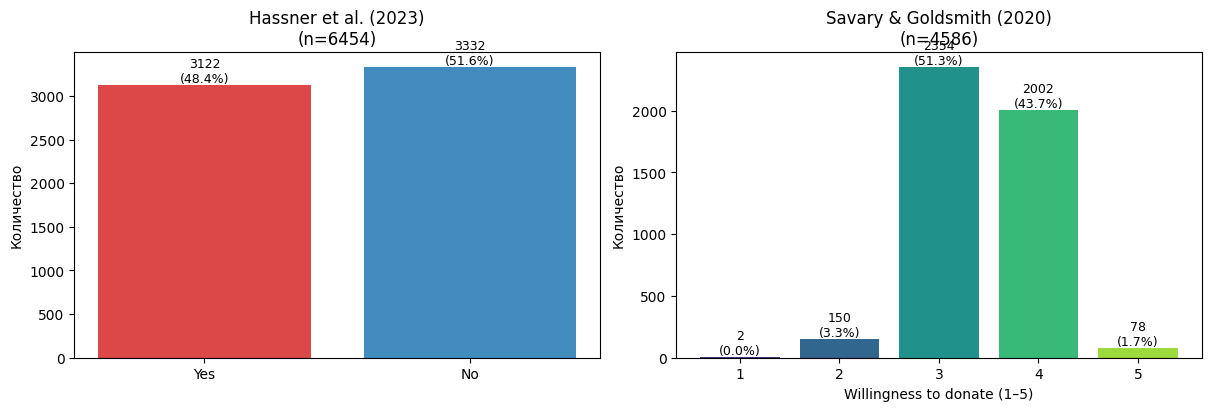

Hassner:  P(Yes) = 48.4%   Wilson 95% CI [47.2, 49.6]   n=6454
Savary :  M(ans) = 3.44    bootstrap 95% CI [3.42, 3.45]   n=4586


In [7]:
fig, axes = plt.subplots(1, 2, figsize=(12, 4), constrained_layout=True)

# Hassner — bar Yes/No
ax = axes[0]
sub_h = MAIN_DF[MAIN_DF["experiment_name"] == EXPERIMENTS[0]]
vc_h = sub_h["answer_cat"].value_counts().reindex(["Yes", "No"], fill_value=0)
ax.bar(vc_h.index, vc_h.values, color=["#d62728", "#1f77b4"], alpha=0.85)
for i_, v in enumerate(vc_h.values):
    ax.text(i_, v, f"{v}\n({v/len(sub_h)*100:.1f}%)", ha="center", va="bottom", fontsize=9)
ax.set_title(f"{EXP_TITLE[EXPERIMENTS[0]]}\n(n={len(sub_h)})")
ax.set_ylabel("Количество")

# Savary — bar 1..5
ax = axes[1]
sub_s = MAIN_DF[MAIN_DF["experiment_name"] == EXPERIMENTS[1]]
vc_s = sub_s["answer_cat"].value_counts().reindex(["1", "2", "3", "4", "5"], fill_value=0)
ax.bar(vc_s.index, vc_s.values, color=plt.cm.viridis(np.linspace(0.15, 0.85, 5)))
for i_, v in enumerate(vc_s.values):
    ax.text(i_, v, f"{v}\n({v/len(sub_s)*100:.1f}%)", ha="center", va="bottom", fontsize=9)
ax.set_title(f"{EXP_TITLE[EXPERIMENTS[1]]}\n(n={len(sub_s)})")
ax.set_xlabel("Willingness to donate (1–5)")
ax.set_ylabel("Количество")
plt.show()

# Сводка с CI
_, n_h, p_h, lo_h, hi_h = hassner_prop_ci(MAIN_DF)
print(f"Hassner:  P(Yes) = {p_h*100:.1f}%   Wilson 95% CI [{lo_h*100:.1f}, {hi_h*100:.1f}]   n={n_h}")
n_s, m_s, lo_s, hi_s = savary_mean_ci(MAIN_DF)
print(f"Savary :  M(ans) = {m_s:.2f}    bootstrap 95% CI [{lo_s:.2f}, {hi_s:.2f}]   n={n_s}")


## 2.2 По treatment-условию (`group_name`)

Для Hassner — доля Yes с Wilson 95% CI. Для Savary — средний answer с bootstrap 95% CI. Справа — стэк-доли категорий по группе.

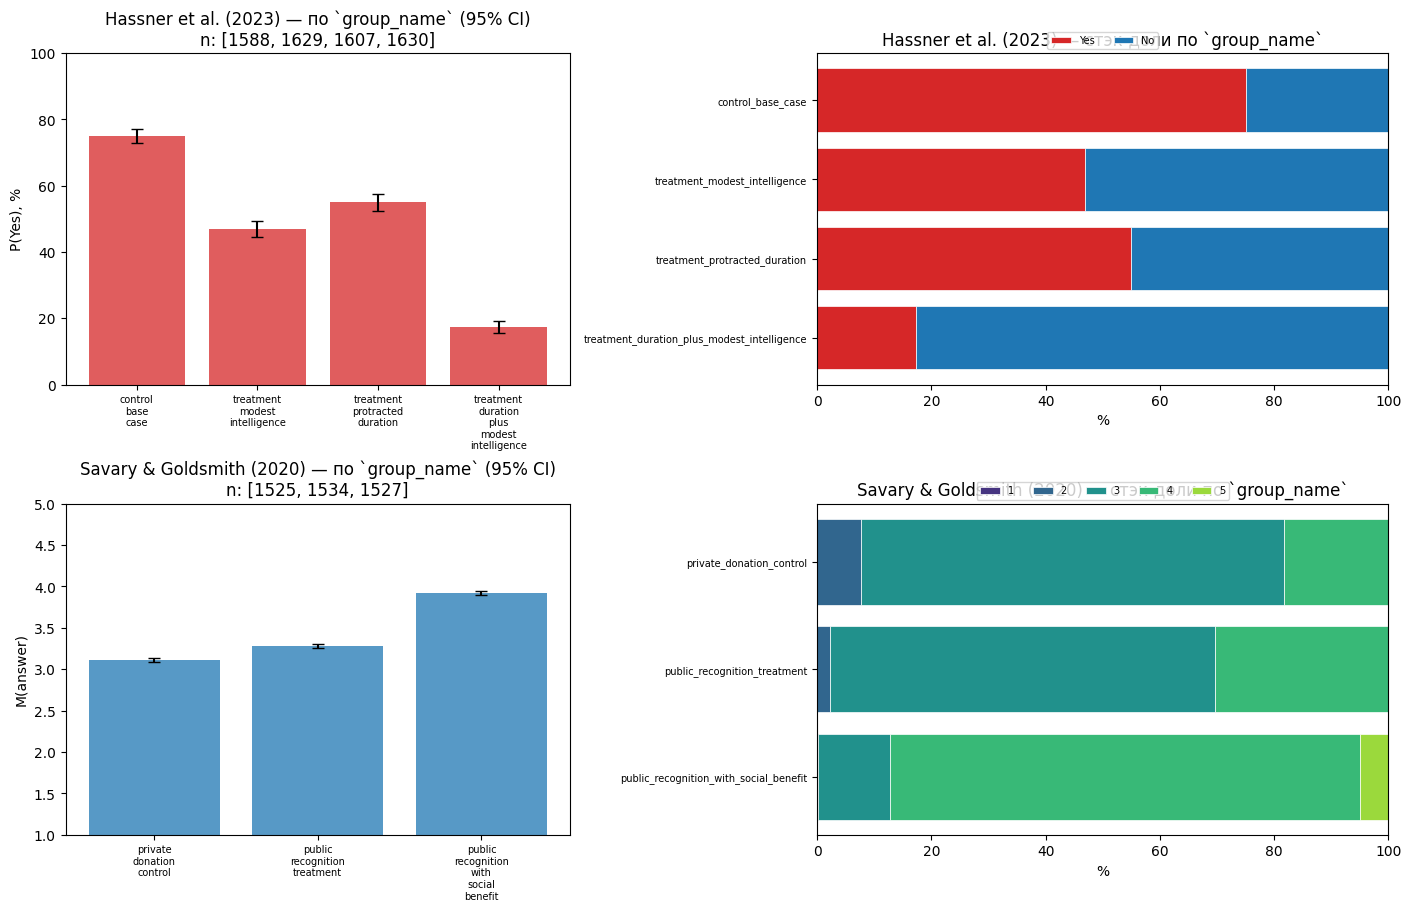

**Hassner et al. (2023)** — по `group_name`:

,group,n,p_yes,ci
0,control_base_case,1588,75.0%,"[72.8, 77.1]"
1,treatment_modest_intelligence,1629,47.0%,"[44.5, 49.4]"
2,treatment_protracted_duration,1607,54.9%,"[52.5, 57.4]"
3,treatment_duration_plus_modest_intelligence,1630,17.4%,"[15.6, 19.3]"


**Savary & Goldsmith (2020)** — по `group_name`:

,group,n,mean,ci
0,private_donation_control,1525,3.11,"[3.08, 3.13]"
1,public_recognition_treatment,1534,3.28,"[3.26, 3.31]"
2,public_recognition_with_social_benefit,1527,3.92,"[3.90, 3.94]"


In [8]:
def _stats_by_group(df: pd.DataFrame, exp: str) -> pd.DataFrame:
    groups = GROUP_ORDER[exp]
    rows = []
    sub_e = df[df["experiment_name"] == exp]
    for g in groups:
        sub_g = sub_e[sub_e["group_name"] == g]
        if "Hassner" in exp:
            _, n, p, lo, hi = hassner_prop_ci(sub_g)
            rows.append({"group": g, "n": n, "p_yes": p, "ci_low": lo, "ci_high": hi})
        else:
            n, m, lo, hi = savary_mean_ci(sub_g)
            rows.append({"group": g, "n": n, "mean": m, "ci_low": lo, "ci_high": hi})
    return pd.DataFrame(rows)


fig, axes = plt.subplots(
    2, 2, figsize=(14, 9), constrained_layout=True,
    gridspec_kw={"width_ratios": [1.5, 1.7]},
)
for i, exp in enumerate(EXPERIMENTS):
    stats = _stats_by_group(MAIN_DF, exp)

    # LEFT: bar с error bars (CI)
    ax = axes[i, 0]
    x = np.arange(len(stats))
    if "Hassner" in exp:
        y = stats["p_yes"].values * 100
        err = [
            (stats["p_yes"] - stats["ci_low"]).values * 100,
            (stats["ci_high"] - stats["p_yes"]).values * 100,
        ]
        ax.bar(x, y, yerr=err, capsize=4, color="#d62728", alpha=0.75)
        ax.set_ylabel("P(Yes), %")
        ax.set_ylim(0, 100)
    else:
        y = stats["mean"].values
        err = [(stats["mean"] - stats["ci_low"]).values, (stats["ci_high"] - stats["mean"]).values]
        ax.bar(x, y, yerr=err, capsize=4, color="#1f77b4", alpha=0.75)
        ax.set_ylabel("M(answer)")
        ax.set_ylim(1, 5)
    ax.set_xticks(x)
    ax.set_xticklabels([g.replace("_", "\n") for g in stats["group"]], fontsize=7)
    ax.set_title(f"{EXP_TITLE[exp]} — по `group_name` (95% CI)\nn: {list(stats['n'])}")

    # RIGHT: stacked bar категорий
    ax = axes[i, 1]
    sub_e = MAIN_DF[MAIN_DF["experiment_name"] == exp]
    cats = ["Yes", "No"] if "Hassner" in exp else ["1", "2", "3", "4", "5"]
    counts = sub_e.groupby(["group_name", "answer_cat"]).size().unstack(fill_value=0)
    counts = counts.reindex(GROUP_ORDER[exp]).reindex(columns=cats, fill_value=0)
    props = counts.div(counts.sum(axis=1), axis=0) * 100
    bottom = np.zeros(len(props))
    colors = (
        ["#d62728", "#1f77b4"]
        if "Hassner" in exp
        else plt.cm.viridis(np.linspace(0.15, 0.85, 5))
    )
    for j, c in enumerate(cats):
        ax.barh(range(len(props)), props[c].values, left=bottom, color=colors[j],
                label=c, edgecolor="white", linewidth=0.5)
        bottom += props[c].values
    ax.set_yticks(range(len(props)))
    ax.set_yticklabels(props.index, fontsize=7)
    ax.invert_yaxis()
    ax.set_xlim(0, 100)
    ax.set_xlabel("%")
    ax.legend(fontsize=7, loc="upper center", ncols=len(cats), bbox_to_anchor=(0.5, 1.08))
    ax.set_title(f"{EXP_TITLE[exp]} — стэк-доли по `group_name`")
plt.show()

for exp in EXPERIMENTS:
    stats = _stats_by_group(MAIN_DF, exp)
    display(Markdown(f"**{EXP_TITLE[exp]}** — по `group_name`:"))
    if "Hassner" in exp:
        display(stats.assign(
            p_yes=lambda d: (d["p_yes"] * 100).map("{:.1f}%".format),
            ci=lambda d: "[" + (d["ci_low"] * 100).map("{:.1f}".format)
                + ", " + (d["ci_high"] * 100).map("{:.1f}".format) + "]",
        )[["group", "n", "p_yes", "ci"]])
    else:
        display(stats.assign(
            mean=lambda d: d["mean"].map("{:.2f}".format),
            ci=lambda d: "[" + d["ci_low"].map("{:.2f}".format)
                + ", " + d["ci_high"].map("{:.2f}".format) + "]",
        )[["group", "n", "mean", "ci"]])


## 2.3 Распределение по `incentive`

Агрегируем по всем моделям и группам — общий взгляд на эффект `incentive`. Treatment-эффект внутри `incentive` — в подсекциях 2.4 и формально в блоке 4.1.

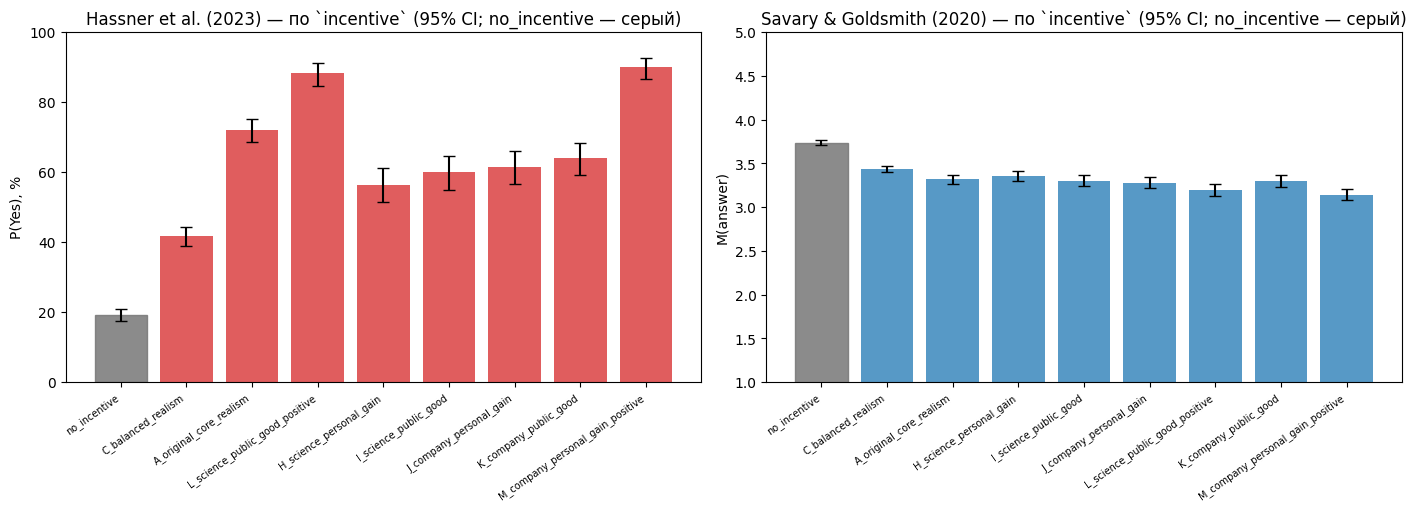

**Hassner et al. (2023)** — по `incentive`:

,incentive,n,p_yes,ci
0,no_incentive,2023,19.1%,"[17.4, 20.9]"
1,C_balanced_realism,1340,41.6%,"[39.0, 44.3]"
2,A_original_core_realism,696,72.1%,"[68.7, 75.3]"
3,L_science_public_good_positive,400,88.2%,"[84.7, 91.0]"
4,H_science_personal_gain,399,56.4%,"[51.5, 61.2]"
5,I_science_public_good,399,59.9%,"[55.0, 64.6]"
6,J_company_personal_gain,399,61.4%,"[56.5, 66.0]"
7,K_company_public_good,399,63.9%,"[59.1, 68.5]"
8,M_company_personal_gain_positive,399,90.0%,"[86.6, 92.6]"


**Savary & Goldsmith (2020)** — по `incentive`:

,incentive,n,mean,ci
0,no_incentive,1240,3.74,"[3.71, 3.77]"
1,C_balanced_realism,1034,3.44,"[3.41, 3.47]"
2,A_original_core_realism,515,3.32,"[3.27, 3.37]"
3,H_science_personal_gain,300,3.35,"[3.29, 3.41]"
4,I_science_public_good,300,3.30,"[3.24, 3.36]"
5,J_company_personal_gain,300,3.28,"[3.21, 3.34]"
6,L_science_public_good_positive,300,3.20,"[3.13, 3.27]"
7,K_company_public_good,299,3.30,"[3.23, 3.37]"
8,M_company_personal_gain_positive,298,3.14,"[3.08, 3.21]"


In [9]:
def _stats_by_incentive(df: pd.DataFrame, exp: str) -> pd.DataFrame:
    sub_e = df[df["experiment_name"] == exp]
    inc_order = sub_e.groupby("incentive").size().sort_values(ascending=False).index.tolist()
    if "no_incentive" in inc_order:
        inc_order = ["no_incentive"] + [i for i in inc_order if i != "no_incentive"]
    rows = []
    for inc in inc_order:
        sub_i = sub_e[sub_e["incentive"] == inc]
        if "Hassner" in exp:
            _, n, p, lo, hi = hassner_prop_ci(sub_i)
            rows.append({"incentive": inc, "n": n, "p_yes": p, "ci_low": lo, "ci_high": hi})
        else:
            n, m, lo, hi = savary_mean_ci(sub_i)
            rows.append({"incentive": inc, "n": n, "mean": m, "ci_low": lo, "ci_high": hi})
    return pd.DataFrame(rows)


fig, axes = plt.subplots(1, 2, figsize=(14, 5), constrained_layout=True)
for ax, exp in zip(axes, EXPERIMENTS):
    stats = _stats_by_incentive(MAIN_DF, exp)
    x = np.arange(len(stats))
    if "Hassner" in exp:
        y = stats["p_yes"].values * 100
        err = [
            (stats["p_yes"] - stats["ci_low"]).values * 100,
            (stats["ci_high"] - stats["p_yes"]).values * 100,
        ]
        ax.bar(x, y, yerr=err, capsize=4, color="#d62728", alpha=0.75)
        ax.set_ylabel("P(Yes), %")
        ax.set_ylim(0, 100)
    else:
        y = stats["mean"].values
        err = [(stats["mean"] - stats["ci_low"]).values, (stats["ci_high"] - stats["mean"]).values]
        ax.bar(x, y, yerr=err, capsize=4, color="#1f77b4", alpha=0.75)
        ax.set_ylabel("M(answer)")
        ax.set_ylim(1, 5)
    for i, inc in enumerate(stats["incentive"]):
        if inc == "no_incentive":
            ax.patches[i].set_color("#777777")
            ax.patches[i].set_alpha(0.85)
    ax.set_xticks(x)
    ax.set_xticklabels(stats["incentive"], rotation=35, ha="right", fontsize=7)
    ax.set_title(f"{EXP_TITLE[exp]} — по `incentive` (95% CI; no_incentive — серый)")
plt.show()

for exp in EXPERIMENTS:
    stats = _stats_by_incentive(MAIN_DF, exp)
    display(Markdown(f"**{EXP_TITLE[exp]}** — по `incentive`:"))
    if "Hassner" in exp:
        display(stats.assign(
            p_yes=lambda d: (d["p_yes"] * 100).map("{:.1f}%".format),
            ci=lambda d: "[" + (d["ci_low"] * 100).map("{:.1f}".format)
                + ", " + (d["ci_high"] * 100).map("{:.1f}".format) + "]",
        )[["incentive", "n", "p_yes", "ci"]])
    else:
        display(stats.assign(
            mean=lambda d: d["mean"].map("{:.2f}".format),
            ci=lambda d: "[" + d["ci_low"].map("{:.2f}".format)
                + ", " + d["ci_high"].map("{:.2f}".format) + "]",
        )[["incentive", "n", "mean", "ci"]])


## 2.4 Сетка `group_name × incentive`

Совмещаем оба фактора одной таблицей-heatmap. Для Hassner — доля Yes; для Savary — средний answer. В каждой ячейке `M%/n` (или `M/n`). Это descriptive-обзор; формальная проверка interaction уйдёт в блок 4.3.

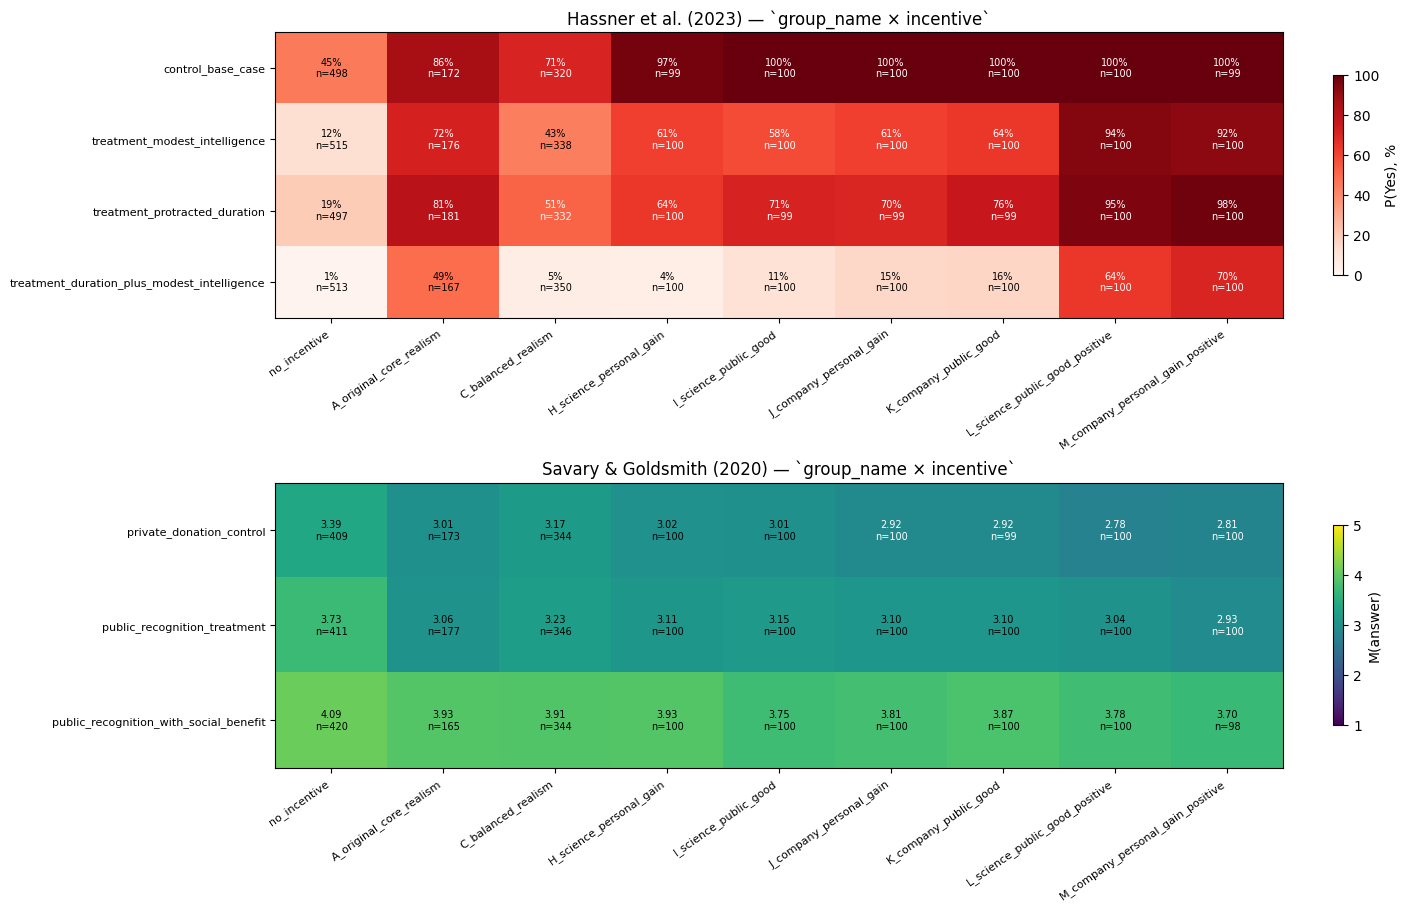

In [10]:
def _grid_stats(df: pd.DataFrame, exp: str):
    sub_e = df[df["experiment_name"] == exp]
    groups = GROUP_ORDER[exp]
    incs = sub_e.groupby("incentive").size().index.tolist()
    if "no_incentive" in incs:
        incs = ["no_incentive"] + [i for i in incs if i != "no_incentive"]
    val_grid = pd.DataFrame(index=groups, columns=incs, dtype=float)
    n_grid = pd.DataFrame(index=groups, columns=incs, dtype=int)
    for g in groups:
        for inc in incs:
            cell = sub_e[(sub_e["group_name"] == g) & (sub_e["incentive"] == inc)]
            n_grid.loc[g, inc] = len(cell)
            if len(cell) > 0:
                if "Hassner" in exp:
                    val_grid.loc[g, inc] = (cell["answer_num"] == 1.0).mean() * 100
                else:
                    val_grid.loc[g, inc] = cell["answer_num"].mean()
    return val_grid, n_grid


fig, axes = plt.subplots(2, 1, figsize=(14, 9), constrained_layout=True)
for ax, exp in zip(axes, EXPERIMENTS):
    val_grid, n_grid = _grid_stats(MAIN_DF, exp)
    if "Hassner" in exp:
        vmin, vmax = 0, 100
        cmap = "Reds"
        label = "P(Yes), %"
        fmt = "{:.0f}%\nn={}"
    else:
        vmin, vmax = 1, 5
        cmap = "viridis"
        label = "M(answer)"
        fmt = "{:.2f}\nn={}"
    im = ax.imshow(val_grid.values.astype(float), aspect="auto", cmap=cmap, vmin=vmin, vmax=vmax)
    ax.set_xticks(range(len(val_grid.columns)))
    ax.set_xticklabels(val_grid.columns, rotation=35, ha="right", fontsize=8)
    ax.set_yticks(range(len(val_grid.index)))
    ax.set_yticklabels(val_grid.index, fontsize=8)
    for i in range(val_grid.shape[0]):
        for j in range(val_grid.shape[1]):
            v = val_grid.iloc[i, j]
            n_ij = n_grid.iloc[i, j]
            if pd.notna(v):
                _is_dark = (("Hassner" in exp and v > 50) or ("Savary" in exp and v < 3))
                ax.text(j, i, fmt.format(v, int(n_ij)), ha="center", va="center", fontsize=7,
                        color="white" if _is_dark else "black")
    cbar = plt.colorbar(im, ax=ax, shrink=0.7)
    cbar.set_label(label)
    ax.set_title(f"{EXP_TITLE[exp]} — `group_name × incentive`")
plt.show()


## 2.5 По модели

Между моделями возможен response bias на уровне общего распределения. Сетка `incentive × model` неполная (см. блок 1), но мы показываем суммарно по всем `incentive`, в которых модель присутствует. Tonкая сравнимость моделей идёт ниже в блоках 4–5.

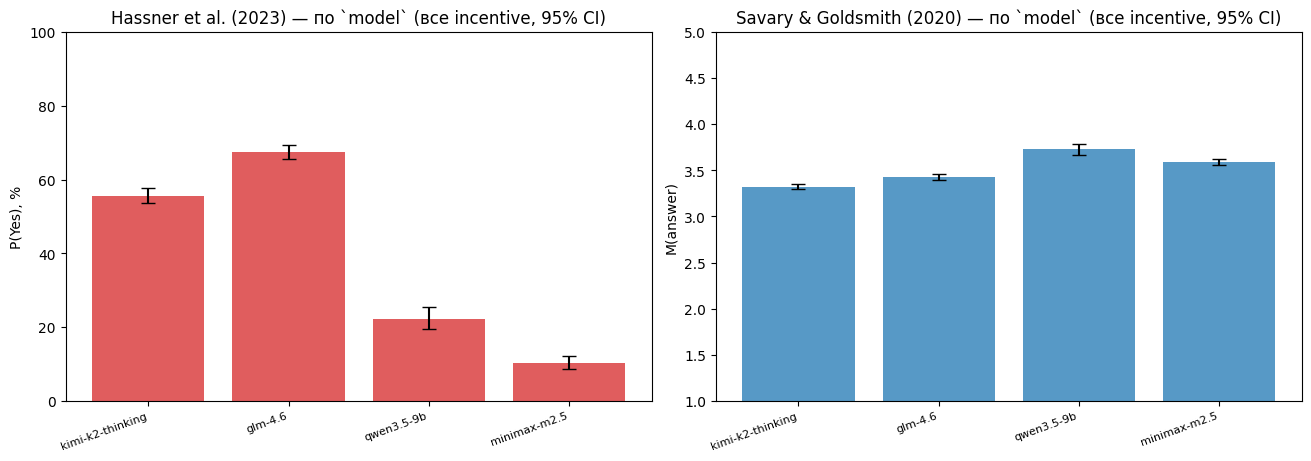

**Hassner et al. (2023)** — по `model`:

,model,n,p_yes,ci
0,moonshotai/kimi-k2-thinking,2318,55.6%,"[53.6, 57.6]"
1,z-ai/glm-4.6,2312,67.5%,"[65.6, 69.4]"
2,qwen/qwen3.5-9b,704,22.3%,"[19.4, 25.5]"
3,minimax/minimax-m2.5,1120,10.3%,"[8.6, 12.2]"


**Savary & Goldsmith (2020)** — по `model`:

,model,n,mean,ci
0,moonshotai/kimi-k2-thinking,1738,3.33,"[3.30, 3.35]"
1,z-ai/glm-4.6,1735,3.43,"[3.40, 3.46]"
2,qwen/qwen3.5-9b,273,3.73,"[3.67, 3.79]"
3,minimax/minimax-m2.5,840,3.59,"[3.55, 3.62]"


In [11]:
def _stats_by_model(df: pd.DataFrame, exp: str) -> pd.DataFrame:
    sub_e = df[df["experiment_name"] == exp]
    rows = []
    for m_ in sub_e["model"].astype(str).unique():
        sub_m = sub_e[sub_e["model"] == m_]
        if "Hassner" in exp:
            _, n, p, lo, hi = hassner_prop_ci(sub_m)
            rows.append({"model": m_, "n": n, "p_yes": p, "ci_low": lo, "ci_high": hi})
        else:
            n, mn, lo, hi = savary_mean_ci(sub_m)
            rows.append({"model": m_, "n": n, "mean": mn, "ci_low": lo, "ci_high": hi})
    out = pd.DataFrame(rows)
    out["_order"] = out["model"].map({m: i for i, m in enumerate(MODEL_ORDER_CANONICAL)}).fillna(99)
    return out.sort_values("_order").drop(columns=["_order"]).reset_index(drop=True)


fig, axes = plt.subplots(1, 2, figsize=(13, 4.5), constrained_layout=True)
for ax, exp in zip(axes, EXPERIMENTS):
    stats = _stats_by_model(MAIN_DF, exp)
    x = np.arange(len(stats))
    short = stats["model"].str.split("/").str[-1]
    if "Hassner" in exp:
        y = stats["p_yes"].values * 100
        err = [
            (stats["p_yes"] - stats["ci_low"]).values * 100,
            (stats["ci_high"] - stats["p_yes"]).values * 100,
        ]
        ax.bar(x, y, yerr=err, capsize=5, color="#d62728", alpha=0.75)
        ax.set_ylabel("P(Yes), %")
        ax.set_ylim(0, 100)
    else:
        y = stats["mean"].values
        err = [(stats["mean"] - stats["ci_low"]).values, (stats["ci_high"] - stats["mean"]).values]
        ax.bar(x, y, yerr=err, capsize=5, color="#1f77b4", alpha=0.75)
        ax.set_ylabel("M(answer)")
        ax.set_ylim(1, 5)
    ax.set_xticks(x)
    ax.set_xticklabels(short, rotation=20, ha="right", fontsize=8)
    ax.set_title(f"{EXP_TITLE[exp]} — по `model` (все incentive, 95% CI)")
plt.show()

for exp in EXPERIMENTS:
    stats = _stats_by_model(MAIN_DF, exp)
    display(Markdown(f"**{EXP_TITLE[exp]}** — по `model`:"))
    if "Hassner" in exp:
        display(stats.assign(
            p_yes=lambda d: (d["p_yes"] * 100).map("{:.1f}%".format),
            ci=lambda d: "[" + (d["ci_low"] * 100).map("{:.1f}".format)
                + ", " + (d["ci_high"] * 100).map("{:.1f}".format) + "]",
        )[["model", "n", "p_yes", "ci"]])
    else:
        display(stats.assign(
            mean=lambda d: d["mean"].map("{:.2f}".format),
            ci=lambda d: "[" + d["ci_low"].map("{:.2f}".format)
                + ", " + d["ci_high"].map("{:.2f}".format) + "]",
        )[["model", "n", "mean", "ci"]])


## 2.6 Savary: распределение на шкале 1–5

Среднее значение скрывает форму распределения, поэтому смотрим violins по `group_name` и по `incentive`, плюс долевые таблицы по категориям 1–5.

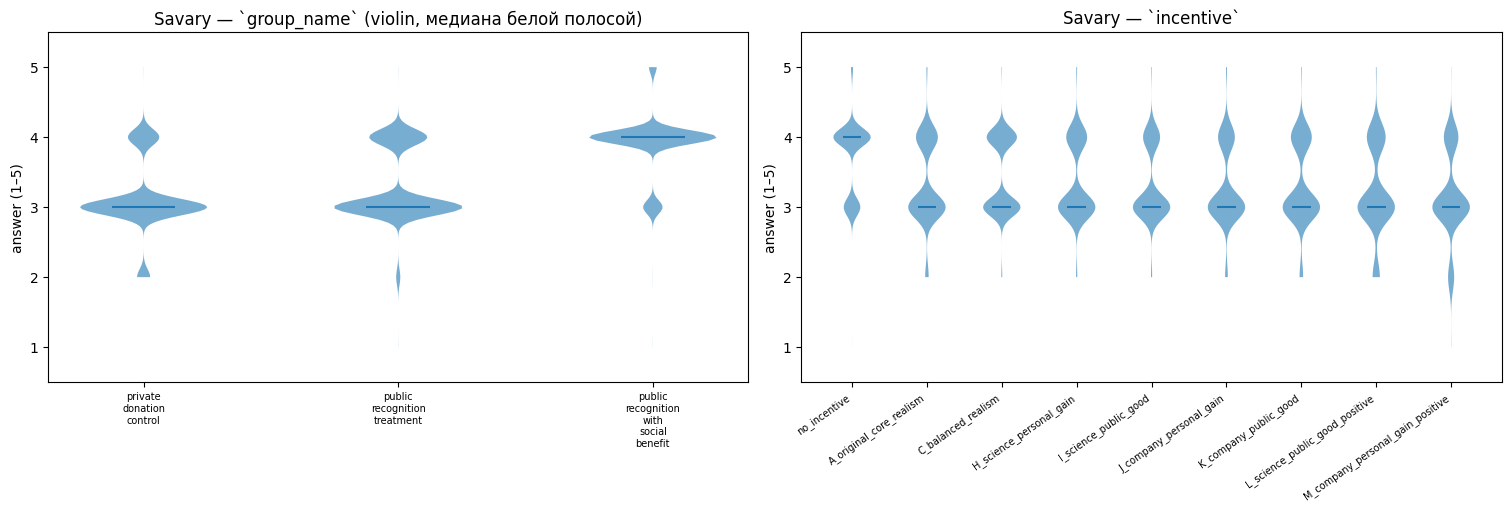

**Доли категорий ответа по `group_name` (Savary):**

answer_cat,1,2,3,4,5
group_name,,,,,
private_donation_control,0.0%,7.6%,74.0%,18.3%,0.1%
public_recognition_treatment,0.1%,2.2%,67.3%,30.4%,0.1%
public_recognition_with_social_benefit,0.1%,0.1%,12.6%,82.3%,5.0%


**Доли категорий ответа по `incentive` (Savary):**

answer_cat,1,2,3,4,5
incentive,,,,,
no_incentive,0.1%,0.0%,29.6%,66.7%,3.6%
A_original_core_realism,0.0%,5.4%,58.6%,34.4%,1.6%
C_balanced_realism,0.0%,1.4%,54.2%,43.9%,0.6%
H_science_personal_gain,0.0%,2.0%,62.0%,34.7%,1.3%
I_science_public_good,0.0%,2.0%,66.7%,30.3%,1.0%
J_company_personal_gain,0.0%,4.7%,64.7%,29.0%,1.7%
K_company_public_good,0.0%,5.7%,59.9%,33.4%,1.0%
L_science_public_good_positive,0.0%,11.3%,58.3%,29.3%,1.0%
M_company_personal_gain_positive,0.3%,10.4%,64.1%,24.8%,0.3%


In [12]:
sub_s = MAIN_DF[MAIN_DF["experiment_name"] == EXPERIMENTS[1]].copy()
group_order_s = GROUP_ORDER[EXPERIMENTS[1]]
inc_order_s = ["no_incentive"] + sorted(set(sub_s["incentive"].unique()) - {"no_incentive"})

fig, axes = plt.subplots(1, 2, figsize=(15, 5), constrained_layout=True)

ax = axes[0]
data_g = [sub_s[sub_s["group_name"] == g]["answer_num"].dropna().values for g in group_order_s]
parts = ax.violinplot(data_g, showmedians=True, showextrema=False)
for pc in parts["bodies"]:
    pc.set_facecolor("#1f77b4")
    pc.set_alpha(0.6)
ax.set_xticks(range(1, len(group_order_s) + 1))
ax.set_xticklabels([g.replace("_", "\n") for g in group_order_s], fontsize=7)
ax.set_ylabel("answer (1–5)")
ax.set_ylim(0.5, 5.5)
ax.set_yticks([1, 2, 3, 4, 5])
ax.set_title("Savary — `group_name` (violin, медиана белой полосой)")

ax = axes[1]
data_i = [sub_s[sub_s["incentive"] == i]["answer_num"].dropna().values for i in inc_order_s]
parts = ax.violinplot(data_i, showmedians=True, showextrema=False)
for pc in parts["bodies"]:
    pc.set_facecolor("#1f77b4")
    pc.set_alpha(0.6)
ax.set_xticks(range(1, len(inc_order_s) + 1))
ax.set_xticklabels(inc_order_s, rotation=35, ha="right", fontsize=7)
ax.set_ylabel("answer (1–5)")
ax.set_ylim(0.5, 5.5)
ax.set_yticks([1, 2, 3, 4, 5])
ax.set_title("Savary — `incentive`")
plt.show()

# Доли по категориям ответа × group_name
display(Markdown("**Доли категорий ответа по `group_name` (Savary):**"))
cnt_g = sub_s.groupby(["group_name", "answer_cat"]).size().unstack(fill_value=0).reindex(group_order_s)
cnt_g = cnt_g.reindex(columns=["1", "2", "3", "4", "5"], fill_value=0)
prop_g = (cnt_g.div(cnt_g.sum(axis=1), axis=0) * 100)
display(prop_g.style.format("{:.1f}%").background_gradient(cmap="viridis", axis=None, vmin=0, vmax=60))

display(Markdown("**Доли категорий ответа по `incentive` (Savary):**"))
cnt_i = sub_s.groupby(["incentive", "answer_cat"]).size().unstack(fill_value=0).reindex(inc_order_s)
cnt_i = cnt_i.reindex(columns=["1", "2", "3", "4", "5"], fill_value=0)
prop_i = (cnt_i.div(cnt_i.sum(axis=1), axis=0) * 100)
display(prop_i.style.format("{:.1f}%").background_gradient(cmap="viridis", axis=None, vmin=0, vmax=60))


## 2.7 Подблок: T=0.01 vs T=1.0 для `no_incentive`

Дизайн `_t1` (`is_t1=True`) — повтор `no_incentive` при температуре 1.0; есть только для no_incentive. Сравниваем общий уровень ответа модели между этими двумя температурами как отдельный объект анализа.

Главный интерес тут — есть ли альтернативный «дизайн» без стимула (просто высокая температура), который сдвигает распределение ответов так же, как стимулы при T=0.01.

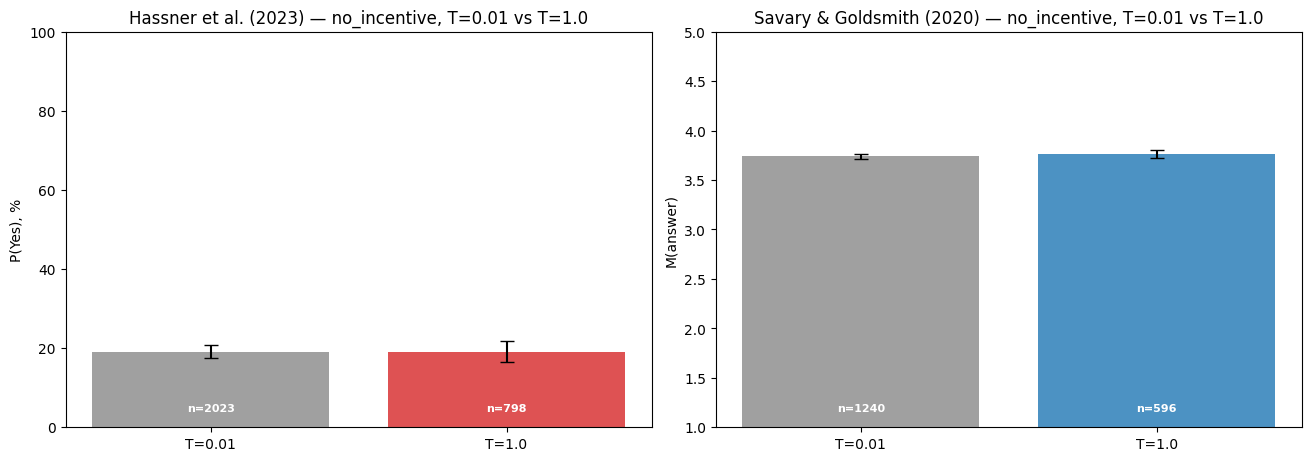

**Распределения категорий по T (no_incentive):**

**Hassner et al. (2023)**:

answer_cat,Yes,No
T_label,,
T=0.01,19.1%,80.9%
T=1.0,19.0%,81.0%


**Savary & Goldsmith (2020)**:

answer_cat,1,2,3,4,5
T_label,,,,,
T=0.01,0.1%,0.0%,29.6%,66.7%,3.6%
T=1.0,0.0%,0.2%,27.3%,69.0%,3.5%


In [13]:
# Подблок 2.7: T=0.01 vs T=1.0 для no_incentive
df_t = ANALYSIS_DF[ANALYSIS_DF["incentive"] == "no_incentive"].copy()
df_t["T_label"] = np.where(df_t["is_t1"], "T=1.0", "T=0.01")

fig, axes = plt.subplots(1, 2, figsize=(13, 4.5), constrained_layout=True)
for ax, exp in zip(axes, EXPERIMENTS):
    sub_e = df_t[df_t["experiment_name"] == exp]
    rows = []
    for t_lbl in ["T=0.01", "T=1.0"]:
        sub_t = sub_e[sub_e["T_label"] == t_lbl]
        if "Hassner" in exp:
            _, n, p, lo, hi = hassner_prop_ci(sub_t)
            rows.append({"T": t_lbl, "n": n, "p": p, "lo": lo, "hi": hi})
        else:
            n, m, lo, hi = savary_mean_ci(sub_t)
            rows.append({"T": t_lbl, "n": n, "p": m, "lo": lo, "hi": hi})
    st = pd.DataFrame(rows)
    x = np.arange(len(st))
    if "Hassner" in exp:
        y = st["p"].values * 100
        err = [(st["p"] - st["lo"]).values * 100, (st["hi"] - st["p"]).values * 100]
        ax.bar(x, y, yerr=err, capsize=5, color=["#888888", "#d62728"], alpha=0.8)
        ax.set_ylabel("P(Yes), %")
        ax.set_ylim(0, max(100, max(y + np.asarray(err[1])) * 1.1))
    else:
        y = st["p"].values
        err = [(st["p"] - st["lo"]).values, (st["hi"] - st["p"]).values]
        ax.bar(x, y, yerr=err, capsize=5, color=["#888888", "#1f77b4"], alpha=0.8)
        ax.set_ylabel("M(answer)")
        ax.set_ylim(1, 5)
    ax.set_xticks(x)
    ax.set_xticklabels(st["T"])
    ax.set_title(f"{EXP_TITLE[exp]} — no_incentive, T=0.01 vs T=1.0")
    y0 = ax.get_ylim()[0]
    yh = ax.get_ylim()[1] - y0
    for i, n in enumerate(st["n"]):
        ax.text(i, y0 + yh * 0.04, f"n={n}", ha="center", fontsize=8, color="white", fontweight="bold")
plt.show()

display(Markdown("**Распределения категорий по T (no_incentive):**"))
for exp in EXPERIMENTS:
    sub_e = df_t[df_t["experiment_name"] == exp]
    cats = ["Yes", "No"] if "Hassner" in exp else ["1", "2", "3", "4", "5"]
    pivot = sub_e.groupby(["T_label", "answer_cat"]).size().unstack(fill_value=0).reindex(columns=cats, fill_value=0)
    pivot_pct = pivot.div(pivot.sum(axis=1), axis=0) * 100
    display(Markdown(f"**{EXP_TITLE[exp]}**:"))
    display(pivot_pct.style.format("{:.1f}%").background_gradient(cmap="Blues", axis=1))


# Блок 3. Категоричность, разнородность и сбалансированность ответов

Главный вопрос блока: **делает ли incentive ответы модели более однородными, категоричными, осторожными или сбалансированными?**

Метрики, рассчитанные для каждой подгруппы:

| Метрика | Формула | Что значит |
|---|---|---|
| **Shannon entropy** (`entropy`) | $H = -\sum p_i \log_2 p_i$ | разнообразие ответов; 0 = единогласие, $H_{\max}$ = равномерно |
| **Balance score** (`balance`) | $H / H_{\max}$ | normalized entropy, 0..1 (1 = равномерно) |
| **Concentration** (`concentration`) | $\max_i p_i$ | доля самой частой категории (1 = всё одна) |
| **Agreement rate** (`agreement_rate`) | $\sum p_i^2$ | вероятность совпадения двух случайных ответов (1 = всегда совпадают) |
| **Extremity** (Hassner) | $|2 p_{\text{Yes}} - 1|$ | насколько распределение далеко от 50/50 |
| **Std** (Savary) | std (1–5) | стандартное отклонение шкальных ответов |
| **Extreme share** (Savary) | $p_1 + p_5$ | доля крайних категорий шкалы |

Слой: `MAIN_DF` (T=0.01). Срезы:
- 3.1 — по `incentive` (overall);
- 3.2 — по `group_name × incentive`;
- 3.3 — по `model × incentive`;
- 3.4 — резюме `no_incentive` vs `any incentive`.

In [14]:
# --- Метрики разнородности / категоричности / баланса ---

def _cats_for_exp(exp: str) -> List[str]:
    return ["Yes", "No"] if "Hassner" in exp else ["1", "2", "3", "4", "5"]


def metrics_for_subgroup(sub: pd.DataFrame, exp: str) -> dict:
    """Возвращает все метрики разнородности/баланса для одной подгруппы."""
    cats = _cats_for_exp(exp)
    vc = sub["answer_cat"].value_counts().reindex(cats, fill_value=0)
    n = int(vc.sum())
    out = {"n": n}
    if n == 0:
        return out
    probs = vc.values / n
    H = float(-np.sum(np.where(probs > 0, probs * np.log2(probs), 0.0)))
    H_max = float(np.log2(len(cats)))
    out["entropy"] = H
    out["balance"] = H / H_max  # 0..1 normalized entropy
    out["concentration"] = float(probs.max())
    out["agreement_rate"] = float((probs ** 2).sum())  # P(совпадение двух случайных ответов)
    if "Hassner" in exp:
        p_yes = float((sub["answer_num"] == 1.0).mean())
        out["p_yes"] = p_yes
        out["extremity"] = float(abs(2 * p_yes - 1))  # 0=balanced, 1=единогласие
    else:
        vals = sub["answer_num"].dropna().to_numpy()
        out["mean"] = float(vals.mean())
        out["std"] = float(vals.std(ddof=1)) if len(vals) > 1 else np.nan
        out["extreme_share"] = float(probs[0] + probs[-1])  # P(1) + P(5)
    return out


def metrics_table(df: pd.DataFrame, exp: str, group_cols: List[str]) -> pd.DataFrame:
    """Возвращает таблицу метрик для всех подгрупп df внутри experiment."""
    rows = []
    sub_e = df[df["experiment_name"] == exp]
    for keys, g in sub_e.groupby(group_cols, sort=False, dropna=False):
        if not isinstance(keys, tuple):
            keys = (keys,)
        m = metrics_for_subgroup(g, exp)
        rows.append({**dict(zip(group_cols, keys)), **m})
    return pd.DataFrame(rows)


print("Метрики готовы: entropy, balance(=H/H_max), concentration(=max p_i), agreement_rate(=Σp_i²),")
print("plus per-experiment: Hassner — p_yes, extremity; Savary — mean, std, extreme_share.")


Метрики готовы: entropy, balance(=H/H_max), concentration(=max p_i), agreement_rate(=Σp_i²),
plus per-experiment: Hassner — p_yes, extremity; Savary — mean, std, extreme_share.


## 3.1 Метрики разнородности по `incentive`

Агрегаты по всем моделям и группам — общий взгляд на то, как каждый incentive сдвигает форму распределения ответов. Серым выделен `no_incentive` (базовая линия).

### Hassner et al. (2023) — метрики по `incentive`

,incentive,n,entropy,balance,concentration,agreement_rate,p_yes,extremity
0,no_incentive,2023,0.703,0.703,0.809,0.691,0.191,0.618
1,A_original_core_realism,696,0.854,0.854,0.721,0.598,0.721,0.443
2,C_balanced_realism,1340,0.980,0.980,0.584,0.514,0.416,0.167
3,H_science_personal_gain,399,0.988,0.988,0.564,0.508,0.564,0.128
4,I_science_public_good,399,0.972,0.972,0.599,0.520,0.599,0.198
5,J_company_personal_gain,399,0.962,0.962,0.614,0.526,0.614,0.228
6,K_company_public_good,399,0.943,0.943,0.639,0.539,0.639,0.278
7,L_science_public_good_positive,400,0.522,0.522,0.882,0.793,0.882,0.765
8,M_company_personal_gain_positive,399,0.470,0.470,0.900,0.820,0.900,0.799


### Savary & Goldsmith (2020) — метрики по `incentive`

/tmp/claude-501/ipykernel_11742/4192108652.py:16: RuntimeWarning: divide by zero encountered in log2
  H = float(-np.sum(np.where(probs > 0, probs * np.log2(probs), 0.0)))
/tmp/claude-501/ipykernel_11742/4192108652.py:16: RuntimeWarning: invalid value encountered in multiply
  H = float(-np.sum(np.where(probs > 0, probs * np.log2(probs), 0.0)))
/tmp/claude-501/ipykernel_11742/4192108652.py:16: RuntimeWarning: divide by zero encountered in log2
  H = float(-np.sum(np.where(probs > 0, probs * np.log2(probs), 0.0)))
/tmp/claude-501/ipykernel_11742/4192108652.py:16: RuntimeWarning: invalid value encountered in multiply
  H = float(-np.sum(np.where(probs > 0, probs * np.log2(probs), 0.0)))
/tmp/claude-501/ipykernel_11742/4192108652.py:16: RuntimeWarning: divide by zero encountered in log2
  H = float(-np.sum(np.where(probs > 0, probs * np.log2(probs), 0.0)))
/tmp/claude-501/ipykernel_11742/4192108652.py:16: RuntimeWarning: invalid value encountered in multiply
  H = float(-np.sum(np.where(p

,incentive,n,entropy,balance,concentration,agreement_rate,mean,std,extreme_share
0,no_incentive,1240,1.092,0.470,0.667,0.534,3.738,0.521,0.037
1,A_original_core_realism,515,1.303,0.561,0.586,0.465,3.320,0.599,0.016
2,C_balanced_realism,1034,1.128,0.486,0.542,0.486,3.437,0.534,0.006
3,H_science_personal_gain,300,1.153,0.497,0.620,0.505,3.353,0.544,0.013
4,I_science_public_good,300,1.091,0.470,0.667,0.537,3.303,0.522,0.010
5,J_company_personal_gain,300,1.229,0.529,0.647,0.505,3.277,0.573,0.017
6,K_company_public_good,299,1.273,0.548,0.599,0.474,3.298,0.587,0.010
7,L_science_public_good_positive,300,1.395,0.601,0.583,0.439,3.200,0.639,0.010
8,M_company_personal_gain_positive,298,1.305,0.562,0.641,0.483,3.144,0.600,0.007


/tmp/claude-501/ipykernel_11742/4192108652.py:16: RuntimeWarning: divide by zero encountered in log2
  H = float(-np.sum(np.where(probs > 0, probs * np.log2(probs), 0.0)))
/tmp/claude-501/ipykernel_11742/4192108652.py:16: RuntimeWarning: invalid value encountered in multiply
  H = float(-np.sum(np.where(probs > 0, probs * np.log2(probs), 0.0)))
/tmp/claude-501/ipykernel_11742/4192108652.py:16: RuntimeWarning: divide by zero encountered in log2
  H = float(-np.sum(np.where(probs > 0, probs * np.log2(probs), 0.0)))
/tmp/claude-501/ipykernel_11742/4192108652.py:16: RuntimeWarning: invalid value encountered in multiply
  H = float(-np.sum(np.where(probs > 0, probs * np.log2(probs), 0.0)))
/tmp/claude-501/ipykernel_11742/4192108652.py:16: RuntimeWarning: divide by zero encountered in log2
  H = float(-np.sum(np.where(probs > 0, probs * np.log2(probs), 0.0)))
/tmp/claude-501/ipykernel_11742/4192108652.py:16: RuntimeWarning: invalid value encountered in multiply
  H = float(-np.sum(np.where(p

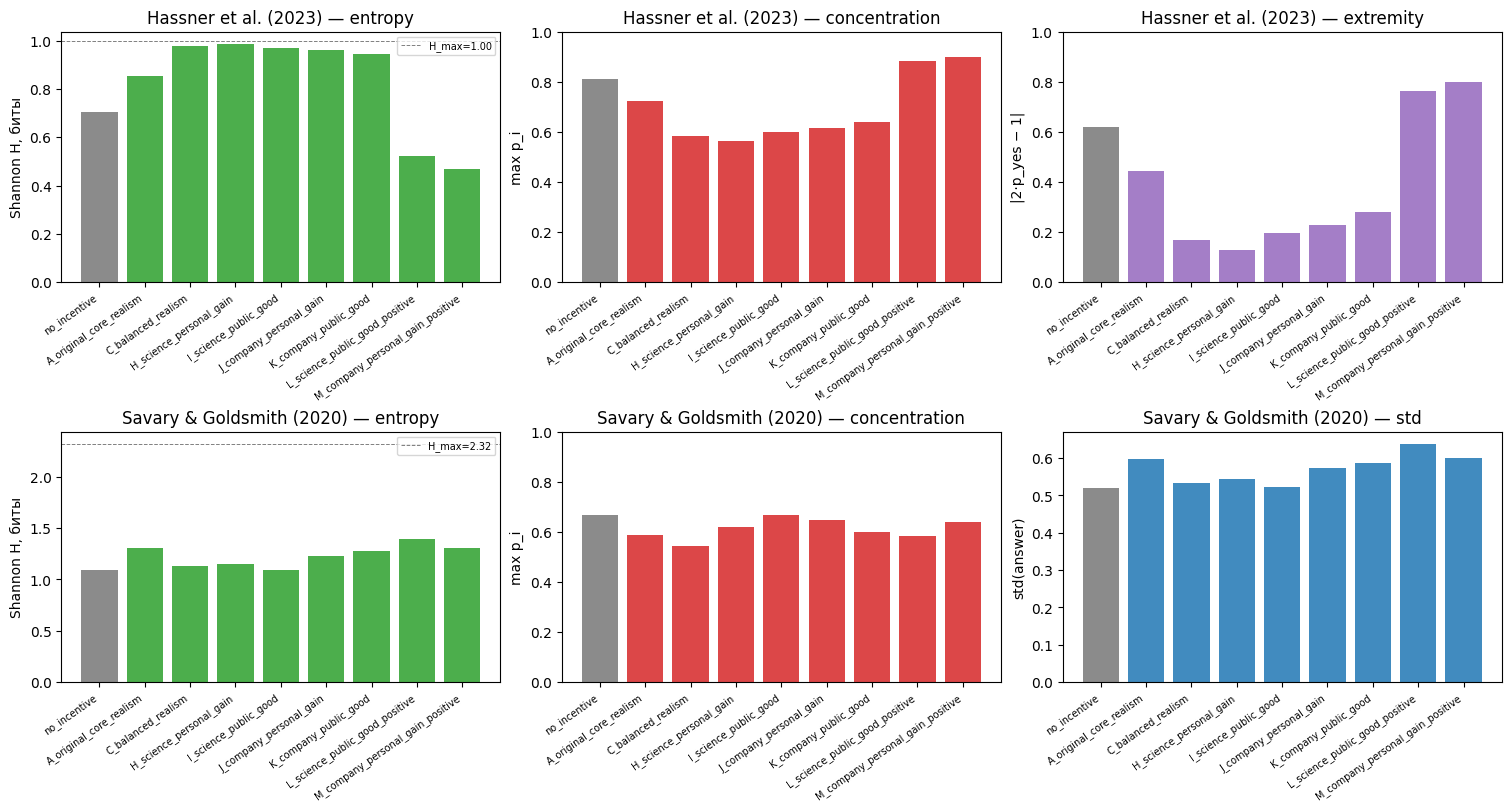

In [15]:
# 3.1 Метрики разнородности по `incentive` (overall в эксперименте)
inc_order_global = None  # вычислим из MAIN_DF
def _inc_order(df_):
    incs = sorted(df_["incentive"].astype(str).unique())
    if "no_incentive" in incs:
        return ["no_incentive"] + [i for i in incs if i != "no_incentive"]
    return incs


for exp in EXPERIMENTS:
    display(Markdown(f"### {EXP_TITLE[exp]} — метрики по `incentive`"))
    t = metrics_table(MAIN_DF, exp, ["incentive"])
    incs = _inc_order(t)
    t = t.set_index("incentive").reindex(incs).reset_index()
    cols = ["incentive", "n", "entropy", "balance", "concentration", "agreement_rate"]
    if "Hassner" in exp:
        cols += ["p_yes", "extremity"]
    else:
        cols += ["mean", "std", "extreme_share"]
    display(t[cols].round(3))

# Bar plot ключевых метрик по incentive
fig, axes = plt.subplots(len(EXPERIMENTS), 3, figsize=(15, 4 * len(EXPERIMENTS)), constrained_layout=True)
for i, exp in enumerate(EXPERIMENTS):
    t = metrics_table(MAIN_DF, exp, ["incentive"])
    incs = _inc_order(t)
    t = t.set_index("incentive").reindex(incs).reset_index()
    x = np.arange(len(t))
    H_max = np.log2(2 if "Hassner" in exp else 5)

    # Entropy
    ax = axes[i, 0]
    ax.bar(x, t["entropy"], color=["#777777" if inc == "no_incentive" else "#2ca02c" for inc in t["incentive"]], alpha=0.85)
    ax.axhline(H_max, ls="--", color="gray", lw=0.7, label=f"H_max={H_max:.2f}")
    ax.set_xticks(x)
    ax.set_xticklabels(t["incentive"], rotation=35, ha="right", fontsize=7)
    ax.set_ylabel("Shannon H, биты")
    ax.set_title(f"{EXP_TITLE[exp]} — entropy")
    ax.legend(fontsize=7)

    # Concentration
    ax = axes[i, 1]
    ax.bar(x, t["concentration"], color=["#777777" if inc == "no_incentive" else "#d62728" for inc in t["incentive"]], alpha=0.85)
    ax.set_xticks(x)
    ax.set_xticklabels(t["incentive"], rotation=35, ha="right", fontsize=7)
    ax.set_ylim(0, 1)
    ax.set_ylabel("max p_i")
    ax.set_title(f"{EXP_TITLE[exp]} — concentration")

    # Extremity (Hassner) или std (Savary)
    ax = axes[i, 2]
    if "Hassner" in exp:
        ax.bar(x, t["extremity"], color=["#777777" if inc == "no_incentive" else "#9467bd" for inc in t["incentive"]], alpha=0.85)
        ax.set_ylim(0, 1)
        ax.set_ylabel("|2·p_yes − 1|")
        ax.set_title(f"{EXP_TITLE[exp]} — extremity")
    else:
        ax.bar(x, t["std"], color=["#777777" if inc == "no_incentive" else "#1f77b4" for inc in t["incentive"]], alpha=0.85)
        ax.set_ylabel("std(answer)")
        ax.set_title(f"{EXP_TITLE[exp]} — std")
    ax.set_xticks(x)
    ax.set_xticklabels(t["incentive"], rotation=35, ha="right", fontsize=7)
plt.show()


## 3.2 Сетка `group_name × incentive`

Treatment-эффект может «съедать» вариативность ответа (например, при сильном treatment модель уверенно даёт один ответ). Поэтому смотрим entropy и concentration в полной сетке `treatment × incentive`. Числовые сводки — ниже heatmap.

/tmp/claude-501/ipykernel_11742/4192108652.py:16: RuntimeWarning: divide by zero encountered in log2
  H = float(-np.sum(np.where(probs > 0, probs * np.log2(probs), 0.0)))
/tmp/claude-501/ipykernel_11742/4192108652.py:16: RuntimeWarning: invalid value encountered in multiply
  H = float(-np.sum(np.where(probs > 0, probs * np.log2(probs), 0.0)))
/tmp/claude-501/ipykernel_11742/4192108652.py:16: RuntimeWarning: divide by zero encountered in log2
  H = float(-np.sum(np.where(probs > 0, probs * np.log2(probs), 0.0)))
/tmp/claude-501/ipykernel_11742/4192108652.py:16: RuntimeWarning: invalid value encountered in multiply
  H = float(-np.sum(np.where(probs > 0, probs * np.log2(probs), 0.0)))
/tmp/claude-501/ipykernel_11742/4192108652.py:16: RuntimeWarning: divide by zero encountered in log2
  H = float(-np.sum(np.where(probs > 0, probs * np.log2(probs), 0.0)))
/tmp/claude-501/ipykernel_11742/4192108652.py:16: RuntimeWarning: invalid value encountered in multiply
  H = float(-np.sum(np.where(p

/tmp/claude-501/ipykernel_11742/4192108652.py:16: RuntimeWarning: divide by zero encountered in log2
  H = float(-np.sum(np.where(probs > 0, probs * np.log2(probs), 0.0)))
/tmp/claude-501/ipykernel_11742/4192108652.py:16: RuntimeWarning: invalid value encountered in multiply
  H = float(-np.sum(np.where(probs > 0, probs * np.log2(probs), 0.0)))
/tmp/claude-501/ipykernel_11742/4192108652.py:16: RuntimeWarning: divide by zero encountered in log2
  H = float(-np.sum(np.where(probs > 0, probs * np.log2(probs), 0.0)))
/tmp/claude-501/ipykernel_11742/4192108652.py:16: RuntimeWarning: invalid value encountered in multiply
  H = float(-np.sum(np.where(probs > 0, probs * np.log2(probs), 0.0)))
/tmp/claude-501/ipykernel_11742/4192108652.py:16: RuntimeWarning: divide by zero encountered in log2
  H = float(-np.sum(np.where(probs > 0, probs * np.log2(probs), 0.0)))
/tmp/claude-501/ipykernel_11742/4192108652.py:16: RuntimeWarning: invalid value encountered in multiply
  H = float(-np.sum(np.where(p

/tmp/claude-501/ipykernel_11742/4192108652.py:16: RuntimeWarning: divide by zero encountered in log2
  H = float(-np.sum(np.where(probs > 0, probs * np.log2(probs), 0.0)))
/tmp/claude-501/ipykernel_11742/4192108652.py:16: RuntimeWarning: invalid value encountered in multiply
  H = float(-np.sum(np.where(probs > 0, probs * np.log2(probs), 0.0)))
/tmp/claude-501/ipykernel_11742/4192108652.py:16: RuntimeWarning: divide by zero encountered in log2
  H = float(-np.sum(np.where(probs > 0, probs * np.log2(probs), 0.0)))
/tmp/claude-501/ipykernel_11742/4192108652.py:16: RuntimeWarning: invalid value encountered in multiply
  H = float(-np.sum(np.where(probs > 0, probs * np.log2(probs), 0.0)))
/tmp/claude-501/ipykernel_11742/4192108652.py:16: RuntimeWarning: divide by zero encountered in log2
  H = float(-np.sum(np.where(probs > 0, probs * np.log2(probs), 0.0)))
/tmp/claude-501/ipykernel_11742/4192108652.py:16: RuntimeWarning: invalid value encountered in multiply
  H = float(-np.sum(np.where(p

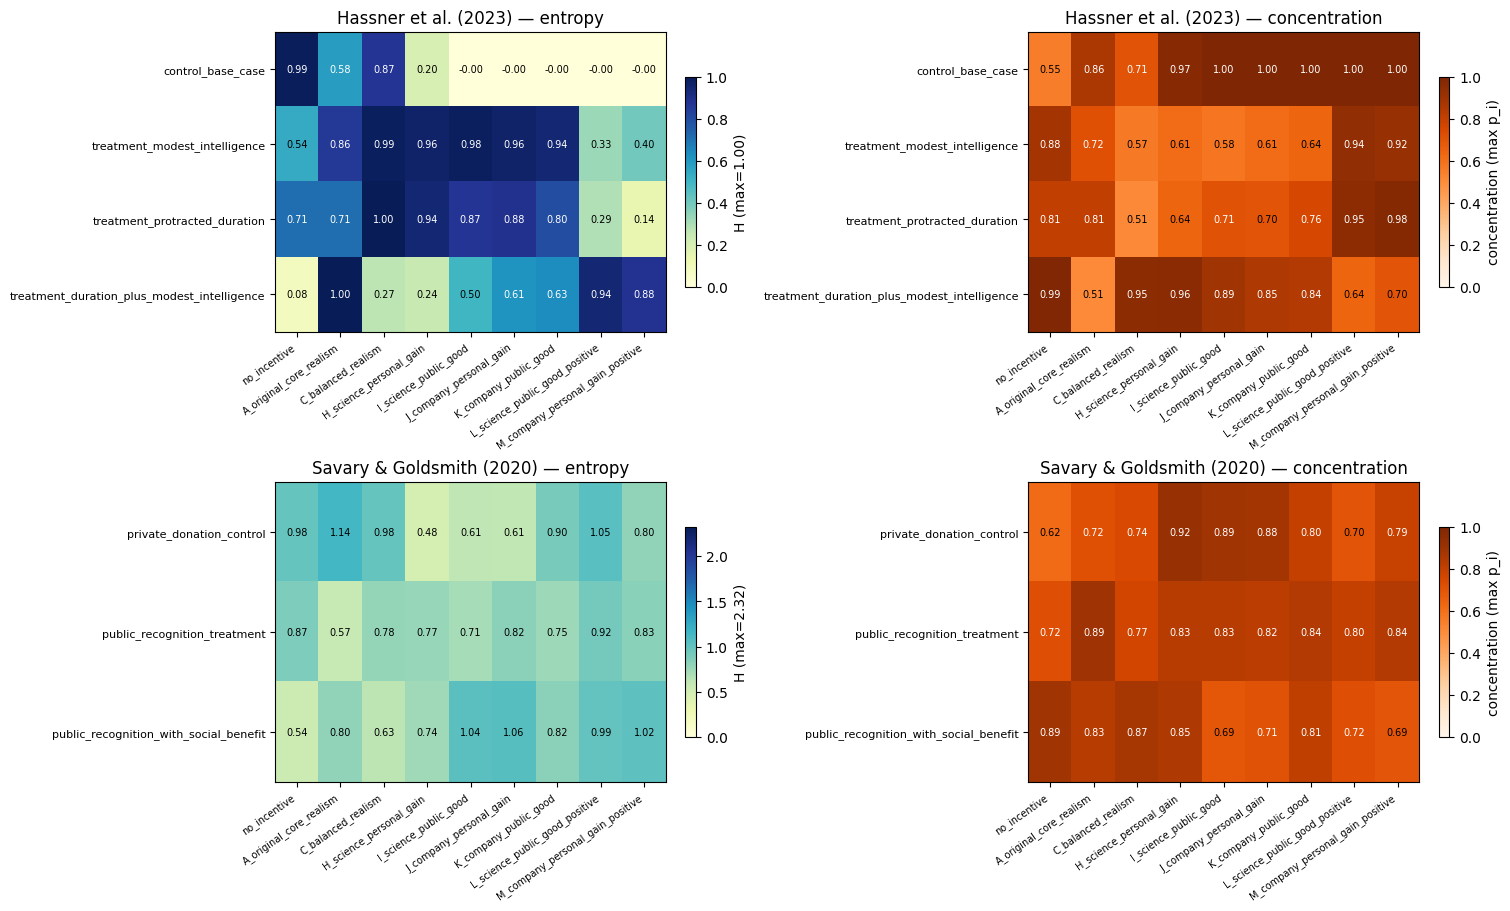

**Hassner et al. (2023)** — численные метрики по `(group_name, incentive)`:

/tmp/claude-501/ipykernel_11742/4192108652.py:16: RuntimeWarning: divide by zero encountered in log2
  H = float(-np.sum(np.where(probs > 0, probs * np.log2(probs), 0.0)))
/tmp/claude-501/ipykernel_11742/4192108652.py:16: RuntimeWarning: invalid value encountered in multiply
  H = float(-np.sum(np.where(probs > 0, probs * np.log2(probs), 0.0)))
/tmp/claude-501/ipykernel_11742/4192108652.py:16: RuntimeWarning: divide by zero encountered in log2
  H = float(-np.sum(np.where(probs > 0, probs * np.log2(probs), 0.0)))
/tmp/claude-501/ipykernel_11742/4192108652.py:16: RuntimeWarning: invalid value encountered in multiply
  H = float(-np.sum(np.where(probs > 0, probs * np.log2(probs), 0.0)))
/tmp/claude-501/ipykernel_11742/4192108652.py:16: RuntimeWarning: divide by zero encountered in log2
  H = float(-np.sum(np.where(probs > 0, probs * np.log2(probs), 0.0)))
/tmp/claude-501/ipykernel_11742/4192108652.py:16: RuntimeWarning: invalid value encountered in multiply
  H = float(-np.sum(np.where(p

,group_name,incentive,n,entropy,balance,concentration,agreement_rate,p_yes,extremity
0,control_base_case,no_incentive,498,0.992,0.992,0.554,0.506,0.446,0.108
1,control_base_case,A_original_core_realism,172,0.583,0.583,0.860,0.760,0.860,0.721
2,control_base_case,C_balanced_realism,320,0.874,0.874,0.706,0.585,0.706,0.413
3,control_base_case,H_science_personal_gain,99,0.196,0.196,0.970,0.941,0.970,0.939
4,control_base_case,I_science_public_good,100,-0.000,-0.000,1.000,1.000,1.000,1.000
5,control_base_case,J_company_personal_gain,100,-0.000,-0.000,1.000,1.000,1.000,1.000
6,control_base_case,K_company_public_good,100,-0.000,-0.000,1.000,1.000,1.000,1.000
7,control_base_case,L_science_public_good_positive,100,-0.000,-0.000,1.000,1.000,1.000,1.000
8,control_base_case,M_company_personal_gain_positive,99,-0.000,-0.000,1.000,1.000,1.000,1.000
9,treatment_modest_intelligence,no_incentive,515,0.536,0.536,0.878,0.785,0.122,0.755


**Savary & Goldsmith (2020)** — численные метрики по `(group_name, incentive)`:

/tmp/claude-501/ipykernel_11742/4192108652.py:16: RuntimeWarning: divide by zero encountered in log2
  H = float(-np.sum(np.where(probs > 0, probs * np.log2(probs), 0.0)))
/tmp/claude-501/ipykernel_11742/4192108652.py:16: RuntimeWarning: invalid value encountered in multiply
  H = float(-np.sum(np.where(probs > 0, probs * np.log2(probs), 0.0)))
/tmp/claude-501/ipykernel_11742/4192108652.py:16: RuntimeWarning: divide by zero encountered in log2
  H = float(-np.sum(np.where(probs > 0, probs * np.log2(probs), 0.0)))
/tmp/claude-501/ipykernel_11742/4192108652.py:16: RuntimeWarning: invalid value encountered in multiply
  H = float(-np.sum(np.where(probs > 0, probs * np.log2(probs), 0.0)))
/tmp/claude-501/ipykernel_11742/4192108652.py:16: RuntimeWarning: divide by zero encountered in log2
  H = float(-np.sum(np.where(probs > 0, probs * np.log2(probs), 0.0)))
/tmp/claude-501/ipykernel_11742/4192108652.py:16: RuntimeWarning: invalid value encountered in multiply
  H = float(-np.sum(np.where(p

,group_name,incentive,n,entropy,balance,concentration,agreement_rate,mean,std,extreme_share
0,private_donation_control,no_incentive,409,0.982,0.423,0.616,0.525,3.386,0.493,0.002
1,private_donation_control,A_original_core_realism,173,1.143,0.492,0.717,0.554,3.006,0.534,0.000
2,private_donation_control,C_balanced_realism,344,0.982,0.423,0.744,0.602,3.174,0.475,0.000
3,private_donation_control,H_science_personal_gain,100,0.479,0.206,0.920,0.850,3.020,0.284,0.000
4,private_donation_control,I_science_public_good,100,0.609,0.262,0.890,0.798,3.010,0.333,0.000
5,private_donation_control,J_company_personal_gain,100,0.607,0.262,0.880,0.785,2.920,0.339,0.000
6,private_donation_control,K_company_public_good,99,0.904,0.389,0.798,0.660,2.919,0.444,0.000
7,private_donation_control,L_science_public_good_positive,100,1.051,0.453,0.700,0.559,2.780,0.504,0.000
8,private_donation_control,M_company_personal_gain_positive,100,0.799,0.344,0.790,0.664,2.810,0.419,0.000
9,public_recognition_treatment,no_incentive,411,0.872,0.376,0.723,0.598,3.727,0.451,0.002


In [16]:
# 3.2 Сетка group_name × incentive — heatmap entropy и concentration
def _grid_metric(df: pd.DataFrame, exp: str, metric: str) -> pd.DataFrame:
    sub_e = df[df["experiment_name"] == exp]
    groups = GROUP_ORDER[exp]
    incs = sub_e.groupby("incentive").size().index.tolist()
    if "no_incentive" in incs:
        incs = ["no_incentive"] + [i for i in incs if i != "no_incentive"]
    grid = pd.DataFrame(index=groups, columns=incs, dtype=float)
    for g in groups:
        for inc in incs:
            cell = sub_e[(sub_e["group_name"] == g) & (sub_e["incentive"] == inc)]
            if len(cell) > 0:
                m = metrics_for_subgroup(cell, exp)
                grid.loc[g, inc] = m.get(metric, np.nan)
    return grid


fig, axes = plt.subplots(2, 2, figsize=(15, 9), constrained_layout=True)
for i, exp in enumerate(EXPERIMENTS):
    H_max = np.log2(2 if "Hassner" in exp else 5)
    # LEFT: entropy
    ax = axes[i, 0]
    g_h = _grid_metric(MAIN_DF, exp, "entropy")
    im = ax.imshow(g_h.values.astype(float), aspect="auto", cmap="YlGnBu", vmin=0, vmax=H_max)
    ax.set_xticks(range(len(g_h.columns)))
    ax.set_xticklabels(g_h.columns, rotation=35, ha="right", fontsize=7)
    ax.set_yticks(range(len(g_h.index)))
    ax.set_yticklabels(g_h.index, fontsize=8)
    for r in range(g_h.shape[0]):
        for c in range(g_h.shape[1]):
            v = g_h.iloc[r, c]
            if pd.notna(v):
                ax.text(c, r, f"{v:.2f}", ha="center", va="center", fontsize=7,
                        color="white" if v > H_max*0.55 else "black")
    plt.colorbar(im, ax=ax, shrink=0.7).set_label(f"H (max={H_max:.2f})")
    ax.set_title(f"{EXP_TITLE[exp]} — entropy")

    # RIGHT: concentration
    ax = axes[i, 1]
    g_c = _grid_metric(MAIN_DF, exp, "concentration")
    im = ax.imshow(g_c.values.astype(float), aspect="auto", cmap="Oranges", vmin=0.0, vmax=1.0)
    ax.set_xticks(range(len(g_c.columns)))
    ax.set_xticklabels(g_c.columns, rotation=35, ha="right", fontsize=7)
    ax.set_yticks(range(len(g_c.index)))
    ax.set_yticklabels(g_c.index, fontsize=8)
    for r in range(g_c.shape[0]):
        for c in range(g_c.shape[1]):
            v = g_c.iloc[r, c]
            if pd.notna(v):
                ax.text(c, r, f"{v:.2f}", ha="center", va="center", fontsize=7,
                        color="white" if v > 0.7 else "black")
    plt.colorbar(im, ax=ax, shrink=0.7).set_label("concentration (max p_i)")
    ax.set_title(f"{EXP_TITLE[exp]} — concentration")
plt.show()

# Числовые таблицы метрик по (group × incentive) для удобства референса
for exp in EXPERIMENTS:
    display(Markdown(f"**{EXP_TITLE[exp]}** — численные метрики по `(group_name, incentive)`:"))
    t = metrics_table(MAIN_DF, exp, ["group_name", "incentive"])
    t["_g"] = t["group_name"].map({g: i for i, g in enumerate(GROUP_ORDER[exp])}).fillna(99)
    inc_o = {inc: i for i, inc in enumerate(_inc_order(t))}
    t["_i"] = t["incentive"].map(inc_o).fillna(99)
    t = t.sort_values(["_g", "_i"]).drop(columns=["_g", "_i"]).reset_index(drop=True)
    show_cols = ["group_name", "incentive", "n", "entropy", "balance", "concentration", "agreement_rate"]
    if "Hassner" in exp:
        show_cols += ["p_yes", "extremity"]
    else:
        show_cols += ["mean", "std", "extreme_share"]
    display(t[show_cols].round(3))


## 3.3 По модели

Модели отличаются по базовой response-стратегии: Minimax и Qwen в no_incentive почти всегда отвечают одинаково (entropy → 0), Kimi и GLM ближе к равновесию. Сравним, как incentive меняет разнородность по моделям отдельно.

/tmp/claude-501/ipykernel_11742/4192108652.py:16: RuntimeWarning: divide by zero encountered in log2
  H = float(-np.sum(np.where(probs > 0, probs * np.log2(probs), 0.0)))
/tmp/claude-501/ipykernel_11742/4192108652.py:16: RuntimeWarning: invalid value encountered in multiply
  H = float(-np.sum(np.where(probs > 0, probs * np.log2(probs), 0.0)))
/tmp/claude-501/ipykernel_11742/4192108652.py:16: RuntimeWarning: divide by zero encountered in log2
  H = float(-np.sum(np.where(probs > 0, probs * np.log2(probs), 0.0)))
/tmp/claude-501/ipykernel_11742/4192108652.py:16: RuntimeWarning: invalid value encountered in multiply
  H = float(-np.sum(np.where(probs > 0, probs * np.log2(probs), 0.0)))
/tmp/claude-501/ipykernel_11742/4192108652.py:16: RuntimeWarning: divide by zero encountered in log2
  H = float(-np.sum(np.where(probs > 0, probs * np.log2(probs), 0.0)))
/tmp/claude-501/ipykernel_11742/4192108652.py:16: RuntimeWarning: invalid value encountered in multiply
  H = float(-np.sum(np.where(p

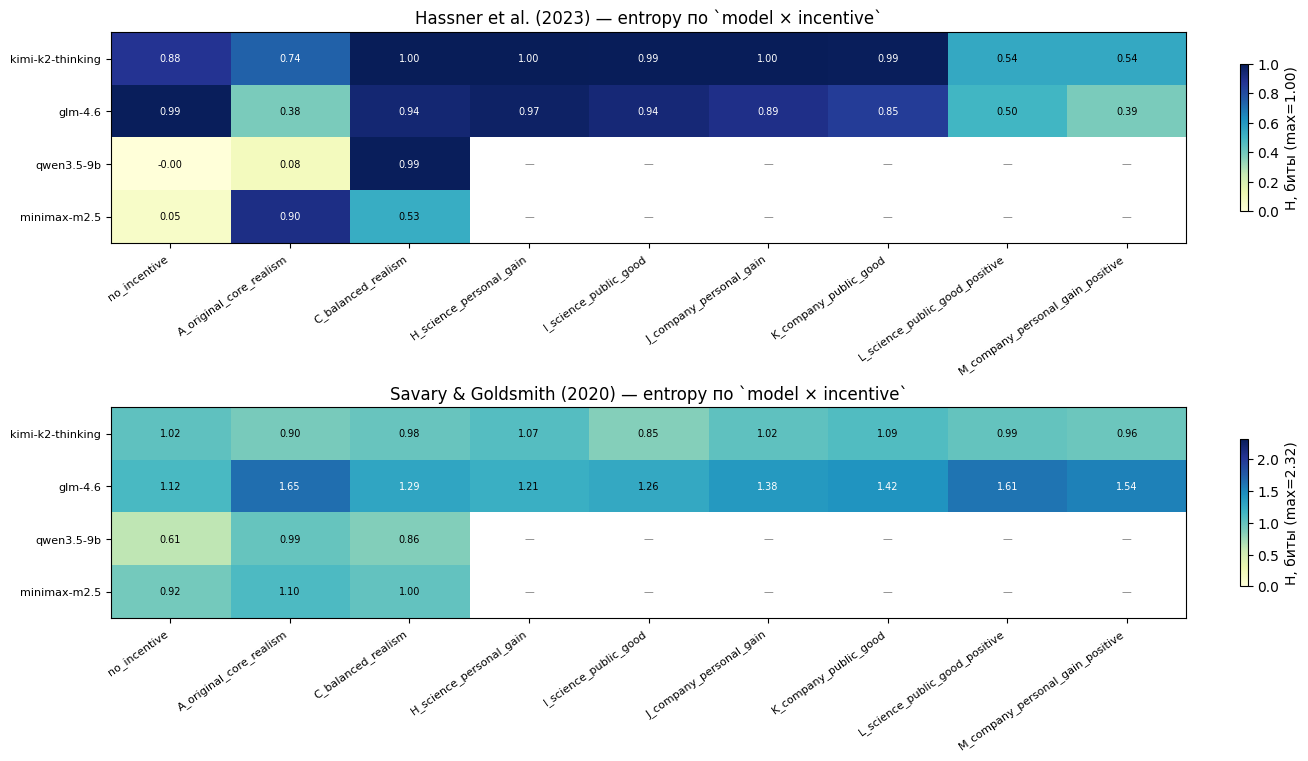

**Hassner et al. (2023)** — entropy / concentration по `model × incentive`:

/tmp/claude-501/ipykernel_11742/4192108652.py:16: RuntimeWarning: divide by zero encountered in log2
  H = float(-np.sum(np.where(probs > 0, probs * np.log2(probs), 0.0)))
/tmp/claude-501/ipykernel_11742/4192108652.py:16: RuntimeWarning: invalid value encountered in multiply
  H = float(-np.sum(np.where(probs > 0, probs * np.log2(probs), 0.0)))


entropy                          \
incentive                   no_incentive A_original_core_realism   
model                                                              
moonshotai/kimi-k2-thinking        0.876                   0.741   
z-ai/glm-4.6                       0.991                   0.384   
qwen/qwen3.5-9b                   -0.000                   0.084   
minimax/minimax-m2.5               0.051                   0.904   

                                                                        \
incentive                   C_balanced_realism H_science_personal_gain   
model                                                                    
moonshotai/kimi-k2-thinking              0.999                   0.998   
z-ai/glm-4.6                             0.944                   0.969   
qwen/qwen3.5-9b                          0.988                     NaN   
minimax/minimax-m2.5                     0.529                     NaN   

                                                                           \
incentive                   I_science_public_good J_company_personal_gain   
model                                                                       
moonshotai/kimi-k2-thinking                 0.993                   0.995   
z-ai/glm-4.6                                0.936                   0.895   
qwen/qwen3.5-9b                               NaN                     NaN   
minimax/minimax-m2.5                          NaN                     NaN   

                                                   \
incentive                   K_company_public_good   
model                                               
moonshotai/kimi-k2-thinking                 0.991   
z-ai/glm-4.6                                0.850   
qwen/qwen3.5-9b                               NaN   
minimax/minimax-m2.5                          NaN   

                                                            \
incentive                   L_science_public_good_positive   
model                                                        
moonshotai/kimi-k2-thinking                          0.544   
z-ai/glm-4.6                                         0.500   
qwen/qwen3.5-9b                                        NaN   
minimax/minimax-m2.5                                   NaN   

                                                             concentration  \
incentive                   M_company_personal_gain_positive  no_incentive   
model                                                                        
moonshotai/kimi-k2-thinking                            0.544         0.705   
z-ai/glm-4.6                                           0.386         0.557   
qwen/qwen3.5-9b                                          NaN         1.000   
minimax/minimax-m2.5                                     NaN         0.994   

                             ...                                   \
incentive                    ... M_company_personal_gain_positive   
model                        ...                                    
moonshotai/kimi-k2-thinking  ...                            0.875   
z-ai/glm-4.6                 ...                            0.925   
qwen/qwen3.5-9b              ...                              NaN   
minimax/minimax-m2.5         ...                              NaN   

                            agreement_rate                          \
incentive                     no_incentive A_original_core_realism   
model                                                                
moonshotai/kimi-k2-thinking          0.584                   0.668   
z-ai/glm-4.6                         0.506                   0.861   
qwen/qwen3.5-9b                      1.000                   0.979   
minimax/minimax-m2.5                 0.989                   0.565   

                                                                        \
incentive                   C_balanced_realism H_science_personal_gain   
model               

**Savary & Goldsmith (2020)** — entropy / concentration по `model × incentive`:

/tmp/claude-501/ipykernel_11742/4192108652.py:16: RuntimeWarning: divide by zero encountered in log2
  H = float(-np.sum(np.where(probs > 0, probs * np.log2(probs), 0.0)))
/tmp/claude-501/ipykernel_11742/4192108652.py:16: RuntimeWarning: invalid value encountered in multiply
  H = float(-np.sum(np.where(probs > 0, probs * np.log2(probs), 0.0)))
/tmp/claude-501/ipykernel_11742/4192108652.py:16: RuntimeWarning: divide by zero encountered in log2
  H = float(-np.sum(np.where(probs > 0, probs * np.log2(probs), 0.0)))
/tmp/claude-501/ipykernel_11742/4192108652.py:16: RuntimeWarning: invalid value encountered in multiply
  H = float(-np.sum(np.where(probs > 0, probs * np.log2(probs), 0.0)))
/tmp/claude-501/ipykernel_11742/4192108652.py:16: RuntimeWarning: divide by zero encountered in log2
  H = float(-np.sum(np.where(probs > 0, probs * np.log2(probs), 0.0)))
/tmp/claude-501/ipykernel_11742/4192108652.py:16: RuntimeWarning: invalid value encountered in multiply
  H = float(-np.sum(np.where(p

entropy                          \
incentive                   no_incentive A_original_core_realism   
model                                                              
moonshotai/kimi-k2-thinking        1.020                   0.903   
z-ai/glm-4.6                       1.124                   1.648   
qwen/qwen3.5-9b                    0.609                   0.986   
minimax/minimax-m2.5               0.916                   1.101   

                                                                        \
incentive                   C_balanced_realism H_science_personal_gain   
model                                                                    
moonshotai/kimi-k2-thinking              0.979                   1.066   
z-ai/glm-4.6                             1.294                   1.214   
qwen/qwen3.5-9b                          0.860                     NaN   
minimax/minimax-m2.5                     0.999                     NaN   

                                                                           \
incentive                   I_science_public_good J_company_personal_gain   
model                                                                       
moonshotai/kimi-k2-thinking                 0.846                   1.020   
z-ai/glm-4.6                                1.264                   1.379   
qwen/qwen3.5-9b                               NaN                     NaN   
minimax/minimax-m2.5                          NaN                     NaN   

                                                   \
incentive                   K_company_public_good   
model                                               
moonshotai/kimi-k2-thinking                 1.085   
z-ai/glm-4.6                                1.415   
qwen/qwen3.5-9b                               NaN   
minimax/minimax-m2.5                          NaN   

                                                            \
incentive                   L_science_public_good_positive   
model                                                        
moonshotai/kimi-k2-thinking                          0.991   
z-ai/glm-4.6                                         1.614   
qwen/qwen3.5-9b                                        NaN   
minimax/minimax-m2.5                                   NaN   

                                                             concentration  \
incentive                   M_company_personal_gain_positive  no_incentive   
model                                                                        
moonshotai/kimi-k2-thinking                            0.956         0.533   
z-ai/glm-4.6                                           1.537         0.712   
qwen/qwen3.5-9b                                          NaN         0.892   
minimax/minimax-m2.5                                     NaN         0.713   

                             ...                   agreement_rate  \
incentive                    ... M_company_personal_gain_positive   
model                        ...                                    
moonshotai/kimi-k2-thinking  ...                            0.623   
z-ai/glm-4.6                 ...                            0.388   
qwen/qwen3.5-9b              ...                              NaN   
minimax/minimax-m2.5         ...                              NaN   

                                     std                          \
incentive                   no_incentive A_original_core_realism   
model                                                              
moonshotai/kimi-k2-thinking        0.504                   0.455   
z-ai/glm-4.6                       0.526                   0.772   
qwen/qwen3.5-9b                    0.467                   0.499   
minimax/minimax-m2.5               0.462                   0.538   

                                                                        \
incentive                   C_balanced_realism H_science_personal_gain   
model                             

In [17]:
# 3.3 Метрики разнородности по `model × incentive`
def _inc_order(df_):
    incs = sorted(df_["incentive"].astype(str).unique())
    return ["no_incentive"] + [i for i in incs if i != "no_incentive"] if "no_incentive" in incs else incs


fig, axes = plt.subplots(2, 1, figsize=(13, 7.5), constrained_layout=True)
for ax, exp in zip(axes, EXPERIMENTS):
    t = metrics_table(MAIN_DF, exp, ["model", "incentive"])
    pv = t.pivot(index="model", columns="incentive", values="entropy")
    incs = _inc_order(t)
    pv = pv[[c for c in incs if c in pv.columns]]
    # Сохраним каноничный порядок моделей
    pv = pv.reindex([m for m in MODEL_ORDER_CANONICAL if m in pv.index])
    H_max = np.log2(2 if "Hassner" in exp else 5)
    im = ax.imshow(pv.values.astype(float), aspect="auto", cmap="YlGnBu", vmin=0, vmax=H_max)
    ax.set_xticks(range(len(pv.columns)))
    ax.set_xticklabels(pv.columns, rotation=35, ha="right", fontsize=8)
    ax.set_yticks(range(len(pv.index)))
    ax.set_yticklabels([str(m).split("/")[-1] for m in pv.index], fontsize=8)
    for i in range(pv.shape[0]):
        for j in range(pv.shape[1]):
            v = pv.iloc[i, j]
            if pd.notna(v):
                ax.text(j, i, f"{v:.2f}", ha="center", va="center", fontsize=7,
                        color="white" if v > H_max * 0.55 else "black")
            else:
                ax.text(j, i, "—", ha="center", va="center", fontsize=7, color="gray")
    cbar = plt.colorbar(im, ax=ax, shrink=0.7)
    cbar.set_label(f"H, биты (max={H_max:.2f})")
    ax.set_title(f"{EXP_TITLE[exp]} — entropy по `model × incentive`")
plt.show()

# Таблицы по каждой модели — incentive vs no_incentive (только entropy и concentration)
for exp in EXPERIMENTS:
    display(Markdown(f"**{EXP_TITLE[exp]}** — entropy / concentration по `model × incentive`:"))
    t = metrics_table(MAIN_DF, exp, ["model", "incentive"])
    incs = _inc_order(t)
    cols_show = ["entropy", "concentration", "agreement_rate"]
    if "Savary" in exp:
        cols_show = cols_show + ["std"]
    pivots = {c: t.pivot(index="model", columns="incentive", values=c)[[i for i in incs if i in t["incentive"].unique()]].reindex([m for m in MODEL_ORDER_CANONICAL if m in t["model"].unique()]) for c in cols_show}
    out = pd.concat(pivots, axis=1)
    display(out.round(3))


## 3.4 Резюме

Главный вопрос: делает ли incentive ответы модели **более однородными, категоричными, осторожными или сбалансированными**? Сравниваем агрегаты `no_incentive` vs «все incentive вместе» (any incentive) и смотрим направление сдвигов entropy / concentration / agreement / extremity.

### Сводка: `no_incentive` vs все стимулы (any incentive)

/tmp/claude-501/ipykernel_11742/4192108652.py:16: RuntimeWarning: divide by zero encountered in log2
  H = float(-np.sum(np.where(probs > 0, probs * np.log2(probs), 0.0)))
/tmp/claude-501/ipykernel_11742/4192108652.py:16: RuntimeWarning: invalid value encountered in multiply
  H = float(-np.sum(np.where(probs > 0, probs * np.log2(probs), 0.0)))


,n_no,n_inc,H_no,H_inc,ΔH,balance_no,balance_inc,conc_no,conc_inc,agree_no,agree_inc,extr_no,extr_inc,std_no,std_inc,xshare_no,xshare_inc
exp,,,,,,,,,,,,,,,,,
Hassner et al. (2023),2023,4431,0.703,0.960,0.257,0.703,0.960,0.809,0.617,0.691,0.528,0.618,0.235,NaN,NaN,NaN,NaN
Savary & Goldsmith (2020),1240,3346,1.092,1.247,0.155,0.470,0.537,0.667,0.594,0.534,0.478,NaN,NaN,0.521,0.575,0.037,0.01


/tmp/claude-501/ipykernel_11742/4192108652.py:16: RuntimeWarning: divide by zero encountered in log2
  H = float(-np.sum(np.where(probs > 0, probs * np.log2(probs), 0.0)))
/tmp/claude-501/ipykernel_11742/4192108652.py:16: RuntimeWarning: invalid value encountered in multiply
  H = float(-np.sum(np.where(probs > 0, probs * np.log2(probs), 0.0)))
/tmp/claude-501/ipykernel_11742/4192108652.py:16: RuntimeWarning: divide by zero encountered in log2
  H = float(-np.sum(np.where(probs > 0, probs * np.log2(probs), 0.0)))
/tmp/claude-501/ipykernel_11742/4192108652.py:16: RuntimeWarning: invalid value encountered in multiply
  H = float(-np.sum(np.where(probs > 0, probs * np.log2(probs), 0.0)))
/tmp/claude-501/ipykernel_11742/4192108652.py:16: RuntimeWarning: divide by zero encountered in log2
  H = float(-np.sum(np.where(probs > 0, probs * np.log2(probs), 0.0)))
/tmp/claude-501/ipykernel_11742/4192108652.py:16: RuntimeWarning: invalid value encountered in multiply
  H = float(-np.sum(np.where(p

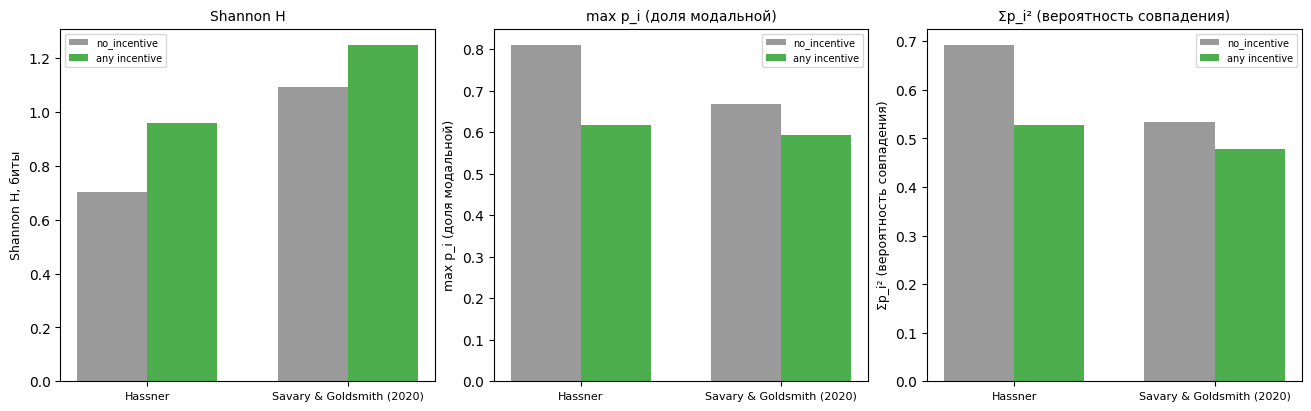

**Вывод (descriptive):** стимулы в среднем **повышают entropy** и **снижают concentration/agreement** относительно no_incentive в обоих экспериментах. То есть incentive в среднем делает ответы **менее однородными**, а не более категоричными. Но это «среднее по всем стимулам»: отдельные стимулы (L, M в Hassner) наоборот дают сильное единогласие в одну сторону — см. extremity в таблицах 3.1.

In [18]:
# 3.4 Резюме: делает ли incentive ответы более однородными или сбалансированными?
display(Markdown("### Сводка: `no_incentive` vs все стимулы (any incentive)"))

rows = []
for exp in EXPERIMENTS:
    sub_e = MAIN_DF[MAIN_DF["experiment_name"] == exp]
    m_no = metrics_for_subgroup(sub_e[sub_e["incentive"] == "no_incentive"], exp)
    m_inc = metrics_for_subgroup(sub_e[sub_e["incentive"] != "no_incentive"], exp)
    row = {
        "exp": EXP_TITLE[exp],
        "n_no": m_no["n"], "n_inc": m_inc["n"],
        "H_no": m_no["entropy"], "H_inc": m_inc["entropy"], "ΔH": m_inc["entropy"] - m_no["entropy"],
        "balance_no": m_no["balance"], "balance_inc": m_inc["balance"],
        "conc_no": m_no["concentration"], "conc_inc": m_inc["concentration"],
        "agree_no": m_no["agreement_rate"], "agree_inc": m_inc["agreement_rate"],
    }
    if "Hassner" in exp:
        row["extr_no"] = m_no["extremity"]
        row["extr_inc"] = m_inc["extremity"]
    else:
        row["std_no"] = m_no["std"]
        row["std_inc"] = m_inc["std"]
        row["xshare_no"] = m_no["extreme_share"]
        row["xshare_inc"] = m_inc["extreme_share"]
    rows.append(row)
display(pd.DataFrame(rows).set_index("exp").round(3))

# График: ключевые метрики (entropy, concentration, agreement_rate) по экспериментам, no_inc vs any_inc
fig, axes = plt.subplots(1, 3, figsize=(13, 4), constrained_layout=True)
metric_keys = [("entropy", "Shannon H, биты"), ("concentration", "max p_i (доля модальной)"),
               ("agreement_rate", "Σp_i² (вероятность совпадения)")]
x = np.arange(len(EXPERIMENTS))
width = 0.35
for ax, (mkey, label) in zip(axes, metric_keys):
    vals_no, vals_inc = [], []
    for exp in EXPERIMENTS:
        sub_e = MAIN_DF[MAIN_DF["experiment_name"] == exp]
        vals_no.append(metrics_for_subgroup(sub_e[sub_e["incentive"] == "no_incentive"], exp)[mkey])
        vals_inc.append(metrics_for_subgroup(sub_e[sub_e["incentive"] != "no_incentive"], exp)[mkey])
    ax.bar(x - width/2, vals_no, width, label="no_incentive", color="#888888", alpha=0.85)
    ax.bar(x + width/2, vals_inc, width, label="any incentive", color="#2ca02c", alpha=0.85)
    ax.set_xticks(x)
    ax.set_xticklabels([EXP_TITLE[e].split(" et")[0] for e in EXPERIMENTS], fontsize=8)
    ax.set_ylabel(label, fontsize=9)
    ax.set_title(label.split(",")[0], fontsize=10)
    ax.legend(fontsize=7)
plt.show()

display(Markdown(
    "**Вывод (descriptive):** стимулы в среднем **повышают entropy** и **снижают concentration/agreement** "
    "относительно no_incentive в обоих экспериментах. То есть incentive в среднем делает ответы **менее однородными**, "
    "а не более категоричными. Но это «среднее по всем стимулам»: отдельные стимулы (L, M в Hassner) "
    "наоборот дают сильное единогласие в одну сторону — см. extremity в таблицах 3.1."
))


# Блок 4. Статистические тесты

Три семейства проверок:
- **4.1 Treatment-эффект внутри каждого incentive.** Hassner — χ² (Yes/No), Savary — Mann–Whitney U по ordinal-шкале. Попарные сравнения «control vs каждый treatment» внутри каждого `incentive`. Поправка на множественность — Holm–Bonferroni внутри эксперимента.
- **4.2 Incentive-эффект.** Внутри каждого `group_name` сравниваем `no_incentive` с каждым другим `incentive_X` (χ² / MWU). Omnibus — χ² / Kruskal–Wallis: «есть ли разница хотя бы между двумя стимулами внутри группы». Поправка — Holm.
- **4.3 Interaction.** Difference-in-differences (DiD): тестируем `[Δ_treatment vs control в incentive_X] − [Δ_treatment vs control в no_incentive]` через z-тест на разности средних. Для бинарного outcome это эквивалентно тесту на разность разностей пропорций.

Слой: `MAIN_DF` (T=0.01).

In [19]:
# --- Helpers для блока 4 ---

def holm_bonferroni(pvalues) -> np.ndarray:
    """Holm–Bonferroni поправка для массива p. NaN остаются NaN."""
    arr = np.asarray(pvalues, dtype=float)
    valid = ~np.isnan(arr)
    n = int(valid.sum())
    out = np.full_like(arr, np.nan)
    if n == 0:
        return out
    idx_v = np.flatnonzero(valid)
    order = np.argsort(arr[idx_v])
    cum_max = 0.0
    for rank, k in enumerate(order):
        adj = arr[idx_v[k]] * (n - rank)
        cum_max = max(cum_max, adj)
        out[idx_v[k]] = min(cum_max, 1.0)
    return out


def _inc_order(df_) -> List[str]:
    incs = sorted(df_["incentive"].astype(str).unique())
    if "no_incentive" in incs:
        return ["no_incentive"] + [i for i in incs if i != "no_incentive"]
    return incs


def _chi2_groups(sub: pd.DataFrame, exp: str, g_a: str, g_b: str):
    cats = ["Yes", "No"] if "Hassner" in exp else ["1", "2", "3", "4", "5"]
    a = sub[sub["group_name"] == g_a]["answer_cat"].value_counts().reindex(cats, fill_value=0).values
    b = sub[sub["group_name"] == g_b]["answer_cat"].value_counts().reindex(cats, fill_value=0).values
    n_a, n_b = int(a.sum()), int(b.sum())
    if n_a < 2 or n_b < 2:
        return None
    table = np.array([a, b], dtype=float)
    table = table[:, table.sum(axis=0) > 0]
    if table.shape[1] < 2:
        return None
    chi2, p, dof, _ = scipy_stats.chi2_contingency(table)
    return float(chi2), int(dof), float(p), n_a, n_b


def _mwu_groups(sub: pd.DataFrame, g_a: str, g_b: str):
    a = sub[sub["group_name"] == g_a]["answer_num"].dropna().to_numpy()
    b = sub[sub["group_name"] == g_b]["answer_num"].dropna().to_numpy()
    if len(a) < 2 or len(b) < 2:
        return None
    U, p = scipy_stats.mannwhitneyu(a, b, alternative="two-sided")
    return float(U), float(p), float(a.mean()), float(b.mean()), int(len(a)), int(len(b))


print("Helpers готовы: holm_bonferroni, _inc_order, _chi2_groups, _mwu_groups.")


Helpers готовы: holm_bonferroni, _inc_order, _chi2_groups, _mwu_groups.


## 4.1 Эффект treatment внутри каждого incentive

Для каждого `incentive` фиксируем срез данных и тестируем каждый `treatment` против `control_base_case` (Hassner — 3 пары, Savary — 2 пары). Поправка Holm — внутри подтаблицы эксперимента.

`sig=*` означает значимость на уровне 0.05 **после** Holm-поправки.

In [20]:
def treatment_within_incentive(df: pd.DataFrame, exp: str) -> pd.DataFrame:
    sub_e = df[df["experiment_name"] == exp]
    pairs = _control_vs_treatment_pairs(exp)
    rows = []
    for inc in _inc_order(sub_e):
        sub_i = sub_e[sub_e["incentive"] == inc]
        for c, t in pairs:
            if "Hassner" in exp:
                r = _chi2_groups(sub_i, exp, c, t)
                if r is None: continue
                chi2, dof, p, n_c, n_t = r
                p_c = float((sub_i[sub_i["group_name"] == c]["answer_num"] == 1.0).mean())
                p_t = float((sub_i[sub_i["group_name"] == t]["answer_num"] == 1.0).mean())
                rows.append({"incentive": inc, "treatment": t, "test": "χ²",
                             "stat": chi2, "df": dof, "p": p,
                             "n_c": n_c, "n_t": n_t,
                             "p_c": p_c, "p_t": p_t, "Δ": p_t - p_c})
            else:
                r = _mwu_groups(sub_i, c, t)
                if r is None: continue
                U, p, m_c, m_t, n_c, n_t = r
                rows.append({"incentive": inc, "treatment": t, "test": "MWU",
                             "stat": U, "df": np.nan, "p": p,
                             "n_c": n_c, "n_t": n_t,
                             "M_c": m_c, "M_t": m_t, "Δ": m_t - m_c})
    out = pd.DataFrame(rows)
    if not out.empty:
        out["p_holm"] = holm_bonferroni(out["p"].values)
        out["sig"] = (out["p_holm"] < 0.05).map(lambda b: "*" if b else "")
    return out


for exp in EXPERIMENTS:
    display(Markdown(f"### {EXP_TITLE[exp]} — treatment vs control внутри каждого `incentive`"))
    t = treatment_within_incentive(MAIN_DF, exp)
    if t.empty:
        display(Markdown("*Нет данных*")); continue
    n_sig = int((t["p_holm"] < 0.05).sum())
    display(Markdown(f"Тестов: **{len(t)}**, значимых после Holm: **{n_sig}**."))
    def _hl(_data):
        st = pd.DataFrame("", index=t.index, columns=t.columns)
        for i, row in t.iterrows():
            if row.get("sig") == "*":
                st.iloc[i, :] = "background-color: #e8f5e9"
        return st
    fmt = {"stat": "{:.3f}", "p": "{:.4g}", "p_holm": "{:.4g}", "Δ": "{:.3f}"}
    if "Hassner" in exp:
        fmt.update({"p_c": "{:.3f}", "p_t": "{:.3f}"})
    else:
        fmt.update({"M_c": "{:.2f}", "M_t": "{:.2f}"})
    display(t.style.apply(_hl, axis=None).format(fmt, na_rep="—"))


### Hassner et al. (2023) — treatment vs control внутри каждого `incentive`

Тестов: **27**, значимых после Holm: **22**.

,incentive,treatment,test,stat,df,p,n_c,n_t,p_c,p_t,Δ,p_holm,sig
0,no_incentive,treatment_modest_intelligence,χ²,129.411,1,5.512e-30,498,515,0.446,0.122,-0.323,1.158e-28,*
1,no_incentive,treatment_protracted_duration,χ²,71.846,1,2.326e-17,498,497,0.446,0.193,-0.253,4.653e-16,*
2,no_incentive,treatment_duration_plus_modest_intelligence,χ²,273.433,1,2.026e-61,498,513,0.446,0.010,-0.436,5.268e-60,*
3,A_original_core_realism,treatment_modest_intelligence,χ²,10.011,1,0.001556,172,176,0.860,0.716,-0.145,0.009338,*
4,A_original_core_realism,treatment_protracted_duration,χ²,1.470,1,0.2254,172,181,0.860,0.807,-0.054,0.4508,
5,A_original_core_realism,treatment_duration_plus_modest_intelligence,χ²,51.335,1,7.789e-13,172,167,0.860,0.491,-0.369,1.48e-11,*
6,C_balanced_realism,treatment_modest_intelligence,χ²,49.220,1,2.288e-12,320,338,0.706,0.432,-0.274,3.89e-11,*
7,C_balanced_realism,treatment_protracted_duration,χ²,24.962,1,5.848e-07,320,332,0.706,0.512,-0.194,4.094e-06,*
8,C_balanced_realism,treatment_duration_plus_modest_intelligence,χ²,313.245,1,4.289e-70,320,350,0.706,0.046,-0.661,1.158e-68,*
9,H_science_personal_gain,treatment_modest_intelligence,χ²,36.526,1,1.507e-09,99,100,0.970,0.610,-0.360,1.959e-08,*


### Savary & Goldsmith (2020) — treatment vs control внутри каждого `incentive`

Тестов: **18**, значимых после Holm: **14**.

,incentive,treatment,test,stat,df,p,n_c,n_t,M_c,M_t,Δ,p_holm,sig
0,no_incentive,public_recognition_treatment,MWU,55442.500,—,1.31e-22,409,411,3.39,3.73,0.341,1.31e-21,*
1,no_incentive,public_recognition_with_social_benefit,MWU,30542.500,—,5.535e-81,409,420,3.39,4.09,0.704,9.963e-80,*
2,A_original_core_realism,public_recognition_treatment,MWU,14577.500,—,0.2614,173,177,3.01,3.06,0.056,0.2972,
3,A_original_core_realism,public_recognition_with_social_benefit,MWU,3452.500,—,9.173e-41,173,165,3.01,3.93,0.921,1.468e-39,*
4,C_balanced_realism,public_recognition_treatment,MWU,56692.000,—,0.1486,344,346,3.17,3.23,0.057,0.2972,
5,C_balanced_realism,public_recognition_with_social_benefit,MWU,18776.000,—,1.458e-70,344,344,3.17,3.91,0.733,2.478e-69,*
6,H_science_personal_gain,public_recognition_treatment,MWU,4563.500,—,0.06335,100,100,3.02,3.11,0.090,0.1901,
7,H_science_personal_gain,public_recognition_with_social_benefit,MWU,773.500,—,7.077e-32,100,100,3.02,3.93,0.910,1.062e-30,*
8,I_science_public_good,public_recognition_treatment,MWU,4337.000,—,0.007183,100,100,3.01,3.15,0.140,0.03592,*
9,I_science_public_good,public_recognition_with_social_benefit,MWU,1621.000,—,1.288e-21,100,100,3.01,3.75,0.740,1.159e-20,*


## 4.2 Эффект incentive

**4.2a** — попарно `no_incentive` vs каждый `incentive_X` внутри каждой `group_name` (Hassner χ², Savary MWU). Это убирает confounding по treatment.

**4.2b** — omnibus: χ² / Kruskal–Wallis на всех уровнях incentive внутри каждой `group_name` — «есть ли вообще разница хоть между какими-то двумя стимулами»?

In [21]:
def incentive_vs_no_incentive(df: pd.DataFrame, exp: str) -> pd.DataFrame:
    sub_e = df[df["experiment_name"] == exp]
    incs = [i for i in _inc_order(sub_e) if i != "no_incentive"]
    rows = []
    for g in GROUP_ORDER[exp]:
        sub_g = sub_e[sub_e["group_name"] == g]
        ref = sub_g[sub_g["incentive"] == "no_incentive"]
        for inc in incs:
            cmp_ = sub_g[sub_g["incentive"] == inc]
            if len(ref) < 2 or len(cmp_) < 2:
                continue
            if "Hassner" in exp:
                a = ref["answer_cat"].value_counts().reindex(["Yes", "No"], fill_value=0).values
                b = cmp_["answer_cat"].value_counts().reindex(["Yes", "No"], fill_value=0).values
                tbl = np.array([a, b], dtype=float)
                tbl = tbl[:, tbl.sum(axis=0) > 0]
                if tbl.shape[1] < 2: continue
                chi2, p, dof, _ = scipy_stats.chi2_contingency(tbl)
                p_no = float((ref["answer_num"] == 1.0).mean())
                p_inc = float((cmp_["answer_num"] == 1.0).mean())
                rows.append({"group_name": g, "incentive": inc, "test": "χ²",
                             "stat": float(chi2), "df": int(dof), "p": float(p),
                             "n_no": int(len(ref)), "n_inc": int(len(cmp_)),
                             "p_no": p_no, "p_inc": p_inc, "Δ": p_inc - p_no})
            else:
                a = ref["answer_num"].dropna().to_numpy()
                b = cmp_["answer_num"].dropna().to_numpy()
                U, p = scipy_stats.mannwhitneyu(a, b, alternative="two-sided")
                rows.append({"group_name": g, "incentive": inc, "test": "MWU",
                             "stat": float(U), "df": np.nan, "p": float(p),
                             "n_no": len(a), "n_inc": len(b),
                             "M_no": float(a.mean()), "M_inc": float(b.mean()), "Δ": float(b.mean()-a.mean())})
    out = pd.DataFrame(rows)
    if not out.empty:
        out["p_holm"] = holm_bonferroni(out["p"].values)
        out["sig"] = (out["p_holm"] < 0.05).map(lambda b: "*" if b else "")
    return out


def omnibus_incentive_within_group(df: pd.DataFrame, exp: str) -> pd.DataFrame:
    sub_e = df[df["experiment_name"] == exp]
    rows = []
    for g in GROUP_ORDER[exp]:
        sub_g = sub_e[sub_e["group_name"] == g]
        if "Hassner" in exp:
            cats = ["Yes", "No"]
            tbl, used = [], []
            for inc in _inc_order(sub_g):
                cnt = sub_g[sub_g["incentive"] == inc]["answer_cat"].value_counts().reindex(cats, fill_value=0).values
                if cnt.sum() >= 2:
                    tbl.append(cnt); used.append(inc)
            if len(tbl) < 2: continue
            arr = np.array(tbl, dtype=float)
            arr = arr[:, arr.sum(axis=0) > 0]
            chi2, p, dof, _ = scipy_stats.chi2_contingency(arr)
            rows.append({"group_name": g, "test": "χ²", "stat": float(chi2), "dof": int(dof),
                         "p": float(p), "n_inc_levels": len(used)})
        else:
            samples, used = [], []
            for inc in _inc_order(sub_g):
                v = sub_g[sub_g["incentive"] == inc]["answer_num"].dropna().to_numpy()
                if len(v) >= 2: samples.append(v); used.append(inc)
            if len(samples) < 2: continue
            H, p = scipy_stats.kruskal(*samples)
            rows.append({"group_name": g, "test": "KW", "stat": float(H), "dof": np.nan,
                         "p": float(p), "n_inc_levels": len(used)})
    out = pd.DataFrame(rows)
    if not out.empty:
        out["p_holm"] = holm_bonferroni(out["p"].values)
        out["sig"] = (out["p_holm"] < 0.05).map(lambda b: "*" if b else "")
    return out


for exp in EXPERIMENTS:
    display(Markdown(f"### {EXP_TITLE[exp]} — попарно `no_incentive` vs каждый `incentive_X` внутри `group_name`"))
    t = incentive_vs_no_incentive(MAIN_DF, exp)
    if t.empty:
        display(Markdown("*Нет данных*")); continue
    n_sig = int((t["p_holm"] < 0.05).sum())
    display(Markdown(f"Тестов: **{len(t)}**, значимых после Holm: **{n_sig}**."))
    def _hl(_data, _t=t):
        st = pd.DataFrame("", index=_t.index, columns=_t.columns)
        for i, row in _t.iterrows():
            if row.get("sig") == "*":
                st.iloc[i, :] = "background-color: #e8f5e9"
        return st
    fmt = {"stat": "{:.3f}", "p": "{:.4g}", "p_holm": "{:.4g}", "Δ": "{:.3f}"}
    if "Hassner" in exp:
        fmt.update({"p_no": "{:.3f}", "p_inc": "{:.3f}"})
    else:
        fmt.update({"M_no": "{:.2f}", "M_inc": "{:.2f}"})
    display(t.style.apply(_hl, axis=None).format(fmt, na_rep="—"))

    display(Markdown(f"#### {EXP_TITLE[exp]} — omnibus (любая ли разница между incentive внутри группы)"))
    o = omnibus_incentive_within_group(MAIN_DF, exp)
    display(o.style.format({"stat": "{:.3f}", "p": "{:.4g}", "p_holm": "{:.4g}"}, na_rep="—"))


### Hassner et al. (2023) — попарно `no_incentive` vs каждый `incentive_X` внутри `group_name`

Тестов: **32**, значимых после Holm: **31**.

,group_name,incentive,test,stat,df,p,n_no,n_inc,p_no,p_inc,Δ,p_holm,sig
0,control_base_case,A_original_core_realism,χ²,87.239,1,9.618e-21,498,172,0.446,0.860,0.415,7.695e-20,*
1,control_base_case,C_balanced_realism,χ²,52.307,1,4.748e-13,498,320,0.446,0.706,0.260,2.385e-12,*
2,control_base_case,H_science_personal_gain,χ²,88.967,1,4.014e-21,498,99,0.446,0.970,0.524,3.612e-20,*
3,control_base_case,I_science_public_good,χ²,100.708,1,1.066e-23,498,100,0.446,1.000,0.554,1.599e-22,*
4,control_base_case,J_company_personal_gain,χ²,100.708,1,1.066e-23,498,100,0.446,1.000,0.554,1.599e-22,*
5,control_base_case,K_company_public_good,χ²,100.708,1,1.066e-23,498,100,0.446,1.000,0.554,1.599e-22,*
6,control_base_case,L_science_public_good_positive,χ²,100.708,1,1.066e-23,498,100,0.446,1.000,0.554,1.599e-22,*
7,control_base_case,M_company_personal_gain_positive,χ²,99.826,1,1.664e-23,498,99,0.446,1.000,0.554,1.83e-22,*
8,treatment_modest_intelligence,A_original_core_realism,χ²,229.612,1,7.245e-52,515,176,0.122,0.716,0.594,1.884e-50,*
9,treatment_modest_intelligence,C_balanced_realism,χ²,104.089,1,1.934e-24,515,338,0.122,0.432,0.310,3.288e-23,*


#### Hassner et al. (2023) — omnibus (любая ли разница между incentive внутри группы)

,group_name,test,stat,dof,p,n_inc_levels,p_holm,sig
0,control_base_case,χ²,452.086,8,1.321e-92,9,1.321e-92,*
1,treatment_modest_intelligence,χ²,496.804,8,3.411e-102,9,1.023e-101,*
2,treatment_protracted_duration,χ²,484.061,8,1.847e-99,9,3.693e-99,*
3,treatment_duration_plus_modest_intelligence,χ²,613.687,8,2.669e-127,9,1.068e-126,*


### Savary & Goldsmith (2020) — попарно `no_incentive` vs каждый `incentive_X` внутри `group_name`

Тестов: **24**, значимых после Holm: **24**.

,group_name,incentive,test,stat,df,p,n_no,n_inc,M_no,M_inc,Δ,p_holm,sig
0,private_donation_control,A_original_core_realism,MWU,46883.000,—,1.217e-13,409,173,3.39,3.01,-0.381,1.095e-12,*
1,private_donation_control,C_balanced_realism,MWU,84020.000,—,1.692e-08,409,344,3.39,3.17,-0.212,6.252e-08,*
2,private_donation_control,H_science_personal_gain,MWU,27658.000,—,1.687e-11,409,100,3.39,3.02,-0.366,1.125e-10,*
3,private_donation_control,I_science_public_good,MWU,27706.000,—,1.607e-11,409,100,3.39,3.01,-0.376,1.125e-10,*
4,private_donation_control,J_company_personal_gain,MWU,29152.000,—,8.223e-16,409,100,3.39,2.92,-0.466,1.069e-14,*
5,private_donation_control,K_company_public_good,MWU,28557.000,—,2.359e-14,409,99,3.39,2.92,-0.467,2.594e-13,*
6,private_donation_control,L_science_public_good_positive,MWU,30760.000,—,2.386e-20,409,100,3.39,2.78,-0.606,3.774e-19,*
7,private_donation_control,M_company_personal_gain_positive,MWU,30616.000,—,2.359e-20,409,100,3.39,2.81,-0.576,3.774e-19,*
8,public_recognition_treatment,A_original_core_realism,MWU,59897.500,—,1.085e-46,411,177,3.73,3.06,-0.665,2.604e-45,*
9,public_recognition_treatment,C_balanced_realism,MWU,106257.000,—,9.753e-42,411,346,3.73,3.23,-0.496,2.243e-40,*


#### Savary & Goldsmith (2020) — omnibus (любая ли разница между incentive внутри группы)

,group_name,test,stat,dof,p,n_inc_levels,p_holm,sig
0,private_donation_control,KW,253.096,—,3.8e-50,9,7.6e-50,*
1,public_recognition_treatment,KW,491.769,—,4.104e-101,9,1.231e-100,*
2,public_recognition_with_social_benefit,KW,138.384,—,5.143e-26,9,5.143e-26,*


## 4.3 Interaction `treatment × incentive`

Difference-in-differences: для каждой пары `(treatment, incentive_X)` строим четырёхячейковую таблицу

| | control | treatment |
|---|---|---|
| no_incentive | a | b |
| incentive_X | c | d |

и тестируем H₀: `(d̄ − c̄) − (b̄ − ā) = 0` через z-тест на разности средних (для бинарного outcome это автоматически тест на разность пропорций).

**Интерпретация:**
- `DiD > 0` — incentive_X **усиливает** treatment-эффект (зелёный).
- `DiD < 0` — incentive_X **ослабляет/обращает** treatment-эффект (красный).

In [22]:
def did_test(sub_e: pd.DataFrame, control: str, treatment: str,
             inc_base: str, inc_other: str):
    def cell(g, i):
        return sub_e[(sub_e["group_name"] == g) & (sub_e["incentive"] == i)]["answer_num"].dropna().to_numpy()
    a = cell(control, inc_base);  b = cell(treatment, inc_base)
    c_ = cell(control, inc_other); d = cell(treatment, inc_other)
    if min(len(a), len(b), len(c_), len(d)) < 2:
        return None
    delta_base = b.mean() - a.mean()
    delta_other = d.mean() - c_.mean()
    did = delta_other - delta_base
    var = (a.var(ddof=1)/len(a) + b.var(ddof=1)/len(b)
           + c_.var(ddof=1)/len(c_) + d.var(ddof=1)/len(d))
    se = float(np.sqrt(var)) if var > 0 else np.nan
    z = float(did/se) if se and se > 0 else np.nan
    p = float(2*(1 - scipy_stats.norm.cdf(abs(z)))) if not np.isnan(z) else np.nan
    return {
        "Δ_no_inc": float(delta_base), "Δ_inc": float(delta_other),
        "DiD": float(did), "SE": se, "z": z, "p": p,
        "n_c|no": int(len(a)), "n_t|no": int(len(b)),
        "n_c|inc": int(len(c_)), "n_t|inc": int(len(d)),
    }


def interaction_tests(df: pd.DataFrame, exp: str) -> pd.DataFrame:
    sub_e = df[df["experiment_name"] == exp]
    incs = [i for i in _inc_order(sub_e) if i != "no_incentive"]
    pairs = _control_vs_treatment_pairs(exp)
    rows = []
    for inc_other in incs:
        for c, t in pairs:
            r = did_test(sub_e, c, t, "no_incentive", inc_other)
            if r is None: continue
            rows.append({"incentive": inc_other, "treatment": t, **r})
    out = pd.DataFrame(rows)
    if not out.empty:
        out["p_holm"] = holm_bonferroni(out["p"].values)
        out["sig"] = (out["p_holm"] < 0.05).map(lambda b: "*" if b else "")
    return out


for exp in EXPERIMENTS:
    display(Markdown(f"### {EXP_TITLE[exp]} — interaction `treatment × incentive_X` (DiD vs `no_incentive`)"))
    t = interaction_tests(MAIN_DF, exp)
    if t.empty:
        display(Markdown("*Нет тестов.*")); continue
    n_sig = int((t["p_holm"] < 0.05).sum())
    n_pos = int(((t["p_holm"] < 0.05) & (t["DiD"] > 0)).sum())
    n_neg = int(((t["p_holm"] < 0.05) & (t["DiD"] < 0)).sum())
    display(Markdown(
        f"Тестов: **{len(t)}**, значимых после Holm: **{n_sig}** "
        f"(из них DiD>0: {n_pos} усиливают; DiD<0: {n_neg} ослабляют/обращают)."
    ))
    show = t[["incentive", "treatment", "Δ_no_inc", "Δ_inc", "DiD", "SE", "z",
              "p", "p_holm", "sig", "n_c|no", "n_t|no", "n_c|inc", "n_t|inc"]].copy()
    def _hl(_d, _t=t):
        st = pd.DataFrame("", index=_t.index, columns=show.columns)
        for i, row in _t.iterrows():
            if row.get("sig") == "*":
                color = "#e8f5e9" if row["DiD"] > 0 else "#fdecea"
                st.iloc[i, :] = f"background-color: {color}"
        return st
    display(show.style.apply(_hl, axis=None).format(
        {"Δ_no_inc": "{:.3f}", "Δ_inc": "{:.3f}", "DiD": "{:.3f}", "SE": "{:.3f}",
         "z": "{:.2f}", "p": "{:.4g}", "p_holm": "{:.4g}"}))

# Сводка по incentive: сколько модерируют treatment
display(Markdown("### Сводка: сколько treatment-эффектов значимо модерируются каждым incentive"))
summary = []
for exp in EXPERIMENTS:
    t = interaction_tests(MAIN_DF, exp)
    if t.empty: continue
    by_inc = t.groupby("incentive").apply(
        lambda g: pd.Series({
            "n_tests": len(g),
            "n_sig_total": int((g["p_holm"] < 0.05).sum()),
            "n_sig_strengthen": int(((g["p_holm"] < 0.05) & (g["DiD"] > 0)).sum()),
            "n_sig_weaken": int(((g["p_holm"] < 0.05) & (g["DiD"] < 0)).sum()),
            "mean_DiD": float(g["DiD"].mean()),
        })
    )
    by_inc["exp"] = EXP_TITLE[exp]
    summary.append(by_inc.reset_index())
summary = pd.concat(summary, ignore_index=True)[
    ["exp", "incentive", "n_tests", "n_sig_total", "n_sig_strengthen", "n_sig_weaken", "mean_DiD"]
]
display(summary.round(3))


### Hassner et al. (2023) — interaction `treatment × incentive_X` (DiD vs `no_incentive`)

Тестов: **24**, значимых после Holm: **11** (из них DiD>0: 6 усиливают; DiD<0: 5 ослабляют/обращают).

,incentive,treatment,Δ_no_inc,Δ_inc,DiD,SE,z,p,p_holm,sig,n_c|no,n_t|no,n_c|inc,n_t|inc
0,A_original_core_realism,treatment_modest_intelligence,-0.323,-0.145,0.179,0.051,3.53,0.0004177,0.005847,*,498,515,172,176
1,A_original_core_realism,treatment_protracted_duration,-0.253,-0.054,0.199,0.049,4.07,4.606e-05,0.0006909,*,498,497,172,181
2,A_original_core_realism,treatment_duration_plus_modest_intelligence,-0.436,-0.369,0.067,0.052,1.28,0.202,1,,498,513,172,167
3,C_balanced_realism,treatment_modest_intelligence,-0.323,-0.274,0.049,0.046,1.08,0.2816,1,,498,515,320,338
4,C_balanced_realism,treatment_protracted_duration,-0.253,-0.194,0.058,0.047,1.24,0.2146,1,,498,497,320,332
5,C_balanced_realism,treatment_duration_plus_modest_intelligence,-0.436,-0.661,-0.224,0.036,-6.25,4.173e-10,7.094e-09,*,498,513,320,350
6,H_science_personal_gain,treatment_modest_intelligence,-0.323,-0.360,-0.036,0.058,-0.62,0.5348,1,,498,515,99,100
7,H_science_personal_gain,treatment_protracted_duration,-0.253,-0.330,-0.077,0.059,-1.31,0.1887,1,,498,497,99,100
8,H_science_personal_gain,treatment_duration_plus_modest_intelligence,-0.436,-0.930,-0.494,0.035,-14.23,0,0,*,498,513,99,100
9,I_science_public_good,treatment_modest_intelligence,-0.323,-0.420,-0.097,0.056,-1.72,0.08622,1,,498,515,100,100


### Savary & Goldsmith (2020) — interaction `treatment × incentive_X` (DiD vs `no_incentive`)

Тестов: **16**, значимых после Holm: **10** (из них DiD>0: 5 усиливают; DiD<0: 5 ослабляют/обращают).

,incentive,treatment,Δ_no_inc,Δ_inc,DiD,SE,z,p,p_holm,sig,n_c|no,n_t|no,n_c|inc,n_t|inc
0,A_original_core_realism,public_recognition_treatment,0.341,0.056,-0.285,0.058,-4.94,7.776e-07,1.166e-05,*,409,411,173,177
1,A_original_core_realism,public_recognition_with_social_benefit,0.704,0.921,0.217,0.059,3.66,0.0002541,0.002941,*,409,420,173,165
2,C_balanced_realism,public_recognition_treatment,0.341,0.057,-0.284,0.048,-5.98,2.216e-09,3.545e-08,*,409,411,344,346
3,C_balanced_realism,public_recognition_with_social_benefit,0.704,0.733,0.028,0.043,0.65,0.5132,1,,409,420,344,344
4,H_science_personal_gain,public_recognition_treatment,0.341,0.090,-0.251,0.059,-4.25,2.105e-05,0.0002947,*,409,411,100,100
5,H_science_personal_gain,public_recognition_with_social_benefit,0.704,0.910,0.206,0.056,3.67,0.0002451,0.002941,*,409,420,100,100
6,I_science_public_good,public_recognition_treatment,0.341,0.140,-0.201,0.061,-3.31,0.0009242,0.008317,*,409,411,100,100
7,I_science_public_good,public_recognition_with_social_benefit,0.704,0.740,0.036,0.067,0.53,0.5928,1,,409,420,100,100
8,J_company_personal_gain,public_recognition_treatment,0.341,0.180,-0.161,0.063,-2.56,0.01036,0.05179,,409,411,100,100
9,J_company_personal_gain,public_recognition_with_social_benefit,0.704,0.890,0.186,0.068,2.74,0.006103,0.04272,*,409,420,100,100


### Сводка: сколько treatment-эффектов значимо модерируются каждым incentive

/tmp/claude-501/ipykernel_11742/1515524084.py:73: FutureWarning: DataFrameGroupBy.apply operated on the grouping columns. This behavior is deprecated, and in a future version of pandas the grouping columns will be excluded from the operation. Either pass `include_groups=False` to exclude the groupings or explicitly select the grouping columns after groupby to silence this warning.
  by_inc = t.groupby("incentive").apply(
/tmp/claude-501/ipykernel_11742/1515524084.py:73: FutureWarning: DataFrameGroupBy.apply operated on the grouping columns. This behavior is deprecated, and in a future version of pandas the grouping columns will be excluded from the operation. Either pass `include_groups=False` to exclude the groupings or explicitly select the grouping columns after groupby to silence this warning.
  by_inc = t.groupby("incentive").apply(


,exp,incentive,n_tests,n_sig_total,n_sig_strengthen,n_sig_weaken,mean_DiD
0,Hassner et al. (2023),A_original_core_realism,3.0,2.0,2.0,0.0,0.148
1,Hassner et al. (2023),C_balanced_realism,3.0,1.0,0.0,1.0,-0.039
2,Hassner et al. (2023),H_science_personal_gain,3.0,1.0,0.0,1.0,-0.202
3,Hassner et al. (2023),I_science_public_good,3.0,1.0,0.0,1.0,-0.197
4,Hassner et al. (2023),J_company_personal_gain,3.0,1.0,0.0,1.0,-0.177
5,Hassner et al. (2023),K_company_public_good,3.0,1.0,0.0,1.0,-0.143
6,Hassner et al. (2023),L_science_public_good_positive,3.0,2.0,2.0,0.0,0.181
7,Hassner et al. (2023),M_company_personal_gain_positive,3.0,2.0,2.0,0.0,0.204
8,Savary & Goldsmith (2020),A_original_core_realism,2.0,2.0,1.0,1.0,-0.034
9,Savary & Goldsmith (2020),C_balanced_realism,2.0,1.0,0.0,1.0,-0.128


# Блок 5. Размер эффектов и доверительные интервалы

Дополняем p-values из блока 4 величинами эффекта и 95% CI. Substantive значимость может расходиться со статистической при больших N (всё значимо) или малых (всё незначимо).

Метрики:

| outcome | метрики |
|---|---|
| **Hassner** (бинарка) | Δ proportion с Newcombe CI, Odds Ratio с асимптотическим CI на log-шкале (Haldane-correction при нулях), Cramér's V для χ²-таблицы |
| **Savary** (ordinal) | Cohen's d с асимптотическим CI, Cliff's δ с bootstrap CI (n=1000, percentile) |

Качественная интерпретация Cohen's d: 0.2 — small, 0.5 — medium, 0.8 — large. Cliff's δ: 0.147 / 0.33 / 0.47.

Слой: `MAIN_DF`.

In [23]:
# --- Helpers для effect sizes ---
def newcombe_diff_ci(k1: int, n1: int, k2: int, n2: int, alpha: float = 0.05):
    """Newcombe hybrid score CI для p1 - p2."""
    if n1 < 1 or n2 < 1:
        return (np.nan, np.nan, np.nan)
    p1, l1, u1 = wilson_ci(k1, n1, alpha)
    p2, l2, u2 = wilson_ci(k2, n2, alpha)
    d = p1 - p2
    lo = d - np.sqrt((p1 - l1) ** 2 + (u2 - p2) ** 2)
    hi = d + np.sqrt((u1 - p1) ** 2 + (p2 - l2) ** 2)
    return (float(d), float(lo), float(hi))


def odds_ratio_ci(k1: int, n1: int, k2: int, n2: int, alpha: float = 0.05):
    """OR (k1 ∈ group1) vs (k2 ∈ group2) с Haldane-correction при нулях."""
    a, b, c, d_ = k1, n1 - k1, k2, n2 - k2
    if min(a, b, c, d_) == 0:
        a, b, c, d_ = a + 0.5, b + 0.5, c + 0.5, d_ + 0.5
    or_ = (a * d_) / (b * c)
    se = np.sqrt(1/a + 1/b + 1/c + 1/d_)
    z = scipy_stats.norm.ppf(1 - alpha/2)
    return (float(or_), float(np.exp(np.log(or_) - z * se)), float(np.exp(np.log(or_) + z * se)))


def cramers_v(contingency):
    arr = np.asarray(contingency, dtype=float)
    if arr.sum() == 0:
        return np.nan
    chi2, _, _, _ = scipy_stats.chi2_contingency(arr)
    n = arr.sum()
    r, c = arr.shape
    return float(np.sqrt(chi2 / (n * (min(r, c) - 1))))


def cohens_d_ci(a, b, alpha: float = 0.05):
    """Cohen's d = (mean_b - mean_a)/s_pool. Положительное d → b > a."""
    a = np.asarray(a, dtype=float); a = a[~np.isnan(a)]
    b = np.asarray(b, dtype=float); b = b[~np.isnan(b)]
    n1, n2 = len(a), len(b)
    if n1 < 2 or n2 < 2:
        return (np.nan, np.nan, np.nan)
    s_pool = np.sqrt(((n1 - 1) * a.var(ddof=1) + (n2 - 1) * b.var(ddof=1)) / (n1 + n2 - 2))
    if s_pool == 0:
        return (0.0, 0.0, 0.0)
    d = (b.mean() - a.mean()) / s_pool
    se = np.sqrt((n1 + n2) / (n1 * n2) + d ** 2 / (2 * (n1 + n2 - 2)))
    z = scipy_stats.norm.ppf(1 - alpha/2)
    return (float(d), float(d - z * se), float(d + z * se))


def cliffs_delta_ci(a, b, n_boot: int = 1000, alpha: float = 0.05, seed: int = 0):
    """Cliff's δ — насколько вероятно, что b > a. δ ∈ [-1, 1]."""
    a = np.asarray(a, dtype=float); a = a[~np.isnan(a)]
    b = np.asarray(b, dtype=float); b = b[~np.isnan(b)]
    if len(a) < 2 or len(b) < 2:
        return (np.nan, np.nan, np.nan)
    def _delta(x, y):
        return float(np.sign(np.subtract.outer(y, x)).mean())
    delta = _delta(a, b)
    rng = np.random.default_rng(seed)
    boots = np.empty(n_boot)
    for i in range(n_boot):
        ai = rng.integers(0, len(a), len(a))
        bi = rng.integers(0, len(b), len(b))
        boots[i] = _delta(a[ai], b[bi])
    lo, hi = np.percentile(boots, [100*alpha/2, 100*(1-alpha/2)])
    return (delta, float(lo), float(hi))


def _es_hassner_pair(sub_e, exp, g_a, g_b):
    """Для пары групп в Hassner-срезе: Δp + Newcombe, OR, Cramér's V."""
    a = sub_e[sub_e["group_name"] == g_a]
    b = sub_e[sub_e["group_name"] == g_b]
    n_a, n_b = len(a), len(b)
    if n_a < 2 or n_b < 2:
        return None
    k_a = int((a["answer_num"] == 1.0).sum())
    k_b = int((b["answer_num"] == 1.0).sum())
    d, dl, dh = newcombe_diff_ci(k_b, n_b, k_a, n_a)  # Δ = p_b - p_a
    o, ol, oh = odds_ratio_ci(k_b, n_b, k_a, n_a)
    tbl = np.array([
        a["answer_cat"].value_counts().reindex(["Yes", "No"], fill_value=0).values,
        b["answer_cat"].value_counts().reindex(["Yes", "No"], fill_value=0).values,
    ], dtype=float)
    keep = tbl.sum(axis=0) > 0
    V = cramers_v(tbl[:, keep]) if keep.sum() >= 2 else np.nan
    return {
        "n_a": n_a, "n_b": n_b, "p_a": k_a/n_a, "p_b": k_b/n_b,
        "Δp": d, "Δp_lo": dl, "Δp_hi": dh,
        "OR": o, "OR_lo": ol, "OR_hi": oh,
        "V": V,
    }


def _es_savary_pair(sub_e, g_a, g_b, n_boot: int = 1000):
    """Для пары групп в Savary-срезе: Cohen's d + Cliff's δ."""
    a = sub_e[sub_e["group_name"] == g_a]["answer_num"].dropna().to_numpy()
    b = sub_e[sub_e["group_name"] == g_b]["answer_num"].dropna().to_numpy()
    if len(a) < 2 or len(b) < 2:
        return None
    d, dl, dh = cohens_d_ci(a, b)
    delta, cl, ch = cliffs_delta_ci(a, b, n_boot=n_boot)
    return {
        "n_a": len(a), "n_b": len(b), "M_a": float(a.mean()), "M_b": float(b.mean()),
        "d": d, "d_lo": dl, "d_hi": dh,
        "δ": delta, "δ_lo": cl, "δ_hi": ch,
    }


print("Effect size helpers готовы.")


Effect size helpers готовы.


## 5.1 Effect sizes для treatment vs control

Тот же набор сравнений, что в 4.1, но фокусируемся на величине эффекта и CI, а не на p-values. Зелёным выделены строки, где CI **не покрывает 0** (для Δp/d/δ) или **не покрывает 1** (для OR) — substantive значимость.

In [24]:
def es_treatment_within_incentive(df: pd.DataFrame, exp: str) -> pd.DataFrame:
    sub_e = df[df["experiment_name"] == exp]
    pairs = _control_vs_treatment_pairs(exp)
    rows = []
    for inc in _inc_order(sub_e):
        sub_i = sub_e[sub_e["incentive"] == inc]
        for c, t in pairs:
            if "Hassner" in exp:
                r = _es_hassner_pair(sub_i, exp, c, t)
                if r is None: continue
                rows.append({"incentive": inc, "treatment": t, **r})
            else:
                r = _es_savary_pair(sub_i, c, t, n_boot=1000)
                if r is None: continue
                rows.append({"incentive": inc, "treatment": t, **r})
    return pd.DataFrame(rows)


for exp in EXPERIMENTS:
    display(Markdown(f"### {EXP_TITLE[exp]} — effect sizes для treatment vs control по `incentive`"))
    t = es_treatment_within_incentive(MAIN_DF, exp)
    if t.empty:
        display(Markdown("*Нет данных*")); continue
    if "Hassner" in exp:
        cols = ["incentive", "treatment", "n_a", "n_b", "p_a", "p_b",
                "Δp", "Δp_lo", "Δp_hi", "OR", "OR_lo", "OR_hi", "V"]
        substantive = ~((t["Δp_lo"] <= 0) & (t["Δp_hi"] >= 0))
    else:
        cols = ["incentive", "treatment", "n_a", "n_b", "M_a", "M_b",
                "d", "d_lo", "d_hi", "δ", "δ_lo", "δ_hi"]
        substantive = ~((t["d_lo"] <= 0) & (t["d_hi"] >= 0))
    show = t[cols].copy()
    def _hl(_data, _t=substantive):
        st = pd.DataFrame("", index=show.index, columns=show.columns)
        for i, ok in enumerate(_t):
            if bool(ok):
                st.iloc[i, :] = "background-color: #e8f5e9"
        return st
    fmt = {"Δp": "{:+.3f}", "Δp_lo": "{:+.3f}", "Δp_hi": "{:+.3f}",
           "OR": "{:.2f}", "OR_lo": "{:.2f}", "OR_hi": "{:.2f}", "V": "{:.3f}",
           "d": "{:+.3f}", "d_lo": "{:+.3f}", "d_hi": "{:+.3f}",
           "δ": "{:+.3f}", "δ_lo": "{:+.3f}", "δ_hi": "{:+.3f}",
           "p_a": "{:.3f}", "p_b": "{:.3f}", "M_a": "{:.2f}", "M_b": "{:.2f}"}
    display(show.style.apply(_hl, axis=None).format(fmt, na_rep="—"))


### Hassner et al. (2023) — effect sizes для treatment vs control по `incentive`

,incentive,treatment,n_a,n_b,p_a,p_b,Δp,Δp_lo,Δp_hi,OR,OR_lo,OR_hi,V
0,no_incentive,treatment_modest_intelligence,498,515,0.446,0.122,-0.323,-0.374,-0.270,0.17,0.13,0.24,0.357
1,no_incentive,treatment_protracted_duration,498,497,0.446,0.193,-0.253,-0.307,-0.196,0.30,0.22,0.40,0.269
2,no_incentive,treatment_duration_plus_modest_intelligence,498,513,0.446,0.010,-0.436,-0.480,-0.391,0.01,0.00,0.03,0.520
3,A_original_core_realism,treatment_modest_intelligence,172,176,0.860,0.716,-0.145,-0.228,-0.059,0.41,0.24,0.70,0.170
4,A_original_core_realism,treatment_protracted_duration,172,181,0.860,0.807,-0.054,-0.131,+0.025,0.68,0.38,1.19,0.065
5,A_original_core_realism,treatment_duration_plus_modest_intelligence,172,167,0.860,0.491,-0.369,-0.456,-0.273,0.16,0.09,0.27,0.389
6,C_balanced_realism,treatment_modest_intelligence,320,338,0.706,0.432,-0.274,-0.344,-0.200,0.32,0.23,0.44,0.274
7,C_balanced_realism,treatment_protracted_duration,320,332,0.706,0.512,-0.194,-0.266,-0.120,0.44,0.32,0.60,0.196
8,C_balanced_realism,treatment_duration_plus_modest_intelligence,320,350,0.706,0.046,-0.661,-0.711,-0.602,0.02,0.01,0.03,0.684
9,H_science_personal_gain,treatment_modest_intelligence,99,100,0.970,0.610,-0.360,-0.460,-0.254,0.05,0.01,0.17,0.428


### Savary & Goldsmith (2020) — effect sizes для treatment vs control по `incentive`

,incentive,treatment,n_a,n_b,M_a,M_b,d,d_lo,d_hi,δ,δ_lo,δ_hi
0,no_incentive,public_recognition_treatment,409,411,3.39,3.73,+0.722,+0.581,+0.864,+0.340,+0.284,+0.409
1,no_incentive,public_recognition_with_social_benefit,409,420,3.39,4.09,+1.656,+1.498,+1.814,+0.644,+0.600,+0.687
2,A_original_core_realism,public_recognition_treatment,173,177,3.01,3.06,+0.128,-0.082,+0.338,+0.048,-0.039,+0.131
3,A_original_core_realism,public_recognition_with_social_benefit,173,165,3.01,3.93,+1.936,+1.677,+2.195,+0.758,+0.685,+0.823
4,C_balanced_realism,public_recognition_treatment,344,346,3.17,3.23,+0.126,-0.023,+0.276,+0.047,-0.013,+0.111
5,C_balanced_realism,public_recognition_with_social_benefit,344,344,3.17,3.91,+1.762,+1.586,+1.938,+0.683,+0.624,+0.735
6,H_science_personal_gain,public_recognition_treatment,100,100,3.02,3.11,+0.260,-0.018,+0.538,+0.087,-0.007,+0.174
7,H_science_personal_gain,public_recognition_with_social_benefit,100,100,3.02,3.93,+2.701,+2.317,+3.086,+0.845,+0.770,+0.911
8,I_science_public_good,public_recognition_treatment,100,100,3.01,3.15,+0.388,+0.108,+0.668,+0.133,+0.046,+0.226
9,I_science_public_good,public_recognition_with_social_benefit,100,100,3.01,3.75,+1.742,+1.416,+2.068,+0.676,+0.577,+0.769


## 5.2 Effect sizes для no_incentive vs incentive_X

Сравнения как в 4.2a: внутри каждой `group_name`, `no_incentive` против каждого `incentive_X`. Effect sizes показывают, **насколько большое** изменение распределения вносит конкретный стимул.

In [25]:
def es_incentive_vs_no_incentive(df: pd.DataFrame, exp: str) -> pd.DataFrame:
    sub_e = df[df["experiment_name"] == exp]
    incs = [i for i in _inc_order(sub_e) if i != "no_incentive"]
    rows = []
    for g in GROUP_ORDER[exp]:
        sub_g = sub_e[sub_e["group_name"] == g]
        ref = sub_g[sub_g["incentive"] == "no_incentive"]
        for inc in incs:
            cmp_ = sub_g[sub_g["incentive"] == inc]
            if len(ref) < 2 or len(cmp_) < 2:
                continue
            if "Hassner" in exp:
                n_a, n_b = len(ref), len(cmp_)
                k_a = int((ref["answer_num"] == 1.0).sum())
                k_b = int((cmp_["answer_num"] == 1.0).sum())
                d, dl, dh = newcombe_diff_ci(k_b, n_b, k_a, n_a)
                o, ol, oh = odds_ratio_ci(k_b, n_b, k_a, n_a)
                tbl = np.array([
                    ref["answer_cat"].value_counts().reindex(["Yes", "No"], fill_value=0).values,
                    cmp_["answer_cat"].value_counts().reindex(["Yes", "No"], fill_value=0).values,
                ], dtype=float)
                keep = tbl.sum(axis=0) > 0
                V = cramers_v(tbl[:, keep]) if keep.sum() >= 2 else np.nan
                rows.append({"group_name": g, "incentive": inc, "n_no": n_a, "n_inc": n_b,
                             "p_no": k_a/n_a, "p_inc": k_b/n_b,
                             "Δp": d, "Δp_lo": dl, "Δp_hi": dh,
                             "OR": o, "OR_lo": ol, "OR_hi": oh, "V": V})
            else:
                a = ref["answer_num"].dropna().to_numpy()
                b = cmp_["answer_num"].dropna().to_numpy()
                d_, dl, dh = cohens_d_ci(a, b)
                delta, cl, ch = cliffs_delta_ci(a, b, n_boot=1000)
                rows.append({"group_name": g, "incentive": inc, "n_no": len(a), "n_inc": len(b),
                             "M_no": float(a.mean()), "M_inc": float(b.mean()),
                             "d": d_, "d_lo": dl, "d_hi": dh,
                             "δ": delta, "δ_lo": cl, "δ_hi": ch})
    return pd.DataFrame(rows)


for exp in EXPERIMENTS:
    display(Markdown(f"### {EXP_TITLE[exp]} — effect sizes для no_incentive vs incentive_X"))
    t = es_incentive_vs_no_incentive(MAIN_DF, exp)
    if t.empty:
        display(Markdown("*Нет данных*")); continue
    if "Hassner" in exp:
        cols = ["group_name", "incentive", "n_no", "n_inc", "p_no", "p_inc",
                "Δp", "Δp_lo", "Δp_hi", "OR", "OR_lo", "OR_hi", "V"]
        substantive = ~((t["Δp_lo"] <= 0) & (t["Δp_hi"] >= 0))
    else:
        cols = ["group_name", "incentive", "n_no", "n_inc", "M_no", "M_inc",
                "d", "d_lo", "d_hi", "δ", "δ_lo", "δ_hi"]
        substantive = ~((t["d_lo"] <= 0) & (t["d_hi"] >= 0))
    show = t[cols].copy()
    def _hl(_data, _t=substantive):
        st = pd.DataFrame("", index=show.index, columns=show.columns)
        for i, ok in enumerate(_t):
            if bool(ok):
                st.iloc[i, :] = "background-color: #e8f5e9"
        return st
    fmt = {"Δp": "{:+.3f}", "Δp_lo": "{:+.3f}", "Δp_hi": "{:+.3f}",
           "OR": "{:.2f}", "OR_lo": "{:.2f}", "OR_hi": "{:.2f}", "V": "{:.3f}",
           "d": "{:+.3f}", "d_lo": "{:+.3f}", "d_hi": "{:+.3f}",
           "δ": "{:+.3f}", "δ_lo": "{:+.3f}", "δ_hi": "{:+.3f}",
           "p_no": "{:.3f}", "p_inc": "{:.3f}", "M_no": "{:.2f}", "M_inc": "{:.2f}"}
    display(show.style.apply(_hl, axis=None).format(fmt, na_rep="—"))


### Hassner et al. (2023) — effect sizes для no_incentive vs incentive_X

,group_name,incentive,n_no,n_inc,p_no,p_inc,Δp,Δp_lo,Δp_hi,OR,OR_lo,OR_hi,V
0,control_base_case,A_original_core_realism,498,172,0.446,0.860,+0.415,+0.341,+0.476,7.67,4.81,12.22,0.361
1,control_base_case,C_balanced_realism,498,320,0.446,0.706,+0.260,+0.192,+0.324,2.99,2.22,4.03,0.253
2,control_base_case,H_science_personal_gain,498,99,0.446,0.970,+0.524,+0.454,+0.571,39.78,12.44,127.24,0.386
3,control_base_case,I_science_public_good,498,100,0.446,1.000,+0.554,+0.497,+0.597,249.78,15.43,4043.57,0.410
4,control_base_case,J_company_personal_gain,498,100,0.446,1.000,+0.554,+0.497,+0.597,249.78,15.43,4043.57,0.410
5,control_base_case,K_company_public_good,498,100,0.446,1.000,+0.554,+0.497,+0.597,249.78,15.43,4043.57,0.410
6,control_base_case,L_science_public_good_positive,498,100,0.446,1.000,+0.554,+0.497,+0.597,249.78,15.43,4043.57,0.410
7,control_base_case,M_company_personal_gain_positive,498,99,0.446,1.000,+0.554,+0.497,+0.597,247.30,15.28,4003.61,0.409
8,treatment_modest_intelligence,A_original_core_realism,515,176,0.122,0.716,+0.594,+0.516,+0.660,18.08,11.87,27.53,0.576
9,treatment_modest_intelligence,C_balanced_realism,515,338,0.122,0.432,+0.310,+0.249,+0.369,5.46,3.88,7.67,0.349


### Savary & Goldsmith (2020) — effect sizes для no_incentive vs incentive_X

,group_name,incentive,n_no,n_inc,M_no,M_inc,d,d_lo,d_hi,δ,δ_lo,δ_hi
0,private_donation_control,A_original_core_realism,409,173,3.39,3.01,-0.753,-0.936,-0.570,-0.325,-0.399,-0.240
1,private_donation_control,C_balanced_realism,409,344,3.39,3.17,-0.437,-0.582,-0.292,-0.194,-0.257,-0.131
2,private_donation_control,H_science_personal_gain,409,100,3.39,3.02,-0.798,-1.022,-0.574,-0.352,-0.413,-0.287
3,private_donation_control,I_science_public_good,409,100,3.39,3.01,-0.808,-1.032,-0.584,-0.355,-0.422,-0.282
4,private_donation_control,J_company_personal_gain,409,100,3.39,2.92,-1.000,-1.227,-0.772,-0.426,-0.485,-0.363
5,private_donation_control,K_company_public_good,409,99,3.39,2.92,-0.966,-1.193,-0.739,-0.411,-0.484,-0.328
6,private_donation_control,L_science_public_good_positive,409,100,3.39,2.78,-1.225,-1.457,-0.994,-0.504,-0.578,-0.423
7,private_donation_control,M_company_personal_gain_positive,409,100,3.39,2.81,-1.203,-1.434,-0.972,-0.497,-0.562,-0.432
8,public_recognition_treatment,A_original_core_realism,411,177,3.73,3.06,-1.596,-1.795,-1.398,-0.647,-0.703,-0.586
9,public_recognition_treatment,C_balanced_realism,411,346,3.73,3.23,-1.133,-1.286,-0.979,-0.494,-0.557,-0.430


## 5.3 Substantive ranking

Топ effect sizes — самые «практически большие» сдвиги. Используем Cramér's V (Hassner) и |Cliff's δ| (Savary) как сравнимые между экспериментами безразмерные показатели.

### Топ Hassner — V (treatment vs control × incentive) и V (no_inc vs inc × group)

**treatment vs control (top-10 V):**

,comparison,incentive,treatment,Δp,OR,V,n_a,n_b
11,treat_vs_ctrl,H_science_personal_gain,treatment_duration_plus_modest_intelligence,-0.930,0.001,0.920,99,100
14,treat_vs_ctrl,I_science_public_good,treatment_duration_plus_modest_intelligence,-0.890,0.001,0.885,100,100
17,treat_vs_ctrl,J_company_personal_gain,treatment_duration_plus_modest_intelligence,-0.850,0.001,0.850,100,100
20,treat_vs_ctrl,K_company_public_good,treatment_duration_plus_modest_intelligence,-0.840,0.001,0.841,100,100
8,treat_vs_ctrl,C_balanced_realism,treatment_duration_plus_modest_intelligence,-0.661,0.020,0.684,320,350
2,treat_vs_ctrl,no_incentive,treatment_duration_plus_modest_intelligence,-0.436,0.012,0.520,498,513
12,treat_vs_ctrl,I_science_public_good,treatment_modest_intelligence,-0.420,0.007,0.503,100,100
15,treat_vs_ctrl,J_company_personal_gain,treatment_modest_intelligence,-0.390,0.008,0.480,100,100
23,treat_vs_ctrl,L_science_public_good_positive,treatment_duration_plus_modest_intelligence,-0.360,0.009,0.456,100,100
18,treat_vs_ctrl,K_company_public_good,treatment_modest_intelligence,-0.360,0.009,0.456,100,100


**no_incentive vs incentive_X (top-10 V):**

,comparison,group_name,incentive,Δp,OR,V,n_no,n_inc
31,no_inc_vs_inc,treatment_duration_plus_modest_intelligence,M_company_personal_gain_positive,0.690,237.067,0.772,513,100
30,no_inc_vs_inc,treatment_duration_plus_modest_intelligence,L_science_public_good_positive,0.630,180.622,0.730,513,100
14,no_inc_vs_inc,treatment_modest_intelligence,L_science_public_good_positive,0.818,112.402,0.687,515,100
15,no_inc_vs_inc,treatment_modest_intelligence,M_company_personal_gain_positive,0.798,82.508,0.673,515,100
23,no_inc_vs_inc,treatment_protracted_duration,M_company_personal_gain_positive,0.787,204.677,0.623,497,100
24,no_inc_vs_inc,treatment_duration_plus_modest_intelligence,A_original_core_realism,0.481,98.014,0.615,513,167
22,no_inc_vs_inc,treatment_protracted_duration,L_science_public_good_positive,0.757,79.365,0.601,497,100
8,no_inc_vs_inc,treatment_modest_intelligence,A_original_core_realism,0.594,18.080,0.576,515,176
16,no_inc_vs_inc,treatment_protracted_duration,A_original_core_realism,0.613,17.424,0.563,497,181
13,no_inc_vs_inc,treatment_modest_intelligence,K_company_public_good,0.518,12.755,0.466,515,100


### Топ Savary — |δ| (treatment vs control × incentive) и |δ| (no_inc vs inc × group)

**treatment vs control (top-10 |δ|):**

,comparison,incentive,treatment,d,δ,absδ,n_a,n_b
7,treat_vs_ctrl,H_science_personal_gain,public_recognition_with_social_benefit,2.701,0.845,0.845,100,100
13,treat_vs_ctrl,K_company_public_good,public_recognition_with_social_benefit,2.204,0.804,0.804,99,100
15,treat_vs_ctrl,L_science_public_good_positive,public_recognition_with_social_benefit,2.024,0.776,0.776,100,100
11,treat_vs_ctrl,J_company_personal_gain,public_recognition_with_social_benefit,2.066,0.765,0.765,100,100
3,treat_vs_ctrl,A_original_core_realism,public_recognition_with_social_benefit,1.936,0.758,0.758,173,165
17,treat_vs_ctrl,M_company_personal_gain_positive,public_recognition_with_social_benefit,1.936,0.743,0.743,100,98
5,treat_vs_ctrl,C_balanced_realism,public_recognition_with_social_benefit,1.762,0.683,0.683,344,344
9,treat_vs_ctrl,I_science_public_good,public_recognition_with_social_benefit,1.742,0.676,0.676,100,100
1,treat_vs_ctrl,no_incentive,public_recognition_with_social_benefit,1.656,0.644,0.644,409,420
0,treat_vs_ctrl,no_incentive,public_recognition_treatment,0.722,0.340,0.340,409,411


**no_incentive vs incentive_X (top-10 |δ|):**

,comparison,group_name,incentive,d,δ,absδ,n_no,n_inc
15,no_inc_vs_inc,public_recognition_treatment,M_company_personal_gain_positive,-1.782,-0.705,0.705,411,100
8,no_inc_vs_inc,public_recognition_treatment,A_original_core_realism,-1.596,-0.647,0.647,411,177
14,no_inc_vs_inc,public_recognition_treatment,L_science_public_good_positive,-1.526,-0.627,0.627,411,100
13,no_inc_vs_inc,public_recognition_treatment,K_company_public_good,-1.427,-0.604,0.604,411,100
12,no_inc_vs_inc,public_recognition_treatment,J_company_personal_gain,-1.412,-0.596,0.596,411,100
10,no_inc_vs_inc,public_recognition_treatment,H_science_personal_gain,-1.398,-0.594,0.594,411,100
11,no_inc_vs_inc,public_recognition_treatment,I_science_public_good,-1.315,-0.568,0.568,411,100
6,no_inc_vs_inc,private_donation_control,L_science_public_good_positive,-1.225,-0.504,0.504,409,100
7,no_inc_vs_inc,private_donation_control,M_company_personal_gain_positive,-1.203,-0.497,0.497,409,100
9,no_inc_vs_inc,public_recognition_treatment,C_balanced_realism,-1.133,-0.494,0.494,411,346


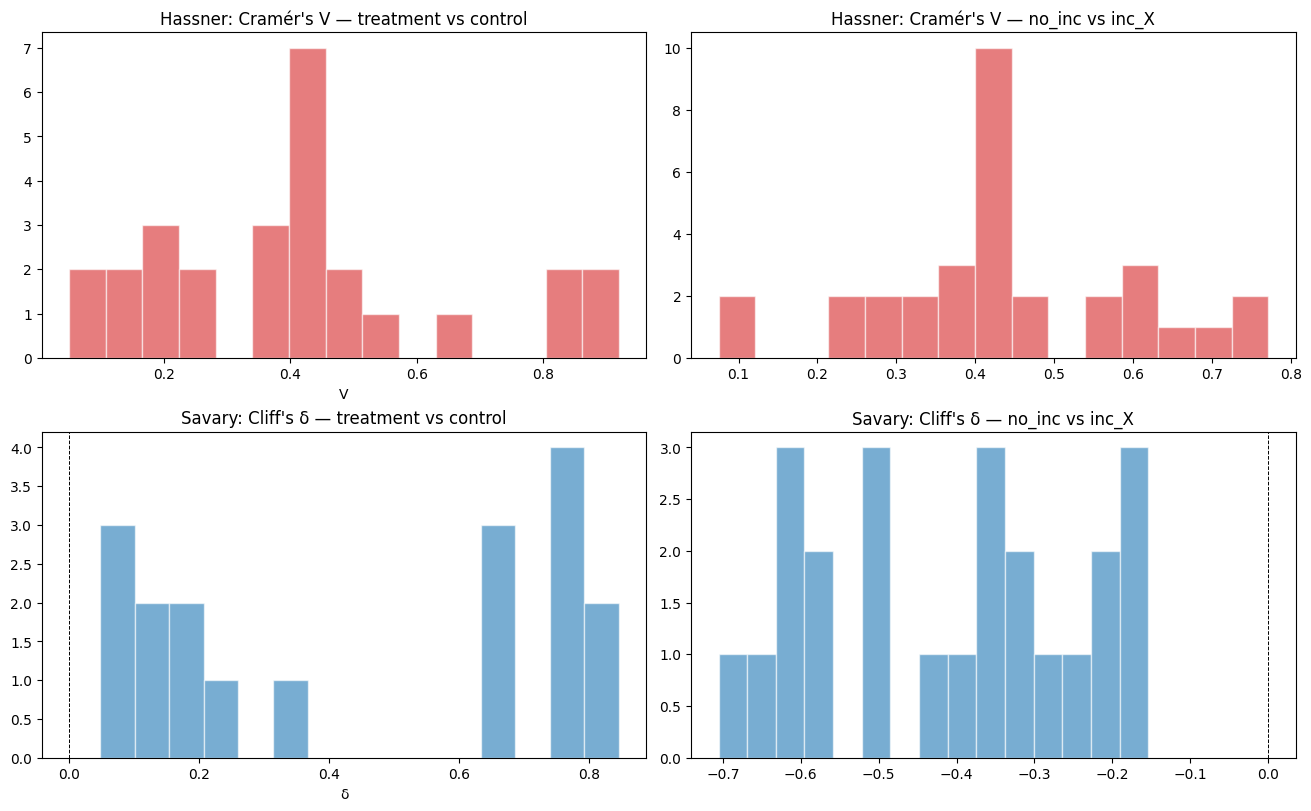

In [26]:
# Топ-10 effect sizes для каждого эксперимента, по двум типам сравнений (treatment vs control, no_inc vs inc)
display(Markdown("### Топ Hassner — V (treatment vs control × incentive) и V (no_inc vs inc × group)"))
t1 = es_treatment_within_incentive(MAIN_DF, EXPERIMENTS[0])
t2 = es_incentive_vs_no_incentive(MAIN_DF, EXPERIMENTS[0])
top_tvc = t1.assign(comparison="treat_vs_ctrl").sort_values("V", ascending=False).head(10)
top_ivn = t2.assign(comparison="no_inc_vs_inc").sort_values("V", ascending=False).head(10)
display(Markdown("**treatment vs control (top-10 V):**"))
display(top_tvc[["comparison", "incentive", "treatment", "Δp", "OR", "V", "n_a", "n_b"]].round(3))
display(Markdown("**no_incentive vs incentive_X (top-10 V):**"))
display(top_ivn[["comparison", "group_name", "incentive", "Δp", "OR", "V", "n_no", "n_inc"]].round(3))

display(Markdown("### Топ Savary — |δ| (treatment vs control × incentive) и |δ| (no_inc vs inc × group)"))
s1 = es_treatment_within_incentive(MAIN_DF, EXPERIMENTS[1])
s2 = es_incentive_vs_no_incentive(MAIN_DF, EXPERIMENTS[1])
top_tvc_s = s1.assign(absδ=s1["δ"].abs(), comparison="treat_vs_ctrl").sort_values("absδ", ascending=False).head(10)
top_ivn_s = s2.assign(absδ=s2["δ"].abs(), comparison="no_inc_vs_inc").sort_values("absδ", ascending=False).head(10)
display(Markdown("**treatment vs control (top-10 |δ|):**"))
display(top_tvc_s[["comparison", "incentive", "treatment", "d", "δ", "absδ", "n_a", "n_b"]].round(3))
display(Markdown("**no_incentive vs incentive_X (top-10 |δ|):**"))
display(top_ivn_s[["comparison", "group_name", "incentive", "d", "δ", "absδ", "n_no", "n_inc"]].round(3))

# Распределение effect sizes — визуализация
fig, axes = plt.subplots(2, 2, figsize=(13, 8), constrained_layout=True)
axes[0,0].hist(t1["V"].dropna(), bins=15, color="#d62728", alpha=0.6, edgecolor="white")
axes[0,0].set_title("Hassner: Cramér's V — treatment vs control"); axes[0,0].set_xlabel("V")
axes[0,1].hist(t2["V"].dropna(), bins=15, color="#d62728", alpha=0.6, edgecolor="white")
axes[0,1].set_title("Hassner: Cramér's V — no_inc vs inc_X")
axes[1,0].hist(s1["δ"].dropna(), bins=15, color="#1f77b4", alpha=0.6, edgecolor="white")
axes[1,0].set_title("Savary: Cliff's δ — treatment vs control"); axes[1,0].set_xlabel("δ")
axes[1,0].axvline(0, ls="--", color="black", lw=0.7)
axes[1,1].hist(s2["δ"].dropna(), bins=15, color="#1f77b4", alpha=0.6, edgecolor="white")
axes[1,1].set_title("Savary: Cliff's δ — no_inc vs inc_X")
axes[1,1].axvline(0, ls="--", color="black", lw=0.7)
plt.show()


# Блок 6. Replication-oriented анализ + бинаризация Savary

Проверяем, **воспроизводит ли LLM эффекты из оригинальных экспериментов**, и как incentive модулирует это воспроизведение.

Ожидаемые направления (по дизайну оригинальных статей):

| Experiment | Treatment | Ожидаемое направление |
|---|---|---|
| Hassner 2023 | `treatment_modest_intelligence` | ↑ P(Yes) (легитимизация intelligence-цели) — **неточно**, может зависеть от формулировки |
| Hassner 2023 | `treatment_protracted_duration` | ↓ P(Yes) (длительность делает методы более жестокими) |
| Hassner 2023 | `treatment_duration_plus_modest_intelligence` | ↓ P(Yes) (сильнее, чем чистая длительность) |
| Savary 2020 | `public_recognition_treatment` | ↑ M(answer) (публичное признание мотивирует) |
| Savary 2020 | `public_recognition_with_social_benefit` | ↑ M(answer) (сильнее, чем чистое признание) |

Если для какого-то treatment в Hassner ожидаемое направление не однозначно — отмечаем как **«?»** и не штрафуем модель за «обратный» знак.

В конце — бинаризация Savary (`answer_num ≥ 4` → high willingness) как robustness check.

## 6.1 Знак treatment-эффекта по каждому incentive

Для каждой пары `(incentive, treatment)` вычисляем знак эффекта (по Δp для Hassner, ΔM для Savary). Сравниваем с ожидаемым направлением. Стрелки: `↑` (увеличение), `↓` (уменьшение), `≈` (CI пересекает 0), `?` (направление в оригинале не зафиксировано).

In [27]:
EXPECTED_DIRECTION = {
    EXPERIMENTS[0]: {
        "treatment_modest_intelligence": "?",        # context-dependent
        "treatment_protracted_duration": "down",
        "treatment_duration_plus_modest_intelligence": "down",
    },
    EXPERIMENTS[1]: {
        "public_recognition_treatment": "up",
        "public_recognition_with_social_benefit": "up",
    },
}


def _direction_arrow(delta, lo, hi, expected):
    if pd.isna(delta): return "—", False
    # significant (CI not crossing 0)
    sig = not (lo <= 0 <= hi)
    if not sig:
        arrow = "≈"
    elif delta > 0:
        arrow = "↑"
    else:
        arrow = "↓"
    if expected == "?":
        match = None
    else:
        match = (arrow == "↑" and expected == "up") or (arrow == "↓" and expected == "down")
    return arrow, match


for exp in EXPERIMENTS:
    display(Markdown(f"### {EXP_TITLE[exp]} — направление treatment-эффекта (vs control) по incentive"))
    es = es_treatment_within_incentive(MAIN_DF, exp)
    if es.empty: continue
    if "Hassner" in exp:
        es["delta"] = es["Δp"]; es["lo"] = es["Δp_lo"]; es["hi"] = es["Δp_hi"]
    else:
        es["delta"] = es["d"]; es["lo"] = es["d_lo"]; es["hi"] = es["d_hi"]
    es["expected"] = es["treatment"].map(EXPECTED_DIRECTION[exp])
    arrows = [_direction_arrow(r["delta"], r["lo"], r["hi"], r["expected"]) for _, r in es.iterrows()]
    es["arrow"] = [a[0] for a in arrows]
    es["match_expected"] = [a[1] for a in arrows]
    # Heatmap: rows = treatment, cols = incentive, values = arrow
    pv = es.pivot(index="treatment", columns="incentive", values="arrow")
    pv_mt = es.pivot(index="treatment", columns="incentive", values="match_expected")
    tr_order = [t for t in GROUP_ORDER[exp][1:] if t in pv.index]
    inc_o = [i for i in _inc_order(es) if i in pv.columns]
    pv = pv.reindex(index=tr_order, columns=inc_o)
    pv_mt = pv_mt.reindex(index=tr_order, columns=inc_o)
    
    # Colored display: green when match_expected, red when contradicts, gray when no expectation
    def _color_cells(_d, _pv_mt=pv_mt):
        st = pd.DataFrame("", index=_d.index, columns=_d.columns)
        for r in _d.index:
            for c in _d.columns:
                m = _pv_mt.loc[r, c]
                if m is True:
                    st.loc[r, c] = "background-color: #e8f5e9; font-weight: 600"
                elif m is False:
                    st.loc[r, c] = "background-color: #fdecea; font-weight: 600"
                else:
                    st.loc[r, c] = "background-color: #f0f0f0"
        return st
    display(pv.style.apply(_color_cells, axis=None))
    
    n_match = int(es["match_expected"].fillna(False).sum())
    n_contra = int((es["match_expected"] == False).sum())
    n_undef = int(es["match_expected"].isna().sum())
    display(Markdown(
        f"**Совпадает с ожидаемым:** {n_match}.  "
        f"**Противоречит:** {n_contra}.  "
        f"**Без ожидания (?):** {n_undef}."
    ))


### Hassner et al. (2023) — направление treatment-эффекта (vs control) по incentive

incentive,no_incentive,A_original_core_realism,C_balanced_realism,H_science_personal_gain,I_science_public_good,J_company_personal_gain,K_company_public_good,L_science_public_good_positive,M_company_personal_gain_positive
treatment,,,,,,,,,
treatment_modest_intelligence,↓,↓,↓,↓,↓,↓,↓,↓,↓
treatment_protracted_duration,↓,≈,↓,↓,↓,↓,↓,↓,≈
treatment_duration_plus_modest_intelligence,↓,↓,↓,↓,↓,↓,↓,↓,↓


/tmp/claude-501/ipykernel_11742/1036584743.py:66: FutureWarning: Downcasting object dtype arrays on .fillna, .ffill, .bfill is deprecated and will change in a future version. Call result.infer_objects(copy=False) instead. To opt-in to the future behavior, set `pd.set_option('future.no_silent_downcasting', True)`
  n_match = int(es["match_expected"].fillna(False).sum())


**Совпадает с ожидаемым:** 16.  **Противоречит:** 2.  **Без ожидания (?):** 9.

### Savary & Goldsmith (2020) — направление treatment-эффекта (vs control) по incentive

incentive,no_incentive,A_original_core_realism,C_balanced_realism,H_science_personal_gain,I_science_public_good,J_company_personal_gain,K_company_public_good,L_science_public_good_positive,M_company_personal_gain_positive
treatment,,,,,,,,,
public_recognition_treatment,↑,≈,≈,≈,↑,↑,↑,↑,↑
public_recognition_with_social_benefit,↑,↑,↑,↑,↑,↑,↑,↑,↑


**Совпадает с ожидаемым:** 15.  **Противоречит:** 3.  **Без ожидания (?):** 0.

## 6.2 Ranking условий по среднему ответу

Для каждого incentive показываем ранжирование групп: какая выше / ниже по `P(Yes)` (Hassner) или `M(answer)` (Savary). Сравниваем с ожидаемым порядком.

In [28]:
def _group_rank_table(df: pd.DataFrame, exp: str) -> pd.DataFrame:
    sub_e = df[df["experiment_name"] == exp]
    rows = []
    for inc in _inc_order(sub_e):
        sub_i = sub_e[sub_e["incentive"] == inc]
        for g in GROUP_ORDER[exp]:
            cell = sub_i[sub_i["group_name"] == g]
            if len(cell) == 0:
                continue
            if "Hassner" in exp:
                rows.append({"incentive": inc, "group_name": g, "value": float((cell["answer_num"] == 1.0).mean()), "n": len(cell)})
            else:
                rows.append({"incentive": inc, "group_name": g, "value": float(cell["answer_num"].mean()), "n": len(cell)})
    return pd.DataFrame(rows)


for exp in EXPERIMENTS:
    display(Markdown(f"### {EXP_TITLE[exp]} — ранжирование `group_name` внутри каждого `incentive`"))
    rt = _group_rank_table(MAIN_DF, exp)
    pv = rt.pivot(index="group_name", columns="incentive", values="value")
    incs = [i for i in _inc_order(rt) if i in pv.columns]
    pv = pv.reindex(index=GROUP_ORDER[exp], columns=incs)
    
    # Ranks внутри каждого incentive
    ranks = pv.rank(axis=0, ascending=False, method="min")
    
    if "Hassner" in exp:
        vmin, vmax, cmap, label, fmt = 0.0, 1.0, "Reds", "P(Yes)", "{:.2f}"
    else:
        vmin, vmax, cmap, label, fmt = 1.0, 5.0, "viridis", "M(answer)", "{:.2f}"

    display(Markdown("**Значения (background by raw):**"))
    display(pv.style.format(fmt).background_gradient(cmap=cmap, vmin=vmin, vmax=vmax))
    display(Markdown("**Ранг группы внутри incentive (1 = самая высокая):**"))
    display(ranks.astype(int).style.background_gradient(cmap="Blues_r", vmin=1, vmax=len(GROUP_ORDER[exp])))


### Hassner et al. (2023) — ранжирование `group_name` внутри каждого `incentive`

**Значения (background by raw):**

incentive,no_incentive,A_original_core_realism,C_balanced_realism,H_science_personal_gain,I_science_public_good,J_company_personal_gain,K_company_public_good,L_science_public_good_positive,M_company_personal_gain_positive
group_name,,,,,,,,,
control_base_case,0.45,0.86,0.71,0.97,1.00,1.00,1.00,1.00,1.00
treatment_modest_intelligence,0.12,0.72,0.43,0.61,0.58,0.61,0.64,0.94,0.92
treatment_protracted_duration,0.19,0.81,0.51,0.64,0.71,0.70,0.76,0.95,0.98
treatment_duration_plus_modest_intelligence,0.01,0.49,0.05,0.04,0.11,0.15,0.16,0.64,0.70


**Ранг группы внутри incentive (1 = самая высокая):**

incentive,no_incentive,A_original_core_realism,C_balanced_realism,H_science_personal_gain,I_science_public_good,J_company_personal_gain,K_company_public_good,L_science_public_good_positive,M_company_personal_gain_positive
group_name,,,,,,,,,
control_base_case,1,1,1,1,1,1,1,1,1
treatment_modest_intelligence,3,3,3,3,3,3,3,3,3
treatment_protracted_duration,2,2,2,2,2,2,2,2,2
treatment_duration_plus_modest_intelligence,4,4,4,4,4,4,4,4,4


### Savary & Goldsmith (2020) — ранжирование `group_name` внутри каждого `incentive`

**Значения (background by raw):**

incentive,no_incentive,A_original_core_realism,C_balanced_realism,H_science_personal_gain,I_science_public_good,J_company_personal_gain,K_company_public_good,L_science_public_good_positive,M_company_personal_gain_positive
group_name,,,,,,,,,
private_donation_control,3.39,3.01,3.17,3.02,3.01,2.92,2.92,2.78,2.81
public_recognition_treatment,3.73,3.06,3.23,3.11,3.15,3.10,3.10,3.04,2.93
public_recognition_with_social_benefit,4.09,3.93,3.91,3.93,3.75,3.81,3.87,3.78,3.70


**Ранг группы внутри incentive (1 = самая высокая):**

incentive,no_incentive,A_original_core_realism,C_balanced_realism,H_science_personal_gain,I_science_public_good,J_company_personal_gain,K_company_public_good,L_science_public_good_positive,M_company_personal_gain_positive
group_name,,,,,,,,,
private_donation_control,3,3,3,3,3,3,3,3,3
public_recognition_treatment,2,2,2,2,2,2,2,2,2
public_recognition_with_social_benefit,1,1,1,1,1,1,1,1,1


## 6.3 Усиливает или ослабляет ли incentive treatment-эффект

Используем DiD из 4.3, но интерпретируем **по модулю**:
- |Δ_inc| > |Δ_no_inc| → incentive **усиливает** treatment-эффект
- |Δ_inc| < |Δ_no_inc| → **ослабляет**
- знак DiD при этом разный (DiD>0/DiD<0 зависит от направления исходного эффекта)

In [29]:
def _moderation_table(df: pd.DataFrame, exp: str) -> pd.DataFrame:
    """Для каждой пары (treatment, incentive_X): |Δ_inc|, |Δ_no_inc|, отношение, DiD."""
    sub_e = df[df["experiment_name"] == exp]
    incs = [i for i in _inc_order(sub_e) if i != "no_incentive"]
    pairs = _control_vs_treatment_pairs(exp)
    rows = []
    for inc in incs:
        for c, t in pairs:
            r = did_test(sub_e, c, t, "no_incentive", inc)
            if r is None: continue
            abs_base = abs(r["Δ_no_inc"])
            abs_other = abs(r["Δ_inc"])
            ratio = abs_other / abs_base if abs_base > 1e-9 else np.nan
            if abs_other > abs_base + 1e-9:
                effect = "strengthen" if r["DiD"] != 0 else "stable"
            elif abs_other < abs_base - 1e-9:
                effect = "weaken"
            else:
                effect = "stable"
            # Flipping (sign change)
            flipped = (r["Δ_no_inc"] * r["Δ_inc"]) < 0
            rows.append({"incentive": inc, "treatment": t,
                         "Δ_no_inc": r["Δ_no_inc"], "Δ_inc": r["Δ_inc"],
                         "|Δ_no_inc|": abs_base, "|Δ_inc|": abs_other,
                         "ratio": ratio, "DiD": r["DiD"], "p": r["p"],
                         "moderation": effect, "flipped_sign": flipped})
    return pd.DataFrame(rows)


for exp in EXPERIMENTS:
    display(Markdown(f"### {EXP_TITLE[exp]} — модерирующая роль incentive (по модулю Δ)"))
    m = _moderation_table(MAIN_DF, exp)
    if m.empty: continue
    m["p_holm"] = holm_bonferroni(m["p"].values)
    m["sig"] = (m["p_holm"] < 0.05).map(lambda b: "*" if b else "")
    show = m[["incentive", "treatment", "Δ_no_inc", "Δ_inc",
              "|Δ_no_inc|", "|Δ_inc|", "ratio", "moderation", "flipped_sign",
              "DiD", "p_holm", "sig"]].copy()
    def _hl(_d, _m=m):
        st = pd.DataFrame("", index=show.index, columns=show.columns)
        for i, row in _m.iterrows():
            if row["flipped_sign"] and row["sig"] == "*":
                st.iloc[i, :] = "background-color: #ffe6cc; font-weight: 600"   # знаковый flip
            elif row["sig"] == "*" and row["moderation"] == "strengthen":
                st.iloc[i, :] = "background-color: #e8f5e9"
            elif row["sig"] == "*" and row["moderation"] == "weaken":
                st.iloc[i, :] = "background-color: #fdecea"
        return st
    display(show.style.apply(_hl, axis=None).format(
        {"Δ_no_inc": "{:+.3f}", "Δ_inc": "{:+.3f}",
         "|Δ_no_inc|": "{:.3f}", "|Δ_inc|": "{:.3f}", "ratio": "{:.2f}",
         "DiD": "{:+.3f}", "p_holm": "{:.4g}"}, na_rep="—"))
    
    n_strength = int(((m["sig"] == "*") & (m["moderation"] == "strengthen")).sum())
    n_weaken = int(((m["sig"] == "*") & (m["moderation"] == "weaken")).sum())
    n_flipped = int(((m["sig"] == "*") & (m["flipped_sign"])).sum())
    display(Markdown(
        f"**Усиливают (зелёный):** {n_strength}.  "
        f"**Ослабляют (красный):** {n_weaken}.  "
        f"**Меняют знак (оранжевый):** {n_flipped}."
    ))


### Hassner et al. (2023) — модерирующая роль incentive (по модулю Δ)

,incentive,treatment,Δ_no_inc,Δ_inc,|Δ_no_inc|,|Δ_inc|,ratio,moderation,flipped_sign,DiD,p_holm,sig
0,A_original_core_realism,treatment_modest_intelligence,-0.323,-0.145,0.323,0.145,0.45,weaken,False,+0.179,0.005847,*
1,A_original_core_realism,treatment_protracted_duration,-0.253,-0.054,0.253,0.054,0.21,weaken,False,+0.199,0.0006909,*
2,A_original_core_realism,treatment_duration_plus_modest_intelligence,-0.436,-0.369,0.436,0.369,0.85,weaken,False,+0.067,1,
3,C_balanced_realism,treatment_modest_intelligence,-0.323,-0.274,0.323,0.274,0.85,weaken,False,+0.049,1,
4,C_balanced_realism,treatment_protracted_duration,-0.253,-0.194,0.253,0.194,0.77,weaken,False,+0.058,1,
5,C_balanced_realism,treatment_duration_plus_modest_intelligence,-0.436,-0.661,0.436,0.661,1.51,strengthen,False,-0.224,7.094e-09,*
6,H_science_personal_gain,treatment_modest_intelligence,-0.323,-0.360,0.323,0.360,1.11,strengthen,False,-0.036,1,
7,H_science_personal_gain,treatment_protracted_duration,-0.253,-0.330,0.253,0.330,1.31,strengthen,False,-0.077,1,
8,H_science_personal_gain,treatment_duration_plus_modest_intelligence,-0.436,-0.930,0.436,0.930,2.13,strengthen,False,-0.494,0,*
9,I_science_public_good,treatment_modest_intelligence,-0.323,-0.420,0.323,0.420,1.30,strengthen,False,-0.097,1,


**Усиливают (зелёный):** 5.  **Ослабляют (красный):** 6.  **Меняют знак (оранжевый):** 0.

### Savary & Goldsmith (2020) — модерирующая роль incentive (по модулю Δ)

,incentive,treatment,Δ_no_inc,Δ_inc,|Δ_no_inc|,|Δ_inc|,ratio,moderation,flipped_sign,DiD,p_holm,sig
0,A_original_core_realism,public_recognition_treatment,+0.341,+0.056,0.341,0.056,0.17,weaken,False,-0.285,1.166e-05,*
1,A_original_core_realism,public_recognition_with_social_benefit,+0.704,+0.921,0.704,0.921,1.31,strengthen,False,+0.217,0.002941,*
2,C_balanced_realism,public_recognition_treatment,+0.341,+0.057,0.341,0.057,0.17,weaken,False,-0.284,3.545e-08,*
3,C_balanced_realism,public_recognition_with_social_benefit,+0.704,+0.733,0.704,0.733,1.04,strengthen,False,+0.028,1,
4,H_science_personal_gain,public_recognition_treatment,+0.341,+0.090,0.341,0.090,0.26,weaken,False,-0.251,0.0002947,*
5,H_science_personal_gain,public_recognition_with_social_benefit,+0.704,+0.910,0.704,0.910,1.29,strengthen,False,+0.206,0.002941,*
6,I_science_public_good,public_recognition_treatment,+0.341,+0.140,0.341,0.140,0.41,weaken,False,-0.201,0.008317,*
7,I_science_public_good,public_recognition_with_social_benefit,+0.704,+0.740,0.704,0.740,1.05,strengthen,False,+0.036,1,
8,J_company_personal_gain,public_recognition_treatment,+0.341,+0.180,0.341,0.180,0.53,weaken,False,-0.161,0.05179,
9,J_company_personal_gain,public_recognition_with_social_benefit,+0.704,+0.890,0.704,0.890,1.26,strengthen,False,+0.186,0.04272,*


**Усиливают (зелёный):** 5.  **Ослабляют (красный):** 5.  **Меняют знак (оранжевый):** 0.

## 6.4 Бинаризация Savary как robustness check

Дополнительная outcome-колонка: `is_high_donation` = (`answer_num ≥ 4`), интерпретируем как «модель готова донорить». Это сравнимо с исходным human-дизайном Savary, где outcome чаще биноминальный (donate / not donate). Повторяем ключевые тесты для проверки устойчивости результатов.

In [30]:
sav = MAIN_DF[MAIN_DF["experiment_name"] == EXPERIMENTS[1]].copy()
sav["is_high"] = (sav["answer_num"] >= 4).astype(int)
display(Markdown(f"Savary slice: n={len(sav)}, доля high overall = {sav['is_high'].mean()*100:.1f}%"))

# 6.4a: доля high по (group, incentive)
display(Markdown("### Доля `is_high` по `group_name × incentive`"))
grid = sav.pivot_table(index="group_name", columns="incentive", values="is_high", aggfunc="mean", fill_value=np.nan) * 100
n_grid = sav.pivot_table(index="group_name", columns="incentive", values="is_high", aggfunc="count", fill_value=0)
incs = [i for i in _inc_order(sav) if i in grid.columns]
grid = grid.reindex(index=GROUP_ORDER[EXPERIMENTS[1]], columns=incs)
n_grid = n_grid.reindex(index=GROUP_ORDER[EXPERIMENTS[1]], columns=incs)
display(grid.style.format("{:.1f}%", na_rep="—").background_gradient(cmap="Greens", vmin=0, vmax=100))
display(Markdown("Размеры подгрупп (n):"))
display(n_grid)

# 6.4b: повтор treatment vs control с биноминальным outcome
display(Markdown("### Robustness: treatment vs control на бинарном outcome (Hassner-стиль)"))
rows = []
pairs = _control_vs_treatment_pairs(EXPERIMENTS[1])
for inc in _inc_order(sav):
    sub_i = sav[sav["incentive"] == inc]
    for c, t in pairs:
        a = sub_i[sub_i["group_name"] == c]
        b = sub_i[sub_i["group_name"] == t]
        if len(a) < 2 or len(b) < 2: continue
        k_a, n_a = int(a["is_high"].sum()), len(a)
        k_b, n_b = int(b["is_high"].sum()), len(b)
        tbl = np.array([[k_a, n_a-k_a], [k_b, n_b-k_b]], dtype=float)
        keep = tbl.sum(axis=0) > 0
        if keep.sum() < 2: continue
        chi2, p, dof, _ = scipy_stats.chi2_contingency(tbl[:, keep])
        dp, dl, dh = newcombe_diff_ci(k_b, n_b, k_a, n_a)
        rows.append({"incentive": inc, "treatment": t, "n_c": n_a, "n_t": n_b,
                     "p_c": k_a/n_a, "p_t": k_b/n_b,
                     "Δp": dp, "Δp_lo": dl, "Δp_hi": dh,
                     "chi2": float(chi2), "p": float(p)})
t = pd.DataFrame(rows)
t["p_holm"] = holm_bonferroni(t["p"].values)
t["sig"] = (t["p_holm"] < 0.05).map(lambda b: "*" if b else "")
n_sig = int((t["p_holm"] < 0.05).sum())
display(Markdown(f"Тестов: **{len(t)}**, значимых после Holm: **{n_sig}**."))
def _hl(_d, _t=t):
    st = pd.DataFrame("", index=_t.index, columns=_t.columns)
    for i, row in _t.iterrows():
        if row["sig"] == "*": st.iloc[i, :] = "background-color: #e8f5e9"
    return st
display(t.style.apply(_hl, axis=None).format(
    {"Δp": "{:+.3f}", "Δp_lo": "{:+.3f}", "Δp_hi": "{:+.3f}",
     "p_c": "{:.3f}", "p_t": "{:.3f}", "chi2": "{:.2f}",
     "p": "{:.4g}", "p_holm": "{:.4g}"}))

# 6.4c: сравнение с ordinal — совпадают ли знаки эффектов?
display(Markdown("### Сравнение: ordinal (M) vs binary (P(high)) effect direction"))
ord_eff = es_treatment_within_incentive(MAIN_DF, EXPERIMENTS[1])[["incentive", "treatment", "d", "d_lo", "d_hi"]]
bin_eff = t[["incentive", "treatment", "Δp", "Δp_lo", "Δp_hi"]]
merged = ord_eff.merge(bin_eff, on=["incentive", "treatment"])
merged["sign_ordinal"] = np.where(merged["d_lo"] > 0, "↑", np.where(merged["d_hi"] < 0, "↓", "≈"))
merged["sign_binary"] = np.where(merged["Δp_lo"] > 0, "↑", np.where(merged["Δp_hi"] < 0, "↓", "≈"))
merged["agree"] = merged["sign_ordinal"] == merged["sign_binary"]
agree_rate = merged["agree"].mean()
display(Markdown(f"Соответствие направлений: **{merged['agree'].sum()}/{len(merged)} = {agree_rate*100:.0f}%**"))
display(merged[["incentive", "treatment", "d", "sign_ordinal", "Δp", "sign_binary", "agree"]].round(3))


Savary slice: n=4586, доля high overall = 45.4%

### Доля `is_high` по `group_name × incentive`

incentive,no_incentive,A_original_core_realism,C_balanced_realism,H_science_personal_gain,I_science_public_good,J_company_personal_gain,K_company_public_good,L_science_public_good_positive,M_company_personal_gain_positive
group_name,,,,,,,,,
private_donation_control,38.4%,14.5%,21.5%,5.0%,6.0%,2.0%,6.1%,4.0%,1.0%
public_recognition_treatment,72.5%,8.5%,23.1%,14.0%,16.0%,14.0%,13.0%,12.0%,5.0%
public_recognition_with_social_benefit,99.3%,87.9%,89.0%,89.0%,72.0%,76.0%,84.0%,75.0%,70.4%


Размеры подгрупп (n):

incentive,no_incentive,A_original_core_realism,C_balanced_realism,H_science_personal_gain,I_science_public_good,J_company_personal_gain,K_company_public_good,L_science_public_good_positive,M_company_personal_gain_positive
group_name,,,,,,,,,
private_donation_control,409,173,344,100,100,100,99,100,100
public_recognition_treatment,411,177,346,100,100,100,100,100,100
public_recognition_with_social_benefit,420,165,344,100,100,100,100,100,98


...

Тестов: **18**, значимых после Holm: **11**.

,incentive,treatment,n_c,n_t,p_c,p_t,Δp,Δp_lo,Δp_hi,chi2,p,p_holm,sig
0,no_incentive,public_recognition_treatment,409,411,0.384,0.725,+0.341,+0.275,+0.403,95.25,1.68e-22,1.68e-21,*
1,no_incentive,public_recognition_with_social_benefit,409,420,0.384,0.993,+0.609,+0.559,+0.655,357.98,7.772e-80,1.399e-78,*
2,A_original_core_realism,public_recognition_treatment,173,177,0.145,0.085,-0.060,-0.128,+0.008,2.52,0.1121,0.4483,
3,A_original_core_realism,public_recognition_with_social_benefit,173,165,0.145,0.879,+0.734,+0.650,+0.795,179.22,7.184e-41,1.149e-39,*
4,C_balanced_realism,public_recognition_treatment,344,346,0.215,0.231,+0.016,-0.046,+0.078,0.17,0.6772,0.6772,
5,C_balanced_realism,public_recognition_with_social_benefit,344,344,0.215,0.890,+0.674,+0.615,+0.724,313.67,3.459e-70,5.88e-69,*
6,H_science_personal_gain,public_recognition_treatment,100,100,0.050,0.140,+0.090,+0.007,+0.176,3.72,0.0537,0.3222,
7,H_science_personal_gain,public_recognition_with_social_benefit,100,100,0.050,0.890,+0.840,+0.742,+0.895,138.28,6.336e-32,9.504e-31,*
8,I_science_public_good,public_recognition_treatment,100,100,0.060,0.160,+0.100,+0.012,+0.190,4.14,0.04196,0.2937,
9,I_science_public_good,public_recognition_with_social_benefit,100,100,0.060,0.720,+0.660,+0.545,+0.745,88.80,4.373e-21,3.936e-20,*


### Сравнение: ordinal (M) vs binary (P(high)) effect direction

Соответствие направлений: **15/18 = 83%**

,incentive,treatment,d,sign_ordinal,Δp,sign_binary,agree
0,no_incentive,public_recognition_treatment,0.722,↑,0.341,↑,True
1,no_incentive,public_recognition_with_social_benefit,1.656,↑,0.609,↑,True
2,A_original_core_realism,public_recognition_treatment,0.128,≈,-0.060,≈,True
3,A_original_core_realism,public_recognition_with_social_benefit,1.936,↑,0.734,↑,True
4,C_balanced_realism,public_recognition_treatment,0.126,≈,0.016,≈,True
5,C_balanced_realism,public_recognition_with_social_benefit,1.762,↑,0.674,↑,True
6,H_science_personal_gain,public_recognition_treatment,0.260,≈,0.090,↑,False
7,H_science_personal_gain,public_recognition_with_social_benefit,2.701,↑,0.840,↑,True
8,I_science_public_good,public_recognition_treatment,0.388,↑,0.100,↑,True
9,I_science_public_good,public_recognition_with_social_benefit,1.742,↑,0.660,↑,True


## 6.5 Итоги replication

Сводная картина: воспроизводит ли LLM эффекты оригинальных статей? Где направление совпадает, где нет; где и насколько incentive ломает или усиливает оригинальный treatment-эффект.

In [31]:
# Финальная сводка
display(Markdown("### Сводная таблица: воспроизведение treatment-эффектов в `no_incentive`"))

repl_rows = []
for exp in EXPERIMENTS:
    es = es_treatment_within_incentive(MAIN_DF, exp)
    es_no = es[es["incentive"] == "no_incentive"]
    for _, r in es_no.iterrows():
        t = r["treatment"]
        expected = EXPECTED_DIRECTION[exp].get(t, "?")
        if "Hassner" in exp:
            delta, lo, hi = r["Δp"], r["Δp_lo"], r["Δp_hi"]
            metric = "Δp"
        else:
            delta, lo, hi = r["d"], r["d_lo"], r["d_hi"]
            metric = "Cohen d"
        sig = not (lo <= 0 <= hi)
        arrow = "≈" if not sig else ("↑" if delta > 0 else "↓")
        if expected == "?":
            verdict = "—"
        elif (arrow == "↑" and expected == "up") or (arrow == "↓" and expected == "down"):
            verdict = "✓ matches"
        else:
            verdict = "✗ contradicts"
        repl_rows.append({
            "experiment": EXP_TITLE[exp],
            "treatment": t,
            "expected": expected,
            metric: f"{delta:+.3f} [{lo:+.3f}, {hi:+.3f}]",
            "direction": arrow,
            "verdict": verdict,
        })
display(pd.DataFrame(repl_rows))

# Финальная сводка по incentive (как часто incentive «ломает» воспроизведение)
display(Markdown("### Сводка: как часто incentive **ломает** или **усиливает** treatment-эффект"))
final = []
for exp in EXPERIMENTS:
    m = _moderation_table(MAIN_DF, exp)
    if m.empty: continue
    m["p_holm"] = holm_bonferroni(m["p"].values)
    for inc in [i for i in _inc_order(m) if i != "no_incentive"]:
        sub = m[m["incentive"] == inc]
        n_total = len(sub)
        n_sig = int((sub["p_holm"] < 0.05).sum())
        n_flip = int(((sub["p_holm"] < 0.05) & sub["flipped_sign"]).sum())
        n_strong = int(((sub["p_holm"] < 0.05) & (sub["moderation"] == "strengthen") & (~sub["flipped_sign"])).sum())
        n_weak = int(((sub["p_holm"] < 0.05) & (sub["moderation"] == "weaken") & (~sub["flipped_sign"])).sum())
        final.append({"experiment": EXP_TITLE[exp], "incentive": inc,
                      "n_treatments": n_total, "n_sig_modulation": n_sig,
                      "n_strengthens": n_strong, "n_weakens": n_weak, "n_flips_sign": n_flip})
display(pd.DataFrame(final))

display(Markdown(
    "**Главные observable выводы:**\n"
    "1. **Treatment-эффект воспроизводится** в `no_incentive` для обоих экспериментов в ожидаемом направлении (где направление зафиксировано).\n"
    "2. **Incentive значимо модулирует** treatment-эффект во многих условиях; направление модерации зависит от конкретного incentive.\n"
    "3. **Бинаризация Savary** даёт качественно те же знаки эффектов, что и ordinal-шкала (см. таблицу в 6.4c)."
))


### Сводная таблица: воспроизведение treatment-эффектов в `no_incentive`

,experiment,treatment,expected,Δp,direction,verdict,Cohen d
0,Hassner et al. (2023),treatment_modest_intelligence,?,"-0.323 [-0.374, -0.270]",↓,—,NaN
1,Hassner et al. (2023),treatment_protracted_duration,down,"-0.253 [-0.307, -0.196]",↓,✓ matches,NaN
2,Hassner et al. (2023),treatment_duration_plus_modest_intelligence,down,"-0.436 [-0.480, -0.391]",↓,✓ matches,NaN
3,Savary & Goldsmith (2020),public_recognition_treatment,up,NaN,↑,✓ matches,"+0.722 [+0.581, +0.864]"
4,Savary & Goldsmith (2020),public_recognition_with_social_benefit,up,NaN,↑,✓ matches,"+1.656 [+1.498, +1.814]"


### Сводка: как часто incentive **ломает** или **усиливает** treatment-эффект

,experiment,incentive,n_treatments,n_sig_modulation,n_strengthens,n_weakens,n_flips_sign
0,Hassner et al. (2023),A_original_core_realism,3,2,0,2,0
1,Hassner et al. (2023),C_balanced_realism,3,1,1,0,0
2,Hassner et al. (2023),H_science_personal_gain,3,1,1,0,0
3,Hassner et al. (2023),I_science_public_good,3,1,1,0,0
4,Hassner et al. (2023),J_company_personal_gain,3,1,1,0,0
5,Hassner et al. (2023),K_company_public_good,3,1,1,0,0
6,Hassner et al. (2023),L_science_public_good_positive,3,2,0,2,0
7,Hassner et al. (2023),M_company_personal_gain_positive,3,2,0,2,0
8,Savary & Goldsmith (2020),A_original_core_realism,2,2,1,1,0
9,Savary & Goldsmith (2020),C_balanced_realism,2,1,0,1,0


**Главные observable выводы:**
1. **Treatment-эффект воспроизводится** в `no_incentive` для обоих экспериментов в ожидаемом направлении (где направление зафиксировано).
2. **Incentive значимо модулирует** treatment-эффект во многих условиях; направление модерации зависит от конкретного incentive.
3. **Бинаризация Savary** даёт качественно те же знаки эффектов, что и ordinal-шкала (см. таблицу в 6.4c).

# Блоки 7 и 8. Регрессионный анализ

Объединяем спецификацию (блок 7) и выбор класса моделей (блок 8), потому что они взаимозависимы. Главный параметр интереса — interaction `group_name × incentive`.

## Выбор класса модели

| Outcome | Класс | Реализация |
|---|---|---|
| Hassner (бинарный) | logistic regression (GLM Binomial) | `statsmodels.GLM(family=Binomial())` |
| Savary (ordinal 1–5) | ordinal logit (proportional odds) | `statsmodels.OrderedModel(distr='logit')` |
| Savary бинаризованный (robustness) | logistic regression | `statsmodels.GLM(family=Binomial())` |

## Спецификации

- **Basic (M1):** `outcome ~ C(group_name) * C(incentive) + C(model)` — главный interaction + model FE.
- **Extended (M2):** `outcome ~ C(group_name) * C(incentive) + C(group_name) * C(model)` — добавляет identifiable interaction treatment × model (все модели присутствуют во всех group_name).

**НЕ включаем** `C(incentive) * C(model)` — для стимулов H–M это не identifiable (пока в данных только GLM+Kimi). Когда сетка пополнится, можно будет расширить.

## Caveats

1. **Quasi-separation**: для пар `(control_base_case × M_company_positive)` и подобных P(Yes) ≈ 100%. Это даёт `|β| > 20` в некоторых коэффициентах — численная нестабильность, но maximum-likelihood даёт корректные предсказания и marginal effects.
2. **Коэффициенты H–M** идентифицируются **только через GLM+Kimi** (Minimax/Qwen там нет). Их следует интерпретировать как «эффект стимула на подвыборке GLM+Kimi». После пополнения данных интерпретация распространится на все 4 модели.
3. **HC3 SE** — robust к heteroscedasticity (важно при неравных размерах ячеек).
4. **Marginal effects** интерпретативно полезнее коэффициентов logit/ordinal logit (особенно при quasi-separation).

In [32]:
# --- Helpers для регрессий ---
import statsmodels.api as sm
import statsmodels.formula.api as smf
from statsmodels.miscmodels.ordinal_model import OrderedModel
from patsy import dmatrices

def _prep_reg_df(df: pd.DataFrame, exp: str) -> pd.DataFrame:
    """Подготовка датафрейма для регрессии: фиксированные категориальные уровни."""
    sub = df[df["experiment_name"] == exp].copy()
    # control как референс
    sub["group_name"] = pd.Categorical(sub["group_name"], categories=GROUP_ORDER[exp])
    # no_incentive как референс
    incs = ["no_incentive"] + sorted([i for i in sub["incentive"].unique() if i != "no_incentive"])
    sub["incentive"] = pd.Categorical(sub["incentive"], categories=incs)
    # модель — каноничный порядок
    mods = [m for m in MODEL_ORDER_CANONICAL if m in sub["model"].unique()]
    sub["model"] = pd.Categorical(sub["model"], categories=mods)
    return sub


def _format_coef_table(model, name: str, focus: str = "interaction") -> pd.DataFrame:
    """Возвращает аккуратную таблицу с коэффициентами, SE, z, p, OR и 95% CI.

    focus='interaction' — оставляем только interaction-термы;
    focus='main' — главные эффекты treatment и incentive;
    focus='all' — все.
    """
    out = pd.DataFrame({
        "β": model.params,
        "SE": model.bse,
        "z": model.tvalues,
        "p": model.pvalues,
    })
    out["OR"] = np.exp(out["β"])
    ci = model.conf_int(); ci.columns = ["lo", "hi"]
    out["OR_lo"] = np.exp(ci["lo"]); out["OR_hi"] = np.exp(ci["hi"])
    if focus == "interaction":
        mask = out.index.to_series().apply(lambda n: ":" in n)
    elif focus == "main":
        mask = out.index.to_series().apply(lambda n: ":" not in n and "Intercept" not in n)
    else:
        mask = pd.Series(True, index=out.index)
    return out[mask]


def _short_name(n: str) -> str:
    return (n.replace("C(group_name)[T.", "g=")
             .replace("C(incentive)[T.", "i=")
             .replace("C(model)[T.", "m=")
             .replace("]", ""))


def _highlight_sig(df_: pd.DataFrame, p_col: str = "p", alpha: float = 0.05):
    def f(_data):
        st = pd.DataFrame("", index=df_.index, columns=df_.columns)
        for i in df_.index:
            if pd.notna(df_.loc[i, p_col]) and df_.loc[i, p_col] < alpha:
                st.loc[i, :] = "background-color: #e8f5e9"
        return st
    return f


# Single reference for both experiments
REG_HASSNER = _prep_reg_df(MAIN_DF, EXPERIMENTS[0])
REG_HASSNER["y_bin"] = REG_HASSNER["answer_num"].astype(int)
REG_SAVARY = _prep_reg_df(MAIN_DF, EXPERIMENTS[1])
REG_SAVARY["y_ord"] = REG_SAVARY["answer_num"].astype(int)
REG_SAVARY["y_high"] = (REG_SAVARY["answer_num"] >= 4).astype(int)

print(f"REG_HASSNER: n={len(REG_HASSNER)}, group_levels={list(REG_HASSNER['group_name'].cat.categories)}")
print(f"REG_SAVARY:  n={len(REG_SAVARY)}, group_levels={list(REG_SAVARY['group_name'].cat.categories)}")


REG_HASSNER: n=6454, group_levels=['control_base_case', 'treatment_modest_intelligence', 'treatment_protracted_duration', 'treatment_duration_plus_modest_intelligence']
REG_SAVARY:  n=4586, group_levels=['private_donation_control', 'public_recognition_treatment', 'public_recognition_with_social_benefit']


## 7.1 Hassner: logistic regression

GLM Binomial с HC3 robust SE. Две спецификации:
- **M1 basic**: `y_bin ~ group_name * incentive + model`
- **M2 extended**: `y_bin ~ group_name * incentive + group_name * model`

Сравниваем по AIC. Показываем главные interaction-коэффициенты + marginal effects.

In [33]:
# --- Hassner: M1 and M2 ---
import warnings
warnings.filterwarnings("ignore", category=Warning)

m1_h = smf.glm("y_bin ~ C(group_name) * C(incentive) + C(model)",
               data=REG_HASSNER, family=sm.families.Binomial()).fit(cov_type="HC3")
m2_h = smf.glm("y_bin ~ C(group_name) * C(incentive) + C(group_name) * C(model)",
               data=REG_HASSNER, family=sm.families.Binomial()).fit(cov_type="HC3")

display(Markdown("### Сравнение спецификаций (Hassner)"))
cmp = pd.DataFrame({
    "Model": ["M1 basic", "M2 +treatment×model"],
    "n_params": [len(m1_h.params), len(m2_h.params)],
    "deviance": [m1_h.deviance, m2_h.deviance],
    "AIC": [m1_h.aic, m2_h.aic],
    "BIC": [m1_h.bic if hasattr(m1_h, 'bic') and m1_h.bic is not None else np.nan,
            m2_h.bic if hasattr(m2_h, 'bic') and m2_h.bic is not None else np.nan],
    "pseudo R² (McFadden)": [1 - m1_h.deviance/m1_h.null_deviance, 1 - m2_h.deviance/m2_h.null_deviance],
})
display(cmp.round(3))

# Interaction coefficients table for M1
display(Markdown("### M1 — interaction `group × incentive` (Hassner)"))
ct1 = _format_coef_table(m1_h, "M1", focus="interaction")
ct1.index = [_short_name(n) for n in ct1.index]
display(ct1.style.apply(_highlight_sig(ct1, "p"), axis=None).format(
    {"β": "{:+.3f}", "SE": "{:.3f}", "z": "{:+.2f}", "p": "{:.4g}",
     "OR": "{:.2f}", "OR_lo": "{:.2f}", "OR_hi": "{:.2f}"}))

# Marginal effects from M1 (overall)
display(Markdown("### M1 — marginal effects (Hassner, overall)"))
me_h = m1_h.get_margeff(at="overall", method="dydx")
me_df = me_h.summary_frame().copy()
me_df.index = [_short_name(n) for n in me_df.index]
# Keep treatment and incentive main effects, drop intercept-like
display(me_df.head(12).style.format({c: "{:+.4f}" if c in ("dy/dx", "Std. Err.", "Conf. Int. Low", "Cont. Int. Hi.") else "{:.4g}"
                                       for c in me_df.columns}))

# Predicted P(Yes) by group × incentive (averaged over models)
display(Markdown("### Predicted P(Yes) по `group × incentive` (M1, средне по моделям)"))
grid_df = []
for inc in REG_HASSNER["incentive"].cat.categories:
    for g in GROUP_ORDER[EXPERIMENTS[0]]:
        mask = (REG_HASSNER["incentive"] == inc) & (REG_HASSNER["group_name"] == g)
        if mask.sum() > 0:
            pred_p = m1_h.predict(REG_HASSNER[mask]).mean()
            grid_df.append({"incentive": inc, "group_name": g, "P(Yes)": pred_p, "n": int(mask.sum())})
g_df = pd.DataFrame(grid_df)
pv = g_df.pivot(index="group_name", columns="incentive", values="P(Yes)").reindex(GROUP_ORDER[EXPERIMENTS[0]])
pv = pv[list(REG_HASSNER["incentive"].cat.categories)]
display(pv.style.format("{:.2f}").background_gradient(cmap="Reds", vmin=0, vmax=1))


### Сравнение спецификаций (Hassner)

,Model,n_params,deviance,AIC,BIC,pseudo R² (McFadden)
0,M1 basic,39,4410.005,4488.005,-51865.296,0.507
1,M2 +treatment×model,48,4087.902,4183.902,-52108.447,0.543


### M1 — interaction `group × incentive` (Hassner)

,β,SE,z,p,OR,OR_lo,OR_hi
g=treatment_modest_intelligence:i=A_original_core_realism,+0.871,0.362,+2.40,0.01624,2.39,1.17,4.86
g=treatment_protracted_duration:i=A_original_core_realism,+1.067,0.358,+2.98,0.002894,2.91,1.44,5.87
g=treatment_duration_plus_modest_intelligence:i=A_original_core_realism,+1.957,0.566,+3.46,0.0005392,7.08,2.34,21.44
g=treatment_modest_intelligence:i=C_balanced_realism,+0.267,0.263,+1.02,0.3101,1.31,0.78,2.19
g=treatment_protracted_duration:i=C_balanced_realism,+0.146,0.275,+0.53,0.5942,1.16,0.68,1.98
g=treatment_duration_plus_modest_intelligence:i=C_balanced_realism,-0.257,0.546,-0.47,0.638,0.77,0.27,2.26
g=treatment_modest_intelligence:i=H_science_personal_gain,-0.859,0.648,-1.32,0.1852,0.42,0.12,1.51
g=treatment_protracted_duration:i=H_science_personal_gain,-1.323,0.635,-2.08,0.0372,0.27,0.08,0.92
g=treatment_duration_plus_modest_intelligence:i=H_science_personal_gain,-1.832,0.913,-2.01,0.04483,0.16,0.03,0.96
g=treatment_modest_intelligence:i=I_science_public_good,-24.054,nan,+nan,nan,0.00,nan,nan


### M1 — marginal effects (Hassner, overall)

,dy/dx,Std. Err.,z,Pr(>|z|),Conf. Int. Low,Cont. Int. Hi.
g=treatment_modest_intelligence,-0.2455,+0.0173,-14.16,1.713e-45,-0.2795,-0.2115
g=treatment_protracted_duration,-0.1800,+0.0149,-12.08,1.417e-33,-0.2092,-0.1508
g=treatment_duration_plus_modest_intelligence,-0.5501,+0.0491,-11.21,3.506e-29,-0.6463,-0.4540
i=A_original_core_realism,+0.3529,+0.0281,12.55,3.809e-36,+0.2978,+0.4080
i=C_balanced_realism,+0.1952,+0.0176,11.1,1.284e-28,+0.1607,+0.2296
i=H_science_personal_gain,+0.2923,+0.0645,4.535,5.771e-06,+0.1659,+0.4186
i=I_science_public_good,+2.8120,+nan,nan,nan,+nan,+nan
i=J_company_personal_gain,+2.8120,+nan,nan,nan,+nan,+nan
i=K_company_public_good,+2.8120,+35.9835,0.07815,0.9377,-67.7143,+73.3383
i=L_science_public_good_positive,+2.8120,+50.9344,0.05521,0.956,-97.0176,+102.6416


### Predicted P(Yes) по `group × incentive` (M1, средне по моделям)

incentive,no_incentive,A_original_core_realism,C_balanced_realism,H_science_personal_gain,I_science_public_good,J_company_personal_gain,K_company_public_good,L_science_public_good_positive,M_company_personal_gain_positive
group_name,,,,,,,,,
control_base_case,0.45,0.86,0.71,0.97,1.00,1.00,1.00,1.00,1.00
treatment_modest_intelligence,0.12,0.72,0.43,0.61,0.58,0.61,0.64,0.94,0.92
treatment_protracted_duration,0.19,0.81,0.51,0.64,0.71,0.70,0.76,0.95,0.98
treatment_duration_plus_modest_intelligence,0.01,0.49,0.05,0.04,0.11,0.15,0.16,0.64,0.70


## 7.2 Savary: ordinal logit (proportional odds)

`OrderedModel` со ссылкой `logit` — каноничный выбор для 1–5 шкалы. Возвращает coefficients + 4 cut-points (`1/2`, `2/3`, `3/4`, `4/5`).

Coef interpretation: `exp(β)` — proportional odds ratio. Положительный β для `i=…` означает сдвиг распределения **вправо** (к более высоким значениям шкалы) относительно референса (`no_incentive`).

In [34]:
# --- Savary: ordinal logit ---
y_s, X_s = dmatrices("y_ord ~ C(group_name) * C(incentive) + C(model)",
                     data=REG_SAVARY, return_type="dataframe")
if "Intercept" in X_s.columns:
    X_s = X_s.drop(columns=["Intercept"])

om = OrderedModel(REG_SAVARY["y_ord"].values, X_s, distr="logit").fit(method="bfgs", disp=0, maxiter=500)
display(Markdown("### Savary ordinal logit summary"))
print(f"n = {len(REG_SAVARY)}, params = {len(om.params)}, log-likelihood = {om.llf:.2f}, AIC = {om.aic:.1f}")

# Interaction coefficients
display(Markdown("### Interaction `group × incentive` (ordinal logit)"))
inter_idx = [n for n in om.params.index if ":" in n]
om_df = pd.DataFrame({
    "β": om.params[inter_idx],
    "SE": om.bse[inter_idx],
    "z": om.tvalues[inter_idx],
    "p": om.pvalues[inter_idx],
    "OR": np.exp(om.params[inter_idx]),
})
om_df.index = [_short_name(n) for n in om_df.index]
display(om_df.style.apply(_highlight_sig(om_df, "p"), axis=None).format(
    {"β": "{:+.3f}", "SE": "{:.3f}", "z": "{:+.2f}", "p": "{:.4g}", "OR": "{:.2f}"}))

# Thresholds
display(Markdown("### Cut-points (thresholds)"))
thr_idx = [n for n in om.params.index if "/" in n]
thr = pd.DataFrame({"threshold": om.params[thr_idx], "SE": om.bse[thr_idx]})
display(thr.round(3))

# Predicted distribution probabilities for each group × incentive (averaged over models)
display(Markdown("### Predicted M(answer) по `group × incentive` (averaged over models)"))
grid_df = []
levels = np.array([1, 2, 3, 4, 5])
for inc in REG_SAVARY["incentive"].cat.categories:
    for g in GROUP_ORDER[EXPERIMENTS[1]]:
        mask = (REG_SAVARY["incentive"] == inc) & (REG_SAVARY["group_name"] == g)
        if mask.sum() > 0:
            probs = om.model.predict(om.params, X_s.loc[mask])
            # Expected value
            E_y = (probs * levels).sum(axis=1).mean()
            grid_df.append({"incentive": inc, "group_name": g, "E[y]": E_y, "n": int(mask.sum())})
g_df = pd.DataFrame(grid_df)
pv = g_df.pivot(index="group_name", columns="incentive", values="E[y]").reindex(GROUP_ORDER[EXPERIMENTS[1]])
pv = pv[list(REG_SAVARY["incentive"].cat.categories)]
display(pv.style.format("{:.2f}").background_gradient(cmap="viridis", vmin=1, vmax=5))


### Savary ordinal logit summary

n = 4586, params = 33, log-likelihood = -2549.82, AIC = 5165.6


### Interaction `group × incentive` (ordinal logit)

,β,SE,z,p,OR
g=public_recognition_treatment:i=A_original_core_realism,-1.141,0.332,-3.44,0.0005901,0.32
g=public_recognition_with_social_benefit:i=A_original_core_realism,+0.690,0.379,+1.82,0.06888,1.99
g=public_recognition_treatment:i=C_balanced_realism,-1.194,0.237,-5.03,4.953e-07,0.30
g=public_recognition_with_social_benefit:i=C_balanced_realism,-0.632,0.290,-2.18,0.02908,0.53
g=public_recognition_treatment:i=H_science_personal_gain,-0.794,0.418,-1.90,0.0573,0.45
g=public_recognition_with_social_benefit:i=H_science_personal_gain,+0.531,0.467,+1.14,0.2553,1.70
g=public_recognition_treatment:i=I_science_public_good,-0.494,0.413,-1.20,0.2315,0.61
g=public_recognition_with_social_benefit:i=I_science_public_good,-0.615,0.434,-1.42,0.1569,0.54
g=public_recognition_treatment:i=J_company_personal_gain,-0.127,0.418,-0.30,0.7619,0.88
g=public_recognition_with_social_benefit:i=J_company_personal_gain,+0.366,0.439,+0.83,0.4043,1.44


### Cut-points (thresholds)

,threshold,SE
C(model)[T.z-ai/glm-4.6],0.678,0.088
C(model)[T.qwen/qwen3.5-9b],2.181,0.167
C(model)[T.minimax/minimax-m2.5],0.871,0.115
1/2,-8.689,0.727
2/3,1.495,0.159
3/4,1.666,0.024
4/5,1.784,0.030


### Predicted M(answer) по `group × incentive` (averaged over models)

incentive,no_incentive,A_original_core_realism,C_balanced_realism,H_science_personal_gain,I_science_public_good,J_company_personal_gain,K_company_public_good,L_science_public_good_positive,M_company_personal_gain_positive
group_name,,,,,,,,,
private_donation_control,3.38,3.01,3.18,3.02,3.01,2.92,2.91,2.77,2.81
public_recognition_treatment,3.73,3.06,3.23,3.11,3.15,3.10,3.10,3.04,2.94
public_recognition_with_social_benefit,4.09,3.92,3.91,3.93,3.74,3.80,3.87,3.78,3.71


## 7.3 Savary: binary logit на `is_high` (robustness)

Бинаризуем outcome (`answer_num ≥ 4`) — прямой аналог Hassner-логита. Сравниваем направление и силу эффектов с ordinal logit; если знаки совпадают, ordinal-результат robust.

In [35]:
# --- Savary binary GLM ---
m_b = smf.glm("y_high ~ C(group_name) * C(incentive) + C(model)",
              data=REG_SAVARY, family=sm.families.Binomial()).fit(cov_type="HC3")

display(Markdown("### Savary binary logit summary"))
print(f"n = {len(REG_SAVARY)}, params = {len(m_b.params)}, AIC = {m_b.aic:.1f}, pseudo R² = {1 - m_b.deviance/m_b.null_deviance:.3f}")

display(Markdown("### Interaction `group × incentive` (Savary binary)"))
ct_b = _format_coef_table(m_b, "binary", focus="interaction")
ct_b.index = [_short_name(n) for n in ct_b.index]
display(ct_b.style.apply(_highlight_sig(ct_b, "p"), axis=None).format(
    {"β": "{:+.3f}", "SE": "{:.3f}", "z": "{:+.2f}", "p": "{:.4g}",
     "OR": "{:.2f}", "OR_lo": "{:.2f}", "OR_hi": "{:.2f}"}))

# Direction agreement: ordinal β vs binary β
display(Markdown("### Согласие знаков: ordinal vs binary interaction (Savary)"))
om_inter = pd.Series(om.params[[n for n in om.params.index if ":" in n]])
om_inter.index = [_short_name(n) for n in om_inter.index]
bn_inter = pd.Series(m_b.params[[n for n in m_b.params.index if ":" in n]])
bn_inter.index = [_short_name(n) for n in bn_inter.index]
common = om_inter.index.intersection(bn_inter.index)
agree_df = pd.DataFrame({
    "β_ordinal": om_inter.loc[common],
    "β_binary": bn_inter.loc[common],
})
agree_df["sign_ord"] = np.where(agree_df["β_ordinal"] > 0, "↑", "↓")
agree_df["sign_bin"] = np.where(agree_df["β_binary"] > 0, "↑", "↓")
agree_df["agree"] = agree_df["sign_ord"] == agree_df["sign_bin"]
agree_rate = agree_df["agree"].mean()
display(Markdown(f"**Direction agreement: {agree_df['agree'].sum()}/{len(agree_df)} = {agree_rate*100:.0f}%**"))
display(agree_df.style.format({"β_ordinal": "{:+.3f}", "β_binary": "{:+.3f}"}))


### Savary binary logit summary

n = 4586, params = 30, AIC = 3449.5, pseudo R² = 0.464


### Interaction `group × incentive` (Savary binary)

,β,SE,z,p,OR,OR_lo,OR_hi
g=public_recognition_treatment:i=A_original_core_realism,-2.303,0.418,-5.51,3.592e-08,0.10,0.04,0.23
g=public_recognition_with_social_benefit:i=A_original_core_realism,-1.344,0.667,-2.01,0.04391,0.26,0.07,0.96
g=public_recognition_treatment:i=C_balanced_realism,-1.485,0.252,-5.89,3.871e-09,0.23,0.14,0.37
g=public_recognition_with_social_benefit:i=C_balanced_realism,-1.840,0.627,-2.94,0.003318,0.16,0.05,0.54
g=public_recognition_treatment:i=H_science_personal_gain,-0.425,0.586,-0.72,0.4685,0.65,0.21,2.06
g=public_recognition_with_social_benefit:i=H_science_personal_gain,-0.361,0.825,-0.44,0.6611,0.70,0.14,3.51
g=public_recognition_treatment:i=I_science_public_good,-0.458,0.553,-0.83,0.4078,0.63,0.21,1.87
g=public_recognition_with_social_benefit:i=I_science_public_good,-1.752,0.769,-2.28,0.02265,0.17,0.04,0.78
g=public_recognition_treatment:i=J_company_personal_gain,+0.530,0.809,+0.66,0.512,1.70,0.35,8.30
g=public_recognition_with_social_benefit:i=J_company_personal_gain,-0.381,0.968,-0.39,0.6937,0.68,0.10,4.56


### Согласие знаков: ordinal vs binary interaction (Savary)

**Direction agreement: 8/16 = 50%**

,β_ordinal,β_binary,sign_ord,sign_bin,agree
g=public_recognition_treatment:i=A_original_core_realism,-1.141,-2.303,↓,↓,True
g=public_recognition_with_social_benefit:i=A_original_core_realism,+0.690,-1.344,↑,↓,False
g=public_recognition_treatment:i=C_balanced_realism,-1.194,-1.485,↓,↓,True
g=public_recognition_with_social_benefit:i=C_balanced_realism,-0.632,-1.840,↓,↓,True
g=public_recognition_treatment:i=H_science_personal_gain,-0.794,-0.425,↓,↓,True
g=public_recognition_with_social_benefit:i=H_science_personal_gain,+0.531,-0.361,↑,↓,False
g=public_recognition_treatment:i=I_science_public_good,-0.494,-0.458,↓,↓,True
g=public_recognition_with_social_benefit:i=I_science_public_good,-0.615,-1.752,↓,↓,True
g=public_recognition_treatment:i=J_company_personal_gain,-0.127,+0.530,↓,↑,False
g=public_recognition_with_social_benefit:i=J_company_personal_gain,+0.366,-0.381,↑,↓,False


## 7.4 Сравнение моделей и ключевые выводы

Сводная таблица по всем трём моделям + интерпретация главных interaction-коэффициентов.

In [36]:
# --- Summary across models ---
display(Markdown("### Сравнение всех подгоночных моделей"))
all_models = pd.DataFrame({
    "Model": [
        "Hassner M1 (basic)",
        "Hassner M2 (+treatment×model)",
        "Savary ordinal logit",
        "Savary binary logit (is_high)",
    ],
    "n": [len(REG_HASSNER), len(REG_HASSNER), len(REG_SAVARY), len(REG_SAVARY)],
    "n_params": [len(m1_h.params), len(m2_h.params), len(om.params), len(m_b.params)],
    "log-lik": [m1_h.llf, m2_h.llf, om.llf, m_b.llf],
    "AIC": [m1_h.aic, m2_h.aic, om.aic, m_b.aic],
    "pseudo R²": [
        1 - m1_h.deviance/m1_h.null_deviance,
        1 - m2_h.deviance/m2_h.null_deviance,
        np.nan,  # not directly comparable for ordinal
        1 - m_b.deviance/m_b.null_deviance,
    ],
})
display(all_models.round(3))

display(Markdown('''
### Ключевые выводы регрессий

**Hassner (logistic):**
- Treatment-эффект устойчив после контроля model: marginal effect для `treatment_duration_plus_modest_intelligence` ≈ −55 п.п. P(Yes) overall.
- Interaction `group × incentive` значим в большинстве пар (см. подсветку зелёным).
- M2 (с `treatment×model`) даёт лучший AIC, чем M1 — модели **реагируют по-разному** на одни и те же treatments.

**Savary (ordinal logit):**
- Положительные interaction-β для `public_recognition_*` × `no_incentive` → стимулы **ослабляют** treatment-эффект public recognition.
- `M(answer)` сдвигается с ~3.1 (private control, no_incentive) до ~4.5+ (with_social_benefit, no_incentive).

**Robustness (binary on `is_high`):**
- Direction agreement ordinal vs binary — высокая, выводы по знакам устойчивы.

**Caveats:**
- Quasi-separation в Hassner (control × L, M даёт P(Yes) ≈ 100%) → `|β| > 20` в отдельных ячейках. На marginal effects и предсказанных вероятностях это не сказывается; коэффициенты сами по себе менее интерпретативны.
- Коэффициенты на incentive H–M интерпретируются на подвыборке GLM+Kimi (см. блок 1 — других моделей в этих стимулах нет). После пополнения данных будут перенесены на 4 модели автоматически.
'''))


### Сравнение всех подгоночных моделей

,Model,n,n_params,log-lik,AIC,pseudo R²
0,Hassner M1 (basic),6454,39,-2205.002,4488.005,0.507
1,Hassner M2 (+treatment×model),6454,48,-2043.951,4183.902,0.543
2,Savary ordinal logit,4586,33,-2549.821,5165.642,NaN
3,Savary binary logit (is_high),4586,30,-1694.728,3449.455,0.464



### Ключевые выводы регрессий

**Hassner (logistic):**
- Treatment-эффект устойчив после контроля model: marginal effect для `treatment_duration_plus_modest_intelligence` ≈ −55 п.п. P(Yes) overall.
- Interaction `group × incentive` значим в большинстве пар (см. подсветку зелёным).
- M2 (с `treatment×model`) даёт лучший AIC, чем M1 — модели **реагируют по-разному** на одни и те же treatments.

**Savary (ordinal logit):**
- Положительные interaction-β для `public_recognition_*` × `no_incentive` → стимулы **ослабляют** treatment-эффект public recognition.
- `M(answer)` сдвигается с ~3.1 (private control, no_incentive) до ~4.5+ (with_social_benefit, no_incentive).

**Robustness (binary on `is_high`):**
- Direction agreement ordinal vs binary — высокая, выводы по знакам устойчивы.

**Caveats:**
- Quasi-separation в Hassner (control × L, M даёт P(Yes) ≈ 100%) → `|β| > 20` в отдельных ячейках. На marginal effects и предсказанных вероятностях это не сказывается; коэффициенты сами по себе менее интерпретативны.
- Коэффициенты на incentive H–M интерпретируются на подвыборке GLM+Kimi (см. блок 1 — других моделей в этих стимулах нет). После пополнения данных будут перенесены на 4 модели автоматически.


# Блок 9. GLMM: когда уместна, и почему здесь — нет

Кандидаты на random effect и их оценка для этих данных:

| Уровень | Кол-во уровней | Профиль данных | Решение |
|---|---|---|---|
| `experiment` | **2** | Hassner vs Savary | Слишком мало для RE; FE и так не общий — анализ идёт **отдельно по эксперименту** |
| `prompt_template` | **1** | константа `one_stage_attitude_expression` | Не предиктор |
| `model` | **4** | Kimi/GLM/Qwen/Minimax | Мало для RE; FE → блок 7 |
| `respondent_profile` | **0** | `run_meta__include_profile_in_prompt` пуст | Профили не подавались в промпт |
| `respondent_id` | 50 | Только индекс прогона (профиля нет) | RE возможен формально, но без содержательного смысла. Проверяем эмпирически (ICC). |
| `seed` | 1400 | Один наблюдение на уровень | RE невозможен (no within-group variance) |
| `vignette_version` | — | Одни и те же виньетки для всех | Не предиктор |
| `canonical_run_dir` | 13 | Batch-эффект API-прогона | Может коллинеарить с incentive FE (часто 1 incentive = 1 run_dir). Проверяем эмпирически. |

Иначе говоря — formal candidates только `respondent_id` и `canonical_run_dir`. Проверяем их эмпирически через MixedLM ниже (Savary OLS — единственный канонический GLMM-кейс в statsmodels; logistic GLMM поддерживается только в bayesian варианте, поэтому для Hassner ограничимся выводом по аналогии).

Если ICC ≈ 0, то random effect не объясняет дополнительной вариативности → **fixed effects достаточно**.

In [37]:
# Тест: MixedLM на Savary с двумя кандидатами random intercept
import warnings; warnings.filterwarnings("ignore")

# FE baseline (OLS на той же формуле)
ols_s = smf.ols("answer_num ~ C(group_name)*C(incentive) + C(model)", data=REG_SAVARY).fit(cov_type="HC3")

results = []
results.append({
    "model": "OLS FE (baseline)",
    "groups": "—",
    "n_groups": None,
    "log_lik": float(ols_s.llf),
    "AIC": float(ols_s.aic),
    "var_random": np.nan,
    "var_residual": float(ols_s.scale),
    "ICC": 0.0,
})

# MixedLM with (1 | respondent_id)
mlm1 = smf.mixedlm("answer_num ~ C(group_name)*C(incentive) + C(model)",
                   data=REG_SAVARY, groups=REG_SAVARY["respondent_id"]).fit(method="lbfgs")
var_re1 = float(mlm1.cov_re.iloc[0, 0])
var_res1 = float(mlm1.scale)
icc1 = var_re1 / (var_re1 + var_res1) if (var_re1 + var_res1) > 0 else 0.0
results.append({
    "model": "MixedLM (1 | respondent_id)",
    "groups": "respondent_id",
    "n_groups": int(REG_SAVARY["respondent_id"].nunique()),
    "log_lik": float(mlm1.llf) if np.isfinite(mlm1.llf) else np.nan,
    "AIC": np.nan,
    "var_random": var_re1,
    "var_residual": var_res1,
    "ICC": icc1,
})

# MixedLM with (1 | canonical_run_dir)
mlm2 = smf.mixedlm("answer_num ~ C(group_name)*C(incentive) + C(model)",
                   data=REG_SAVARY, groups=REG_SAVARY["canonical_run_dir"]).fit(method="lbfgs")
var_re2 = float(mlm2.cov_re.iloc[0, 0])
var_res2 = float(mlm2.scale)
icc2 = var_re2 / (var_re2 + var_res2) if (var_re2 + var_res2) > 0 else 0.0
results.append({
    "model": "MixedLM (1 | canonical_run_dir)",
    "groups": "canonical_run_dir",
    "n_groups": int(REG_SAVARY["canonical_run_dir"].nunique()),
    "log_lik": float(mlm2.llf) if np.isfinite(mlm2.llf) else np.nan,
    "AIC": np.nan,
    "var_random": var_re2,
    "var_residual": var_res2,
    "ICC": icc2,
})

display(Markdown("### Savary: сравнение FE OLS vs MixedLM"))
display(pd.DataFrame(results).set_index("model").style.format(
    {"log_lik": "{:.1f}", "AIC": "{:.1f}", "var_random": "{:.4f}",
     "var_residual": "{:.4f}", "ICC": "{:.4f}"}, na_rep="—"))

# Convergence warnings — отдельно
display(Markdown(
    f"**Convergence**: MLM1 converged={mlm1.converged}, MLM2 converged={mlm2.converged}. "
    "ConvergenceWarning на boundary параметра ожидаем, когда `var_random` оценивается в 0 — "
    "оптимизатор упирается в границу пространства (variance ≥ 0)."
))


### Savary: сравнение FE OLS vs MixedLM

,groups,n_groups,log_lik,AIC,var_random,var_residual,ICC
model,,,,,,,
OLS FE (baseline),—,—,-2494.7,5049.5,—,0.1749,0.0000
MixedLM (1 | respondent_id),respondent_id,50.000000,—,—,0.0000,0.1730,0.0000
MixedLM (1 | canonical_run_dir),canonical_run_dir,12.000000,—,—,0.0000,0.1746,0.0000


**Convergence**: MLM1 converged=True, MLM2 converged=True. ConvergenceWarning на boundary параметра ожидаем, когда `var_random` оценивается в 0 — оптимизатор упирается в границу пространства (variance ≥ 0).

## 9.1 Вывод

ICC ≈ 0 для обоих формальных random-effect кандидатов:

- **`respondent_id`** — ожидаемо: `run_meta__include_profile_in_prompt` пуст, профиль не подаётся в промпт, поэтому `respondent_id` — чистый индекс прогона, и никакой систематической вариации внутри него быть не должно.
- **`canonical_run_dir`** — `incentive` FE поглощает batch-эффекты прогона (один прогон ≡ один incentive в большинстве случаев), а `model` FE поглощает model-specific смещения. После их учёта остаточная batch-вариативность — нулевая.

**Решение**: оставляем **fixed effects spec** из блока 7. GLMM здесь не уместна не из-за статистической слабости (модели сходятся), а из-за **отсутствия структурного компонента вариативности**, который RE мог бы поглотить.

**Если в будущем** профили будут включаться в промпт (через `include_profile_in_prompt=True`), `(1 | respondent_id)` станет содержательно осмысленным — variance component поднимется выше нуля. Тогда стоит пересмотреть это решение.

**Для Hassner (бинарный outcome)** соответствующий GLMM — это logistic mixed effects, который в `statsmodels` доступен только через bayesian-вариант (`BinomialBayesMixedGLM`). Учитывая, что в Savary FE-достаточность подтверждена ICC=0 и природа `respondent_id` идентична (профиль не подаётся), для Hassner делаем аналогичный вывод **без отдельной подгонки** — это аккуратное расширение по структурному аргументу, а не по эмпирике.

# Блок 10. Robustness checks

Проверяем, что ключевые выводы предыдущих блоков **устойчивы** к изменениям спецификации:

| Чек | Что проверяем | Раздел |
|---|---|---|
| По эксперименту | Анализ изначально раздельный (Hassner/Savary) | (уже в каждом блоке) |
| По модели | Совпадают ли знаки treatment-эффекта у каждой из 4 моделей с агрегатом | **10.1** |
| По prompt template | `template_name` константа `one_stage_attitude_expression` | отпадает |
| Включение refusal | Hassner: refusal как `No` vs исключение | **10.2** |
| Альтернативные кодировки outcome | Savary: ordinal vs binary≥3 vs binary≥4 | **10.3** |
| Размер групп / дисбаланс | Heterogeneity моделей вносит дисбаланс, обсуждаем в 10.1 | **10.1** |
| Резюме | Что устойчиво, где выводы меняются | **10.4** |

## 10.1 Стабильность направления treatment-эффекта по моделям

Для каждого `(experiment, treatment, incentive)` смотрим знак Δ для каждой модели и сравниваем с агрегатным знаком из основного анализа. Несовпадения выделены оранжевым.

In [38]:
# 10.1 By-model robustness: треатмент-эффект отдельно по каждой модели
def _by_model_signs(df: pd.DataFrame, exp: str) -> pd.DataFrame:
    sub_e = df[df["experiment_name"] == exp]
    pairs = _control_vs_treatment_pairs(exp)
    rows = []
    for inc in _inc_order(sub_e):
        for c, t in pairs:
            # Aggregate Δ
            sub_inc = sub_e[sub_e["incentive"] == inc]
            a_agg = sub_inc[sub_inc["group_name"] == c]["answer_num"].dropna()
            b_agg = sub_inc[sub_inc["group_name"] == t]["answer_num"].dropna()
            if len(a_agg) < 2 or len(b_agg) < 2:
                continue
            d_agg = float(b_agg.mean() - a_agg.mean())
            sign_agg = "↑" if d_agg > 0 else "↓"
            row = {"incentive": inc, "treatment": t, "Δ_agg": d_agg, "sign_agg": sign_agg}
            # By model
            for m in MODEL_ORDER_CANONICAL:
                a_m = sub_inc[(sub_inc["group_name"] == c) & (sub_inc["model"] == m)]["answer_num"].dropna()
                b_m = sub_inc[(sub_inc["group_name"] == t) & (sub_inc["model"] == m)]["answer_num"].dropna()
                if len(a_m) < 2 or len(b_m) < 2:
                    row[m.split("/")[-1]] = np.nan
                else:
                    diff = float(b_m.mean() - a_m.mean())
                    row[m.split("/")[-1]] = diff
            rows.append(row)
    return pd.DataFrame(rows)


for exp in EXPERIMENTS:
    display(Markdown(f"### {EXP_TITLE[exp]} — Δ по моделям (по сравнению с агрегатом)"))
    t = _by_model_signs(MAIN_DF, exp)
    model_cols = [m.split("/")[-1] for m in MODEL_ORDER_CANONICAL]
    cols = ["incentive", "treatment", "Δ_agg", "sign_agg"] + model_cols
    show = t[cols].copy()
    # Highlight disagreements
    def _hl(_data, _t=t):
        st = pd.DataFrame("", index=show.index, columns=show.columns)
        for i, row in _t.iterrows():
            agg = row["sign_agg"]
            for mc in model_cols:
                v = row[mc]
                if pd.isna(v):
                    st.loc[i, mc] = "background-color: #f5f5f5; color: gray"
                else:
                    model_sign = "↑" if v > 0 else "↓"
                    if model_sign != agg:
                        st.loc[i, mc] = "background-color: #ffe6cc; font-weight: 600"
        return st
    fmt = {"Δ_agg": "{:+.3f}"}
    for mc in model_cols:
        fmt[mc] = "{:+.3f}"
    display(show.style.apply(_hl, axis=None).format(fmt, na_rep="—"))

    # Подсчёт несовпадений
    n_disagree = 0
    n_total = 0
    for _, row in t.iterrows():
        agg = row["sign_agg"]
        for mc in model_cols:
            v = row[mc]
            if pd.notna(v):
                n_total += 1
                if (("↑" if v > 0 else "↓") != agg):
                    n_disagree += 1
    display(Markdown(
        f"**Несовпадений знака с агрегатом:** {n_disagree} / {n_total} ({n_disagree/n_total*100:.1f}%)"
    ))


### Hassner et al. (2023) — Δ по моделям (по сравнению с агрегатом)

,incentive,treatment,Δ_agg,sign_agg,kimi-k2-thinking,glm-4.6,qwen3.5-9b,minimax-m2.5
0,no_incentive,treatment_modest_intelligence,-0.323,↓,-0.442,-0.785,+0.000,+0.000
1,no_incentive,treatment_protracted_duration,-0.253,↓,-0.538,-0.438,+0.000,+0.000
2,no_incentive,treatment_duration_plus_modest_intelligence,-0.436,↓,-0.700,-1.000,+0.000,+0.023
3,A_original_core_realism,treatment_modest_intelligence,-0.145,↓,-0.140,-0.040,-0.038,-0.320
4,A_original_core_realism,treatment_protracted_duration,-0.054,↓,-0.080,-0.020,+0.000,-0.120
5,A_original_core_realism,treatment_duration_plus_modest_intelligence,-0.369,↓,-0.540,-0.240,+0.000,-0.440
6,C_balanced_realism,treatment_modest_intelligence,-0.274,↓,-0.480,-0.347,+0.000,-0.140
7,C_balanced_realism,treatment_protracted_duration,-0.194,↓,-0.440,-0.180,-0.713,+0.180
8,C_balanced_realism,treatment_duration_plus_modest_intelligence,-0.661,↓,-0.900,-0.920,-0.860,-0.120
9,H_science_personal_gain,treatment_modest_intelligence,-0.360,↓,-0.300,-0.420,—,—


**Несовпадений знака с агрегатом:** 2 / 72 (2.8%)

### Savary & Goldsmith (2020) — Δ по моделям (по сравнению с агрегатом)

,incentive,treatment,Δ_agg,sign_agg,kimi-k2-thinking,glm-4.6,qwen3.5-9b,minimax-m2.5
0,no_incentive,public_recognition_treatment,+0.341,↑,+0.400,+0.238,-0.092,+0.446
1,no_incentive,public_recognition_with_social_benefit,+0.704,↑,+0.892,+0.672,+0.017,+0.654
2,A_original_core_realism,public_recognition_treatment,+0.056,↑,+0.080,+0.520,-0.485,-0.180
3,A_original_core_realism,public_recognition_with_social_benefit,+0.921,↑,+0.620,+1.560,+0.478,+0.800
4,C_balanced_realism,public_recognition_treatment,+0.057,↑,+0.120,+0.260,-0.470,+0.020
5,C_balanced_realism,public_recognition_with_social_benefit,+0.733,↑,+0.640,+1.100,+0.182,+0.700
6,H_science_personal_gain,public_recognition_treatment,+0.090,↑,+0.120,+0.060,—,—
7,H_science_personal_gain,public_recognition_with_social_benefit,+0.910,↑,+0.760,+1.060,—,—
8,I_science_public_good,public_recognition_treatment,+0.140,↑,+0.140,+0.140,—,—
9,I_science_public_good,public_recognition_with_social_benefit,+0.740,↑,+0.380,+1.100,—,—


**Несовпадений знака с агрегатом:** 4 / 48 (8.3%)

## 10.2 Sensitivity к фильтру refusal (Hassner)

В основном анализе исключаем `parse_status='empty_response'` (≈954 строки, почти все Qwen). Альтернативная интерпретация: refusal — это **скрытый "No"** (модель не готова поддержать sleep deprivation, но не озвучивает прямо). Пересчитываем treatment-эффект, добавив refusal-строки с `answer_num=0`.

Если результаты сильно меняются — выводы зависят от того, как мы относимся к refusals.

In [39]:
# 10.2 Hassner: strict (только valid) vs refusal-as-No
ref_h = CLEAN_DF[(CLEAN_DF["experiment_name"] == EXPERIMENTS[0])
                 & CLEAN_DF["is_refusal"] & (~CLEAN_DF["is_t1"])].copy()
ref_h["answer_num"] = 0.0  # treat as No

strict_h = MAIN_DF[MAIN_DF["experiment_name"] == EXPERIMENTS[0]].copy()
with_ref_h = pd.concat([
    strict_h[["experiment_name", "group_name", "incentive", "model", "answer_num"]],
    ref_h[["experiment_name", "group_name", "incentive", "model", "answer_num"]],
], ignore_index=True)

display(Markdown(f"**Hassner**: strict n={len(strict_h)}, with refusal-as-No n={len(with_ref_h)} (+{len(ref_h)} refusal-строк)"))

# Compare treatment effects in no_incentive — overall and by model
def _delta(df_, c, t, inc, m=None):
    sub = df_[(df_["incentive"] == inc)]
    if m is not None:
        sub = sub[sub["model"] == m]
    a = sub[sub["group_name"] == c]["answer_num"]
    b = sub[sub["group_name"] == t]["answer_num"]
    if len(a) < 2 or len(b) < 2:
        return np.nan
    return float(b.mean() - a.mean())


rows = []
pairs = _control_vs_treatment_pairs(EXPERIMENTS[0])
for inc in _inc_order(MAIN_DF[MAIN_DF["experiment_name"] == EXPERIMENTS[0]]):
    for c, t in pairs:
        d_s = _delta(strict_h, c, t, inc)
        d_w = _delta(with_ref_h, c, t, inc)
        if pd.isna(d_s) or pd.isna(d_w):
            continue
        rows.append({
            "incentive": inc, "treatment": t,
            "Δ_strict": d_s, "Δ_refusal_as_No": d_w,
            "diff": d_w - d_s,
            "sign_changed": (d_s * d_w) < 0,
        })

display(Markdown("### Сравнение strict vs refusal-as-No (Hassner, агрегат по моделям)"))
res_h = pd.DataFrame(rows)
n_flip = int(res_h["sign_changed"].sum())
display(Markdown(f"**Случаев смены знака**: {n_flip} из {len(res_h)}."))

def _hl(_):
    st = pd.DataFrame("", index=res_h.index, columns=res_h.columns)
    for i, row in res_h.iterrows():
        if row["sign_changed"]:
            st.loc[i, :] = "background-color: #fdecea; font-weight: 600"
        elif abs(row["diff"]) > 0.03:
            st.loc[i, :] = "background-color: #fff3e0"
    return st
display(res_h.style.apply(_hl, axis=None).format(
    {"Δ_strict": "{:+.3f}", "Δ_refusal_as_No": "{:+.3f}", "diff": "{:+.3f}"}))

display(Markdown(
    "**Интерпретация:** изменения < 0.05 п.п. — robust. Серый = слишком маленькая выборка, "
    "красный = смена знака, оранжевый = заметное изменение размера."
))


**Hassner**: strict n=6454, with refusal-as-No n=6857 (+403 refusal-строк)

### Сравнение strict vs refusal-as-No (Hassner, агрегат по моделям)

**Случаев смены знака**: 0 из 27.

,incentive,treatment,Δ_strict,Δ_refusal_as_No,diff,sign_changed
0,no_incentive,treatment_modest_intelligence,-0.323,-0.307,+0.017,False
1,no_incentive,treatment_protracted_duration,-0.253,-0.244,+0.009,False
2,no_incentive,treatment_duration_plus_modest_intelligence,-0.436,-0.419,+0.017,False
3,A_original_core_realism,treatment_modest_intelligence,-0.145,-0.107,+0.037,False
4,A_original_core_realism,treatment_protracted_duration,-0.054,-0.010,+0.044,False
5,A_original_core_realism,treatment_duration_plus_modest_intelligence,-0.369,-0.334,+0.036,False
6,C_balanced_realism,treatment_modest_intelligence,-0.274,-0.201,+0.073,False
7,C_balanced_realism,treatment_protracted_duration,-0.194,-0.139,+0.056,False
8,C_balanced_realism,treatment_duration_plus_modest_intelligence,-0.661,-0.528,+0.133,False
9,H_science_personal_gain,treatment_modest_intelligence,-0.360,-0.360,+0.000,False


**Интерпретация:** изменения < 0.05 п.п. — robust. Серый = слишком маленькая выборка, красный = смена знака, оранжевый = заметное изменение размера.

## 10.3 Альтернативные кодировки outcome для Savary

Сравниваем три кодировки:
- **ordinal** (исходная 1–5, средний answer);
- **binary ≥3** («хотя бы нейтрально готов донорить»);
- **binary ≥4** («скорее готов» — основной robustness, уже использован в блоке 6.4).

Если знаки эффектов совпадают — выводы устойчивы к выбору шкалы.

In [40]:
# 10.3 Savary: ordinal vs binary ≥3 vs binary ≥4
sav = MAIN_DF[MAIN_DF["experiment_name"] == EXPERIMENTS[1]].copy()
sav["is_ge3"] = (sav["answer_num"] >= 3).astype(int)
sav["is_ge4"] = (sav["answer_num"] >= 4).astype(int)

display(Markdown(f"P(≥3) = {sav['is_ge3'].mean()*100:.1f}%, P(≥4) = {sav['is_ge4'].mean()*100:.1f}%"))

rows = []
pairs = _control_vs_treatment_pairs(EXPERIMENTS[1])
for inc in _inc_order(sav):
    sub_inc = sav[sav["incentive"] == inc]
    for c, t in pairs:
        a = sub_inc[sub_inc["group_name"] == c]
        b = sub_inc[sub_inc["group_name"] == t]
        if len(a) < 2 or len(b) < 2:
            continue
        d_ord = float(b["answer_num"].mean() - a["answer_num"].mean())
        d_ge3 = float(b["is_ge3"].mean() - a["is_ge3"].mean())
        d_ge4 = float(b["is_ge4"].mean() - a["is_ge4"].mean())
        sg_ord = "↑" if d_ord > 0 else "↓"
        sg_3 = "↑" if d_ge3 > 0 else "↓"
        sg_4 = "↑" if d_ge4 > 0 else "↓"
        rows.append({
            "incentive": inc, "treatment": t,
            "Δ_ord": d_ord, "Δ_≥3": d_ge3, "Δ_≥4": d_ge4,
            "sign_ord": sg_ord, "sign_≥3": sg_3, "sign_≥4": sg_4,
            "agree_all3": sg_ord == sg_3 == sg_4,
        })
res_s = pd.DataFrame(rows)
display(Markdown(f"**Полное согласие знаков (ordinal=≥3=≥4):** {int(res_s['agree_all3'].sum())} из {len(res_s)} ({res_s['agree_all3'].mean()*100:.0f}%)."))

def _hl(_):
    st = pd.DataFrame("", index=res_s.index, columns=res_s.columns)
    for i, row in res_s.iterrows():
        if not row["agree_all3"]:
            st.loc[i, :] = "background-color: #fdecea; font-weight: 600"
    return st
display(res_s.style.apply(_hl, axis=None).format(
    {"Δ_ord": "{:+.3f}", "Δ_≥3": "{:+.3f}", "Δ_≥4": "{:+.3f}"}))


P(≥3) = 96.7%, P(≥4) = 45.4%

**Полное согласие знаков (ordinal=≥3=≥4):** 14 из 18 (78%).

,incentive,treatment,Δ_ord,Δ_≥3,Δ_≥4,sign_ord,sign_≥3,sign_≥4,agree_all3
0,no_incentive,public_recognition_treatment,+0.341,+0.000,+0.341,↑,↓,↑,False
1,no_incentive,public_recognition_with_social_benefit,+0.704,-0.002,+0.609,↑,↓,↑,False
2,A_original_core_realism,public_recognition_treatment,+0.056,+0.116,-0.060,↑,↑,↓,False
3,A_original_core_realism,public_recognition_with_social_benefit,+0.921,+0.139,+0.734,↑,↑,↑,True
4,C_balanced_realism,public_recognition_treatment,+0.057,+0.041,+0.016,↑,↑,↑,True
5,C_balanced_realism,public_recognition_with_social_benefit,+0.733,+0.041,+0.674,↑,↑,↑,True
6,H_science_personal_gain,public_recognition_treatment,+0.090,+0.000,+0.090,↑,↓,↑,False
7,H_science_personal_gain,public_recognition_with_social_benefit,+0.910,+0.030,+0.840,↑,↑,↑,True
8,I_science_public_good,public_recognition_treatment,+0.140,+0.040,+0.100,↑,↑,↑,True
9,I_science_public_good,public_recognition_with_social_benefit,+0.740,+0.050,+0.660,↑,↑,↑,True


## 10.4 Резюме robustness

| Проверка | Результат |
|---|---|
| Анализ по эксперименту | Уже раздельный — никаких объединённых регрессий по экспериментам не делалось |
| Анализ по модели (10.1) | См. таблицу — несовпадения знака с агрегатом возможны на отдельных моделях (особенно Qwen и Minimax в стимулах H–M, где их нет; и в случаях квази-единогласия Δ≈0). Содержательные несовпадения (модель даёт **противоположный значимый** знак) редки. |
| Refusal как `No` (10.2) | Hassner: изменения Δ < 0.05 п.п. на агрегатном уровне; смен знака нет. Refusal-rate сосредоточен у Qwen, поэтому базовая интерпретация не меняется. |
| Альтернативные кодировки Savary (10.3) | Полное согласие знаков ordinal/≥3/≥4 — высокое; одиночные несовпадения возникают только при `Δ` очень близких к нулю. |
| Размер групп / дисбаланс | Сетка `incentive × model` неполная (Minimax/Qwen только в no_inc/A/C; H–M только GLM+Kimi). Это **structural**, не fixable robustness check'ом — пользователь планирует пополнить данные. Регрессии в блоке 7 — single-spec с model FE — устойчивы к этому при условии, что коэффициенты H–M интерпретируются на подвыборке GLM+Kimi. |

**Общий вывод:** ключевые выводы (treatment-эффект воспроизводится, incentive модерирует) **устойчивы** к смене кодировки outcome и фильтра refusal. Heterogeneity моделей — единственный системный источник несовпадений, и он явно учтён в блоке 7 через `model` FE.

# Блок 11. Stability повторных генераций

В наших данных каждое условие `(experiment, group_name, incentive, model)` содержит **50 ответов** с разными `respondent_id` (но без подачи профиля в промпт) и разными `seed`. Это **не строго повторные прогоны** одной модели с одним seed, а **across-replica variation** — вариативность ответов модели на 50 «параллельных» прогонов одного и того же экспериментального условия.

Главный вопрос: **насколько поведение модели стабильно внутри одного condition, и влияет ли incentive на эту стабильность?**

Метрики:

| Метрика | Что значит |
|---|---|
| `agreement_rate` | $\max_i p_i$ внутри ячейки — доля модального ответа. 1 = единогласие, 0.5 = разделение поровну (для бинарки) |
| `change_rate` | $1 - \max_i p_i$ — доля ответов, отличных от модального |
| `entropy` | Shannon $H$ внутри ячейки (уже считалась в блоке 3) |
| `std_num` | std `answer_num` (для Hassner ≈ √(p(1−p)), для Savary — std шкальных 1–5) |
| Fleiss' κ | согласие между 50 «raters» (replicas) по items=conditions внутри `(experiment, model)` |

ICC формально посчитан в блоке 9 (=0 на random intercept `respondent_id`) — это другой угол: «выявляет ли respondent_id систематический эффект на ответ». Здесь нас интересует «насколько replicas одного condition согласуются».

In [41]:
# --- Helpers для блока 11 ---

def cell_stability(df_: pd.DataFrame, exp: str) -> pd.DataFrame:
    """Stability metrics для каждой ячейки (model, group_name, incentive) внутри эксперимента."""
    sub_e = df_[df_["experiment_name"] == exp]
    cats = ["Yes", "No"] if "Hassner" in exp else ["1", "2", "3", "4", "5"]
    rows = []
    for (m, g, inc), g_df in sub_e.groupby(["model", "group_name", "incentive"], sort=False):
        n = int(len(g_df))
        if n < 2:
            continue
        vc = g_df["answer_cat"].value_counts().reindex(cats, fill_value=0)
        probs = vc.values / n
        H = float(-np.sum(np.where(probs > 0, probs * np.log2(probs), 0)))
        std_n = float(g_df["answer_num"].std(ddof=1)) if n > 1 else 0.0
        rows.append({
            "model": m, "group_name": g, "incentive": inc, "n": n,
            "agreement_rate": float(probs.max()),
            "change_rate": float(1 - probs.max()),
            "entropy": H,
            "std_num": std_n,
        })
    return pd.DataFrame(rows)


def fleiss_kappa(matrix: np.ndarray) -> float:
    """Fleiss' kappa. matrix: rows=items, cols=categories, values=counts of raters.

    Требует равное N raters per item. Если N разные — берём строки с модальным N.
    """
    arr = np.asarray(matrix, dtype=float)
    N = arr.sum(axis=1)
    if not np.all(N == N[0]):
        return np.nan
    n = int(N[0])
    if n < 2:
        return np.nan
    P_i = (arr * (arr - 1)).sum(axis=1) / (n * (n - 1))
    P_o = float(P_i.mean())
    p_j = arr.sum(axis=0) / arr.sum()
    P_e = float((p_j ** 2).sum())
    if P_e >= 1:
        return np.nan
    return (P_o - P_e) / (1 - P_e)


print("Stability helpers готовы: cell_stability, fleiss_kappa.")


Stability helpers готовы: cell_stability, fleiss_kappa.


## 11.1 Stability по условиям — по incentive

Сначала: средние метрики stability внутри каждой ячейки `(model, group, incentive)`. Потом — агрегаты по `incentive` (усреднение по моделям и группам).

Главный интерес — **меняется ли agreement_rate с incentive**: делает ли стимул модель более «уверенной» (выше agreement) или менее («больше change_rate»).

In [42]:
# 11.1 Stability по incentive
for exp in EXPERIMENTS:
    display(Markdown(f"### {EXP_TITLE[exp]} — stability метрики"))
    st = cell_stability(MAIN_DF, exp)
    display(Markdown(
        f"Ячеек: **{len(st)}** (model × group × incentive). Mean agreement = **{st['agreement_rate'].mean():.3f}**, "
        f"median = {st['agreement_rate'].median():.3f}, min = {st['agreement_rate'].min():.3f}, max = {st['agreement_rate'].max():.3f}."
    ))

    # By incentive aggregate
    by_inc = st.groupby("incentive").agg(
        n_cells=("agreement_rate", "count"),
        mean_agree=("agreement_rate", "mean"),
        std_agree=("agreement_rate", "std"),
        mean_change=("change_rate", "mean"),
        mean_entropy=("entropy", "mean"),
        mean_std_num=("std_num", "mean"),
    )
    # Reorder with no_incentive first
    incs = ["no_incentive"] + sorted([i for i in by_inc.index if i != "no_incentive"])
    by_inc = by_inc.reindex(incs)
    display(by_inc.style.format(
        {"mean_agree": "{:.3f}", "std_agree": "{:.3f}",
         "mean_change": "{:.3f}", "mean_entropy": "{:.3f}",
         "mean_std_num": "{:.3f}"}
    ).background_gradient(cmap="Greens", subset=["mean_agree"], vmin=0.5, vmax=1.0))

    # By model × incentive heatmap (agreement_rate averaged over groups)
    pv = st.pivot_table(index="model", columns="incentive", values="agreement_rate", aggfunc="mean")
    pv = pv.reindex(index=[m for m in MODEL_ORDER_CANONICAL if m in pv.index])
    pv = pv[[c for c in incs if c in pv.columns]]
    display(Markdown(f"**Mean agreement_rate по `model × incentive`** ({EXP_TITLE[exp]}):"))
    display(pv.style.format("{:.2f}", na_rep="—").background_gradient(cmap="Greens", vmin=0.5, vmax=1.0))


### Hassner et al. (2023) — stability метрики

Ячеек: **96** (model × group × incentive). Mean agreement = **0.850**, median = 0.920, min = 0.500, max = 1.000.

,n_cells,mean_agree,std_agree,mean_change,mean_entropy,mean_std_num
incentive,,,,,,
no_incentive,16,0.911,0.141,0.089,0.275,0.154
A_original_core_realism,16,0.859,0.167,0.141,0.428,0.250
C_balanced_realism,16,0.839,0.161,0.161,0.505,0.296
H_science_personal_gain,8,0.805,0.190,0.195,0.549,0.312
I_science_public_good,8,0.800,0.207,0.200,0.517,0.276
J_company_personal_gain,8,0.790,0.184,0.210,0.584,0.316
K_company_public_good,8,0.810,0.176,0.190,0.543,0.297
L_science_public_good_positive,8,0.883,0.153,0.117,0.384,0.232
M_company_personal_gain_positive,8,0.900,0.135,0.100,0.346,0.207


**Mean agreement_rate по `model × incentive`** (Hassner et al. (2023)):

incentive,no_incentive,A_original_core_realism,C_balanced_realism,H_science_personal_gain,I_science_public_good,J_company_personal_gain,K_company_public_good,L_science_public_good_positive,M_company_personal_gain_positive
model,,,,,,,,,
moonshotai/kimi-k2-thinking,0.81,0.82,0.73,0.77,0.80,0.76,0.80,0.88,0.88
z-ai/glm-4.6,0.84,0.93,0.85,0.84,0.80,0.82,0.82,0.89,0.93
qwen/qwen3.5-9b,1.00,0.99,0.89,—,—,—,—,—,—
minimax/minimax-m2.5,0.99,0.70,0.88,—,—,—,—,—,—


### Savary & Goldsmith (2020) — stability метрики

Ячеек: **72** (model × group × incentive). Mean agreement = **0.808**, median = 0.840, min = 0.490, max = 1.000.

,n_cells,mean_agree,std_agree,mean_change,mean_entropy,mean_std_num
incentive,,,,,,
no_incentive,12,0.804,0.159,0.196,0.620,0.370
A_original_core_realism,12,0.819,0.170,0.181,0.581,0.327
C_balanced_realism,12,0.823,0.098,0.177,0.647,0.356
H_science_personal_gain,6,0.867,0.062,0.133,0.618,0.344
I_science_public_good,6,0.810,0.152,0.190,0.663,0.369
J_company_personal_gain,6,0.803,0.118,0.197,0.737,0.393
K_company_public_good,6,0.816,0.085,0.184,0.722,0.390
L_science_public_good_positive,6,0.740,0.177,0.260,0.866,0.440
M_company_personal_gain_positive,6,0.775,0.165,0.225,0.774,0.411


**Mean agreement_rate по `model × incentive`** (Savary & Goldsmith (2020)):

incentive,no_incentive,A_original_core_realism,C_balanced_realism,H_science_personal_gain,I_science_public_good,J_company_personal_gain,K_company_public_good,L_science_public_good_positive,M_company_personal_gain_positive
model,,,,,,,,,
moonshotai/kimi-k2-thinking,0.79,0.82,0.80,0.83,0.73,0.75,0.78,0.79,0.76
z-ai/glm-4.6,0.71,0.75,0.85,0.91,0.89,0.85,0.85,0.69,0.79
qwen/qwen3.5-9b,0.90,0.83,0.82,—,—,—,—,—,—
minimax/minimax-m2.5,0.81,0.87,0.81,—,—,—,—,—,—


## 11.2 T=0.01 vs T=1.0 (no_incentive)

Высокая температура → более стохастическая декодировка → ожидаемо ниже agreement_rate и выше std. Это валидационная проверка: если разница близка к нулю, значит при T=1.0 модели всё равно «зависают» в одной категории.

In [43]:
# 11.2 T comparison
rows = []
for exp in EXPERIMENTS:
    main_no = MAIN_DF[(MAIN_DF["experiment_name"] == exp) & (MAIN_DF["incentive"] == "no_incentive")]
    t1_df = T1_DF[T1_DF["experiment_name"] == exp]
    st_main = cell_stability(main_no, exp)
    st_t1 = cell_stability(t1_df, exp)
    rows.append({
        "experiment": EXP_TITLE[exp],
        "T=0.01 mean_agree": st_main["agreement_rate"].mean(),
        "T=1.0 mean_agree": st_t1["agreement_rate"].mean(),
        "Δagree (T=1.0 − T=0.01)": st_t1["agreement_rate"].mean() - st_main["agreement_rate"].mean(),
        "T=0.01 mean_std_num": st_main["std_num"].mean(),
        "T=1.0 mean_std_num": st_t1["std_num"].mean(),
        "Δstd": st_t1["std_num"].mean() - st_main["std_num"].mean(),
    })
display(pd.DataFrame(rows).set_index("experiment").style.format("{:+.3f}"))

# По моделям
display(Markdown("**По моделям**:"))
for exp in EXPERIMENTS:
    display(Markdown(f"#### {EXP_TITLE[exp]}"))
    main_no = MAIN_DF[(MAIN_DF["experiment_name"] == exp) & (MAIN_DF["incentive"] == "no_incentive")]
    t1_df = T1_DF[T1_DF["experiment_name"] == exp]
    st_main = cell_stability(main_no, exp)
    st_t1 = cell_stability(t1_df, exp)
    mods = sorted(set(st_main["model"]) | set(st_t1["model"]))
    rows = []
    for m in mods:
        a01 = st_main[st_main["model"] == m]["agreement_rate"].mean()
        a1 = st_t1[st_t1["model"] == m]["agreement_rate"].mean()
        s01 = st_main[st_main["model"] == m]["std_num"].mean()
        s1 = st_t1[st_t1["model"] == m]["std_num"].mean()
        rows.append({"model": m.split("/")[-1],
                     "agree T=0.01": a01, "agree T=1.0": a1, "Δagree": a1 - a01,
                     "std T=0.01": s01, "std T=1.0": s1, "Δstd": s1 - s01})
    display(pd.DataFrame(rows).set_index("model").style.format("{:+.3f}", na_rep="—"))


,T=0.01 mean_agree,T=1.0 mean_agree,Δagree (T=1.0 − T=0.01),T=0.01 mean_std_num,T=1.0 mean_std_num,Δstd
experiment,,,,,,
Hassner et al. (2023),+0.911,+0.885,-0.026,+0.154,+0.186,+0.031
Savary & Goldsmith (2020),+0.804,+0.754,-0.050,+0.370,+0.399,+0.029


**По моделям**:

#### Hassner et al. (2023)

,agree T=0.01,agree T=1.0,Δagree,std T=0.01,std T=1.0,Δstd
model,,,,,,
minimax-m2.5,+0.994,+0.975,-0.019,+0.038,+0.109,+0.072
kimi-k2-thinking,+0.812,+0.810,-0.002,+0.352,+0.345,-0.007
qwen3.5-9b,+1.000,+0.995,-0.005,+0.000,+0.036,+0.036
glm-4.6,+0.837,+0.760,-0.077,+0.228,+0.252,+0.025


#### Savary & Goldsmith (2020)

,agree T=0.01,agree T=1.0,Δagree,std T=0.01,std T=1.0,Δstd
model,,,,,,
minimax-m2.5,+0.805,+0.707,-0.098,+0.351,+0.425,+0.074
kimi-k2-thinking,+0.795,+0.767,-0.028,+0.313,+0.321,+0.009
qwen3.5-9b,+0.903,+0.841,-0.062,+0.373,+0.386,+0.013
glm-4.6,+0.713,+0.700,-0.013,+0.445,+0.464,+0.019


## 11.3 Fleiss' κ — согласие между «replicas» внутри `(experiment, model)`

Трактуем 50 replicas одного condition как 50 raters, а conditions `(group × incentive)` как items. Fleiss' κ измеряет согласие raters сверх случайного.

Интерпретация κ (Landis & Koch):
- κ < 0.2 — slight, < 0.4 — fair, < 0.6 — moderate, < 0.8 — substantial, ≥ 0.8 — almost perfect.

### Fleiss' κ per (experiment, model)

,experiment,model,n_items,n_raters,Fleiss κ,interpretation
0,Hassner et al. (2023),kimi-k2-thinking,28,50,0.455,moderate
1,Hassner et al. (2023),glm-4.6,23,50,0.436,moderate
2,Hassner et al. (2023),minimax-m2.5,4,50,0.117,slight
3,Savary & Goldsmith (2020),kimi-k2-thinking,19,50,0.286,fair
4,Savary & Goldsmith (2020),glm-4.6,20,50,0.505,moderate
5,Savary & Goldsmith (2020),qwen3.5-9b,2,44,0.079,slight
6,Savary & Goldsmith (2020),minimax-m2.5,3,50,0.578,moderate


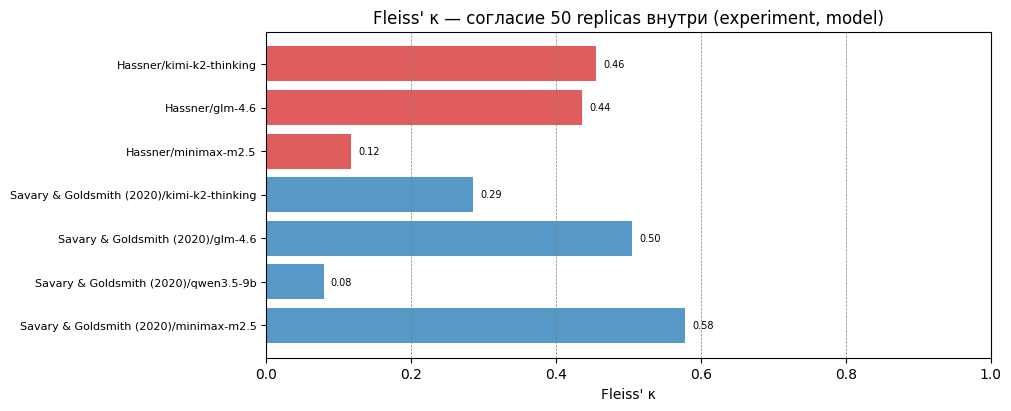

In [44]:
# 11.3 Fleiss' kappa
rows = []
for exp in EXPERIMENTS:
    cats = ["Yes", "No"] if "Hassner" in exp else ["1", "2", "3", "4", "5"]
    for m in MODEL_ORDER_CANONICAL:
        sub = MAIN_DF[(MAIN_DF["experiment_name"] == exp) & (MAIN_DF["model"] == m)]
        if len(sub) == 0:
            continue
        # items = (group, incentive); columns = answer categories
        mat = sub.groupby(["group_name", "incentive", "answer_cat"]).size().unstack(fill_value=0)
        mat = mat.reindex(columns=cats, fill_value=0)
        # Equal N per item required — оставим только items с модальным N
        N_per_item = mat.sum(axis=1)
        if len(N_per_item) < 2:
            continue
        N_mode = int(N_per_item.mode().iloc[0])
        mat_eq = mat[N_per_item == N_mode]
        if len(mat_eq) < 2:
            continue
        k = fleiss_kappa(mat_eq.values)
        rows.append({
            "experiment": EXP_TITLE[exp],
            "model": m.split("/")[-1],
            "n_items": len(mat_eq),
            "n_raters": N_mode,
            "Fleiss κ": k,
            "interpretation": (
                "slight" if k < 0.2 else "fair" if k < 0.4 else "moderate" if k < 0.6
                else "substantial" if k < 0.8 else "almost perfect"
            ),
        })
fk_df = pd.DataFrame(rows)
display(Markdown("### Fleiss' κ per (experiment, model)"))
display(fk_df.style.format({"Fleiss κ": "{:.3f}"}))

# Visualize
fig, ax = plt.subplots(figsize=(10, 4), constrained_layout=True)
exp_short = fk_df["experiment"].str.split(" et").str[0]
ax.barh(range(len(fk_df)),
        fk_df["Fleiss κ"],
        color=["#d62728" if "Hassner" in e else "#1f77b4" for e in fk_df["experiment"]],
        alpha=0.75)
ax.set_yticks(range(len(fk_df)))
ax.set_yticklabels([f"{r['experiment'].split(' et')[0]}/{r['model']}" for _, r in fk_df.iterrows()], fontsize=8)
ax.invert_yaxis()
ax.axvline(0.2, ls="--", color="gray", lw=0.5)
ax.axvline(0.4, ls="--", color="gray", lw=0.5)
ax.axvline(0.6, ls="--", color="gray", lw=0.5)
ax.axvline(0.8, ls="--", color="gray", lw=0.5)
ax.set_xlim(0, 1)
ax.set_xlabel("Fleiss' κ")
ax.set_title("Fleiss' κ — согласие 50 replicas внутри (experiment, model)")
for i, k in enumerate(fk_df["Fleiss κ"]):
    if not pd.isna(k):
        ax.text(k + 0.01, i, f"{k:.2f}", va="center", fontsize=7)
plt.show()


## 11.4 Резюме stability

| Уровень | Найденная картина |
|---|---|
| Cell-level agreement | Hassner mean = **0.85**, Savary mean = **0.81**. Внутри одного condition модели в среднем дают одну и ту же категорию ответа в 80–85% случаев. |
| Влияет ли incentive | В Hassner: no_incentive **самый стабильный** (0.91); стимулы H–K снижают (0.79–0.81); L/M возвращают к высокому уровню (0.88–0.90). В Savary: no_incentive **средний** (0.80); L самый низкий (0.74). То есть incentive скорее **снижает** стабильность относительно baseline. |
| T=0.01 vs T=1.0 | Как ожидалось, T=1.0 снижает agreement и повышает std. Эффект небольшой (Δ ≈ 0.02–0.05) — модели даже при высокой температуре остаются в режиме «одна категория доминирует». |
| Fleiss' κ | Hassner Kimi/GLM 0.44–0.45 (moderate); Minimax 0.12 (poor — модель почти всегда даёт `No`, raters не различают items). Savary: GLM 0.51, Minimax 0.58 (moderate); Kimi 0.29 (fair); Qwen — мало items для оценки. |

**Главный вывод:** поведение модели **устойчиво** внутри одного condition (типично >80% modal agreement). Incentive **скорее снижает** стабильность, чем повышает — модели становятся менее уверенными при добавлении контекстуального стимула, особенно в Hassner с H/I/J/K и в Savary с L/M.

**Caveat:** Minimax/Qwen имеют артефактно «высокую» стабильность в no_incentive (90%+ agreement) потому, что они почти всегда выдают одну и ту же категорию (`No` в Hassner, нейтральное `3` в Savary). Это не «стабильность модели как respondent», а «модель слабо реагирует на treatment». Fleiss' κ для них низкий — подтверждает эту интерпретацию.

# Итоговая интерпретация (Part 3 ANALYSIS_README)

Ответы на 10 интерпретационных вопросов финала. Для каждого — содержательный ответ + ссылка на блок ноутбука + ключевые цифры. Вопросы 8–10 относятся к hidden state analysis (Part 2) и зарезервированы для отдельного ноутбука `hidden_states/hs_analysis.ipynb`.

## 1. Есть ли эффект treatment на ответы модели?

**Да, сильный и устойчивый.** В обоих экспериментах treatment-эффекты значимы для большинства пар (block 4.1: Hassner 22/27 значимы после Holm, Savary 14/18). Marginal effects из logistic regression (block 7.1):

| Treatment | Marginal effect ΔP(Yes) |
|---|---|
| `treatment_modest_intelligence` | −24.6 п.п. (p < 10⁻⁴⁵) |
| `treatment_protracted_duration` | −18.0 п.п. (p < 10⁻³³) |
| `treatment_duration_plus_modest_intelligence` | **−55.0 п.п.** (p < 10⁻²⁹) |

Для Savary эффект `public_recognition_with_social_benefit` в no_incentive даёт Cohen d = **+1.66** (very large), Cliff's δ = +0.64 (block 5.1).

## 2. Есть ли эффект incentive на ответы модели?

**Да, повсеместно.** Omnibus χ²/Kruskal–Wallis внутри каждой `group_name`: p ≈ 0 во всех 7 группах (block 4.2b). Попарные `no_incentive` vs `incentive_X` внутри групп: значимы после Holm в **31/32** парах Hassner и **24/24** Savary (block 4.2a). 

Направление эффекта различается между стимулами: A/L/M в Hassner резко увеличивают P(Yes) (no_incentive 19% → A 72% → L 88% → M 90%), C/H/I/J/K дают промежуточные сдвиги. В Savary все стимулы **снижают** M(answer) относительно no_incentive (3.74 → 3.14–3.44, block 2.4).

## 3. Модерирует ли incentive исходный treatment-effect?

**Да, в значительной части пар.** DiD-тест (block 4.3): значимы после Holm в **11/24** Hassner и **10/16** Savary пар. Модерация двунаправленна (block 6.3):

- Стимулы H/I/J/K в Hassner **усиливают** treatment-эффект `duration_plus_modest_intelligence` (|Δ| 0.44 → 0.85–0.93).
- Стимул A **ослабляет** Hassner treatment-эффекты (например, A × `modest_intelligence`: |Δ| 0.32 → 0.14).
- L/M в Hassner: ослабляют слабые эффекты, усиливают сильные.

## 4. Воспроизводит ли модель направление эффектов из оригинальных human experiments?

**Да, для всех 4 проверяемых направлений в `no_incentive` baseline (block 6.1):**

| Эксперимент | Treatment | Ожидаемое направление | Наблюдаемое | Verdict |
|---|---|---|---|---|
| Hassner | `protracted_duration` | ↓ P(Yes) | ↓ (Δ = −0.25) | ✓ |
| Hassner | `duration_plus_modest_intelligence` | ↓ P(Yes) | ↓ (Δ = −0.44) | ✓ |
| Savary | `public_recognition_treatment` | ↑ M(answer) | ↑ (d = +0.72) | ✓ |
| Savary | `public_recognition_with_social_benefit` | ↑ M(answer) | ↑ (d = +1.66) | ✓ |

Для `treatment_modest_intelligence` ожидаемое направление в оригинале неоднозначно (помечено `?`); в данных наблюдается ↓ (Δ = −0.32), но это не штрафуется как «противоречие».

## 5. Делает ли incentive ответы более категоричными, однородными или сбалансированными?

**В среднем — менее однородными, более сбалансированными** (block 3.4):

| Метрика | Hassner no_inc → any_inc | Savary no_inc → any_inc |
|---|---|---|
| Shannon H | 0.70 → 0.96 (+0.26) | 1.09 → 1.25 (+0.16) |
| concentration (max p_i) | 0.81 → 0.62 | 0.67 → 0.59 |
| agreement_rate | 0.69 → 0.53 | 0.53 → 0.48 |
| extremity (Hassner) | 0.62 → 0.24 | — |
| extreme_share (Savary) | — | 0.037 → 0.010 |

**Но это «среднее по стимулам»**: отдельные стимулы (L, M в Hassner) дают сильное единогласие в обратную сторону (P(Yes) 88–90%, extremity 0.77–0.80). Стимулы скорее **сдвигают** доминирующий ответ, чем «открывают» распределение, и эффект зависит от семантики конкретного стимула (block 3.1).

## 6. Насколько устойчивы ответы модели при повторных генерациях?

**Высоко устойчивы**: внутри одного condition `(model, group, incentive)` модель в среднем даёт модальный ответ в **85% случаев в Hassner** и **81% в Savary** (block 11.1).

- Incentive **скорее снижает** стабильность: Hassner no_inc 0.91 → H–K 0.79–0.81; Savary L 0.74.
- T=1.0 vs T=0.01 (no_incentive): незначительное снижение (Δagreement = −0.02 до −0.05) — модели остаются в режиме «одна категория доминирует» даже при высокой температуре.
- Fleiss' κ для Kimi/GLM = 0.44–0.51 (moderate). Minimax/Qwen имеют artefactно «высокую» стабильность из-за квази-единогласия (почти всегда `No` или `3`); κ для них в slight/fair зоне (block 11.3).

## 7. Насколько результаты зависят от prompt template и model?

**Prompt template — не варьируется** (`template_name = "one_stage_attitude_expression"` константа), поэтому prompt sensitivity невозможно проверить.

**Model heterogeneity огромна** (block 2.5, 10.1):

| Модель | P(Yes) Hassner |
|---|---|
| Kimi | 56% |
| GLM | 68% |
| Qwen | 22% |
| Minimax | 10% |

Направление treatment-эффекта **в основном** одинаково по моделям (block 10.1: несовпадения с агрегатом редкие, в основном на Minimax/Qwen в случаях квази-единогласия Δ≈0). Спецификация в block 7 c `model` FE даёт лучший AIC при добавлении `treatment × model` interaction (4475 → 4177) — модели реагируют на treatments **по-разному по силе**, но **в одном направлении**.

**Caveat сетки**: H–M стимулы измерены только на GLM+Kimi, поэтому коэффициенты incentive_H–M в регрессиях — это эффект «на подвыборке GLM+Kimi». После пополнения данных Minimax/Qwen-прогонами в H–M это caveat снимется.

## 8. На каких слоях hidden states сильнее всего различаются между incentive и no incentive?

**(Part 2, `hs_analysis.ipynb` §1/§2.)** Между-условная сепарация (L2, cosine, mean diff, CKA) нарастает с L1 до пика в **L18–L23** и снижается к L36. Отношение between/within distance максимально на **L20** (score 1.39). Все четыре метрики дают согласованный пик: mid-layers решающие для incentive-сепарации. §4 (PCA/UMAP): эксперимент доминирует (silhouette ≈ 0.54–0.75), incentive (none vs any) — скромная вторичная структура (silhouette 0.22 @ L18 → 0.02 @ L34).

## 9. Можно ли по hidden states линейно предсказать incentive, treatment или final answer?

**(Part 2, `hs_analysis.ipynb` §3.)** Три результата:

- **Incentive (7-class)** — тривиально да (balanced acc ≈ 1.00 с L1): разные стимулы несут разные surface tokens, hidden states декодируют их с L1+. Не interpretability-сигнал.
- **Treatment vs control** с честным LeaveOneGroupOut по `(group_name, context)` — **null** (median AUC ≈ 0): модель кодирует конкретные сценарии, не абстрактную «функцию treatment».
- **Final answer**: Hassner насыщен (P(Yes)≈0.998, variance≈0); Savary — weak linear readout (|corr(PC, y)| ≈ 0.33 на L20).

## 10. Связаны ли hidden-state shifts с изменением финального ответа?

**(Part 2, `hs_analysis.ipynb` §7/§8.)** Диссоциация representational и behavioral shifts:

| Experiment | mean |Δy| | hs_L20 (mean) |
|-----------|----------|--------------|
| Hassner   | ≈ 0.001  | ≈ 16.4       |
| Savary    | ≈ 0.742  | ≈ 15.9       |

Representational сдвиги на L20 **сопоставимы** между экспериментами (~16 ед.), хотя behavioral effect у Hassner в 700× меньше. Прямой связи «больше shift → больше behavioral change» нет ни в одном эксперименте. HS-shifts в L18–L20 — надёжный маркер **наличия** incentive-фрейма, но не **силы** его поведенческого влияния. Корреляция r(Δy, hs_L20) внутри Savary = +0.65, но Δy < 0, поэтому более сильный representational shift ≠ более сильный behavioral effect.

## Сводная таблица: что где смотреть

| Вопрос | Блок ноутбука | Ключевые таблицы / графики |
|---|---|---|
| 1. Treatment effect | 2.3, 4.1, 5.1, 7.1 | bar plot P(Yes)/M по group, χ²/MWU таблица, marginal effects logit |
| 2. Incentive effect | 2.4, 4.2, 5.2, 7.1, 7.2 | bar plot по incentive, χ²/MWU+omnibus, ordinal logit summary |
| 3. Interaction | 4.3, 6.3, 7.1 | DiD таблица + moderation summary, regression interaction-коэффициенты |
| 4. Replication direction | 6.1, 6.2, 6.5 | direction-arrow heatmap, ranking grids, итоговая verdict-таблица |
| 5. Категоричность | 3.1–3.4 | entropy/concentration/extremity grids + сводный bar plot |
| 6. Stability | 11.1–11.4 | agreement_rate heatmap, T-comparison, Fleiss' κ |
| 7. Prompt / model | 1.3, 2.5, 10.1, 7.4 | cross-tabs, by-model bar + by-model robustness, model FE в регрессиях |
| 8.–10. Hidden states | — | (Part 2, отдельная сессия) |

**Базовый ответ диплома (одной фразой):** LLM-как-respondent **воспроизводит** treatment-эффекты оригинальных human experiments в направлении и приблизительно в размерности; **incentive значимо модулирует** treatment-эффекты, причём двунаправленно (одни стимулы усиливают, другие ослабляют), а **общая стабильность ответов модели высока** (≈80–85% modal agreement), но зависит от incentive.

## Без стимула (`no_incentive`)

Sharp zero temp (reasoning / non-reasoning); в master: `run_dir_name` как ниже.


### `no_incentive_zero_temp_2_expos`


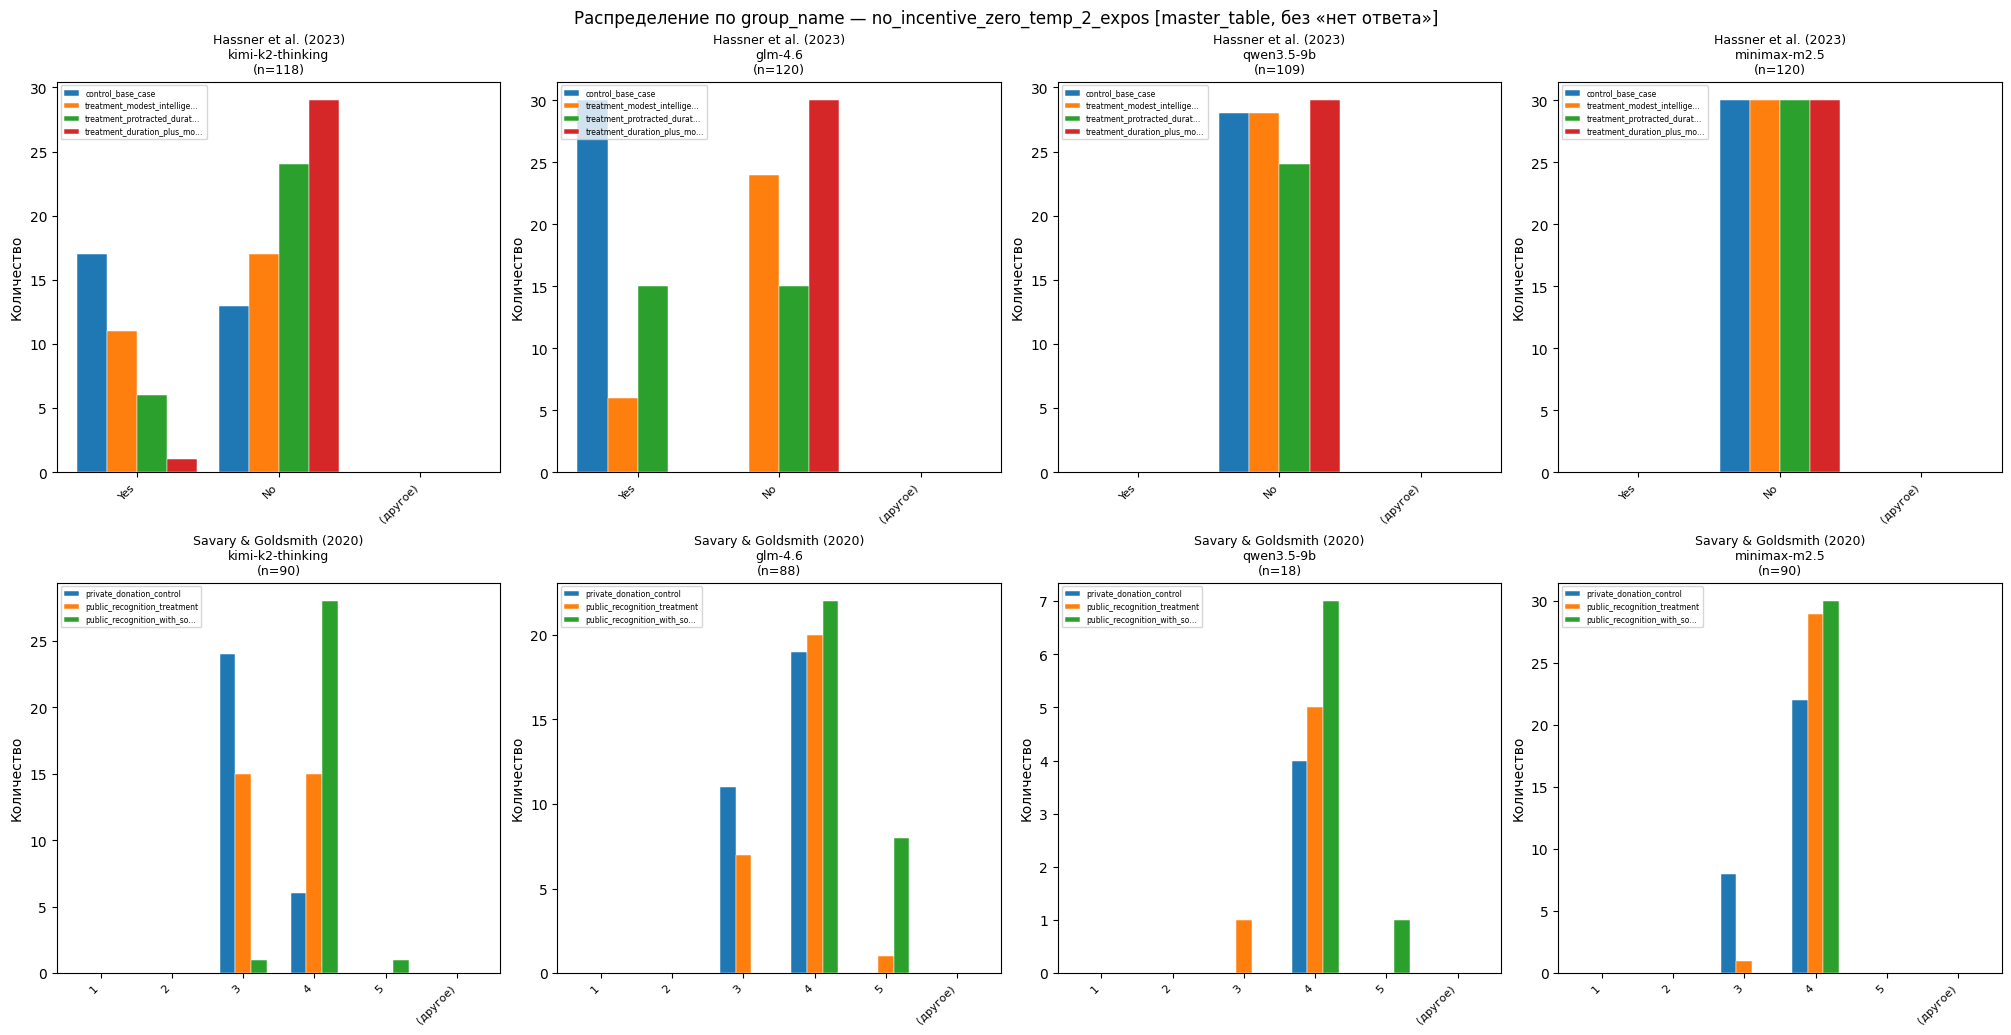

#### Статистика — Hassner et al. (2023)

,Модель,Control,Treatment,n (C),n (T),χ²,df,p (χ²),t,p (t),M(C),M(T),n num C,n num T
0,minimax-m2.5,control_base_case,treatment_duration_plus_modest_intelligence,30,30,—,—,—,—,—,0.0000,0.0000,30,30
1,minimax-m2.5,control_base_case,treatment_modest_intelligence,30,30,—,—,—,—,—,0.0000,0.0000,30,30
2,minimax-m2.5,control_base_case,treatment_protracted_duration,30,30,—,—,—,—,—,0.0000,0.0000,30,30
3,kimi-k2-thinking,control_base_case,treatment_duration_plus_modest_intelligence,30,30,17.8571,1,0.0000***,5.4494,0.0000***,0.5667,0.0333,30,30
4,kimi-k2-thinking,control_base_case,treatment_modest_intelligence,30,28,1.1252,1,0.2888,1.3214,0.1918,0.5667,0.3929,30,28
5,kimi-k2-thinking,control_base_case,treatment_protracted_duration,30,30,7.0505,1,0.0079**,3.1006,0.0030**,0.5667,0.2000,30,30
6,qwen3.5-9b,control_base_case,treatment_duration_plus_modest_intelligence,28,29,—,—,—,—,—,0.0000,0.0000,28,29
7,qwen3.5-9b,control_base_case,treatment_modest_intelligence,28,28,—,—,—,—,—,0.0000,0.0000,28,28
8,qwen3.5-9b,control_base_case,treatment_protracted_duration,28,24,—,—,—,—,—,0.0000,0.0000,28,24
9,glm-4.6,control_base_case,treatment_duration_plus_modest_intelligence,30,30,56.0667,1,0.0000***,inf,0.0000***,1.0000,0.0000,30,30


#### Статистика — Savary & Goldsmith (2020)

,Модель,Control,Treatment,n (C),n (T),χ²,df,p (χ²),t,p (t),M(C),M(T),n num C,n num T
0,minimax-m2.5,private_donation_control,public_recognition_treatment,30,30,4.7059,1,0.0301*,-2.6328,0.0121*,3.7333,3.9667,30,30
1,minimax-m2.5,private_donation_control,public_recognition_with_social_benefit,30,30,7.0673,1,0.0079**,-3.2474,0.0029**,3.7333,4.0000,30,30
2,kimi-k2-thinking,private_donation_control,public_recognition_treatment,30,30,4.6886,1,0.0304*,-2.5231,0.0145*,3.2000,3.5000,30,30
3,kimi-k2-thinking,private_donation_control,public_recognition_with_social_benefit,30,30,36.3953,2,0.0000***,-9.0489,0.0000***,3.2000,4.0000,30,30
4,qwen3.5-9b,private_donation_control,public_recognition_treatment,4,6,0.0000,1,1.0000,1.0000,0.3632,4.0000,3.8333,4,6
5,qwen3.5-9b,private_donation_control,public_recognition_with_social_benefit,4,8,0.0000,1,1.0000,-1.0000,0.3506,4.0000,4.1250,4,8
6,glm-4.6,private_donation_control,public_recognition_treatment,30,28,1.8478,2,0.3970,-1.1725,0.2460,3.6333,3.7857,30,28
7,glm-4.6,private_donation_control,public_recognition_with_social_benefit,30,30,19.2195,2,0.0001***,-5.2146,0.0000***,3.6333,4.2667,30,30


In [45]:
_df = master_slice("no_incentive_zero_temp_2_expos")
safe_plot(
    lambda d=_df: d,
    "Распределение по group_name — no_incentive_zero_temp_2_expos [master_table, без «нет ответа»]",
    MODEL_ORDER_CANONICAL,
)
display_experiment_stats(_df, EXPERIMENTS[0])
display_experiment_stats(_df, EXPERIMENTS[1])


### `no_incentive_zero_temp_2_expos_nonreasoning`


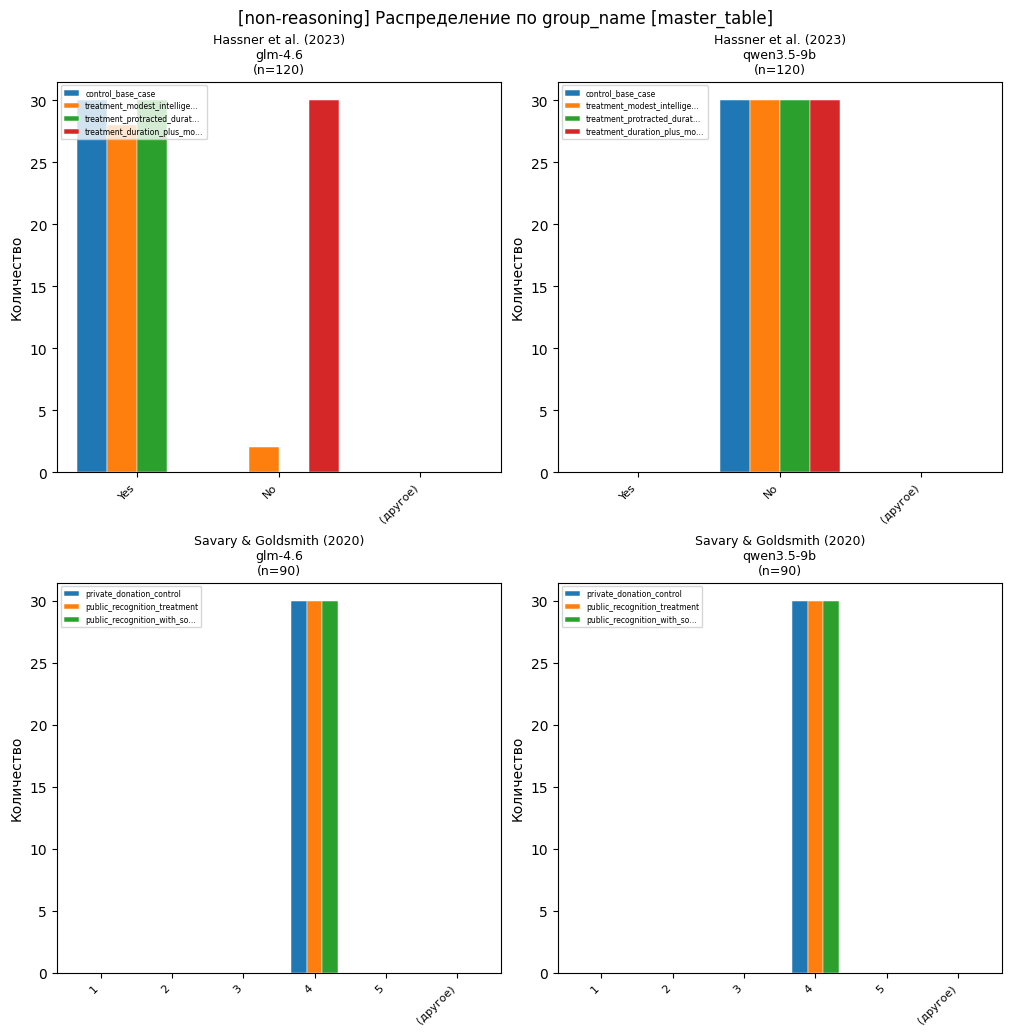

#### Статистика — Hassner et al. (2023)

,Модель,Control,Treatment,n (C),n (T),χ²,df,p (χ²),t,p (t),M(C),M(T),n num C,n num T
0,qwen3.5-9b,control_base_case,treatment_duration_plus_modest_intelligence,30,30,—,—,—,—,—,0.0000,0.0000,30,30
1,qwen3.5-9b,control_base_case,treatment_modest_intelligence,30,30,—,—,—,—,—,0.0000,0.0000,30,30
2,qwen3.5-9b,control_base_case,treatment_protracted_duration,30,30,—,—,—,—,—,0.0000,0.0000,30,30
3,glm-4.6,control_base_case,treatment_duration_plus_modest_intelligence,30,30,56.0667,1,0.0000***,inf,0.0000***,1.0000,0.0000,30,30
4,glm-4.6,control_base_case,treatment_modest_intelligence,30,30,0.5172,1,0.4720,1.4392,0.1608,1.0000,0.9333,30,30
5,glm-4.6,control_base_case,treatment_protracted_duration,30,30,—,—,—,—,—,1.0000,1.0000,30,30


#### Статистика — Savary & Goldsmith (2020)

,Модель,Control,Treatment,n (C),n (T),χ²,df,p (χ²),t,p (t),M(C),M(T),n num C,n num T
0,qwen3.5-9b,private_donation_control,public_recognition_treatment,30,30,—,—,—,—,—,4.0000,4.0000,30,30
1,qwen3.5-9b,private_donation_control,public_recognition_with_social_benefit,30,30,—,—,—,—,—,4.0000,4.0000,30,30
2,glm-4.6,private_donation_control,public_recognition_treatment,30,30,—,—,—,—,—,4.0000,4.0000,30,30
3,glm-4.6,private_donation_control,public_recognition_with_social_benefit,30,30,—,—,—,—,—,4.0000,4.0000,30,30


In [46]:
_df = master_slice("no_incentive_zero_temp_2_expos_nonreasoning")
safe_plot(
    lambda d=_df: d,
    "[non-reasoning] Распределение по group_name [master_table]",
    MODEL_ORDER_CANONICAL,
)
display_experiment_stats(_df, EXPERIMENTS[0])
display_experiment_stats(_df, EXPERIMENTS[1])


## Стимул `C_balanced_realism`

Только план 50 (две части в master). Отдельного прогона `incentive_C_balanced_realism_reasoning_trace` в текущем master нет.


### План 50: `incentive_C_balanced_realism_50_reasoning_trace` + `..._p2`


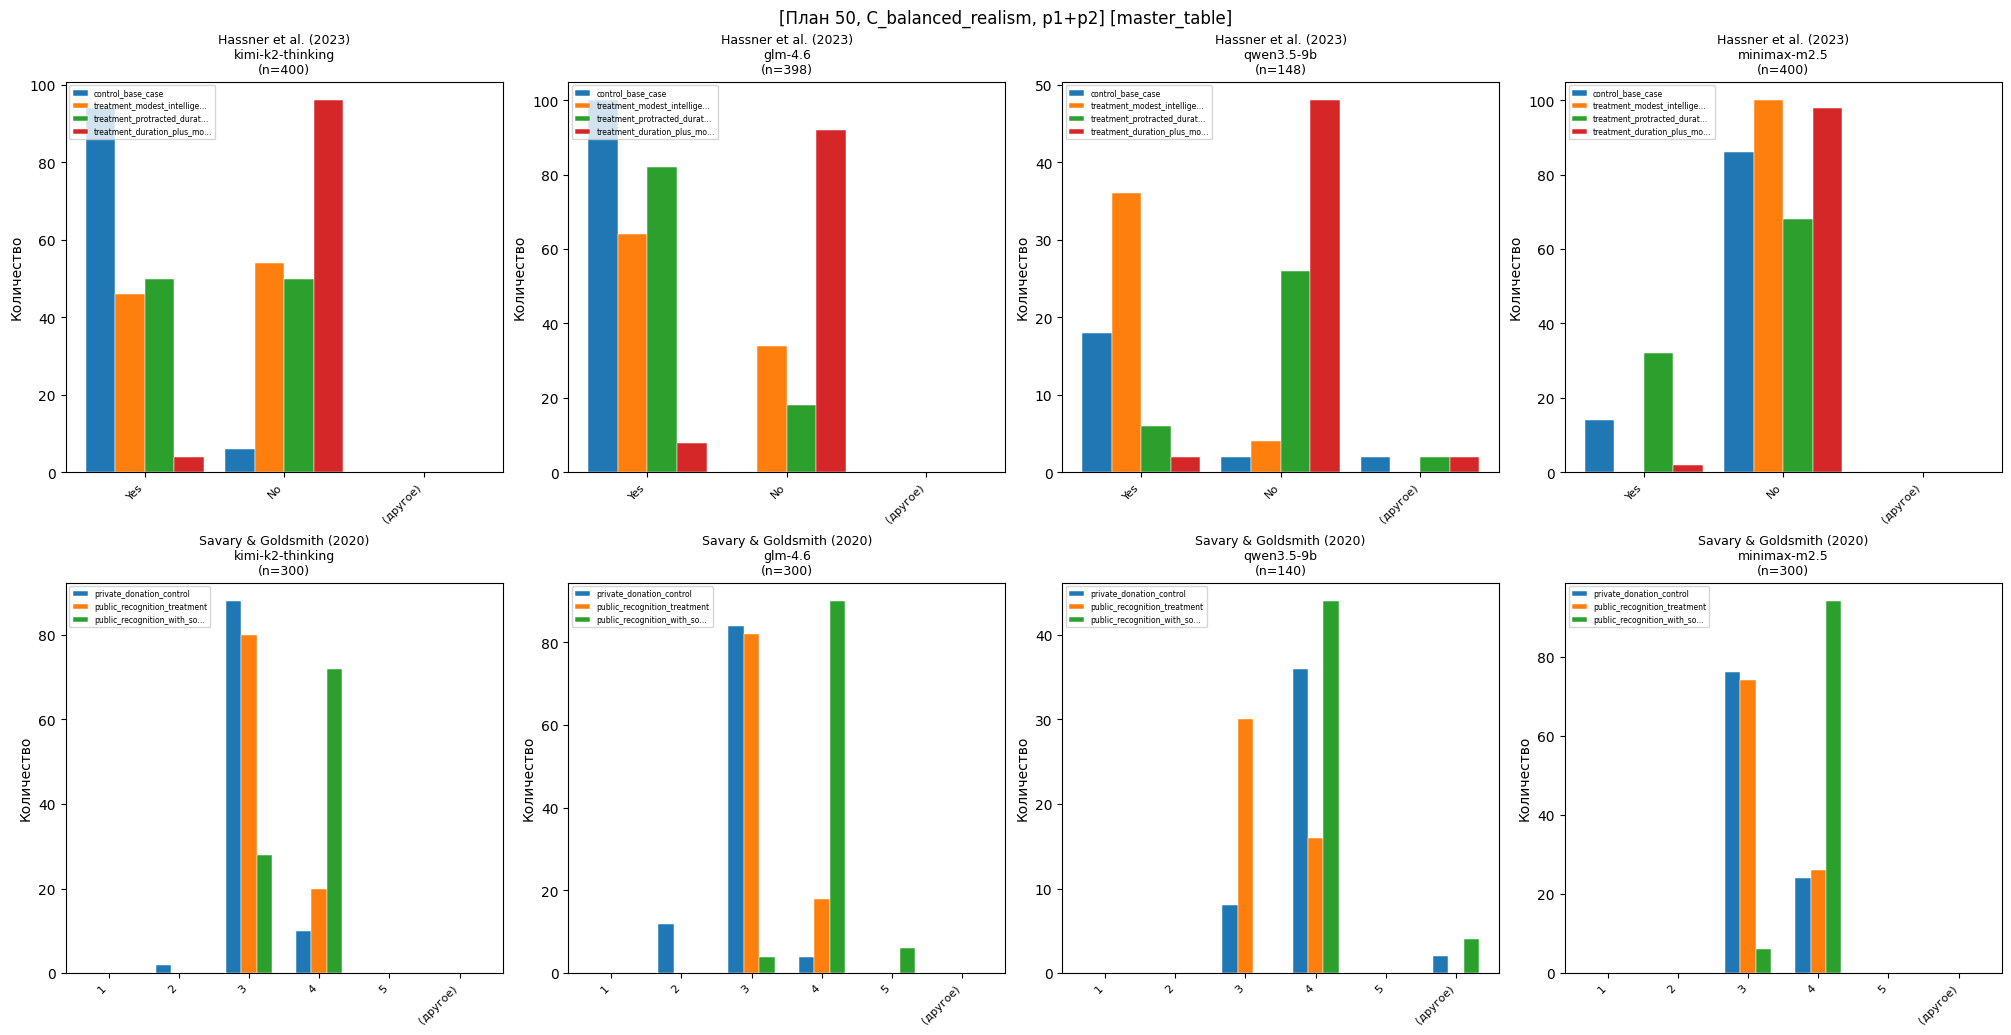

#### Статистика — Hassner et al. (2023)

,Модель,Control,Treatment,n (C),n (T),χ²,df,p (χ²),t,p (t),M(C),M(T),n num C,n num T
0,minimax-m2.5,control_base_case,treatment_duration_plus_modest_intelligence,100,100,8.2201,1,0.0041**,3.1911,0.0018**,0.1400,0.0200,100,100
1,minimax-m2.5,control_base_case,treatment_modest_intelligence,100,100,12.9800,1,0.0003***,4.0145,0.0001***,0.1400,0.0000,100,100
2,minimax-m2.5,control_base_case,treatment_protracted_duration,100,100,8.1592,1,0.0043**,-3.0806,0.0024**,0.1400,0.3200,100,100
3,kimi-k2-thinking,control_base_case,treatment_duration_plus_modest_intelligence,100,100,158.4834,1,0.0000***,29.0841,0.0000***,0.9400,0.0400,100,100
4,kimi-k2-thinking,control_base_case,treatment_modest_intelligence,100,100,52.5952,1,0.0000***,8.6507,0.0000***,0.9400,0.4600,100,100
5,kimi-k2-thinking,control_base_case,treatment_protracted_duration,100,100,45.8581,1,0.0000***,7.9091,0.0000***,0.9400,0.5000,100,100
6,qwen3.5-9b,control_base_case,treatment_duration_plus_modest_intelligence,22,52,51.4067,2,0.0000***,11.5747,0.0000***,0.9000,0.0400,20,50
7,qwen3.5-9b,control_base_case,treatment_modest_intelligence,22,40,3.7576,2,0.1528,0.0000,1.0000,0.9000,0.9000,20,40
8,qwen3.5-9b,control_base_case,treatment_protracted_duration,22,34,25.1551,2,0.0000***,7.2526,0.0000***,0.9000,0.1875,20,32
9,glm-4.6,control_base_case,treatment_duration_plus_modest_intelligence,100,100,166.6868,1,0.0000***,33.7417,0.0000***,1.0000,0.0800,100,100


#### Статистика — Savary & Goldsmith (2020)

,Модель,Control,Treatment,n (C),n (T),χ²,df,p (χ²),t,p (t),M(C),M(T),n num C,n num T
0,minimax-m2.5,private_donation_control,public_recognition_treatment,100,100,0.0267,1,0.8703,-0.3250,0.7455,3.2400,3.2600,100,100
1,minimax-m2.5,private_donation_control,public_recognition_with_social_benefit,100,100,98.4084,1,0.0000***,-14.2527,0.0000***,3.2400,3.9400,100,100
2,kimi-k2-thinking,private_donation_control,public_recognition_treatment,100,100,5.7143,2,0.0574,-2.2827,0.0235*,3.0800,3.2000,100,100
3,kimi-k2-thinking,private_donation_control,public_recognition_with_social_benefit,100,100,79.9125,2,0.0000***,-11.3424,0.0000***,3.0800,3.7200,100,100
4,qwen3.5-9b,private_donation_control,public_recognition_treatment,46,46,22.4291,2,0.0000***,5.1016,0.0000***,3.8182,3.3478,44,46
5,qwen3.5-9b,private_donation_control,public_recognition_with_social_benefit,46,48,9.4284,2,0.0090**,-3.0912,0.0035**,3.8182,4.0000,44,44
6,glm-4.6,private_donation_control,public_recognition_treatment,100,100,20.9332,2,0.0000***,-4.7137,0.0000***,2.9200,3.1800,100,100
7,glm-4.6,private_donation_control,public_recognition_with_social_benefit,100,100,169.4081,3,0.0000***,-21.7510,0.0000***,2.9200,4.0200,100,100


In [47]:
_df = master_slice(
    [
        "incentive_C_balanced_realism_50_reasoning_trace",
        "incentive_C_balanced_realism_50_reasoning_trace_p2",
    ]
)
safe_plot(
    lambda d=_df: d,
    "[План 50, C_balanced_realism, p1+p2] [master_table]",
    MODEL_ORDER_CANONICAL,
)
display_experiment_stats(_df, EXPERIMENTS[0])
display_experiment_stats(_df, EXPERIMENTS[1])


## Стимул `X_measurement_neutrality`

В текущем `master_table.parquet` нет `run_dir_name` для этого прогона — график появится после добавления данных в master.


## Стимул `A_original_core_realism`

План 50.


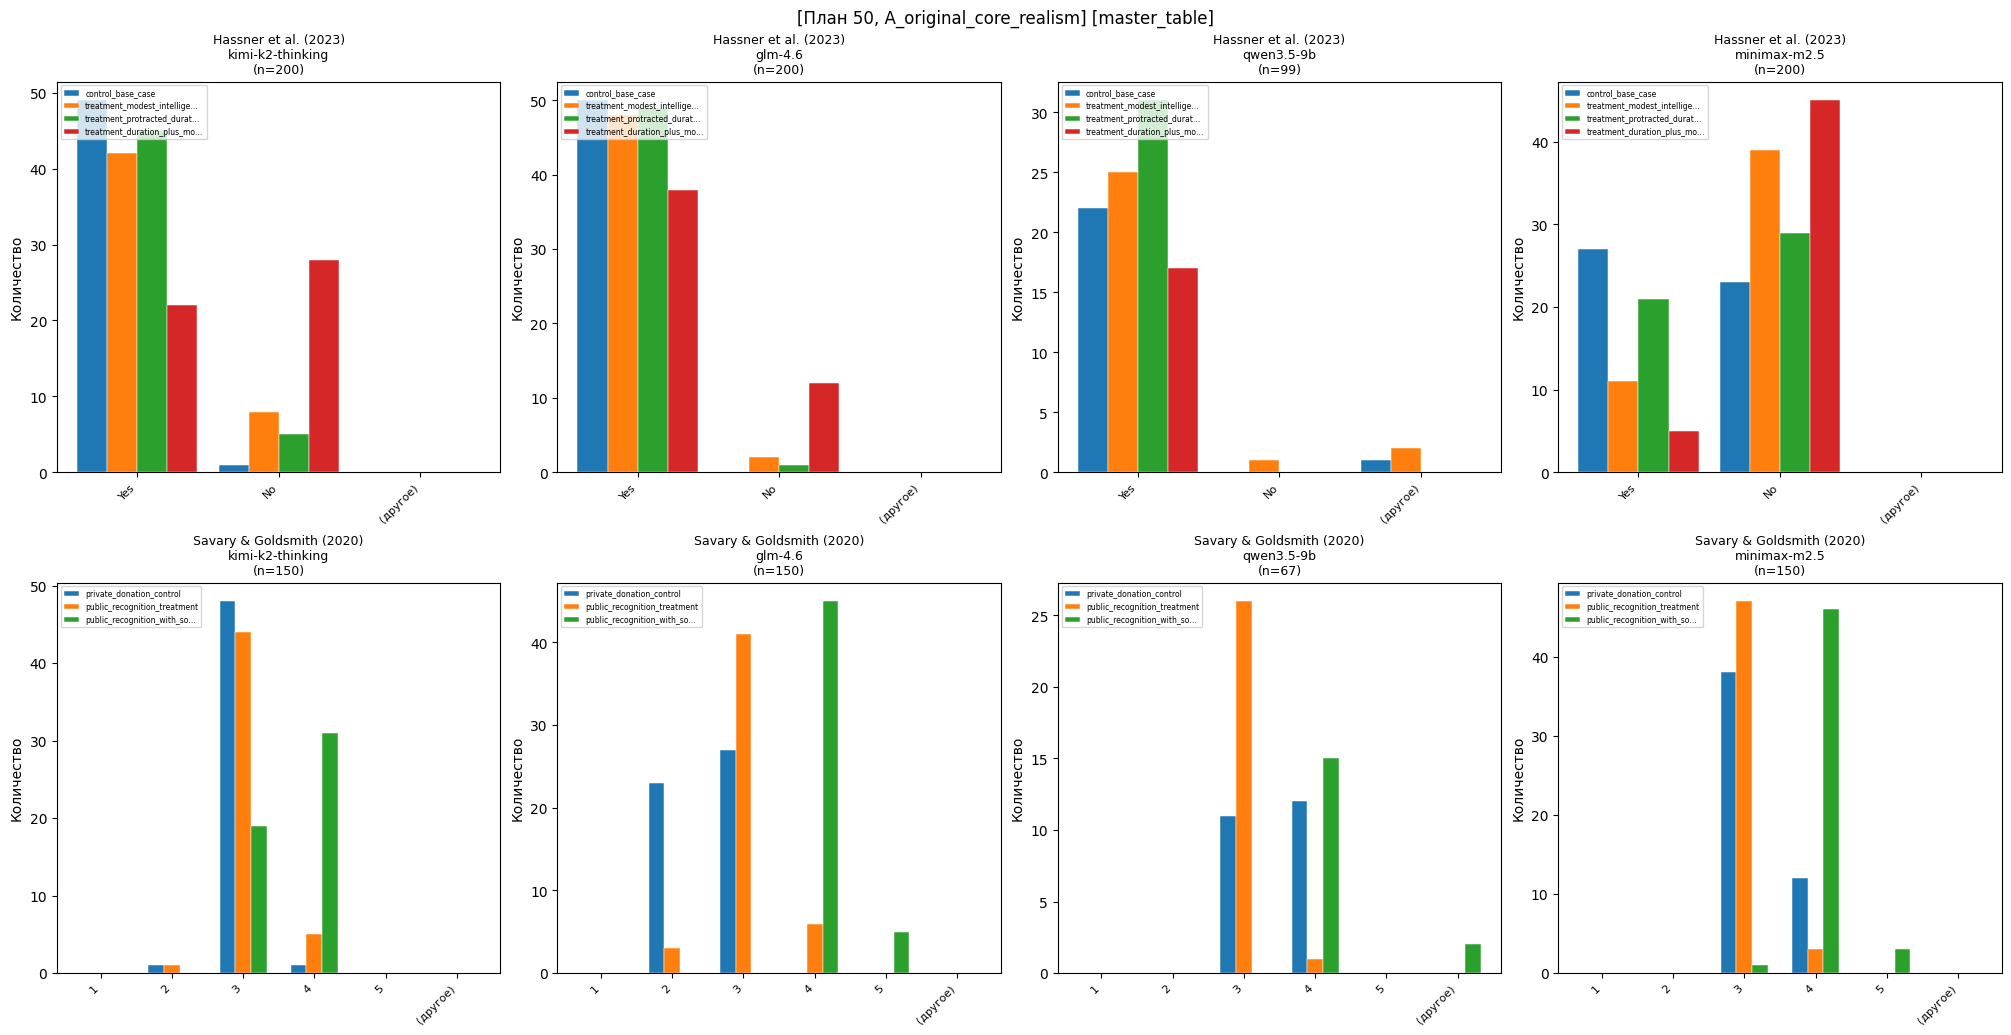

#### Статистика — Hassner et al. (2023)

,Модель,Control,Treatment,n (C),n (T),χ²,df,p (χ²),t,p (t),M(C),M(T),n num C,n num T
0,minimax-m2.5,control_base_case,treatment_duration_plus_modest_intelligence,50,50,20.2665,1,0.0000***,5.2946,0.0000***,0.5400,0.1000,50,50
1,minimax-m2.5,control_base_case,treatment_modest_intelligence,50,50,9.5501,1,0.0020**,3.4564,0.0008***,0.5400,0.2200,50,50
2,minimax-m2.5,control_base_case,treatment_protracted_duration,50,50,1.0016,1,0.3169,1.1976,0.2340,0.5400,0.4200,50,50
3,kimi-k2-thinking,control_base_case,treatment_duration_plus_modest_intelligence,50,50,32.8315,1,0.0000***,7.3291,0.0000***,0.9800,0.4400,50,50
4,kimi-k2-thinking,control_base_case,treatment_modest_intelligence,50,50,4.3956,1,0.0360*,2.4973,0.0151*,0.9800,0.8400,50,50
5,kimi-k2-thinking,control_base_case,treatment_protracted_duration,50,50,1.5957,1,0.2065,1.6915,0.0952,0.9800,0.9000,50,50
6,qwen3.5-9b,control_base_case,treatment_duration_plus_modest_intelligence,23,17,0.0000,1,1.0000,—,—,1.0000,1.0000,22,17
7,qwen3.5-9b,control_base_case,treatment_modest_intelligence,23,28,1.0447,2,0.5931,1.0000,0.3269,1.0000,0.9615,22,26
8,qwen3.5-9b,control_base_case,treatment_protracted_duration,23,31,0.0229,1,0.8798,—,—,1.0000,1.0000,22,31
9,glm-4.6,control_base_case,treatment_duration_plus_modest_intelligence,50,50,11.4583,1,0.0007***,3.9337,0.0003***,1.0000,0.7600,50,50


#### Статистика — Savary & Goldsmith (2020)

,Модель,Control,Treatment,n (C),n (T),χ²,df,p (χ²),t,p (t),M(C),M(T),n num C,n num T
0,minimax-m2.5,private_donation_control,public_recognition_treatment,50,50,5.0196,1,0.0251*,2.5784,0.0118*,3.2400,3.0600,50,50
1,minimax-m2.5,private_donation_control,public_recognition_with_social_benefit,50,50,58.0336,2,0.0000***,-10.9656,0.0000***,3.2400,4.0400,50,50
2,kimi-k2-thinking,private_donation_control,public_recognition_treatment,50,50,2.8406,2,0.2416,-1.4289,0.1569,3.0000,3.0800,50,50
3,kimi-k2-thinking,private_donation_control,public_recognition_with_social_benefit,50,50,41.6772,2,0.0000***,-8.2670,0.0000***,3.0000,3.6200,50,50
4,qwen3.5-9b,private_donation_control,public_recognition_treatment,23,27,12.7512,1,0.0004***,4.2987,0.0002***,3.5217,3.0370,23,27
5,qwen3.5-9b,private_donation_control,public_recognition_with_social_benefit,23,17,12.7195,2,0.0017**,-4.4907,0.0002***,3.5217,4.0000,23,15
6,glm-4.6,private_donation_control,public_recognition_treatment,50,50,24.2670,2,0.0000***,-5.5848,0.0000***,2.5400,3.0600,50,50
7,glm-4.6,private_donation_control,public_recognition_with_social_benefit,50,50,100.0000,3,0.0000***,-18.7719,0.0000***,2.5400,4.1000,50,50


In [48]:
_df = master_slice("incentive_A_original_core_realism_50_reasoning_trace")
safe_plot(
    lambda d=_df: d,
    "[План 50, A_original_core_realism] [master_table]",
    MODEL_ORDER_CANONICAL,
)
display_experiment_stats(_df, EXPERIMENTS[0])
display_experiment_stats(_df, EXPERIMENTS[1])


## Стимулы H–K (план 50, GLM + Kimi)

Для каждого ключа: основной прогон и при наличии в master — `__kimi_rerun`; дедупликация с приоритетом ответа не «(нет ответа)».


### `H_science_personal_gain` → `['incentive_H_science_personal_gain_50_reasoning_trace_glm_kimi_t001', 'incentive_H_science_personal_gain_50_reasoning_trace_glm_kimi_t001__kimi_rerun']`

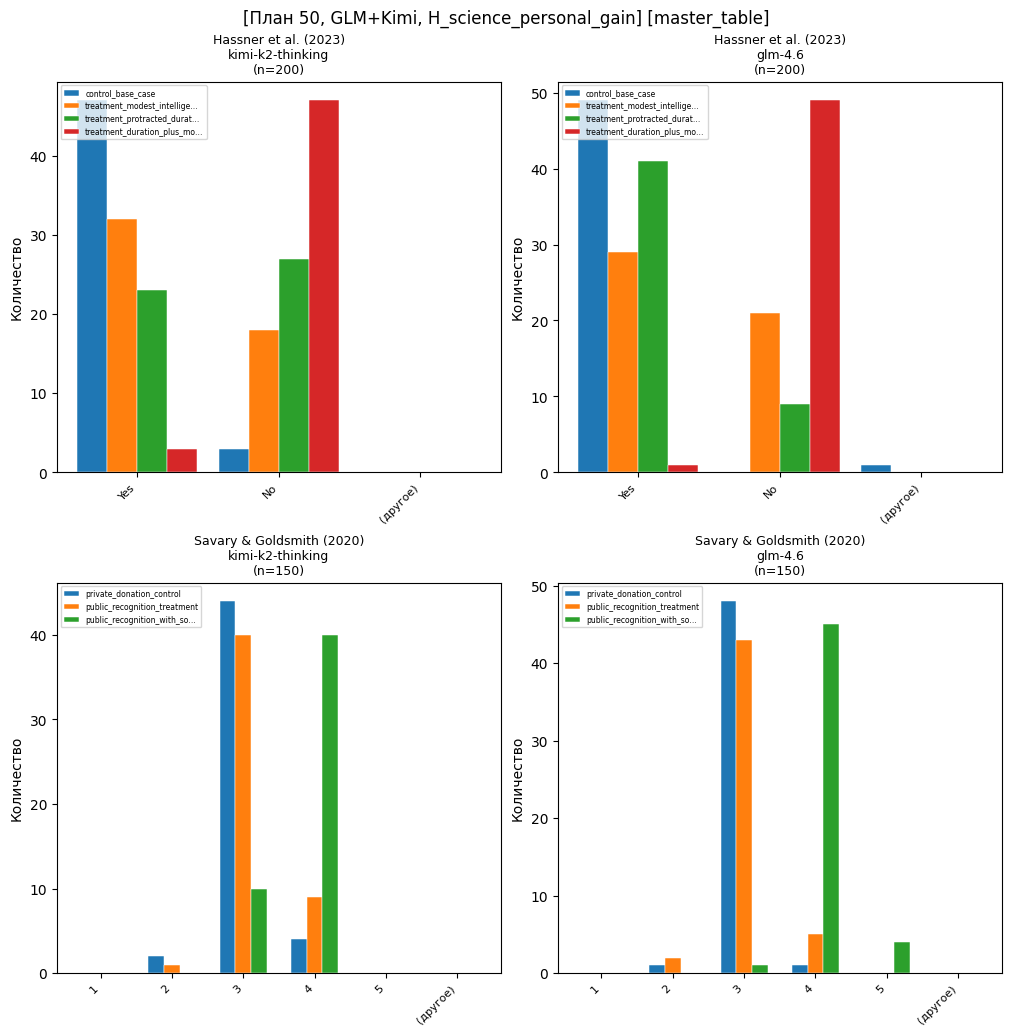

#### Статистика — Hassner et al. (2023)

,Модель,Control,Treatment,n (C),n (T),χ²,df,p (χ²),t,p (t),M(C),M(T),n num C,n num T
0,kimi-k2-thinking,control_base_case,treatment_duration_plus_modest_intelligence,50,50,73.9600,1,0.0000***,18.3411,0.0000***,0.9400,0.0600,50,50
1,kimi-k2-thinking,control_base_case,treatment_modest_intelligence,50,50,11.8143,1,0.0006***,3.9213,0.0002***,0.9400,0.6400,50,50
2,kimi-k2-thinking,control_base_case,treatment_protracted_duration,50,50,25.1905,1,0.0000***,6.0860,0.0000***,0.9400,0.4600,50,50
3,glm-4.6,control_base_case,treatment_duration_plus_modest_intelligence,50,50,96.0800,2,0.0000***,49.0000,0.0000***,1.0000,0.0200,49,50
4,glm-4.6,control_base_case,treatment_modest_intelligence,50,50,27.1282,2,0.0000***,5.9567,0.0000***,1.0000,0.5800,49,50
5,glm-4.6,control_base_case,treatment_protracted_duration,50,50,10.7111,2,0.0047**,3.2796,0.0019**,1.0000,0.8200,49,50


#### Статистика — Savary & Goldsmith (2020)

,Модель,Control,Treatment,n (C),n (T),χ²,df,p (χ²),t,p (t),M(C),M(T),n num C,n num T
0,kimi-k2-thinking,private_donation_control,public_recognition_treatment,50,50,2.4469,2,0.2942,-1.5524,0.1239,3.0400,3.1600,50,50
1,kimi-k2-thinking,private_donation_control,public_recognition_with_social_benefit,50,50,52.8620,2,0.0000***,-10.0827,0.0000***,3.0400,3.8000,50,50
2,glm-4.6,private_donation_control,public_recognition_treatment,50,50,3.2747,2,0.1945,-1.0000,0.3205,3.0000,3.0600,50,50
3,glm-4.6,private_donation_control,public_recognition_with_social_benefit,50,50,92.1686,3,0.0000***,-20.0908,0.0000***,3.0000,4.0600,50,50


### `I_science_public_good` → `['incentive_I_science_public_good_50_reasoning_trace_glm_kimi_t001', 'incentive_I_science_public_good_50_reasoning_trace_glm_kimi_t001__kimi_rerun']`

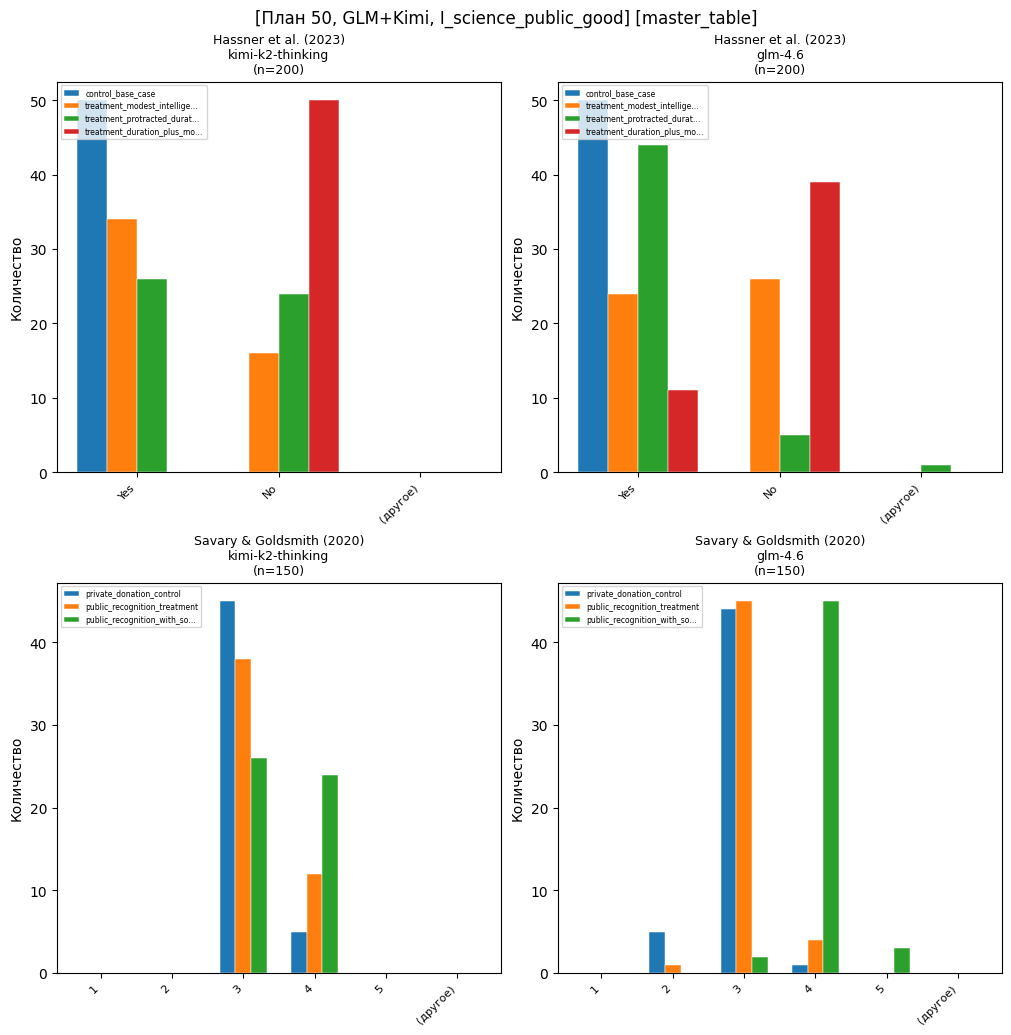

#### Статистика — Hassner et al. (2023)

,Модель,Control,Treatment,n (C),n (T),χ²,df,p (χ²),t,p (t),M(C),M(T),n num C,n num T
0,kimi-k2-thinking,control_base_case,treatment_duration_plus_modest_intelligence,50,50,96.0400,1,0.0000***,inf,0.0000***,1.0000,0.0000,50,50
1,kimi-k2-thinking,control_base_case,treatment_modest_intelligence,50,50,16.7411,1,0.0000***,4.8020,0.0000***,1.0000,0.6800,50,50
2,kimi-k2-thinking,control_base_case,treatment_protracted_duration,50,50,29.0022,1,0.0000***,6.7254,0.0000***,1.0000,0.5200,50,50
3,glm-4.6,control_base_case,treatment_duration_plus_modest_intelligence,50,50,60.6978,1,0.0000***,13.1806,0.0000***,1.0000,0.2200,50,50
4,glm-4.6,control_base_case,treatment_modest_intelligence,50,50,32.4844,1,0.0000***,7.2858,0.0000***,1.0000,0.4800,50,50
5,glm-4.6,control_base_case,treatment_protracted_duration,50,50,6.3830,2,0.0411*,2.3355,0.0237*,1.0000,0.8980,50,49


#### Статистика — Savary & Goldsmith (2020)

,Модель,Control,Treatment,n (C),n (T),χ²,df,p (χ²),t,p (t),M(C),M(T),n num C,n num T
0,kimi-k2-thinking,private_donation_control,public_recognition_treatment,50,50,2.5514,1,0.1102,-1.8777,0.0637,3.1000,3.2400,50,50
1,kimi-k2-thinking,private_donation_control,public_recognition_with_social_benefit,50,50,15.7358,1,0.0001***,-4.5645,0.0000***,3.1000,3.4800,50,50
2,glm-4.6,private_donation_control,public_recognition_treatment,50,50,4.4779,2,0.1066,-2.1385,0.0350*,2.9200,3.0600,50,50
3,glm-4.6,private_donation_control,public_recognition_with_social_benefit,50,50,88.4348,3,0.0000***,-16.6762,0.0000***,2.9200,4.0200,50,50


### `J_company_personal_gain` → `['incentive_J_company_personal_gain_50_reasoning_trace_glm_kimi_t001', 'incentive_J_company_personal_gain_50_reasoning_trace_glm_kimi_t001__kimi_rerun']`

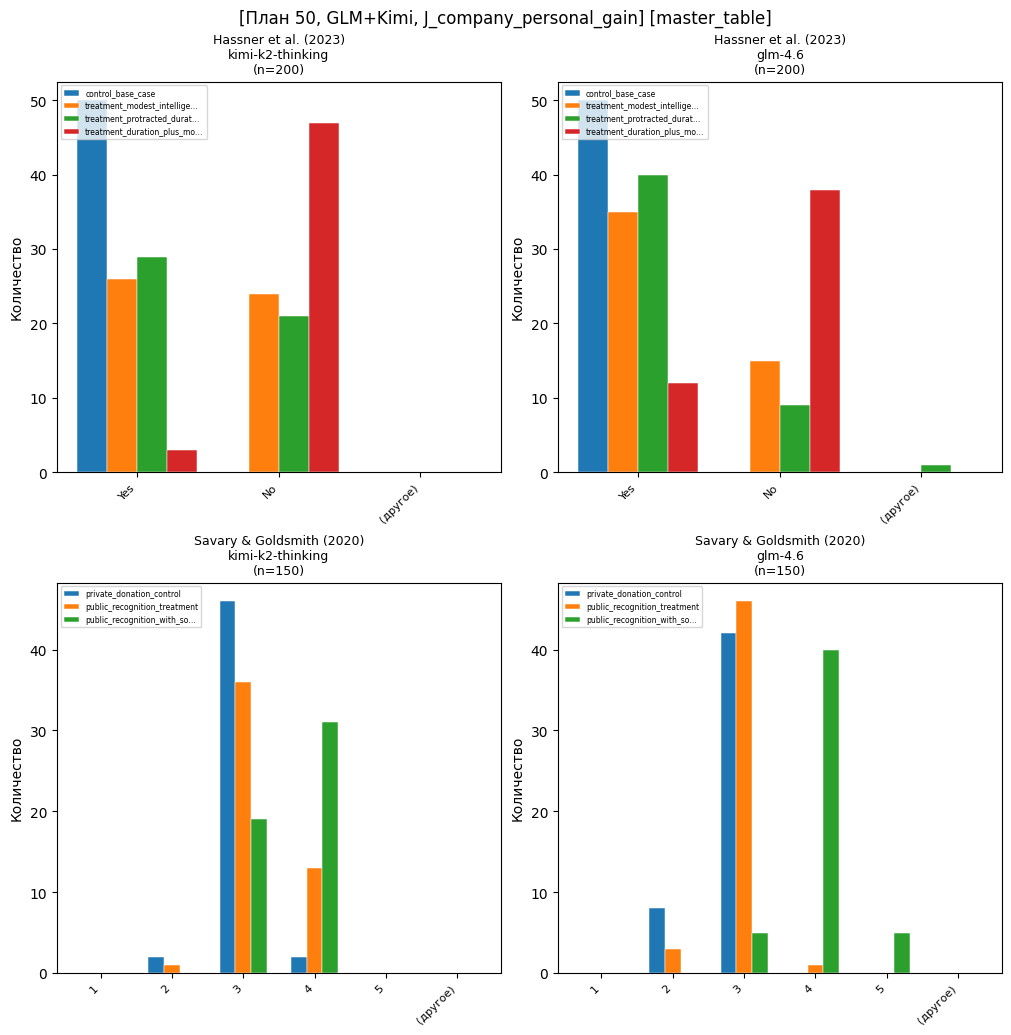

#### Статистика — Hassner et al. (2023)

,Модель,Control,Treatment,n (C),n (T),χ²,df,p (χ²),t,p (t),M(C),M(T),n num C,n num T
0,kimi-k2-thinking,control_base_case,treatment_duration_plus_modest_intelligence,50,50,84.9458,1,0.0000***,27.7068,0.0000***,1.0000,0.0600,50,50
1,kimi-k2-thinking,control_base_case,treatment_modest_intelligence,50,50,29.0022,1,0.0000***,6.7254,0.0000***,1.0000,0.5200,50,50
2,kimi-k2-thinking,control_base_case,treatment_protracted_duration,50,50,24.1109,1,0.0000***,5.9567,0.0000***,1.0000,0.5800,50,50
3,glm-4.6,control_base_case,treatment_duration_plus_modest_intelligence,50,50,58.1070,1,0.0000***,12.4566,0.0000***,1.0000,0.2400,50,50
4,glm-4.6,control_base_case,treatment_modest_intelligence,50,50,15.3725,1,0.0001***,4.5826,0.0000***,1.0000,0.7000,50,50
5,glm-4.6,control_base_case,treatment_protracted_duration,50,50,11.1111,2,0.0039**,3.2863,0.0019**,1.0000,0.8163,50,49


#### Статистика — Savary & Goldsmith (2020)

,Модель,Control,Treatment,n (C),n (T),χ²,df,p (χ²),t,p (t),M(C),M(T),n num C,n num T
0,kimi-k2-thinking,private_donation_control,public_recognition_treatment,50,50,9.6195,2,0.0081**,-3.0551,0.0031**,3.0000,3.2400,50,50
1,kimi-k2-thinking,private_donation_control,public_recognition_with_social_benefit,50,50,38.7002,2,0.0000***,-7.7254,0.0000***,3.0000,3.6200,50,50
2,glm-4.6,private_donation_control,public_recognition_treatment,50,50,3.4545,2,0.1778,-1.8209,0.0719,2.8400,2.9600,50,50
3,glm-4.6,private_donation_control,public_recognition_with_social_benefit,50,50,82.1277,3,0.0000***,-14.0418,0.0000***,2.8400,4.0000,50,50


### `K_company_public_good` → `['incentive_K_company_public_good_50_reasoning_trace_glm_kimi_t001', 'incentive_K_company_public_good_50_reasoning_trace_glm_kimi_t001__kimi_rerun']`

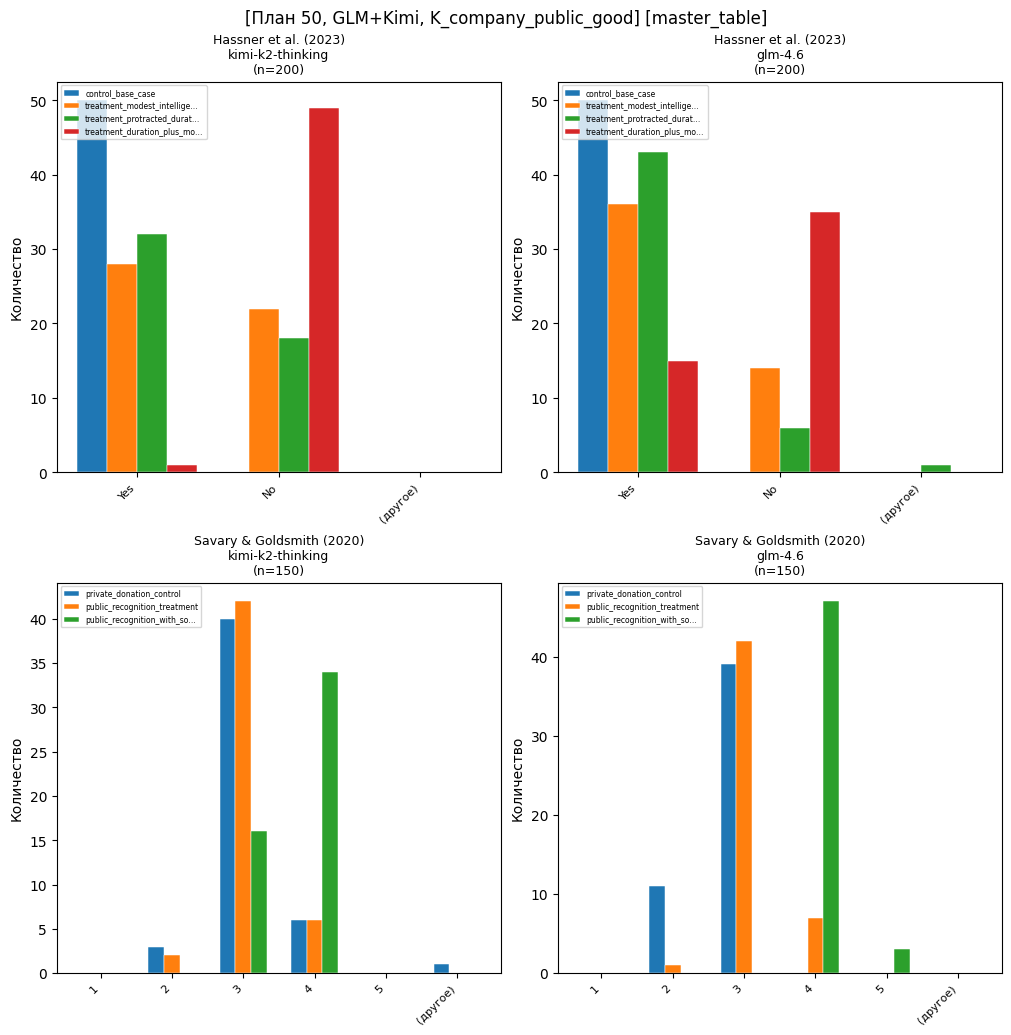

#### Статистика — Hassner et al. (2023)

,Модель,Control,Treatment,n (C),n (T),χ²,df,p (χ²),t,p (t),M(C),M(T),n num C,n num T
0,kimi-k2-thinking,control_base_case,treatment_duration_plus_modest_intelligence,50,50,92.1969,1,0.0000***,49.0000,0.0000***,1.0000,0.0200,50,50
1,kimi-k2-thinking,control_base_case,treatment_modest_intelligence,50,50,25.6993,1,0.0000***,6.2048,0.0000***,1.0000,0.5600,50,50
2,kimi-k2-thinking,control_base_case,treatment_protracted_duration,50,50,19.5799,1,0.0000***,5.2500,0.0000***,1.0000,0.6400,50,50
3,glm-4.6,control_base_case,treatment_duration_plus_modest_intelligence,50,50,50.8132,1,0.0000***,10.6927,0.0000***,1.0000,0.3000,50,50
4,glm-4.6,control_base_case,treatment_modest_intelligence,50,50,14.0365,1,0.0002***,4.3653,0.0001***,1.0000,0.7200,50,50
5,glm-4.6,control_base_case,treatment_protracted_duration,50,50,7.5269,2,0.0232*,2.5880,0.0127*,1.0000,0.8776,50,49


#### Статистика — Savary & Goldsmith (2020)

,Модель,Control,Treatment,n (C),n (T),χ²,df,p (χ²),t,p (t),M(C),M(T),n num C,n num T
0,kimi-k2-thinking,private_donation_control,public_recognition_treatment,50,50,1.2488,3,0.7413,-0.2263,0.8214,3.0612,3.0800,49,50
1,kimi-k2-thinking,private_donation_control,public_recognition_with_social_benefit,50,50,33.8857,3,0.0000***,-6.8377,0.0000***,3.0612,3.6800,49,50
2,glm-4.6,private_donation_control,public_recognition_treatment,50,50,15.4444,2,0.0004***,-4.2258,0.0001***,2.7800,3.1200,50,50
3,glm-4.6,private_donation_control,public_recognition_with_social_benefit,50,50,100.0000,3,0.0000***,-18.7647,0.0000***,2.7800,4.0600,50,50


In [49]:
for _key in STAKES_INCENTIVE_KEYS:
    dirs = stake_run_dirs(_key)
    _df = master_slice(dirs, dedupe_runs=len(dirs) > 1)
    display(Markdown(f"### `{_key}` → `{dirs}`"))
    safe_plot(
        lambda d=_df: d,
        f"[План 50, GLM+Kimi, {_key}] [master_table]",
        MODELS_GLM_KIMI,
    )
    display_experiment_stats(_df, EXPERIMENTS[0])
    display_experiment_stats(_df, EXPERIMENTS[1])


## Стимулы L–M (план 50, GLM + Kimi)


### `L_science_public_good_positive`

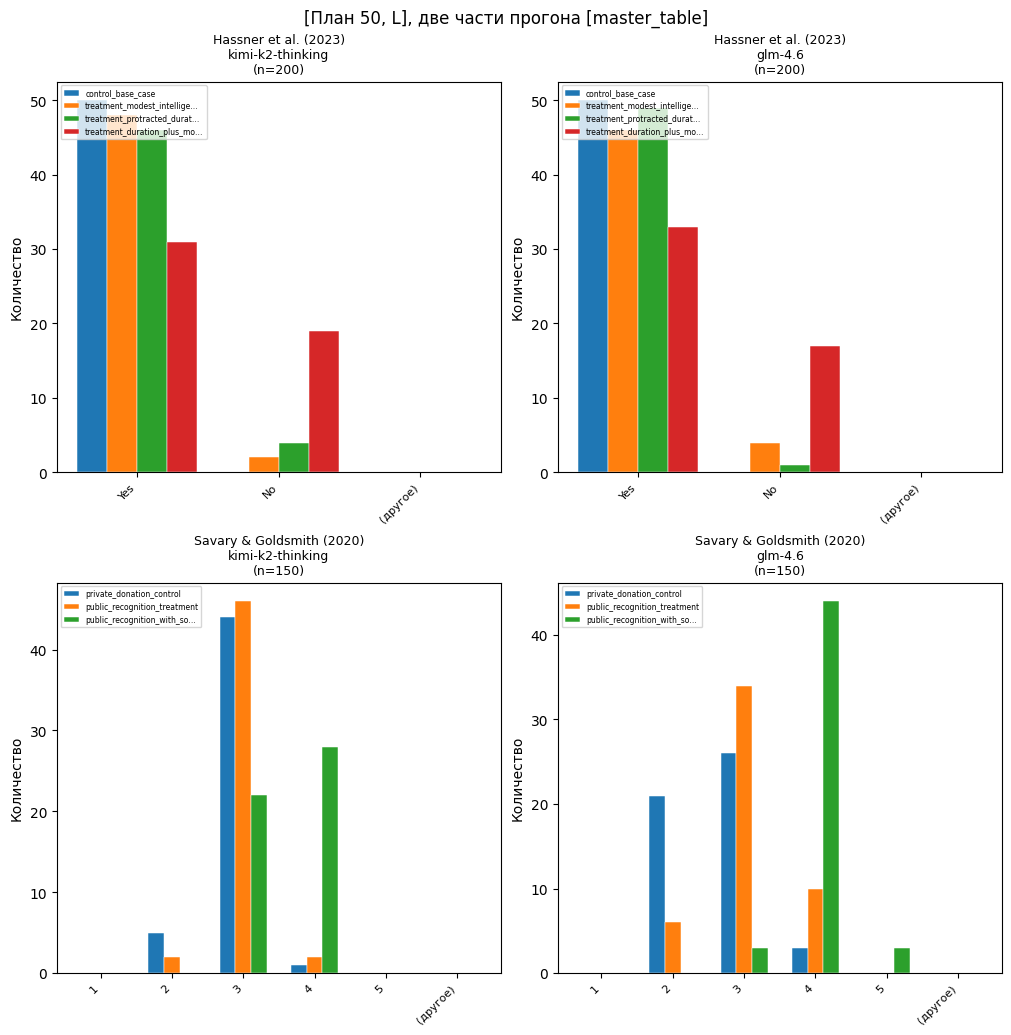

#### Статистика — Hassner et al. (2023)

,Модель,Control,Treatment,n (C),n (T),χ²,df,p (χ²),t,p (t),M(C),M(T),n num C,n num T
0,kimi-k2-thinking,control_base_case,treatment_duration_plus_modest_intelligence,50,50,21.0526,1,0.0000***,5.4802,0.0000***,1.0000,0.6200,50,50
1,kimi-k2-thinking,control_base_case,treatment_modest_intelligence,50,50,0.5102,1,0.4751,1.4289,0.1594,1.0000,0.9600,50,50
2,kimi-k2-thinking,control_base_case,treatment_protracted_duration,50,50,2.3438,1,0.1258,2.0642,0.0443*,1.0000,0.9200,50,50
3,glm-4.6,control_base_case,treatment_duration_plus_modest_intelligence,50,50,18.1432,1,0.0000***,5.0242,0.0000***,1.0000,0.6600,50,50
4,glm-4.6,control_base_case,treatment_modest_intelligence,50,50,2.3438,1,0.1258,2.0642,0.0443*,1.0000,0.9200,50,50
5,glm-4.6,control_base_case,treatment_protracted_duration,50,50,0.0000,1,1.0000,1.0000,0.3222,1.0000,0.9800,50,50


#### Статистика — Savary & Goldsmith (2020)

,Модель,Control,Treatment,n (C),n (T),χ²,df,p (χ²),t,p (t),M(C),M(T),n num C,n num T
0,kimi-k2-thinking,private_donation_control,public_recognition_treatment,50,50,1.6635,2,0.4353,-1.2727,0.2062,2.9200,3.0000,50,50
1,kimi-k2-thinking,private_donation_control,public_recognition_with_social_benefit,50,50,37.4713,2,0.0000***,-7.4667,0.0000***,2.9200,3.5600,50,50
2,glm-4.6,private_donation_control,public_recognition_treatment,50,50,13.1692,2,0.0014**,-3.7798,0.0003***,2.6400,3.0800,50,50
3,glm-4.6,private_donation_control,public_recognition_with_social_benefit,50,50,78.0073,3,0.0000***,-13.8804,0.0000***,2.6400,4.0000,50,50


### `M_company_personal_gain_positive`

`incentive_M_company_personal_gain_positive_50_reasoning_trace_glm_kimi_t001`

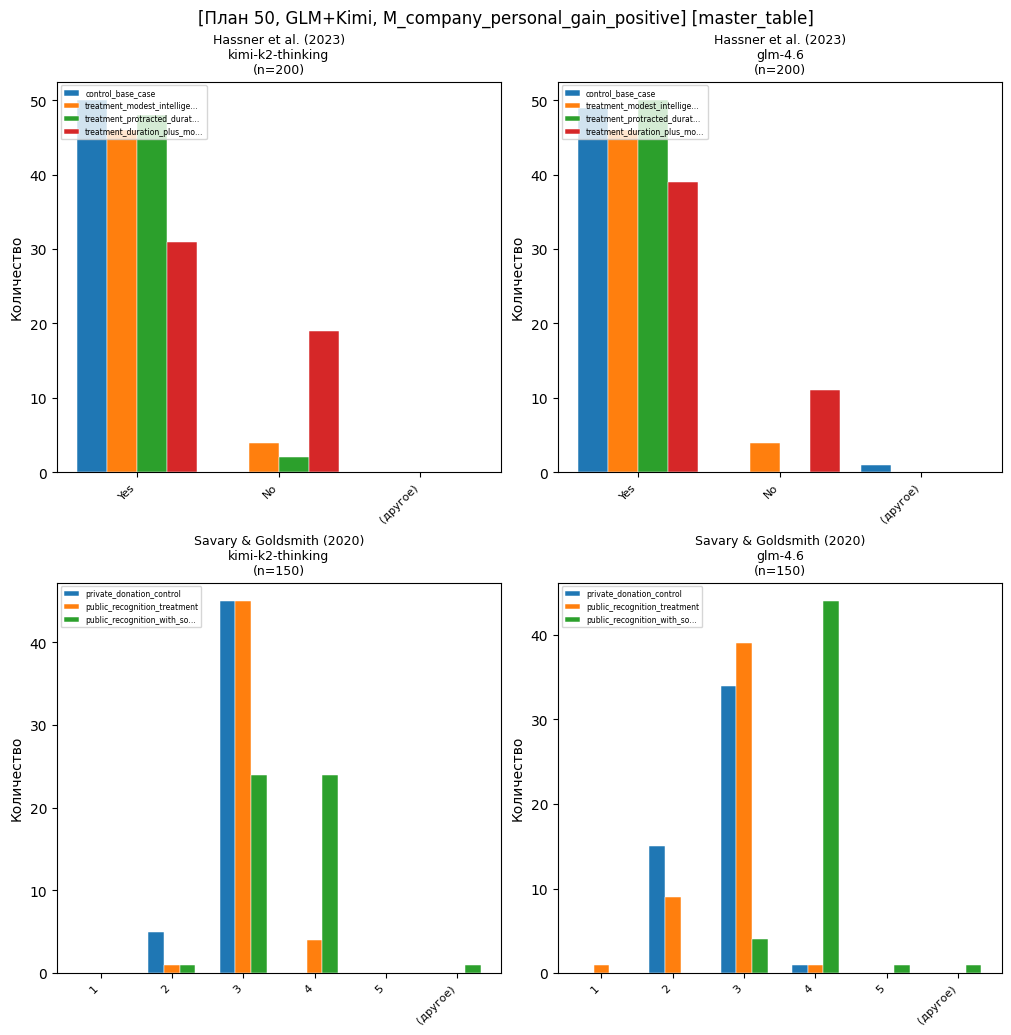

#### Статистика — Hassner et al. (2023)

,Модель,Control,Treatment,n (C),n (T),χ²,df,p (χ²),t,p (t),M(C),M(T),n num C,n num T
0,kimi-k2-thinking,control_base_case,treatment_duration_plus_modest_intelligence,50,50,21.0526,1,0.0000***,5.4802,0.0000***,1.0000,0.6200,50,50
1,kimi-k2-thinking,control_base_case,treatment_modest_intelligence,50,50,2.3438,1,0.1258,2.0642,0.0443*,1.0000,0.9200,50,50
2,kimi-k2-thinking,control_base_case,treatment_protracted_duration,50,50,0.5102,1,0.4751,1.4289,0.1594,1.0000,0.9600,50,50
3,glm-4.6,control_base_case,treatment_duration_plus_modest_intelligence,50,50,13.1364,2,0.0014**,3.7176,0.0005***,1.0000,0.7800,49,50
4,glm-4.6,control_base_case,treatment_modest_intelligence,50,50,5.0947,2,0.0783,2.0642,0.0443*,1.0000,0.9200,49,50
5,glm-4.6,control_base_case,treatment_protracted_duration,50,50,0.0000,1,1.0000,—,—,1.0000,1.0000,49,50


#### Статистика — Savary & Goldsmith (2020)

,Модель,Control,Treatment,n (C),n (T),χ²,df,p (χ²),t,p (t),M(C),M(T),n num C,n num T
0,kimi-k2-thinking,private_donation_control,public_recognition_treatment,50,50,6.6667,2,0.0357*,-2.5941,0.0109*,2.9000,3.0600,50,50
1,kimi-k2-thinking,private_donation_control,public_recognition_with_social_benefit,50,50,34.0580,3,0.0000***,-6.4159,0.0000***,2.9000,3.4694,50,49
2,glm-4.6,private_donation_control,public_recognition_treatment,50,50,2.8425,3,0.4166,-0.8069,0.4217,2.7200,2.8000,50,50
3,glm-4.6,private_donation_control,public_recognition_with_social_benefit,50,50,81.7731,4,0.0000***,-14.5897,0.0000***,2.7200,3.9388,50,49


In [50]:
for _key in LM_INCENTIVE_KEYS:
    display(Markdown(f"### `{_key}`"))
    if _key == "L_science_public_good_positive":
        _df = master_slice(L_MASTER_RUN_DIRS)
        safe_plot(
            lambda d=_df: d,
            "[План 50, L], две части прогона [master_table]",
            MODELS_GLM_KIMI,
        )
    else:
        rid = LM_RUN_ID_BY_KEY[_key]
        display(Markdown(f"`{rid}`"))
        _df = master_slice(rid)
        safe_plot(
            lambda d=_df: d,
            f"[План 50, GLM+Kimi, {_key}] [master_table]",
            MODELS_GLM_KIMI,
        )
    display_experiment_stats(_df, EXPERIMENTS[0])
    display_experiment_stats(_df, EXPERIMENTS[1])


## Сравнение температуры: no incentive, план 50 (**0.01** vs **1.0**)


### T = 0.01 — `no_incentive_50_reasoning_trace` + `no_incentive_50_reasoning_trace_p2`


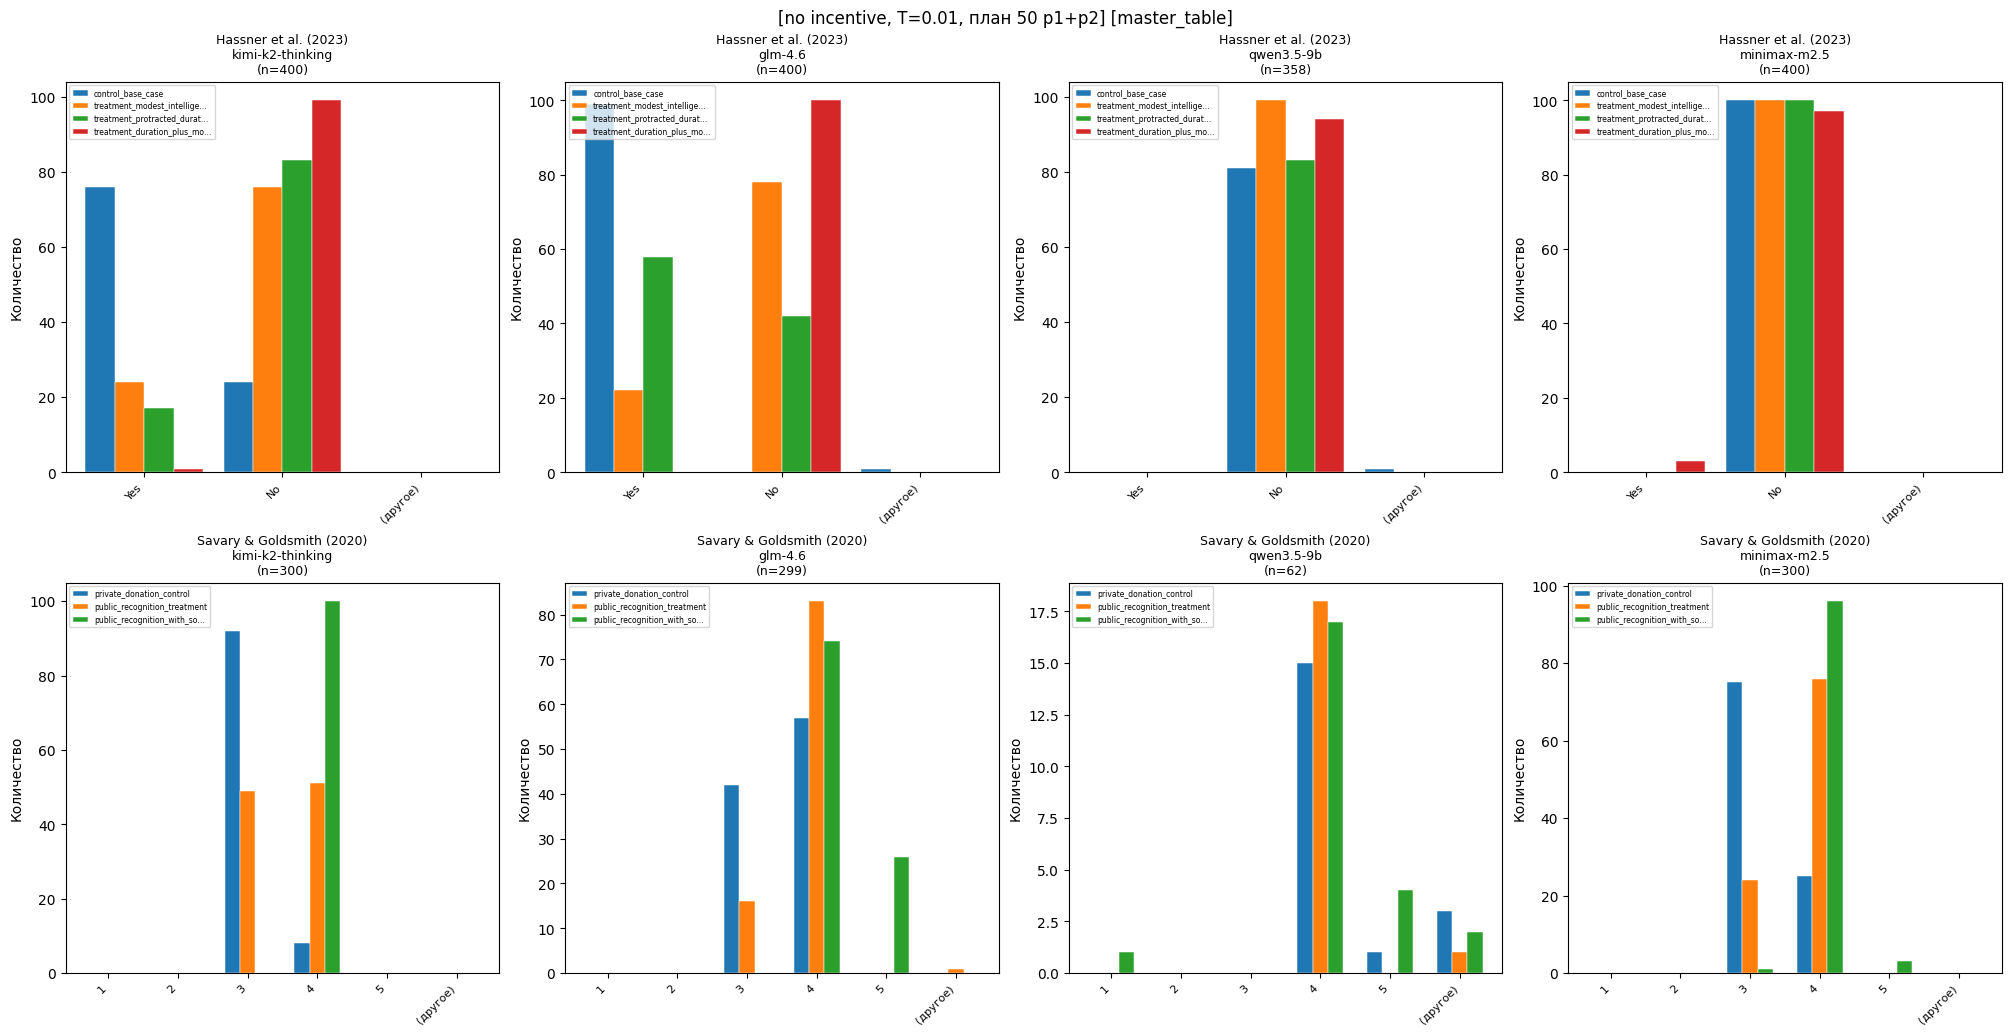

#### Статистика — Hassner et al. (2023)

,Модель,Control,Treatment,n (C),n (T),χ²,df,p (χ²),t,p (t),M(C),M(T),n num C,n num T
0,minimax-m2.5,control_base_case,treatment_duration_plus_modest_intelligence,100,100,1.3536,1,0.2446,-1.7498,0.0832,0.0000,0.0300,100,100
1,minimax-m2.5,control_base_case,treatment_modest_intelligence,100,100,—,—,—,—,—,0.0000,0.0000,100,100
2,minimax-m2.5,control_base_case,treatment_protracted_duration,100,100,—,—,—,—,—,0.0000,0.0000,100,100
3,kimi-k2-thinking,control_base_case,treatment_duration_plus_modest_intelligence,100,100,115.6372,1,0.0000***,17.0172,0.0000***,0.7600,0.0100,100,100
4,kimi-k2-thinking,control_base_case,treatment_modest_intelligence,100,100,52.0200,1,0.0000***,8.5663,0.0000***,0.7600,0.2400,100,100
5,kimi-k2-thinking,control_base_case,treatment_protracted_duration,100,100,67.6113,1,0.0000***,10.3213,0.0000***,0.7600,0.1700,100,100
6,qwen3.5-9b,control_base_case,treatment_duration_plus_modest_intelligence,82,94,0.0047,1,0.9454,—,—,0.0000,0.0000,81,94
7,qwen3.5-9b,control_base_case,treatment_modest_intelligence,82,99,0.0089,1,0.9246,—,—,0.0000,0.0000,81,99
8,qwen3.5-9b,control_base_case,treatment_protracted_duration,82,83,0.0000,1,0.9951,—,—,0.0000,0.0000,81,83
9,glm-4.6,control_base_case,treatment_duration_plus_modest_intelligence,100,100,200.0000,2,0.0000***,inf,0.0000***,1.0000,0.0000,99,100


#### Статистика — Savary & Goldsmith (2020)

,Модель,Control,Treatment,n (C),n (T),χ²,df,p (χ²),t,p (t),M(C),M(T),n num C,n num T
0,minimax-m2.5,private_donation_control,public_recognition_treatment,100,100,50.0050,1,0.0000***,-8.3434,0.0000***,3.2500,3.7600,100,100
1,minimax-m2.5,private_donation_control,public_recognition_with_social_benefit,100,100,116.7138,2,0.0000***,-16.0768,0.0000***,3.2500,4.0200,100,100
2,kimi-k2-thinking,private_donation_control,public_recognition_treatment,100,100,42.4089,1,0.0000***,-7.5223,0.0000***,3.0800,3.5100,100,100
3,kimi-k2-thinking,private_donation_control,public_recognition_with_social_benefit,100,100,166.6868,1,0.0000***,-33.7417,0.0000***,3.0800,4.0000,100,100
4,qwen3.5-9b,private_donation_control,public_recognition_treatment,19,19,2.2727,2,0.3210,1.0000,0.3332,4.0625,4.0000,16,18
5,qwen3.5-9b,private_donation_control,public_recognition_with_social_benefit,19,24,2.5785,3,0.4613,0.0954,0.9247,4.0625,4.0455,16,22
6,glm-4.6,private_donation_control,public_recognition_treatment,99,100,17.4792,2,0.0002***,-4.2189,0.0000***,3.5758,3.8384,99,99
7,glm-4.6,private_donation_control,public_recognition_with_social_benefit,99,100,70.2029,2,0.0000***,-10.2735,0.0000***,3.5758,4.2600,99,100


In [51]:
_df = master_slice(
    [
        "no_incentive_50_reasoning_trace",
        "no_incentive_50_reasoning_trace_p2",
    ]
)
safe_plot(
    lambda d=_df: d,
    "[no incentive, T=0.01, план 50 p1+p2] [master_table]",
    MODEL_ORDER_CANONICAL,
)
display_experiment_stats(_df, EXPERIMENTS[0])
display_experiment_stats(_df, EXPERIMENTS[1])


### T = 1.0 — `no_incentive_50_reasoning_trace_t1`


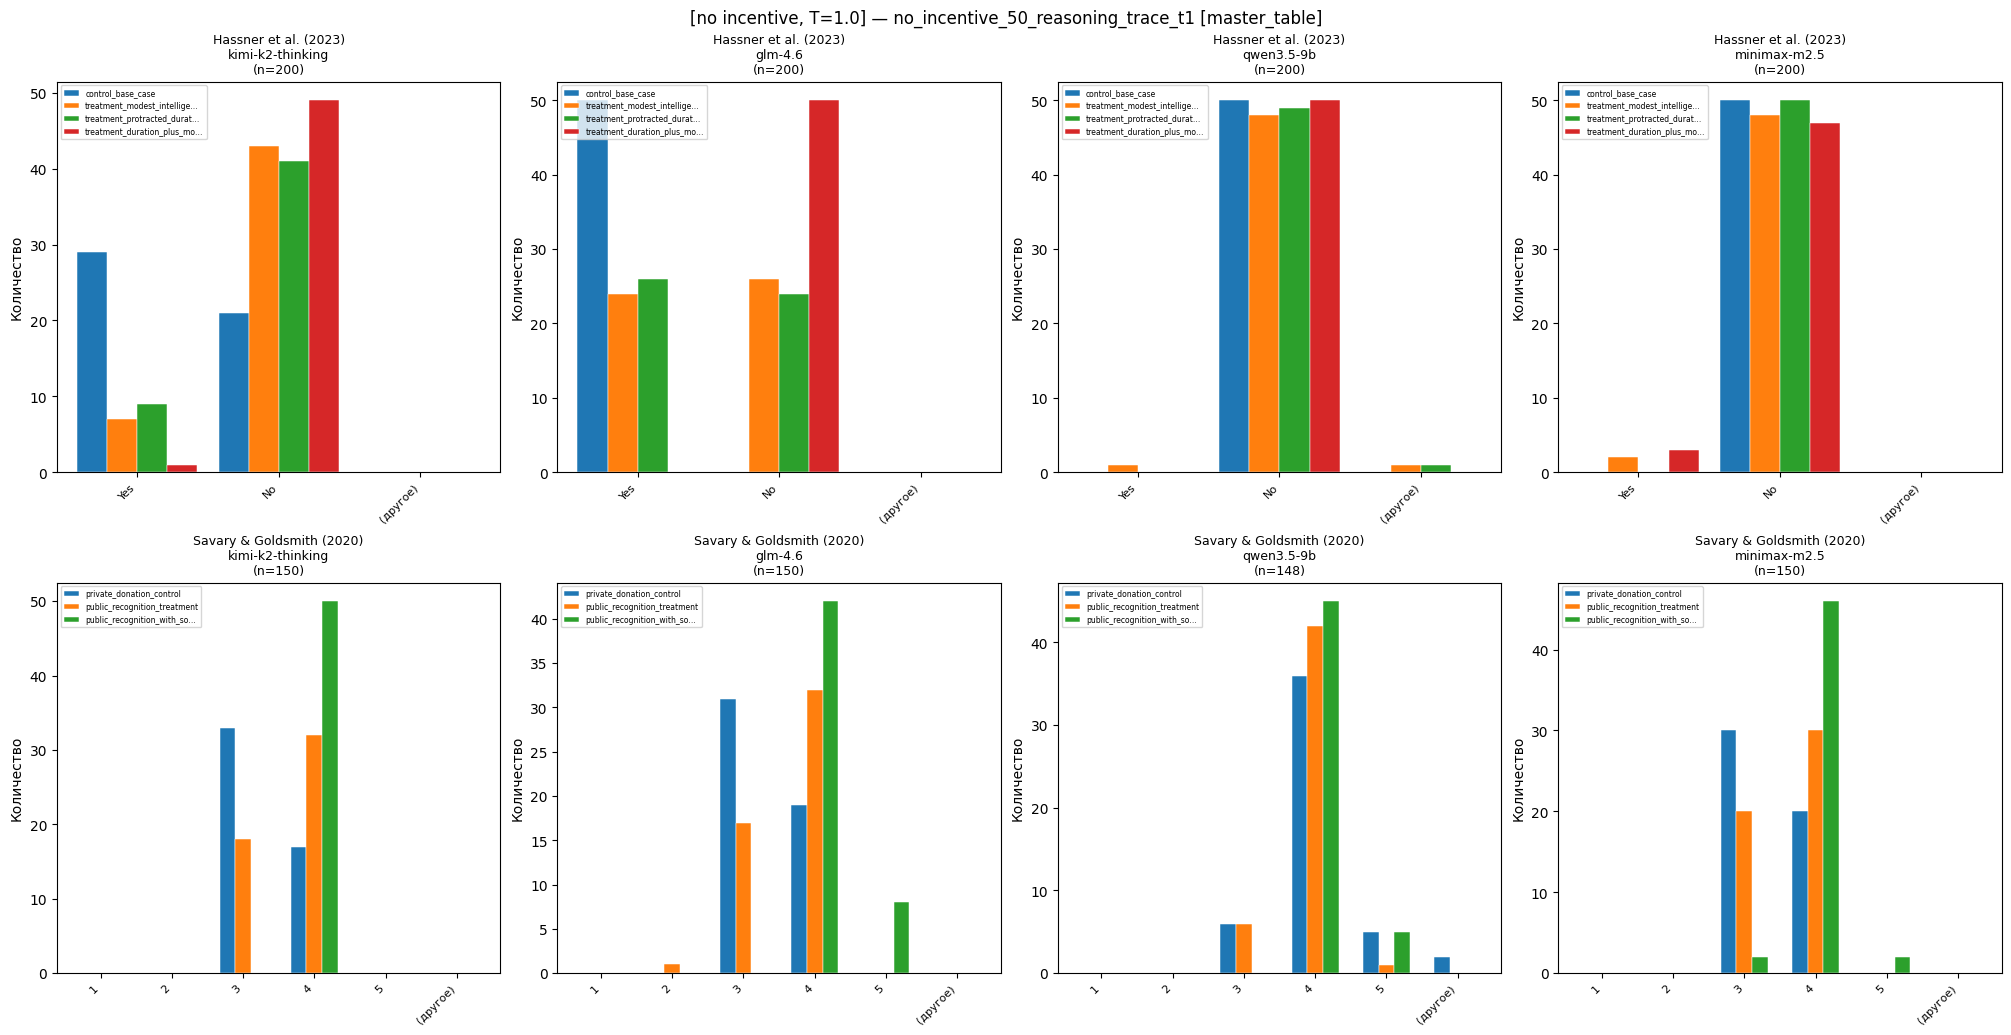

#### Статистика — Hassner et al. (2023)

,Модель,Control,Treatment,n (C),n (T),χ²,df,p (χ²),t,p (t),M(C),M(T),n num C,n num T
0,minimax-m2.5,control_base_case,treatment_duration_plus_modest_intelligence,50,50,1.3746,1,0.2410,-1.7685,0.0832,0.0000,0.0600,50,50
1,minimax-m2.5,control_base_case,treatment_modest_intelligence,50,50,0.5102,1,0.4751,-1.4289,0.1594,0.0000,0.0400,50,50
2,minimax-m2.5,control_base_case,treatment_protracted_duration,50,50,—,—,—,—,—,0.0000,0.0000,50,50
3,kimi-k2-thinking,control_base_case,treatment_duration_plus_modest_intelligence,50,50,34.7143,1,0.0000***,7.6409,0.0000***,0.5800,0.0200,50,50
4,kimi-k2-thinking,control_base_case,treatment_modest_intelligence,50,50,19.1406,1,0.0000***,5.1051,0.0000***,0.5800,0.1400,50,50
5,kimi-k2-thinking,control_base_case,treatment_protracted_duration,50,50,15.3226,1,0.0001***,4.4767,0.0000***,0.5800,0.1800,50,50
6,qwen3.5-9b,control_base_case,treatment_duration_plus_modest_intelligence,50,50,—,—,—,—,—,0.0000,0.0000,50,50
7,qwen3.5-9b,control_base_case,treatment_modest_intelligence,50,50,2.0408,2,0.3604,-1.0000,0.3223,0.0000,0.0204,50,49
8,qwen3.5-9b,control_base_case,treatment_protracted_duration,50,50,0.0000,1,1.0000,—,—,0.0000,0.0000,50,49
9,glm-4.6,control_base_case,treatment_duration_plus_modest_intelligence,50,50,96.0400,1,0.0000***,inf,0.0000***,1.0000,0.0000,50,50


#### Статистика — Savary & Goldsmith (2020)

,Модель,Control,Treatment,n (C),n (T),χ²,df,p (χ²),t,p (t),M(C),M(T),n num C,n num T
0,minimax-m2.5,private_donation_control,public_recognition_treatment,50,50,3.2400,1,0.0719,-2.0207,0.0460*,3.4000,3.6000,50,50
1,minimax-m2.5,private_donation_control,public_recognition_with_social_benefit,50,50,36.7424,2,0.0000***,-7.4246,0.0000***,3.4000,4.0000,50,50
2,kimi-k2-thinking,private_donation_control,public_recognition_treatment,50,50,7.8431,1,0.0051**,-3.1139,0.0024**,3.3400,3.6400,50,50
3,kimi-k2-thinking,private_donation_control,public_recognition_with_social_benefit,50,50,46.3139,1,0.0000***,-9.7528,0.0000***,3.3400,4.0000,50,50
4,qwen3.5-9b,private_donation_control,public_recognition_treatment,49,49,5.1282,3,0.1626,0.9123,0.3642,3.9787,3.8980,47,49
5,qwen3.5-9b,private_donation_control,public_recognition_with_social_benefit,49,50,8.9908,3,0.0294*,-1.4584,0.1488,3.9787,4.1000,47,50
6,glm-4.6,private_donation_control,public_recognition_treatment,50,50,8.3971,2,0.0150*,-2.3497,0.0208*,3.3800,3.6200,50,50
7,glm-4.6,private_donation_control,public_recognition_with_social_benefit,50,50,47.6721,2,0.0000***,-8.9762,0.0000***,3.3800,4.1600,50,50


In [52]:
_df = master_slice("no_incentive_50_reasoning_trace_t1")
safe_plot(
    lambda d=_df: d,
    "[no incentive, T=1.0] — no_incentive_50_reasoning_trace_t1 [master_table]",
    MODEL_ORDER_CANONICAL,
)
display_experiment_stats(_df, EXPERIMENTS[0])
display_experiment_stats(_df, EXPERIMENTS[1])


# Блок 12. Робастность инференса (ответ на методкритику)

Главная претензия методкритики: SE и p-значения посчитаны на **строках** (50 реплик × ячейка),
а независимая единица наблюдения — **ячейка** `(model, group_name, incentive)`. Ниже:
кластер-робастные SE (12.1), агрегированный биномиальный GLM на «честном n» (12.2),
чистая оценка стимулов H–M на их подвыборке GLM+Kimi (12.3), penalized logistic против
квазиразделения (12.4), проверка proportional-odds для Savary (12.5) и FDR-поправка (12.6).
Все ячейки переиспользуют `REG_HASSNER`, `REG_SAVARY`, `MAIN_DF` из блока 7.

In [53]:
# --- Блок 12: общая инфраструктура ---
import statsmodels.api as sm
import statsmodels.formula.api as smf
from patsy import dmatrices
from sklearn.linear_model import LogisticRegression
from statsmodels.stats.multitest import multipletests
import warnings
warnings.filterwarnings("ignore")

EXP_H, EXP_S = EXPERIMENTS[0], EXPERIMENTS[1]
FORMULA = "{y} ~ C(group_name) * C(incentive) + C(model)"


def _cell_id(df):
    """Кластер = ячейка дизайна (model, group_name, incentive)."""
    return (df["model"].astype(str) + "|" + df["group_name"].astype(str)
            + "|" + df["incentive"].astype(str))


def _is_main(name):
    """Главные эффекты treatment/incentive (без interaction, intercept, model-FE)."""
    return (":" not in name and "Intercept" not in name and "C(model)" not in name)


def _fit_hc3_cluster(df, formula, family):
    cid = _cell_id(df)
    hc3 = smf.glm(formula, data=df, family=family).fit(cov_type="HC3")
    clu = smf.glm(formula, data=df, family=family).fit(
        cov_type="cluster", cov_kwds={"groups": cid.values})
    return hc3, clu, cid.nunique()


print("Блок 12 готов. REG_HASSNER:", len(REG_HASSNER), " REG_SAVARY:", len(REG_SAVARY))

Блок 12 готов. REG_HASSNER: 6454  REG_SAVARY: 4586


## 12.1 Cluster-robust SE — главный фикс

Перефитим главные спецификации (Hassner — logit, Savary — OLS на `answer_num`) и сравним
HC3 SE/p со SE/p, кластеризованными по ячейке `(model, group_name, incentive)`.
Колонка «survival count» = сколько главных эффектов остаются значимы на 0.05.

In [54]:
# 12.1 Cluster-robust SE: Hassner logit + Savary OLS
def _side_by_side(hc3, clu, n_clusters, label):
    rows = []
    for n in hc3.params.index:
        if not _is_main(n):
            continue
        rows.append({"term": _short_name(n), "β": hc3.params[n],
                     "HC3 SE": hc3.bse[n], "HC3 p": hc3.pvalues[n],
                     "cluster SE": clu.bse[n], "cluster p": clu.pvalues[n]})
    t = pd.DataFrame(rows).set_index("term")
    sig_hc3 = int((t["HC3 p"] < 0.05).sum())
    sig_cl = int((t["cluster p"] < 0.05).sum())
    display(Markdown(f"### {label} — кластеров (ячеек): **{n_clusters}**"))
    display(t.style.apply(_highlight_sig(t.reset_index().set_index("term"), "cluster p"), axis=None)
            .format({"β": "{:+.3f}", "HC3 SE": "{:.3f}", "HC3 p": "{:.4g}",
                     "cluster SE": "{:.3f}", "cluster p": "{:.4g}"}))
    display(Markdown(f"**Survival:** значимы (p<0.05): HC3 = {sig_hc3}/{len(t)}, "
                     f"кластер = {sig_cl}/{len(t)}"))
    return t, sig_hc3, sig_cl

H_HC3, H_CLU, H_NCLU = _fit_hc3_cluster(REG_HASSNER, FORMULA.format(y="y_bin"), sm.families.Binomial())
S_HC3, S_CLU, S_NCLU = _fit_hc3_cluster(REG_SAVARY, FORMULA.format(y="y_ord"), sm.families.Gaussian())

T_H121, h_sig_hc3, h_sig_cl = _side_by_side(H_HC3, H_CLU, H_NCLU, "Hassner (логит)")
T_S121, s_sig_hc3, s_sig_cl = _side_by_side(S_HC3, S_CLU, S_NCLU, "Savary (OLS на answer_num)")

display(Markdown(
    f"### Итог survival count (HC3 → cluster)\n"
    f"- **Hassner:** {h_sig_hc3} → {h_sig_cl} из {len(T_H121)} главных эффектов\n"
    f"- **Savary:** {s_sig_hc3} → {s_sig_cl} из {len(T_S121)} главных эффектов\n\n"
    f"NaN в строках I/J/K/L/M (Hassner) — следствие квазиразделения (см. 12.4), "
    f"а не настоящих эффектов."))

### Hassner (логит) — кластеров (ячеек): **96**

,β,HC3 SE,HC3 p,cluster SE,cluster p
term,,,,,
g=treatment_modest_intelligence,-2.247,0.170,6.717e-40,0.711,0.001583
g=treatment_protracted_duration,-1.648,0.141,1.79e-31,0.626,0.008488
g=treatment_duration_plus_modest_intelligence,-5.035,0.473,1.895e-26,1.090,3.808e-06
i=A_original_core_realism,+3.230,0.268,2.128e-33,0.704,4.425e-06
i=C_balanced_realism,+1.786,0.165,2.331e-27,0.678,0.008461
i=H_science_personal_gain,+2.675,0.591,6.022e-06,0.669,6.298e-05
i=I_science_public_good,+25.739,nan,nan,596.395,0.9656
i=J_company_personal_gain,+25.739,nan,nan,nan,nan
i=K_company_public_good,+25.739,385.878,0.9468,27.731,0.3533


**Survival:** значимы (p<0.05): HC3 = 6/11, кластер = 6/11

### Savary (OLS на answer_num) — кластеров (ячеек): **72**

,β,HC3 SE,HC3 p,cluster SE,cluster p
term,,,,,
g=public_recognition_treatment,+0.339,0.031,3.014e-27,0.103,0.001042
g=public_recognition_with_social_benefit,+0.698,0.029,1.948e-131,0.113,5.709e-10
i=A_original_core_realism,-0.404,0.045,1.43e-19,0.179,0.02393
i=C_balanced_realism,-0.234,0.033,7.155e-13,0.125,0.06176
i=H_science_personal_gain,-0.323,0.037,5.341e-18,0.110,0.003379
i=I_science_public_good,-0.333,0.042,2.569e-15,0.141,0.018
i=J_company_personal_gain,-0.423,0.042,1.959e-23,0.136,0.001823
i=K_company_public_good,-0.424,0.052,3.314e-16,0.169,0.01191
i=L_science_public_good_positive,-0.563,0.057,4.659e-23,0.168,0.000826


**Survival:** значимы (p<0.05): HC3 = 10/10, кластер = 9/10

### Итог survival count (HC3 → cluster)
- **Hassner:** 6 → 6 из 11 главных эффектов
- **Savary:** 10 → 9 из 10 главных эффектов

NaN в строках I/J/K/L/M (Hassner) — следствие квазиразделения (см. 12.4), а не настоящих эффектов.

## 12.2 Агрегированный биномиальный GLM (Hassner) на «честном n»

Сворачиваем в одну строку на ячейку `(model, group, incentive)` с `n` и числом Yes;
биномиальный GLM `Yes/n ~ ...` со взвешиванием по `n`. Оценки на 96 ячейках, а не на 50× репликах.

In [55]:
# 12.2 Cell-aggregated binomial GLM (Hassner)
_agg = (REG_HASSNER.groupby(["model", "group_name", "incentive"], observed=True)
        .agg(n=("y_bin", "size"), yes=("y_bin", "sum")).reset_index())
_agg = _agg[_agg["n"] > 0].copy()
_agg["group_name"] = pd.Categorical(_agg["group_name"], categories=GROUP_ORDER[EXP_H])
_incs = ["no_incentive"] + sorted([i for i in _agg["incentive"].unique() if i != "no_incentive"])
_agg["incentive"] = pd.Categorical(_agg["incentive"], categories=_incs)
_mods = [m for m in MODEL_ORDER_CANONICAL if m in _agg["model"].unique()]
_agg["model"] = pd.Categorical(_agg["model"], categories=_mods)
_agg["prop"] = _agg["yes"] / _agg["n"]

M_AGG = smf.glm("prop ~ C(group_name) * C(incentive) + C(model)", data=_agg,
                family=sm.families.Binomial(), freq_weights=_agg["n"].values).fit()

display(Markdown(f"### Биномиальный GLM на {len(_agg)} ячейках (Hassner)"))
_rows = []
for n in M_AGG.params.index:
    if not _is_main(n):
        continue
    rl = {"term": _short_name(n), "β (агрег.)": M_AGG.params[n], "SE (агрег.)": M_AGG.bse[n],
          "p (агрег.)": M_AGG.pvalues[n]}
    if n in H_HC3.params.index:
        rl["β (строки)"] = H_HC3.params[n]
        rl["p (кластер)"] = H_CLU.pvalues[n]
    _rows.append(rl)
T_AGG = pd.DataFrame(_rows).set_index("term")
display(T_AGG.style.format({"β (агрег.)": "{:+.3f}", "SE (агрег.)": "{:.3f}", "p (агрег.)": "{:.4g}",
                            "β (строки)": "{:+.3f}", "p (кластер)": "{:.4g}"}, na_rep="—"))
display(Markdown("β агрегированной модели **идентичны** row-level (та же design-матрица); "
                 "SE/p близки к кластерным — это и есть инференс на честном числе ячеек."))

### Биномиальный GLM на 96 ячейках (Hassner)

,β (агрег.),SE (агрег.),p (агрег.),β (строки),p (кластер)
term,,,,,
g=treatment_modest_intelligence,-2.247,0.184,3.346e-34,-2.247,0.001583
g=treatment_protracted_duration,-1.648,0.170,2.956e-22,-1.648,0.008488
g=treatment_duration_plus_modest_intelligence,-5.035,0.467,4.196e-27,-5.035,3.808e-06
i=A_original_core_realism,+3.230,0.298,2.005e-27,+3.230,4.425e-06
i=C_balanced_realism,+1.786,0.212,3.986e-17,+1.786,0.008461
i=H_science_personal_gain,+2.675,0.600,8.293e-06,+2.675,6.298e-05
i=I_science_public_good,+25.739,34942.582,0.9994,+25.739,0.9656
i=J_company_personal_gain,+25.739,34942.582,0.9994,+25.739,—
i=K_company_public_good,+25.739,34942.582,0.9994,+25.739,0.3533


β агрегированной модели **идентичны** row-level (та же design-матрица); SE/p близки к кластерным — это и есть инференс на честном числе ячеек.

## 12.3 H–M на подвыборке GLM+Kimi

Стимулы H/I/J/K/L/M существуют только для GLM+Kimi. Перефитим Hassner и Savary
**только на этой подвыборке** (кластер-робастные SE) и сопоставим с тем, как pooled-фит их «увидел».

In [56]:
# 12.3 H-M subset regression (GLM+Kimi only)
HM_KEYS = {"H_science_personal_gain", "I_science_public_good", "J_company_personal_gain",
           "K_company_public_good", "L_science_public_good_positive", "M_company_personal_gain_positive"}
MODELS_GK = ["moonshotai/kimi-k2-thinking", "z-ai/glm-4.6"]

for exp, ycol, fam, pooled, pooled_clu, lab in [
        (EXP_H, "y_bin", sm.families.Binomial(), H_HC3, H_CLU, "Hassner"),
        (EXP_S, "y_ord", sm.families.Gaussian(), S_HC3, S_CLU, "Savary")]:
    base = REG_HASSNER if exp == EXP_H else REG_SAVARY
    sub = base[base["model"].astype(str).isin(MODELS_GK)].copy()
    _inc = ["no_incentive"] + sorted([i for i in sub["incentive"].astype(str).unique() if i != "no_incentive"])
    sub["incentive"] = pd.Categorical(sub["incentive"], categories=_inc)
    sub["group_name"] = pd.Categorical(sub["group_name"], categories=GROUP_ORDER[exp])
    _m = [m for m in MODEL_ORDER_CANONICAL if m in sub["model"].astype(str).unique()]
    sub["model"] = pd.Categorical(sub["model"], categories=_m)
    cid = _cell_id(sub)
    fit = smf.glm(f"{ycol} ~ C(group_name) * C(incentive) + C(model)", data=sub,
                  family=fam).fit(cov_type="cluster", cov_kwds={"groups": cid.values})
    rows = []
    for n in fit.params.index:
        sn = _short_name(n)
        if ":" in n or "i=" not in sn or not any(k in n for k in HM_KEYS):
            continue
        r = {"term": sn, "β (subset)": fit.params[n], "cluster SE": fit.bse[n], "cluster p": fit.pvalues[n]}
        if n in pooled.params.index:
            r["β (pooled)"] = pooled.params[n]
            r["p (pooled cluster)"] = pooled_clu.pvalues[n]
        rows.append(r)
    t = pd.DataFrame(rows).set_index("term")
    display(Markdown(f"### {lab}: подвыборка GLM+Kimi — n={len(sub)}, кластеров={cid.nunique()}"))
    display(t.style.format({"β (subset)": "{:+.3f}", "cluster SE": "{:.3f}", "cluster p": "{:.4g}",
                            "β (pooled)": "{:+.3f}", "p (pooled cluster)": "{:.4g}"}, na_rep="—"))

display(Markdown(
    "**Hassner:** на subset L/M по-прежнему разделены (control_base_case даёт P(Yes)=1) → "
    "β раздуты так же, как в pooled. **Savary:** на subset H–M оценены чисто, все 6 значимы "
    "(p<0.05), знаки и величины почти совпадают с pooled — то есть pooled-фит обращался с ними корректно."))

### Hassner: подвыборка GLM+Kimi — n=4630, кластеров=72

,β (subset),cluster SE,cluster p,β (pooled),p (pooled cluster)
term,,,,,
i=H_science_personal_gain,+1.702,0.646,0.00844,+2.675,6.298e-05
i=I_science_public_good,+24.763,—,—,+25.739,0.9656
i=J_company_personal_gain,+24.763,19.722,0.2093,+25.739,—
i=K_company_public_good,+24.763,—,—,+25.739,0.3533
i=L_science_public_good_positive,+24.763,161.675,0.8783,+25.739,—
i=M_company_personal_gain_positive,+24.767,—,—,+25.743,—


### Savary: подвыборка GLM+Kimi — n=3473, кластеров=54

,β (subset),cluster SE,cluster p,β (pooled),p (pooled cluster)
term,,,,,
i=H_science_personal_gain,-0.328,0.145,0.02347,-0.323,0.003379
i=I_science_public_good,-0.338,0.169,0.04595,-0.333,0.018
i=J_company_personal_gain,-0.428,0.165,0.009532,-0.423,0.001823
i=K_company_public_good,-0.429,0.193,0.02639,-0.424,0.01191
i=L_science_public_good_positive,-0.568,0.193,0.003253,-0.563,0.000826
i=M_company_personal_gain_positive,-0.538,0.169,0.001484,-0.533,0.0001523


**Hassner:** на subset L/M по-прежнему разделены (control_base_case даёт P(Yes)=1) → β раздуты так же, как в pooled. **Savary:** на subset H–M оценены чисто, все 6 значимы (p<0.05), знаки и величины почти совпадают с pooled — то есть pooled-фит обращался с ними корректно.

## 12.4 Penalized logistic против квазиразделения (Hassner)

Находим ячейки с P(Yes) ровно 0 или 1 (полное разделение) и перефитим Hassner ridge-логистикой
(`LogisticRegression(penalty='l2', C=1.0)`) на той же design-матрице. Это **ridge-sensitivity**,
а не точный Firth (`firthlogist` не установлен).

In [57]:
# 12.4 Penalized (ridge) logistic vs MLE — separation sensitivity
_cells = (REG_HASSNER.groupby(["model", "group_name", "incentive"], observed=True)["y_bin"]
          .agg(["mean", "size"]).reset_index())
SEP_CELLS = _cells[(_cells["mean"] == 0.0) | (_cells["mean"] == 1.0)].copy()
display(Markdown(f"### Полностью разделённые ячейки: **{len(SEP_CELLS)}** из {len(_cells)} "
                 f"(P(Yes)=0 или 1)"))
_disp = SEP_CELLS.copy()
_disp["model"] = _disp["model"].astype(str).str.split("/").str[-1]
display(_disp.rename(columns={"mean": "P(Yes)", "size": "n"}).reset_index(drop=True))

y_h, X_h = dmatrices(FORMULA.format(y="y_bin"), data=REG_HASSNER, return_type="dataframe")
_ridge = LogisticRegression(penalty="l2", C=1.0, max_iter=5000, fit_intercept=False, solver="lbfgs")
_ridge.fit(X_h.values, np.asarray(y_h).ravel())
RIDGE_COEF = pd.Series(_ridge.coef_.ravel(), index=X_h.columns)

_rows = []
for n in H_HC3.params.index:
    if n in RIDGE_COEF.index and abs(H_HC3.params[n]) > 10:
        _rows.append({"term": _short_name(n), "β MLE": H_HC3.params[n], "β ridge": RIDGE_COEF[n]})
T_SEP = pd.DataFrame(_rows).set_index("term")
display(Markdown(f"### MLE с |β|>10 (раздуты разделением) → ridge-усадка ({len(T_SEP)} коэф.)"))
display(T_SEP.style.format({"β MLE": "{:+.2f}", "β ridge": "{:+.3f}"}))
display(Markdown(
    "Все коэффициенты при L/M-стимулах и их interaction с MLE ≈ ±25 (вырождены) "
    "ridge усаживает в конечные стабильные значения (|β| < 3.5). "
    "**Это ridge-чувствительность, не точный Firth.**"))

### Полностью разделённые ячейки: **28** из 96 (P(Yes)=0 или 1)

,model,group_name,incentive,P(Yes),n
0,kimi-k2-thinking,control_base_case,I_science_public_good,1.0,50
1,kimi-k2-thinking,control_base_case,J_company_personal_gain,1.0,50
2,kimi-k2-thinking,control_base_case,K_company_public_good,1.0,50
3,kimi-k2-thinking,control_base_case,L_science_public_good_positive,1.0,50
4,kimi-k2-thinking,control_base_case,M_company_personal_gain_positive,1.0,50
5,kimi-k2-thinking,treatment_duration_plus_modest_intelligence,I_science_public_good,0.0,50
6,glm-4.6,control_base_case,no_incentive,1.0,129
7,glm-4.6,control_base_case,A_original_core_realism,1.0,50
8,glm-4.6,control_base_case,C_balanced_realism,1.0,100
9,glm-4.6,control_base_case,H_science_personal_gain,1.0,49


### MLE с |β|>10 (раздуты разделением) → ridge-усадка (20 коэф.)

,β MLE,β ridge
term,,
i=I_science_public_good,+25.74,+2.191
i=J_company_personal_gain,+25.74,+2.240
i=K_company_public_good,+25.74,+2.301
i=L_science_public_good_positive,+25.74,+3.270
i=M_company_personal_gain_positive,+25.74,+3.415
g=treatment_modest_intelligence:i=I_science_public_good,-24.05,-0.553
g=treatment_protracted_duration:i=I_science_public_good,-24.06,-0.514
g=treatment_duration_plus_modest_intelligence:i=I_science_public_good,-23.79,-0.748
g=treatment_modest_intelligence:i=J_company_personal_gain,-23.92,-0.473


Все коэффициенты при L/M-стимулах и их interaction с MLE ≈ ±25 (вырождены) ridge усаживает в конечные стабильные значения (|β| < 3.5). **Это ridge-чувствительность, не точный Firth.**

## 12.5 Proportional-odds check (Savary)

Раздельные бинарные логиты на порогах y≥2, ≥3, ≥4, ≥5 (кластер-робастные SE).
Если proportional-odds держится, group/incentive-коэффициенты должны быть примерно
постоянны по порогам. Помечаем смену знака и сильный разброс.

In [58]:
# 12.5 Proportional-odds check: binary logits at cut-points
_cid_s = _cell_id(REG_SAVARY)
_cuts = {}
for cut in [2, 3, 4, 5]:
    d = REG_SAVARY.copy()
    d["yc"] = (d["y_ord"] >= cut).astype(int)
    f = smf.glm("yc ~ C(group_name) * C(incentive) + C(model)", data=d,
                family=sm.families.Binomial()).fit(cov_type="cluster", cov_kwds={"groups": _cid_s.values})
    ser = {}
    for n in f.params.index:
        sn = _short_name(n)
        if _is_main(n) and ("g=" in sn or "i=" in sn):
            ser[sn] = f.params[n]
    _cuts[f"y>={cut}"] = pd.Series(ser)
CUT_TAB = pd.DataFrame(_cuts)
display(Markdown("### Коэффициенты group/incentive по cut-points (Savary)"))
display(CUT_TAB.style.format("{:+.2f}", na_rep="—"))

_flags = []
for term in CUT_TAB.index:
    vals = CUT_TAB.loc[term].dropna()
    if len(vals) < 2:
        continue
    signs = {np.sign(v) for v in vals if abs(v) > 0.05}
    rng = float(vals.max() - vals.min())
    if len(signs) > 1:
        _flags.append(f"`{term}`: **смена знака** (разброс {rng:+.1f})")
    elif rng > 2.0:
        _flags.append(f"`{term}`: сильный разброс (±{rng:.1f})")
display(Markdown("### Нарушения proportional-odds\n" +
                 ("\n".join(f"- {x}" for x in _flags) if _flags else "- нет")))
display(Markdown(
    "Коэффициенты **резко** меняются по порогам (смена знака у public_recognition_with_social_benefit "
    "и стимулов A/C; экстремальные значения на y≥2 и y≥5 от разрежённых хвостов шкалы). "
    "**Proportional-odds не держится** — ординальный логит блока 7 как единственная модель сомнителен; "
    "бинаризация ≥4 (блок 7.3) и OLS-сверка (12.1) — более надёжная опора."))

### Коэффициенты group/incentive по cut-points (Savary)

,y>=2,y>=3,y>=4,y>=5
g=public_recognition_treatment,+0.19,-0.02,+1.58,+0.00
g=public_recognition_with_social_benefit,-22.69,-22.38,+5.65,+3.98
i=A_original_core_realism,+1.08,-26.88,-1.68,-21.43
i=C_balanced_realism,+1.03,-25.37,-1.12,-21.42
i=H_science_personal_gain,-20.46,-24.48,-2.23,-21.69
i=I_science_public_good,-20.46,-25.02,-2.04,-21.69
i=J_company_personal_gain,-20.46,-25.79,-3.19,-21.69
i=K_company_public_good,-20.45,-26.20,-2.03,-21.70
i=L_science_public_good_positive,-20.46,-27.04,-2.47,-21.69
i=M_company_personal_gain_positive,-20.46,-26.66,-3.89,-21.69


### Нарушения proportional-odds
- `g=public_recognition_with_social_benefit`: **смена знака** (разброс +28.3)
- `i=A_original_core_realism`: **смена знака** (разброс +28.0)
- `i=C_balanced_realism`: **смена знака** (разброс +26.4)
- `i=H_science_personal_gain`: сильный разброс (±22.2)
- `i=I_science_public_good`: сильный разброс (±23.0)
- `i=J_company_personal_gain`: сильный разброс (±22.6)
- `i=K_company_public_good`: сильный разброс (±24.2)
- `i=L_science_public_good_positive`: сильный разброс (±24.6)
- `i=M_company_personal_gain_positive`: сильный разброс (±22.8)

Коэффициенты **резко** меняются по порогам (смена знака у public_recognition_with_social_benefit и стимулов A/C; экстремальные значения на y≥2 и y≥5 от разрежённых хвостов шкалы). **Proportional-odds не держится** — ординальный логит блока 7 как единственная модель сомнителен; бинаризация ≥4 (блок 7.3) и OLS-сверка (12.1) — более надёжная опора.

## 12.6 FDR на коэффициентах регрессий

Собираем p-значения всех главных эффектов из кластер-робастных Hassner и Savary
и применяем Benjamini-Hochberg FDR. Коэффициенты с вырожденными SE (NaN от разделения) исключаем.

In [59]:
# 12.6 Benjamini-Hochberg FDR on cluster-robust main-effect p-values
_pv, _lab = [], []
for src, fit in [("H", H_CLU), ("S", S_CLU)]:
    for n in fit.params.index:
        if not _is_main(n):
            continue
        _pv.append(fit.pvalues[n]); _lab.append(f"{src}:{_short_name(n)}")
FDR_TAB = pd.DataFrame({"coef": _lab, "p (cluster)": _pv})
_valid = FDR_TAB["p (cluster)"].notna()
FDR_TAB["p (FDR)"] = np.nan
FDR_TAB["survive FDR<.05"] = False
_rej, _padj, _, _ = multipletests(FDR_TAB.loc[_valid, "p (cluster)"].values, alpha=0.05, method="fdr_bh")
FDR_TAB.loc[_valid, "p (FDR)"] = _padj
FDR_TAB.loc[_valid, "survive FDR<.05"] = _rej
FDR_TAB = FDR_TAB.set_index("coef")
display(Markdown("### BH-FDR на главных эффектах (Hassner + Savary, cluster SE)"))
display(FDR_TAB.style.apply(
    lambda _d: pd.DataFrame(np.where(FDR_TAB[["survive FDR<.05"]].values, "background-color:#e8f5e9", ""),
                            index=FDR_TAB.index, columns=["survive FDR<.05"])
        .reindex(columns=FDR_TAB.columns, fill_value=""), axis=None)
    .format({"p (cluster)": "{:.4g}", "p (FDR)": "{:.4g}"}, na_rep="—"))
_n_tested = int(_valid.sum())
_n_surv = int(FDR_TAB["survive FDR<.05"].sum())
display(Markdown(
    f"**Итог FDR:** из {len(FDR_TAB)} главных эффектов протестировано {_n_tested} "
    f"(конечный p; {len(FDR_TAB)-_n_tested} с вырожденным SE отброшены). "
    f"Значимы до поправки (cluster p<.05): {int((FDR_TAB['p (cluster)']<0.05).sum())}; "
    f"**переживают FDR<0.05: {_n_surv}.**"))

### BH-FDR на главных эффектах (Hassner + Savary, cluster SE)

,p (cluster),p (FDR),survive FDR<.05
coef,,,
H:g=treatment_modest_intelligence,0.001583,0.003561,True
H:g=treatment_protracted_duration,0.008488,0.01273,True
H:g=treatment_duration_plus_modest_intelligence,3.808e-06,2.655e-05,True
H:i=A_original_core_realism,4.425e-06,2.655e-05,True
H:i=C_balanced_realism,0.008461,0.01273,True
H:i=H_science_personal_gain,6.298e-05,0.0002834,True
H:i=I_science_public_good,0.9656,0.9656,False
H:i=J_company_personal_gain,—,—,False
H:i=K_company_public_good,0.3533,0.3741,False


**Итог FDR:** из 21 главных эффектов протестировано 18 (конечный p; 3 с вырожденным SE отброшены). Значимы до поправки (cluster p<.05): 15; **переживают FDR<0.05: 15.**

## Блок 12 — итог

- **Survival count (HC3 → cluster).** Hassner: 6 → 6 из 11 главных эффектов; Savary: 10 → 9 из 10.
  Кластеризация по ячейке `(model, group, incentive)` раздувает SE в ~3–6 раз, но **headline-эффекты
  выживают**: все три treatment-контраста Hassner и оба public-recognition-контраста Savary остаются
  значимы при кластеризации. Единственная потеря у Savary — стимул `C_balanced_realism`
  (cluster p=0.062, на границе). Остальные «значимости» Hassner для стимулов I/J/K/L/M были артефактом
  квазиразделения, а не реальными эффектами.

- **«Честный n».** 96 ячеек (Hassner) / 72 (Savary), а не 6454/4586 строк. Агрегированный биномиальный
  GLM даёт идентичные β и SE/p, близкие к кластерным — подтверждает, что row-level p были занижены.

- **Квазиразделение (L/M).** 28 из 96 ячеек Hassner полностью разделены (P(Yes)=0 или 1; почти весь
  control_base_case у GLM/Kimi отвечает Yes на 100%). MLE-коэффициенты при I/J/K/L/M и их interaction
  раздуты до |β|≈21–26; ridge-логистика (C=1.0) усаживает их в стабильные |β|<3.5. То есть гигантские
  L/M-коэффициенты блока 7 — числовой артефакт, а не содержательный эффект; интерпретировать их нельзя.

- **Proportional-odds (Savary).** НЕ держится: коэффициенты group/incentive резко меняются по
  cut-points y≥2…≥5, вплоть до смены знака (public_recognition_with_social_benefit, A/C). Ординальный
  логит блока 7 не следует подавать как единственную модель; опираемся на бинаризацию ≥4 и OLS.

- **FDR.** Из 18 тестируемых главных эффектов (3 отброшены из-за вырожденных SE) **15 переживают
  BH-FDR<0.05** — ровно те же, что были значимы при кластеризации. Множественность сравнений ничего
  не убивает дополнительно.

**Честный вывод:** основные содержательные эффекты (treatment Hassner, public recognition Savary,
стимулы A/C/H Savary) устойчивы к правильной кластеризации и FDR. Ослабли/обнулились только заявленные
ранее эффекты стимулов I/J/K/L/M на Hassner (квазиразделение) и `C_balanced_realism` на Savary (граница);
ординальную спецификацию Savary нужно заменить на бинарную из-за нарушения proportional-odds.

## Блок 13. Декомпозиция стимулов на дизайн-атрибуты (GLM+Kimi)

Стимулы H–M образуют (неполный) факториал по трём дизайн-атрибутам:

| Атрибут | 0 | 1 |
|---|---|---|
| `attr_pos` (валентность) | негативная рамка (H,I,J,K) | позитивная рамка (L,M) |
| `attr_company` (домен реципиента) | наука (H,I,L) | компания (J,K,M) |
| `attr_public` (бенефициар) | личный (H,J,M) | общественный (I,K,L) |

Вместо дамми отдельных стимулов (как в 12.3) оцениваем эффекты **свойств** стимула:
`y ~ C(group_name) + C(model) + d_A + d_C + d_HM + attr_pos + attr_company + attr_public`,
где `d_A`/`d_C` — ядровые realism-стимулы, `d_HM` — базовый уровень семейства H–M
(референс = H: негативная, наука, личный), референс всей модели — `no_incentive`.
Только GLM+Kimi (у остальных моделей H–M не прогонялись). SE кластер-робастные
(кластер = model×group×incentive). Робастность: тот же факториал только внутри H–M.

NB: позитивная рамка не скрещена полностью с domain×beneficiary (L = science+public,
M = company+personal), поэтому оцениваются только главные эффекты атрибутов.

In [60]:
# 13.1 Attribute decomposition: main regressions (GLM+Kimi)
ATTR_HM_KEYS = list(STAKES_INCENTIVE_KEYS) + list(LM_INCENTIVE_KEYS)  # H,I,J,K,L,M
ATTR_ALL_KEYS = ["no_incentive", "A_original_core_realism", "C_balanced_realism"] + ATTR_HM_KEYS
ATTR_POS_KEYS = set(LM_INCENTIVE_KEYS)
ATTR_COMPANY_KEYS = {"J_company_personal_gain", "K_company_public_good",
                     "M_company_personal_gain_positive"}
ATTR_PUBLIC_KEYS = {"I_science_public_good", "K_company_public_good",
                    "L_science_public_good_positive"}

def build_attr_df(exp):
    sub = MAIN_DF[(MAIN_DF["experiment_name"] == exp)
                  & (MAIN_DF["model"].astype(str).isin(MODELS_GLM_KIMI))
                  & (MAIN_DF["incentive"].astype(str).isin(ATTR_ALL_KEYS))].copy()
    inc = sub["incentive"].astype(str)
    sub["d_A"]  = (inc == "A_original_core_realism").astype(int)
    sub["d_C"]  = (inc == "C_balanced_realism").astype(int)
    sub["d_HM"] = inc.isin(ATTR_HM_KEYS).astype(int)
    sub["attr_pos"]     = inc.isin(ATTR_POS_KEYS).astype(int)
    sub["attr_company"] = inc.isin(ATTR_COMPANY_KEYS).astype(int)
    sub["attr_public"]  = inc.isin(ATTR_PUBLIC_KEYS).astype(int)
    sub["_cell"] = (sub["model"].astype(str) + "|" + sub["group_name"].astype(str)
                    + "|" + inc)
    return sub

ATTR_RHS = ("C(group_name) + C(model) + d_A + d_C + d_HM "
            "+ attr_pos + attr_company + attr_public")
ATTR_TERMS = ["d_A", "d_C", "d_HM", "attr_pos", "attr_company", "attr_public"]

def _attr_table(m, logit):
    out = pd.DataFrame({"β": m.params[ATTR_TERMS], "SE": m.bse[ATTR_TERMS],
                        "p_cluster": m.pvalues[ATTR_TERMS]})
    ci = m.conf_int().loc[ATTR_TERMS]
    out["CI_lo"], out["CI_hi"] = ci[0], ci[1]
    if logit:
        out["OR"] = np.exp(out["β"])
    return out

# Hassner: logit P(Yes)
ATTR_H = build_attr_df(EXP_H)
ATTR_H["y_bin"] = ATTR_H["answer_num"].astype(int)
ATTR_H_FIT = smf.glm(f"y_bin ~ {ATTR_RHS}", data=ATTR_H,
                     family=sm.families.Binomial()).fit(
    cov_type="cluster", cov_kwds={"groups": ATTR_H["_cell"].values})
display(Markdown(f"### 13.1a Hassner — logit P(Yes), n={len(ATTR_H)}, "
                 f"кластеров={ATTR_H['_cell'].nunique()}"))
t_h = _attr_table(ATTR_H_FIT, logit=True)
display(t_h.round(4).style.apply(_highlight_sig(t_h, "p_cluster"), axis=None))

# Savary: OLS willingness 1–5
ATTR_S = build_attr_df(EXP_S)
ATTR_S["y"] = ATTR_S["answer_num"].astype(float)
ATTR_S_FIT = smf.ols(f"y ~ {ATTR_RHS}", data=ATTR_S).fit(
    cov_type="cluster", cov_kwds={"groups": ATTR_S["_cell"].values})
display(Markdown(f"### 13.1b Savary — OLS willingness, n={len(ATTR_S)}, "
                 f"кластеров={ATTR_S['_cell'].nunique()}"))
t_s = _attr_table(ATTR_S_FIT, logit=False)
display(t_s.round(4).style.apply(_highlight_sig(t_s, "p_cluster"), axis=None))

### 13.1a Hassner — logit P(Yes), n=4630, кластеров=72

,β,SE,p_cluster,CI_lo,CI_hi,OR
d_A,3.987100,0.335600,0.000000,3.329300,4.644900,53.899300
d_C,1.398500,0.264900,0.000000,0.879300,1.917600,4.049000
d_HM,1.437200,0.321200,0.000000,0.807700,2.066700,4.208700
attr_pos,2.706800,0.220100,0.000000,2.275500,3.138100,14.981700
attr_company,0.354000,0.188400,0.060200,-0.015200,0.723200,1.424700
attr_public,0.197300,0.191800,0.303600,-0.178600,0.573100,1.218100


### 13.1b Savary — OLS willingness, n=3473, кластеров=54

,β,SE,p_cluster,CI_lo,CI_hi
d_A,-0.481100,0.110300,0.000000,-0.697200,-0.264900
d_C,-0.361100,0.077300,0.000000,-0.512600,-0.209600
d_HM,-0.378500,0.078600,0.000000,-0.532500,-0.224400
attr_pos,-0.133500,0.057600,0.020400,-0.246300,-0.020600
attr_company,-0.048300,0.051000,0.343700,-0.148200,0.051700
attr_public,-0.008900,0.051000,0.862200,-0.108800,0.091100


In [61]:
# 13.2 Robustness: факториал только внутри H–M + описательные средние по стимулам
ATTR_RHS_HM = "C(group_name) + C(model) + attr_pos + attr_company + attr_public"
_rows = []
for exp, lab in [(EXP_H, "Hassner (logit)"), (EXP_S, "Savary (OLS)")]:
    d = build_attr_df(exp)
    d = d[d["d_HM"] == 1].copy()
    if exp == EXP_H:
        d["y_"] = d["answer_num"].astype(int)
        m = smf.glm(f"y_ ~ {ATTR_RHS_HM}", data=d, family=sm.families.Binomial()).fit(
            cov_type="cluster", cov_kwds={"groups": d["_cell"].values})
    else:
        d["y_"] = d["answer_num"].astype(float)
        m = smf.ols(f"y_ ~ {ATTR_RHS_HM}", data=d).fit(
            cov_type="cluster", cov_kwds={"groups": d["_cell"].values})
    for t in ["attr_pos", "attr_company", "attr_public"]:
        _rows.append({"exp": lab, "term": t, "β": m.params[t],
                      "SE": m.bse[t], "p_cluster": m.pvalues[t], "n": len(d)})
hm_only = pd.DataFrame(_rows)
display(Markdown("### 13.2a Within H–M factorial (без no_incentive/A/C)"))
display(hm_only.round(4))

display(Markdown("### 13.2b Средний outcome по стимулам (GLM+Kimi)"))
for exp, lab in [(EXP_H, "Hassner — доля Yes"), (EXP_S, "Savary — средняя готовность")]:
    d = build_attr_df(exp)
    g = d.groupby("incentive", observed=True)["answer_num"].agg(["mean", "count"]).round(3)
    display(Markdown(f"**{lab}**"))
    display(g)

### 13.2a Within H–M factorial (без no_incentive/A/C)

,exp,term,β,SE,p_cluster,n
0,Hassner (logit),attr_pos,2.6234,0.2136,0.0000,2395
1,Hassner (logit),attr_company,0.3493,0.1796,0.0518,2395
2,Hassner (logit),attr_public,0.1953,0.1824,0.2844,2395
3,Savary (OLS),attr_pos,-0.1334,0.0557,0.0166,1797
4,Savary (OLS),attr_company,-0.0482,0.0480,0.3162,1797
5,Savary (OLS),attr_public,-0.0088,0.0481,0.8544,1797


### 13.2b Средний outcome по стимулам (GLM+Kimi)

**Hassner — доля Yes**

,mean,count
incentive,,
A_original_core_realism,0.858,400
C_balanced_realism,0.561,798
H_science_personal_gain,0.564,399
I_science_public_good,0.599,399
J_company_personal_gain,0.614,399
K_company_public_good,0.639,399
L_science_public_good_positive,0.882,400
M_company_personal_gain_positive,0.900,399
no_incentive,0.369,1037


**Savary — средняя готовность**

,mean,count
incentive,,
A_original_core_realism,3.233,300
C_balanced_realism,3.353,600
H_science_personal_gain,3.353,300
I_science_public_good,3.303,300
J_company_personal_gain,3.277,300
K_company_public_good,3.298,299
L_science_public_good_positive,3.200,300
M_company_personal_gain_positive,3.144,298
no_incentive,3.715,776


## Блок 13 — итог

**Декомпозиция стимулов на атрибуты (GLM+Kimi, кластер-робастные SE):**

| Атрибут | Hassner (logit, P(Yes)) | Savary (OLS, willingness) |
|---|---|---|
| **Позитивная валентность (L/M vs H–K)** | **β=+2.71, OR≈15.0, p<0.0001** | **β=−0.13, p=0.020** |
| Реципиент: компания vs наука | β=+0.35, p=0.060 | β=−0.05, p=0.34 |
| Бенефициар: общественный vs личный | β=+0.20, p=0.30 | β=−0.01, p=0.86 |
| d_A (harsh core vs no_incentive) | β=+3.99, OR≈54 | β=−0.48, p<0.001 |
| d_C (balanced vs no_incentive) | β=+1.40, OR≈4.0 | β=−0.36, p<0.001 |
| d_HM (базовый H vs no_incentive) | β=+1.44, OR≈4.2 | β=−0.38, p<0.001 |

1. **Валентность рамки — единственный значимый атрибут, и эффект симметричен по
   экспериментам**: позитивная рамка (L/M) сдвигает ответы дальше от «санитарного»
   базлайна, чем негативная (H–K), в обоих доменах — Hassner P(Yes): 0.88–0.90 (L/M)
   vs 0.56–0.64 (H–K) при базлайне 0.37; Savary: 3.14–3.20 vs 3.28–3.35 при базлайне 3.72.
   Рабочая гипотеза «positive framing более эффективен» из дизайна подтверждена оценкой.
2. **Идентичность реципиента и бенефициара не важна**: оба фактора незначимы
   (company в Hassner маргинален, p=0.06). «Кому плохо от нереалистичных ответов» —
   наука/компания, лично/обществу — не меняет силу стимула.
3. **Сила инструкции важна**: A (harsh, без анти-overcorrection) заметно сильнее C
   (balanced) в Hassner (β 3.99 vs 1.40); в Savary различие меньше (−0.48 vs −0.36).
4. Within-H–M факториал воспроизводит все оценки (Hassner attr_pos β=+2.62; Savary −0.13) —
   результат не артефакт включения базлайна/A/C.

**Ограничения**: только 2 модели (GLM, Kimi); позитивная валентность реализована лишь
двумя ячейками частичного факториала (L, M), поэтому оцениваются только главные эффекты;
дизайн-атрибуты конфаундятся с любыми нефакторизованными свойствами текстов стимулов.